# Análise de regressão linear simples

**Enrico Manzolli Bertoni - RA: 176259**

**Felipe Scarpin Mesquita - RA: 187399**

**Tema:** salários e outras remunerações, emprego e porte dos municípios brasileiros em 2021.

## Introdução: motivação, variáveis e objetivos

Escolhemos estudar a relação entre emprego, porte municipal e remunerações formais para compreender como a atividade econômica se distribui entre cidades brasileiras. O tema permite investigar se municípios com mais trabalhadores, estabelecimentos e habitantes também concentram maior massa de remunerações. Essa comparação ajuda a descrever diferenças econômicas municipais, sem confundir remuneração total com salário individual.

Analisamos **5.570 municípios brasileiros em 2021**, com uma observação por município. A base reúne os quatro indicadores positivos e não exclui cidades por influência ou para melhorar o ajuste. Trata-se de um **corte transversal**, sem sequência temporal.

| Variável | Definição | Unidade na análise |
|---|---|---|
| Y | Total anual de salários e outras remunerações | Milhões de reais nominais de 2021 |
| x1 | Número de unidades locais (estabelecimentos) | Milhares de unidades |
| x2 | Pessoal ocupado assalariado | Milhares de pessoas |
| x3 | População residente estimada | Milhares de pessoas |

**Perguntas e objetivos:**

1. Como emprego assalariado, unidades locais e população se relacionam com a remuneração total municipal?
2. As transformações das explicativas tornam essas relações mais próximas de retas? Qual explicativa escolher para a regressão simples?
3. Qual é a reta ajustada e como interpretar seus intervalos de confiança e predição?
4. Os gráficos dos resíduos sustentam as suposições do modelo e seu uso para previsão?

**Fontes:** IBGE, [CEMPRE — tabela 1685](https://sidra.ibge.gov.br/tabela/1685), variáveis 662, 706 e 708, e [População estimada — tabela 6579](https://sidra.ibge.gov.br/tabela/6579), variável 9324; ano 2021 em ambas. A base preparada está incorporada ao notebook.

**Planilhas:** [variáveis antes das transformações](https://github.com/embertoni/TrabalhoFinal-IAR/blob/main/parte1/dados/originais/base_original.csv) e [variáveis antes e após as transformações](https://github.com/embertoni/TrabalhoFinal-IAR/blob/main/parte1/dados/transformados/base_com_transformacoes.csv). Os links abrem os arquivos no repositório público do GitHub, onde podem ser consultados e baixados. Os CSVs usam ponto e vírgula como separador e vírgula decimal.

As remunerações abrangem as organizações formais do CEMPRE, e não todos os rendimentos dos moradores. Emprego, estabelecimentos e população medem porte municipal; uma associação forte entre seus totais não demonstra causalidade. Local de trabalho e de residência podem diferir, e a independência espacial entre municípios não foi demonstrada.

## Preparação do ambiente

No Colab, carregue este notebook, confirme que a sessão executa **R** e execute as células em ordem antes da apresentação. A sessão precisa conter apenas este notebook: a base está incorporada e as pastas e os CSVs de saída são criados automaticamente durante a execução. Os links das planilhas apontam para o GitHub, sem depender dos arquivos da sessão. A instalação de pacotes ausentes requer internet; confira também as permissões do notebook compartilhado.

Localmente, use Jupyter ou VS Code com o kernel R (IRkernel). Ambiente validado: R 4.6.2. Se necessário, instale e registre o kernel em uma sessão R com `install.packages("IRkernel")` e `IRkernel::installspec()`.

Os CSVs são gravados nas subpastas de `dados/`, e os gráficos aparecem nas saídas das células. No GitHub também estão disponíveis os gráficos exportados e o relatório de validação local na pasta `resultados/`.

In [1]:
# Pacotes necessários
pacotes <- c("car", "MASS", "nortest", "lmtest")

# Verificar, instalar e carregar os pacotes
for (pacote in pacotes) {
  if (!requireNamespace(pacote, quietly = TRUE)) {
    install.packages(pacote, repos = "https://cloud.r-project.org")
  }
  carregou <- suppressPackageStartupMessages(
    require(pacote, character.only = TRUE)
  )
  if (carregou) {
    cat(pacote, ": carregado com sucesso\n")
  } else {
    stop(paste("Erro ao carregar", pacote))
  }
}
options(repr.plot.width = 12, repr.plot.height = 9, digits = 6)
set.seed(1711)
for (pasta in c("dados/originais", "dados/transformados", "dados/diagnosticos", "resultados")) {
  dir.create(pasta, recursive = TRUE, showWarnings = FALSE)
}

car : carregado com sucesso
MASS : carregado com sucesso
nortest : carregado com sucesso
lmtest : carregado com sucesso


In [ ]:
# Entrada dos dados
# Base incorporada: 5.570 municípios brasileiros, ano de 2021.
# O texto CSV mantém os valores e as unidades da base preparada do IBGE.
base_csv <- "\"codigo\";\"municipio\";\"unidades\";\"assalariados\";\"salarios_mil_reais\";\"populacao\";\"ano\";\"y\"\n\"1100015\";\"Alta Floresta D'Oeste - RO\";521;2356;68629;22516;2021;68,629\n\"1100023\";\"Ariquemes - RO\";2879;17176;488764;111148;2021;488,764\n\"1100031\";\"Cabixi - RO\";57;492;14172;5067;2021;14,172\n\"1100049\";\"Cacoal - RO\";2817;17117;473251;86416;2021;473,251\n\"1100056\";\"Cerejeiras - RO\";513;2248;65510;16088;2021;65,51\n\"1100064\";\"Colorado do Oeste - RO\";352;2223;56121;15213;2021;56,121\n\"1100072\";\"Corumbiara - RO\";132;830;26333;7052;2021;26,333\n\"1100080\";\"Costa Marques - RO\";208;894;21029;19255;2021;21,029\n\"1100098\";\"Espigão D'Oeste - RO\";790;4727;122733;33009;2021;122,733\n\"1100106\";\"Guajará-Mirim - RO\";727;3867;110010;46930;2021;110,01\n\"1100114\";\"Jaru - RO\";1264;9849;273636;51469;2021;273,636\n\"1100122\";\"Ji-Paraná - RO\";4271;27456;765200;131026;2021;765,2\n\"1100130\";\"Machadinho D'Oeste - RO\";671;3265;84833;41724;2021;84,833\n\"1100148\";\"Nova Brasilândia D'Oeste - RO\";375;1737;48227;20504;2021;48,227\n\"1100155\";\"Ouro Preto do Oeste - RO\";865;5657;148037;35445;2021;148,037\n\"1100189\";\"Pimenta Bueno - RO\";1202;9384;250332;37098;2021;250,332\n\"1100205\";\"Porto Velho - RO\";11663;156539;7089991;548952;2021;7089,991\n\"1100254\";\"Presidente Médici - RO\";455;2377;58891;18165;2021;58,891\n\"1100262\";\"Rio Crespo - RO\";57;473;13016;3843;2021;13,016\n\"1100288\";\"Rolim de Moura - RO\";1474;11400;292392;55748;2021;292,392\n\"1100296\";\"Santa Luzia D'Oeste - RO\";114;702;17285;5942;2021;17,285\n\"1100304\";\"Vilhena - RO\";3609;21816;665262;104517;2021;665,262\n\"1100320\";\"São Miguel do Guaporé - RO\";398;3293;88274;23147;2021;88,274\n\"1100338\";\"Nova Mamoré - RO\";366;1869;48229;32184;2021;48,229\n\"1100346\";\"Alvorada D'Oeste - RO\";268;1308;30186;13807;2021;30,186\n\"1100379\";\"Alto Alegre dos Parecis - RO\";170;955;27838;13268;2021;27,838\n\"1100403\";\"Alto Paraíso - RO\";266;1302;37092;22258;2021;37,092\n\"1100452\";\"Buritis - RO\";595;3297;96626;41043;2021;96,626\n\"1100502\";\"Novo Horizonte do Oeste - RO\";131;766;20294;8125;2021;20,294\n\"1100601\";\"Cacaulândia - RO\";58;445;13069;6307;2021;13,069\n\"1100700\";\"Campo Novo de Rondônia - RO\";126;725;25427;14391;2021;25,427\n\"1100809\";\"Candeias do Jamari - RO\";359;2090;60738;28068;2021;60,738\n\"1100908\";\"Castanheiras - RO\";28;322;8251;2923;2021;8,251\n\"1100924\";\"Chupinguaia - RO\";241;2113;56749;11755;2021;56,749\n\"1100940\";\"Cujubim - RO\";321;1395;41747;27131;2021;41,747\n\"1101005\";\"Governador Jorge Teixeira - RO\";96;614;17782;7130;2021;17,782\n\"1101104\";\"Itapuã do Oeste - RO\";118;1077;34432;10819;2021;34,432\n\"1101203\";\"Ministro Andreazza - RO\";140;836;23073;9461;2021;23,073\n\"1101302\";\"Mirante da Serra - RO\";203;1308;31441;10691;2021;31,441\n\"1101401\";\"Monte Negro - RO\";208;1239;34133;16158;2021;34,133\n\"1101435\";\"Nova União - RO\";73;464;11749;6822;2021;11,749\n\"1101450\";\"Parecis - RO\";56;480;15098;6319;2021;15,098\n\"1101468\";\"Pimenteiras do Oeste - RO\";46;349;10546;2127;2021;10,546\n\"1101476\";\"Primavera de Rondônia - RO\";48;340;8561;2697;2021;8,561\n\"1101484\";\"São Felipe D'Oeste - RO\";72;545;13449;4962;2021;13,449\n\"1101492\";\"São Francisco do Guaporé - RO\";323;1483;37012;21088;2021;37,012\n\"1101500\";\"Seringueiras - RO\";139;1155;32511;11846;2021;32,511\n\"1101559\";\"Teixeirópolis - RO\";59;420;11250;4160;2021;11,25\n\"1101609\";\"Theobroma - RO\";81;681;19406;10348;2021;19,406\n\"1101708\";\"Urupá - RO\";182;1254;31530;11081;2021;31,53\n\"1101757\";\"Vale do Anari - RO\";142;693;19588;11545;2021;19,588\n\"1101807\";\"Vale do Paraíso - RO\";93;674;17870;6490;2021;17,87\n\"1200013\";\"Acrelândia - AC\";133;847;22656;15721;2021;22,656\n\"1200054\";\"Assis Brasil - AC\";53;493;13817;7649;2021;13,817\n\"1200104\";\"Brasiléia - AC\";324;2566;62367;27123;2021;62,367\n\"1200138\";\"Bujari - AC\";80;1518;30646;10572;2021;30,646\n\"1200179\";\"Capixaba - AC\";65;589;17062;12280;2021;17,062\n\"1200203\";\"Cruzeiro do Sul - AC\";1236;10652;261018;89760;2021;261,018\n\"1200252\";\"Epitaciolândia - AC\";298;1762;40219;18979;2021;40,219\n\"1200302\";\"Feijó - AC\";236;2172;45888;34986;2021;45,888\n\"1200328\";\"Jordão - AC\";25;603;12382;8628;2021;12,382\n\"1200336\";\"Mâncio Lima - AC\";100;976;23928;19643;2021;23,928\n\"1200344\";\"Manoel Urbano - AC\";45;507;14949;9701;2021;14,949\n\"1200351\";\"Marechal Thaumaturgo - AC\";53;950;33519;19727;2021;33,519\n\"1200385\";\"Plácido de Castro - AC\";153;879;25867;20147;2021;25,867\n\"1200393\";\"Porto Walter - AC\";38;923;20140;12497;2021;20,14\n\"1200401\";\"Rio Branco - AC\";6614;100343;4690452;419452;2021;4690,452\n\"1200427\";\"Rodrigues Alves - AC\";48;919;24222;19767;2021;24,222\n\"1200435\";\"Santa Rosa do Purus - AC\";17;259;8389;6893;2021;8,389\n\"1200450\";\"Senador Guiomard - AC\";178;1972;49932;23446;2021;49,932\n\"1200500\";\"Sena Madureira - AC\";298;3013;67170;47168;2021;67,17\n\"1200609\";\"Tarauacá - AC\";295;2091;61063;43730;2021;61,063\n\"1200708\";\"Xapuri - AC\";197;896;23234;19866;2021;23,234\n\"1200807\";\"Porto Acre - AC\";79;1009;24357;19141;2021;24,357\n\"1300029\";\"Alvarães - AM\";58;1277;26776;16396;2021;26,776\n\"1300060\";\"Amaturá - AM\";23;825;18091;11934;2021;18,091\n\"1300086\";\"Anamã - AM\";33;560;12524;14292;2021;12,524\n\"1300102\";\"Anori - AM\";55;810;20531;21937;2021;20,531\n\"1300144\";\"Apuí - AM\";385;980;26601;22739;2021;26,601\n\"1300201\";\"Atalaia do Norte - AM\";34;1580;30311;20868;2021;30,311\n\"1300300\";\"Autazes - AM\";164;2134;62420;41005;2021;62,42\n\"1300409\";\"Barcelos - AM\";55;958;25430;27772;2021;25,43\n\"1300508\";\"Barreirinha - AM\";186;2661;53843;32919;2021;53,843\n\"1300607\";\"Benjamin Constant - AM\";151;2358;60306;44873;2021;60,306\n\"1300631\";\"Beruri - AM\";66;1341;32932;20503;2021;32,932\n\"1300680\";\"Boa Vista do Ramos - AM\";48;1562;30466;20040;2021;30,466\n\"1300706\";\"Boca do Acre - AM\";222;2183;46448;34958;2021;46,448\n\"1300805\";\"Borba - AM\";71;2741;72293;42328;2021;72,293\n\"1300839\";\"Caapiranga - AM\";25;1300;27038;13482;2021;27,038\n\"1300904\";\"Canutama - AM\";64;775;14655;15981;2021;14,655\n\"1301001\";\"Carauari - AM\";155;1404;32010;28719;2021;32,01\n\"1301100\";\"Careiro - AM\";152;1911;58131;38820;2021;58,131\n\"1301159\";\"Careiro da Várzea - AM\";63;1175;28408;31459;2021;28,408\n\"1301209\";\"Coari - AM\";453;7650;302089;86713;2021;302,089\n\"1301308\";\"Codajás - AM\";50;1448;32577;29691;2021;32,577\n\"1301407\";\"Eirunepé - AM\";222;1586;41403;36121;2021;41,403\n\"1301506\";\"Envira - AM\";59;1436;31093;20748;2021;31,093\n\"1301605\";\"Fonte Boa - AM\";109;2203;43673;16409;2021;43,673\n\"1301654\";\"Guajará - AM\";38;667;13244;17193;2021;13,244\n\"1301704\";\"Humaitá - AM\";701;3698;103544;57195;2021;103,544\n\"1301803\";\"Ipixuna - AM\";30;390;8514;31172;2021;8,514\n\"1301852\";\"Iranduba - AM\";425;4752;122855;49718;2021;122,855\n\"1301902\";\"Itacoatiara - AM\";853;9807;265834;104046;2021;265,834\n\"1301951\";\"Itamarati - AM\";50;1167;21770;7777;2021;21,77\n\"1302009\";\"Itapiranga - AM\";50;736;17280;9312;2021;17,28\n\"1302108\";\"Japurá - AM\";38;1076;17903;1755;2021;17,903\n\"1302207\";\"Juruá - AM\";45;865;16505;15495;2021;16,505\n\"1302306\";\"Jutaí - AM\";122;734;14689;13462;2021;14,689\n\"1302405\";\"Lábrea - AM\";133;2094;50097;47685;2021;50,097\n\"1302504\";\"Manacapuru - AM\";791;6180;186465;99613;2021;186,465\n\"1302553\";\"Manaquiri - AM\";63;1135;25634;33981;2021;25,634\n\"1302603\";\"Manaus - AM\";32090;519130;21748979;2255903;2021;21748,979\n\"1302702\";\"Manicoré - AM\";501;2236;58638;57405;2021;58,638\n\"1302801\";\"Maraã - AM\";27;820;16309;18298;2021;16,309\n\"1302900\";\"Maués - AM\";465;3357;70293;66159;2021;70,293\n\"1303007\";\"Nhamundá - AM\";70;1142;28933;21710;2021;28,933\n\"1303106\";\"Nova Olinda do Norte - AM\";105;1686;45990;38665;2021;45,99\n\"1303205\";\"Novo Airão - AM\";128;1629;36685;20395;2021;36,685\n\"1303304\";\"Novo Aripuanã - AM\";93;884;22497;26443;2021;22,497\n\"1303403\";\"Parintins - AM\";851;7586;163921;116439;2021;163,921\n\"1303502\";\"Pauini - AM\";29;1138;28618;19616;2021;28,618\n\"1303536\";\"Presidente Figueiredo - AM\";235;5662;249535;38095;2021;249,535\n\"1303569\";\"Rio Preto da Eva - AM\";192;1868;49374;34856;2021;49,374\n\"1303601\";\"Santa Isabel do Rio Negro - AM\";35;1053;20932;26566;2021;20,932\n\"1303700\";\"Santo Antônio do Içá - AM\";99;1287;25846;20889;2021;25,846\n\"1303809\";\"São Gabriel da Cachoeira - AM\";256;2503;67156;47031;2021;67,156\n\"1303908\";\"São Paulo de Olivença - AM\";54;2160;54335;40837;2021;54,335\n\"1303957\";\"São Sebastião do Uatumã - AM\";57;646;17834;14678;2021;17,834\n\"1304005\";\"Silves - AM\";37;766;24276;9289;2021;24,276\n\"1304062\";\"Tabatinga - AM\";304;4808;116108;68502;2021;116,108\n\"1304104\";\"Tapauá - AM\";37;1639;32768;16876;2021;32,768\n\"1304203\";\"Tefé - AM\";519;7973;168572;59250;2021;168,572\n\"1304237\";\"Tonantins - AM\";36;1257;23644;19038;2021;23,644\n\"1304260\";\"Uarini - AM\";48;1058;26213;13839;2021;26,213\n\"1304302\";\"Urucará - AM\";92;1274;26326;16007;2021;26,326\n\"1304401\";\"Urucurituba - AM\";63;1576;33373;24098;2021;33,373\n\"1400027\";\"Amajari - RR\";30;610;12136;13561;2021;12,136\n\"1400050\";\"Alto Alegre - RR\";68;902;20856;15249;2021;20,856\n\"1400100\";\"Boa Vista - RR\";6942;96835;4224767;436591;2021;4224,767\n\"1400159\";\"Bonfim - RR\";76;891;23625;12701;2021;23,625\n\"1400175\";\"Cantá - RR\";116;1793;32914;19257;2021;32,914\n\"1400209\";\"Caracaraí - RR\";110;1482;40378;22635;2021;40,378\n\"1400233\";\"Caroebe - RR\";57;658;13737;10595;2021;13,737\n\"1400282\";\"Iracema - RR\";51;906;16033;12637;2021;16,033\n\"1400308\";\"Mucajaí - RR\";125;1128;25697;18482;2021;25,697\n\"1400407\";\"Normandia - RR\";30;730;17625;11772;2021;17,625\n\"1400456\";\"Pacaraima - RR\";147;978;26457;20108;2021;26,457\n\"1400472\";\"Rorainópolis - RR\";304;2555;65713;31387;2021;65,713\n\"1400506\";\"São João da Baliza - RR\";74;1030;23585;8492;2021;23,585\n\"1400605\";\"São Luiz do Anauá - RR\";51;487;15367;8232;2021;15,367\n\"1400704\";\"Uiramutã - RR\";29;595;11318;11014;2021;11,318\n\"1500107\";\"Abaetetuba - PA\";1172;12083;307189;160439;2021;307,189\n\"1500131\";\"Abel Figueiredo - PA\";61;704;15901;7536;2021;15,901\n\"1500206\";\"Acará - PA\";177;5278;148663;55744;2021;148,663\n\"1500305\";\"Afuá - PA\";67;1959;71331;39910;2021;71,331\n\"1500347\";\"Água Azul do Norte - PA\";119;2326;75504;27797;2021;75,504\n\"1500404\";\"Alenquer - PA\";322;2941;81452;57390;2021;81,452\n\"1500503\";\"Almeirim - PA\";401;5387;182737;34044;2021;182,737\n\"1500602\";\"Altamira - PA\";2219;17523;489506;117320;2021;489,506\n\"1500701\";\"Anajás - PA\";107;2009;57251;30091;2021;57,251\n\"1500800\";\"Ananindeua - PA\";5626;70772;1803350;540410;2021;1803,35\n\"1500859\";\"Anapu - PA\";296;2134;50153;29312;2021;50,153\n\"1500909\";\"Augusto Corrêa - PA\";181;2779;71735;46937;2021;71,735\n\"1500958\";\"Aurora do Pará - PA\";128;1578;53011;32200;2021;53,011\n\"1501006\";\"Aveiro - PA\";70;742;22748;16421;2021;22,748\n\"1501105\";\"Bagre - PA\";57;783;16190;31967;2021;16,19\n\"1501204\";\"Baião - PA\";105;2104;60803;49454;2021;60,803\n\"1501253\";\"Bannach - PA\";47;447;13995;3239;2021;13,995\n\"1501303\";\"Barcarena - PA\";1659;28880;1083313;129333;2021;1083,313\n\"1501402\";\"Belém - PA\";22891;403619;20109948;1506420;2021;20109,948\n\"1501451\";\"Belterra - PA\";117;1700;37178;17944;2021;37,178\n\"1501501\";\"Benevides - PA\";767;11966;323044;64780;2021;323,044\n\"1501576\";\"Bom Jesus do Tocantins - PA\";147;1276;34290;17254;2021;34,29\n\"1501600\";\"Bonito - PA\";67;2372;46011;16769;2021;46,011\n\"1501709\";\"Bragança - PA\";832;8447;227163;130122;2021;227,163\n\"1501725\";\"Brasil Novo - PA\";207;1561;38906;14883;2021;38,906\n\"1501758\";\"Brejo Grande do Araguaia - PA\";48;679;15765;7357;2021;15,765\n\"1501782\";\"Breu Branco - PA\";377;3626;103307;68597;2021;103,307\n\"1501808\";\"Breves - PA\";632;6046;227152;104280;2021;227,152\n\"1501907\";\"Bujaru - PA\";84;1599;40150;29717;2021;40,15\n\"1501956\";\"Cachoeira do Piriá - PA\";106;1635;35758;35307;2021;35,758\n\"1502004\";\"Cachoeira do Arari - PA\";107;1426;36504;24355;2021;36,504\n\"1502103\";\"Cametá - PA\";746;6239;213680;140814;2021;213,68\n\"1502152\";\"Canaã dos Carajás - PA\";1200;21577;874948;39103;2021;874,948\n\"1502202\";\"Capanema - PA\";1093;9093;218323;69828;2021;218,323\n\"1502301\";\"Capitão Poço - PA\";356;4581;80963;54545;2021;80,963\n\"1502400\";\"Castanhal - PA\";3599;35454;822349;205667;2021;822,349\n\"1502509\";\"Chaves - PA\";40;1696;47097;24175;2021;47,097\n\"1502608\";\"Colares - PA\";28;552;15740;12175;2021;15,74\n\"1502707\";\"Conceição do Araguaia - PA\";542;3569;104531;48115;2021;104,531\n\"1502756\";\"Concórdia do Pará - PA\";204;2860;85478;34236;2021;85,478\n\"1502764\";\"Cumaru do Norte - PA\";107;1178;34524;14044;2021;34,524\n\"1502772\";\"Curionópolis - PA\";228;2733;111044;17764;2021;111,044\n\"1502806\";\"Curralinho - PA\";86;1762;57960;35530;2021;57,96\n\"1502855\";\"Curuá - PA\";58;984;23458;14776;2021;23,458\n\"1502905\";\"Curuçá - PA\";188;2253;55669;41093;2021;55,669\n\"1502939\";\"Dom Eliseu - PA\";607;4519;125749;61206;2021;125,749\n\"1502954\";\"Eldorado do Carajás - PA\";272;2507;83452;34069;2021;83,452\n\"1503002\";\"Faro - PA\";50;836;18409;6949;2021;18,409\n\"1503044\";\"Floresta do Araguaia - PA\";135;1372;41859;20742;2021;41,859\n\"1503077\";\"Garrafão do Norte - PA\";110;2100;54125;26155;2021;54,125\n\"1503093\";\"Goianésia do Pará - PA\";268;3030;81006;41678;2021;81,006\n\"1503101\";\"Gurupá - PA\";166;3337;79240;34127;2021;79,24\n\"1503200\";\"Igarapé-Açu - PA\";282;2082;52187;39234;2021;52,187\n\"1503309\";\"Igarapé-Miri - PA\";412;3510;109719;63367;2021;109,719\n\"1503408\";\"Inhangapi - PA\";44;988;23267;12009;2021;23,267\n\"1503457\";\"Ipixuna do Pará - PA\";179;3584;103455;67170;2021;103,455\n\"1503507\";\"Irituia - PA\";154;1693;39689;32639;2021;39,689\n\"1503606\";\"Itaituba - PA\";2546;15314;477772;101541;2021;477,772\n\"1503705\";\"Itupiranga - PA\";339;2455;74743;53439;2021;74,743\n\"1503754\";\"Jacareacanga - PA\";228;1771;59623;6952;2021;59,623\n\"1503804\";\"Jacundá - PA\";434;3807;105084;60517;2021;105,084\n\"1503903\";\"Juruti - PA\";335;6154;267856;59961;2021;267,856\n\"1504000\";\"Limoeiro do Ajuru - PA\";51;1453;39738;29623;2021;39,738\n\"1504059\";\"Mãe do Rio - PA\";380;2667;73014;30389;2021;73,014\n\"1504109\";\"Magalhães Barata - PA\";27;526;10813;8598;2021;10,813\n\"1504208\";\"Marabá - PA\";5079;53582;1964126;287664;2021;1964,126\n\"1504307\";\"Maracanã - PA\";71;2232;53288;29559;2021;53,288\n\"1504406\";\"Marapanim - PA\";160;1788;39664;28563;2021;39,664\n\"1504422\";\"Marituba - PA\";1088;17774;516380;135812;2021;516,38\n\"1504455\";\"Medicilândia - PA\";232;1913;55066;32347;2021;55,066\n\"1504505\";\"Melgaço - PA\";64;1062;52651;28121;2021;52,651\n\"1504604\";\"Mocajuba - PA\";144;2168;62698;31917;2021;62,698\n\"1504703\";\"Moju - PA\";420;10160;228917;84251;2021;228,917\n\"1504752\";\"Mojuí dos Campos - PA\";156;1367;33220;16282;2021;33,22\n\"1504802\";\"Monte Alegre - PA\";396;3143;86601;58289;2021;86,601\n\"1504901\";\"Muaná - PA\";99;1182;44052;41454;2021;44,052\n\"1504950\";\"Nova Esperança do Piriá - PA\";98;1250;35490;21519;2021;35,49\n\"1504976\";\"Nova Ipixuna - PA\";107;974;33232;17027;2021;33,232\n\"1505007\";\"Nova Timboteua - PA\";92;946;21828;15646;2021;21,828\n\"1505031\";\"Novo Progresso - PA\";1012;3785;126691;25769;2021;126,691\n\"1505064\";\"Novo Repartimento - PA\";627;4453;125297;78488;2021;125,297\n\"1505106\";\"Óbidos - PA\";376;4466;121575;52473;2021;121,575\n\"1505205\";\"Oeiras do Pará - PA\";95;1079;54999;33182;2021;54,999\n\"1505304\";\"Oriximiná - PA\";577;6548;320329;74921;2021;320,329\n\"1505403\";\"Ourém - PA\";127;844;19252;18079;2021;19,252\n\"1505437\";\"Ourilândia do Norte - PA\";371;3626;154377;33831;2021;154,377\n\"1505486\";\"Pacajá - PA\";349;2674;143326;49110;2021;143,326\n\"1505494\";\"Palestina do Pará - PA\";48;403;11923;7575;2021;11,923\n\"1505502\";\"Paragominas - PA\";2046;21239;681145;115838;2021;681,145\n\"1505536\";\"Parauapebas - PA\";4818;73549;3031260;218787;2021;3031,26\n\"1505551\";\"Pau D'Arco - PA\";57;562;17273;5339;2021;17,273\n\"1505601\";\"Peixe-Boi - PA\";36;485;9866;8084;2021;9,866\n\"1505635\";\"Piçarra - PA\";135;1189;33836;12976;2021;33,836\n\"1505650\";\"Placas - PA\";122;1402;45214;32325;2021;45,214\n\"1505700\";\"Ponta de Pedras - PA\";73;1931;43311;32007;2021;43,311\n\"1505809\";\"Portel - PA\";422;4648;116846;63831;2021;116,846\n\"1505908\";\"Porto de Moz - PA\";150;2480;60972;42456;2021;60,972\n\"1506005\";\"Prainha - PA\";153;1646;49145;29827;2021;49,145\n\"1506104\";\"Primavera - PA\";62;1039;29391;10889;2021;29,391\n\"1506112\";\"Quatipuru - PA\";34;654;16290;13794;2021;16,29\n\"1506138\";\"Redenção - PA\";2079;13810;414196;86326;2021;414,196\n\"1506161\";\"Rio Maria - PA\";322;2761;72930;18208;2021;72,93\n\"1506187\";\"Rondon do Pará - PA\";451;2985;108445;53242;2021;108,445\n\"1506195\";\"Rurópolis - PA\";261;2229;72750;52473;2021;72,75\n\"1506203\";\"Salinópolis - PA\";614;4851;116103;41164;2021;116,103\n\"1506302\";\"Salvaterra - PA\";143;1426;32943;24392;2021;32,943\n\"1506351\";\"Santa Bárbara do Pará - PA\";124;2272;48170;21811;2021;48,17\n\"1506401\";\"Santa Cruz do Arari - PA\";28;473;11017;10496;2021;11,017\n\"1506500\";\"Santa Izabel do Pará - PA\";629;10011;232997;72856;2021;232,997\n\"1506559\";\"Santa Luzia do Pará - PA\";108;1106;30307;19839;2021;30,307\n\"1506583\";\"Santa Maria das Barreiras - PA\";251;1815;53560;22244;2021;53,56\n\"1506609\";\"Santa Maria do Pará - PA\";279;2095;40487;25127;2021;40,487\n\"1506708\";\"Santana do Araguaia - PA\";572;4352;146563;75995;2021;146,563\n\"1506807\";\"Santarém - PA\";5647;42898;1300155;308339;2021;1300,155\n\"1506906\";\"Santarém Novo - PA\";26;581;13836;6796;2021;13,836\n\"1507003\";\"Santo Antônio do Tauá - PA\";229;2227;58047;32346;2021;58,047\n\"1507102\";\"São Caetano de Odivelas - PA\";63;888;26711;18207;2021;26,711\n\"1507151\";\"São Domingos do Araguaia - PA\";183;1814;45171;25945;2021;45,171\n\"1507201\";\"São Domingos do Capim - PA\";116;1937;43948;32285;2021;43,948\n\"1507300\";\"São Félix do Xingu - PA\";636;4444;152594;135732;2021;152,594\n\"1507409\";\"São Francisco do Pará - PA\";104;1057;28714;15978;2021;28,714\n\"1507458\";\"São Geraldo do Araguaia - PA\";297;3121;84452;24566;2021;84,452\n\"1507466\";\"São João da Ponta - PA\";19;365;8067;6294;2021;8,067\n\"1507474\";\"São João de Pirabas - PA\";96;1456;32302;23440;2021;32,302\n\"1507508\";\"São João do Araguaia - PA\";42;774;22948;14105;2021;22,948\n\"1507607\";\"São Miguel do Guamá - PA\";430;6317;131573;60268;2021;131,573\n\"1507706\";\"São Sebastião da Boa Vista - PA\";108;1585;44598;27302;2021;44,598\n\"1507755\";\"Sapucaia - PA\";58;797;17711;6088;2021;17,711\n\"1507805\";\"Senador José Porfírio - PA\";120;926;28222;11305;2021;28,222\n\"1507904\";\"Soure - PA\";202;1315;38128;25752;2021;38,128\n\"1507953\";\"Tailândia - PA\";798;13113;290419;111554;2021;290,419\n\"1507961\";\"Terra Alta - PA\";71;720;17156;11971;2021;17,156\n\"1507979\";\"Terra Santa - PA\";123;1466;44059;19063;2021;44,059\n\"1508001\";\"Tomé-Açu - PA\";811;9340;204525;64604;2021;204,525\n\"1508035\";\"Tracuateua - PA\";99;1432;43805;31549;2021;43,805\n\"1508050\";\"Trairão - PA\";157;905;29258;19344;2021;29,258\n\"1508084\";\"Tucumã - PA\";734;4636;111377;40661;2021;111,377\n\"1508100\";\"Tucuruí - PA\";1109;11678;391865;116605;2021;391,865\n\"1508126\";\"Ulianópolis - PA\";239;4583;116062;62286;2021;116,062\n\"1508159\";\"Uruará - PA\";430;2899;98862;45395;2021;98,862\n\"1508209\";\"Vigia - PA\";259;2852;69372;54650;2021;69,372\n\"1508308\";\"Viseu - PA\";222;2827;79840;62093;2021;79,84\n\"1508357\";\"Vitória do Xingu - PA\";124;2502;84474;15421;2021;84,474\n\"1508407\";\"Xinguara - PA\";1154;7718;224760;45416;2021;224,76\n\"1600055\";\"Serra do Navio - AP\";32;388;11568;5577;2021;11,568\n\"1600105\";\"Amapá - AP\";51;485;13153;9265;2021;13,153\n\"1600154\";\"Pedra Branca do Amapari - AP\";101;2019;111101;17625;2021;111,101\n\"1600204\";\"Calçoene - AP\";78;558;14518;11493;2021;14,518\n\"1600212\";\"Cutias - AP\";20;428;9039;6217;2021;9,039\n\"1600238\";\"Ferreira Gomes - AP\";54;715;32067;8151;2021;32,067\n\"1600253\";\"Itaubal - AP\";22;371;10877;5730;2021;10,877\n\"1600279\";\"Laranjal do Jari - AP\";299;2859;94980;52302;2021;94,98\n\"1600303\";\"Macapá - AP\";6517;99894;5331941;522357;2021;5331,941\n\"1600402\";\"Mazagão - AP\";91;1112;35584;22468;2021;35,584\n\"1600501\";\"Oiapoque - AP\";248;1700;44322;28534;2021;44,322\n\"1600535\";\"Porto Grande - AP\";148;1803;49767;22927;2021;49,767\n\"1600550\";\"Pracuúba - AP\";18;285;6828;5370;2021;6,828\n\"1600600\";\"Santana - AP\";994;10640;273376;124808;2021;273,376\n\"1600709\";\"Tartarugalzinho - AP\";81;1153;28302;18217;2021;28,302\n\"1600808\";\"Vitória do Jari - AP\";88;504;26510;16572;2021;26,51\n\"1700251\";\"Abreulândia - TO\";34;234;6068;2609;2021;6,068\n\"1700301\";\"Aguiarnópolis - TO\";58;1550;30561;7049;2021;30,561\n\"1700350\";\"Aliança do Tocantins - TO\";110;569;13220;5303;2021;13,22\n\"1700400\";\"Almas - TO\";108;583;13325;6905;2021;13,325\n\"1700707\";\"Alvorada - TO\";332;1645;39177;8381;2021;39,177\n\"1701002\";\"Ananás - TO\";172;744;18372;9435;2021;18,372\n\"1701051\";\"Angico - TO\";39;304;6463;3475;2021;6,463\n\"1701101\";\"Aparecida do Rio Negro - TO\";79;559;12956;4901;2021;12,956\n\"1701309\";\"Aragominas - TO\";31;224;7682;5705;2021;7,682\n\"1701903\";\"Araguacema - TO\";63;505;11112;7223;2021;11,112\n\"1702000\";\"Araguaçu - TO\";219;883;21825;8418;2021;21,825\n\"1702109\";\"Araguaína - TO\";4862;34689;1031552;186245;2021;1031,552\n\"1702158\";\"Araguanã - TO\";47;297;9428;5856;2021;9,428\n\"1702208\";\"Araguatins - TO\";337;2100;59230;36573;2021;59,23\n\"1702307\";\"Arapoema - TO\";108;2310;124747;6590;2021;124,747\n\"1702406\";\"Arraias - TO\";137;745;26927;10502;2021;26,927\n\"1702554\";\"Augustinópolis - TO\";349;1650;39481;18870;2021;39,481\n\"1702703\";\"Aurora do Tocantins - TO\";37;86;1681;3809;2021;1,681\n\"1702901\";\"Axixá do Tocantins - TO\";72;760;24009;9817;2021;24,009\n\"1703008\";\"Babaçulândia - TO\";65;399;16244;10668;2021;16,244\n\"1703057\";\"Bandeirantes do Tocantins - TO\";47;595;15857;3631;2021;15,857\n\"1703073\";\"Barra do Ouro - TO\";36;341;6886;4673;2021;6,886\n\"1703107\";\"Barrolândia - TO\";68;537;10895;5669;2021;10,895\n\"1703206\";\"Bernardo Sayão - TO\";53;404;12216;4439;2021;12,216\n\"1703305\";\"Bom Jesus do Tocantins - TO\";38;256;7649;5120;2021;7,649\n\"1703602\";\"Brasilândia do Tocantins - TO\";26;305;6214;2221;2021;6,214\n\"1703701\";\"Brejinho de Nazaré - TO\";86;518;15757;5540;2021;15,757\n\"1703800\";\"Buriti do Tocantins - TO\";61;538;12746;11644;2021;12,746\n\"1703826\";\"Cachoeirinha - TO\";23;265;5399;2293;2021;5,399\n\"1703842\";\"Campos Lindos - TO\";125;906;24661;10505;2021;24,661\n\"1703867\";\"Cariri do Tocantins - TO\";92;1069;32401;4499;2021;32,401\n\"1703883\";\"Carmolândia - TO\";19;307;4972;2627;2021;4,972\n\"1703891\";\"Carrasco Bonito - TO\";20;325;6489;4165;2021;6,489\n\"1703909\";\"Caseara - TO\";64;744;22395;5514;2021;22,395\n\"1704105\";\"Centenário - TO\";23;244;5100;2966;2021;5,1\n\"1704600\";\"Chapada de Areia - TO\";17;251;4122;1415;2021;4,122\n\"1705102\";\"Chapada da Natividade - TO\";43;475;11320;3330;2021;11,32\n\"1705508\";\"Colinas do Tocantins - TO\";815;4454;130243;36271;2021;130,243\n\"1705557\";\"Combinado - TO\";76;402;9123;4870;2021;9,123\n\"1705607\";\"Conceição do Tocantins - TO\";43;381;8876;4070;2021;8,876\n\"1706001\";\"Couto Magalhães - TO\";82;601;15243;5690;2021;15,243\n\"1706100\";\"Cristalândia - TO\";117;740;16910;7268;2021;16,91\n\"1706258\";\"Crixás do Tocantins - TO\";21;254;4919;1749;2021;4,919\n\"1706506\";\"Darcinópolis - TO\";73;558;11156;6250;2021;11,156\n\"1707009\";\"Dianópolis - TO\";446;2037;55226;22704;2021;55,226\n\"1707108\";\"Divinópolis do Tocantins - TO\";165;984;22884;6986;2021;22,884\n\"1707207\";\"Dois Irmãos do Tocantins - TO\";84;417;9631;7173;2021;9,631\n\"1707306\";\"Dueré - TO\";78;529;11872;4686;2021;11,872\n\"1707405\";\"Esperantina - TO\";45;560;14305;11280;2021;14,305\n\"1707553\";\"Fátima - TO\";71;338;9602;3824;2021;9,602\n\"1707652\";\"Figueirópolis - TO\";82;484;12716;5222;2021;12,716\n\"1707702\";\"Filadélfia - TO\";60;417;10661;8892;2021;10,661\n\"1708205\";\"Formoso do Araguaia - TO\";431;2148;63880;18358;2021;63,88\n\"1708254\";\"Tabocão - TO\";57;783;18784;2615;2021;18,784\n\"1708304\";\"Goianorte - TO\";79;549;11951;5136;2021;11,951\n\"1709005\";\"Goiatins - TO\";84;205;4119;13169;2021;4,119\n\"1709302\";\"Guaraí - TO\";548;3049;87485;26403;2021;87,485\n\"1709500\";\"Gurupi - TO\";2933;15908;471683;88428;2021;471,683\n\"1709807\";\"Ipueiras - TO\";25;245;5652;2088;2021;5,652\n\"1710508\";\"Itacajá - TO\";58;518;12555;7471;2021;12,555\n\"1710706\";\"Itaguatins - TO\";41;349;8880;5801;2021;8,88\n\"1710904\";\"Itapiratins - TO\";32;321;7213;3814;2021;7,213\n\"1711100\";\"Itaporã do Tocantins - TO\";27;283;5519;2412;2021;5,519\n\"1711506\";\"Jaú do Tocantins - TO\";49;317;7127;3906;2021;7,127\n\"1711803\";\"Juarina - TO\";21;250;4996;2174;2021;4,996\n\"1711902\";\"Lagoa da Confusão - TO\";348;2019;66108;13989;2021;66,108\n\"1711951\";\"Lagoa do Tocantins - TO\";57;378;7640;4470;2021;7,64\n\"1712009\";\"Lajeado - TO\";92;490;13407;3199;2021;13,407\n\"1712157\";\"Lavandeira - TO\";15;186;3746;1984;2021;3,746\n\"1712405\";\"Lizarda - TO\";39;255;5079;3727;2021;5,079\n\"1712454\";\"Luzinópolis - TO\";42;374;6213;3200;2021;6,213\n\"1712504\";\"Marianópolis do Tocantins - TO\";94;636;20694;5332;2021;20,694\n\"1712702\";\"Mateiros - TO\";61;427;9772;2773;2021;9,772\n\"1712801\";\"Maurilândia do Tocantins - TO\";18;236;7705;3470;2021;7,705\n\"1713205\";\"Miracema do Tocantins - TO\";356;2048;54900;17628;2021;54,9\n\"1713304\";\"Miranorte - TO\";283;1213;32151;13551;2021;32,151\n\"1713601\";\"Monte do Carmo - TO\";76;499;13634;8182;2021;13,634\n\"1713700\";\"Monte Santo do Tocantins - TO\";32;280;5938;2311;2021;5,938\n\"1713809\";\"Palmeiras do Tocantins - TO\";43;453;9816;6830;2021;9,816\n\"1713957\";\"Muricilândia - TO\";32;363;8324;3623;2021;8,324\n\"1714203\";\"Natividade - TO\";233;1061;30229;9256;2021;30,229\n\"1714302\";\"Nazaré - TO\";41;329;6785;3772;2021;6,785\n\"1714880\";\"Nova Olinda - TO\";144;1243;38968;12014;2021;38,968\n\"1715002\";\"Nova Rosalândia - TO\";34;301;7518;4348;2021;7,518\n\"1715101\";\"Novo Acordo - TO\";66;498;9489;4450;2021;9,489\n\"1715150\";\"Novo Alegre - TO\";23;202;3713;2332;2021;3,713\n\"1715259\";\"Novo Jardim - TO\";28;281;6136;2768;2021;6,136\n\"1715507\";\"Oliveira de Fátima - TO\";21;221;4342;1124;2021;4,342\n\"1715705\";\"Palmeirante - TO\";58;493;15213;6234;2021;15,213\n\"1715754\";\"Palmeirópolis - TO\";204;949;20669;7694;2021;20,669\n\"1716109\";\"Paraíso do Tocantins - TO\";1668;9045;253134;52521;2021;253,134\n\"1716208\";\"Paranã - TO\";106;814;19917;10426;2021;19,917\n\"1716307\";\"Pau D'Arco - TO\";55;350;8622;4885;2021;8,622\n\"1716505\";\"Pedro Afonso - TO\";335;2411;78328;13964;2021;78,328\n\"1716604\";\"Peixe - TO\";167;870;27304;11996;2021;27,304\n\"1716653\";\"Pequizeiro - TO\";54;483;9604;5546;2021;9,604\n\"1716703\";\"Colméia - TO\";174;676;18148;8078;2021;18,148\n\"1717008\";\"Pindorama do Tocantins - TO\";55;341;6926;4414;2021;6,926\n\"1717206\";\"Piraquê - TO\";31;332;7774;3038;2021;7,774\n\"1717503\";\"Pium - TO\";93;741;18769;7830;2021;18,769\n\"1717800\";\"Ponte Alta do Bom Jesus - TO\";47;360;7071;4586;2021;7,071\n\"1717909\";\"Ponte Alta do Tocantins - TO\";101;512;13035;8192;2021;13,035\n\"1718006\";\"Porto Alegre do Tocantins - TO\";38;225;5201;3200;2021;5,201\n\"1718204\";\"Porto Nacional - TO\";1699;10495;324099;53618;2021;324,099\n\"1718303\";\"Praia Norte - TO\";27;323;11942;8563;2021;11,942\n\"1718402\";\"Presidente Kennedy - TO\";61;327;7041;3668;2021;7,041\n\"1718451\";\"Pugmil - TO\";38;386;8293;2746;2021;8,293\n\"1718501\";\"Recursolândia - TO\";36;64;911;4389;2021;0,911\n\"1718550\";\"Riachinho - TO\";30;315;7491;4723;2021;7,491\n\"1718659\";\"Rio da Conceição - TO\";26;294;5376;2211;2021;5,376\n\"1718709\";\"Rio dos Bois - TO\";24;312;5313;2879;2021;5,313\n\"1718758\";\"Rio Sono - TO\";70;361;8793;6498;2021;8,793\n\"1718808\";\"Sampaio - TO\";30;361;7789;4876;2021;7,789\n\"1718840\";\"Sandolândia - TO\";52;407;7178;3371;2021;7,178\n\"1718865\";\"Santa Fé do Araguaia - TO\";127;482;13946;7678;2021;13,946\n\"1718881\";\"Santa Maria do Tocantins - TO\";31;279;5874;3537;2021;5,874\n\"1718899\";\"Santa Rita do Tocantins - TO\";38;307;6795;2407;2021;6,795\n\"1718907\";\"Santa Rosa do Tocantins - TO\";78;610;14042;4864;2021;14,042\n\"1719004\";\"Santa Tereza do Tocantins - TO\";39;316;5975;2928;2021;5,975\n\"1720002\";\"Santa Terezinha do Tocantins - TO\";19;188;4620;2530;2021;4,62\n\"1720101\";\"São Bento do Tocantins - TO\";47;590;10927;5457;2021;10,927\n\"1720150\";\"São Félix do Tocantins - TO\";35;248;5309;1610;2021;5,309\n\"1720200\";\"São Miguel do Tocantins - TO\";73;702;15267;12445;2021;15,267\n\"1720259\";\"São Salvador do Tocantins - TO\";37;360;7012;3106;2021;7,012\n\"1720309\";\"São Sebastião do Tocantins - TO\";20;397;8684;4898;2021;8,684\n\"1720499\";\"São Valério - TO\";63;310;9855;3848;2021;9,855\n\"1720655\";\"Silvanópolis - TO\";95;558;14539;5452;2021;14,539\n\"1720804\";\"Sítio Novo do Tocantins - TO\";73;788;17242;8965;2021;17,242\n\"1720853\";\"Sucupira - TO\";16;258;4412;2007;2021;4,412\n\"1720903\";\"Taguatinga - TO\";202;1249;34316;16966;2021;34,316\n\"1720937\";\"Taipas do Tocantins - TO\";24;236;4370;2183;2021;4,37\n\"1720978\";\"Talismã - TO\";33;327;9277;2831;2021;9,277\n\"1721000\";\"Palmas - TO\";11299;130005;6805216;313349;2021;6805,216\n\"1721109\";\"Tocantínia - TO\";69;629;14331;7688;2021;14,331\n\"1721208\";\"Tocantinópolis - TO\";314;2587;58741;22820;2021;58,741\n\"1721257\";\"Tupirama - TO\";23;152;5406;1952;2021;5,406\n\"1721307\";\"Tupiratins - TO\";22;280;5600;2785;2021;5,6\n\"1722081\";\"Wanderlândia - TO\";89;623;16888;11783;2021;16,888\n\"1722107\";\"Xambioá - TO\";174;1474;41615;11500;2021;41,615\n\"2100055\";\"Açailândia - MA\";1587;17958;574727;113783;2021;574,727\n\"2100105\";\"Afonso Cunha - MA\";32;358;9680;6631;2021;9,68\n\"2100154\";\"Água Doce do Maranhão - MA\";56;621;15840;12731;2021;15,84\n\"2100204\";\"Alcântara - MA\";62;631;20369;22126;2021;20,369\n\"2100303\";\"Aldeias Altas - MA\";73;2206;49827;26979;2021;49,827\n\"2100402\";\"Altamira do Maranhão - MA\";29;306;7732;8250;2021;7,732\n\"2100436\";\"Alto Alegre do Maranhão - MA\";149;2811;46374;28066;2021;46,374\n\"2100477\";\"Alto Alegre do Pindaré - MA\";144;1798;45856;31967;2021;45,856\n\"2100501\";\"Alto Parnaíba - MA\";194;1308;42055;11233;2021;42,055\n\"2100550\";\"Amapá do Maranhão - MA\";58;313;8997;7047;2021;8,997\n\"2100600\";\"Amarante do Maranhão - MA\";180;1278;36575;42017;2021;36,575\n\"2100709\";\"Anajatuba - MA\";103;779;26445;27170;2021;26,445\n\"2100808\";\"Anapurus - MA\";87;980;25763;16054;2021;25,763\n\"2100832\";\"Apicum-Açu - MA\";43;646;21377;17582;2021;21,377\n\"2100873\";\"Araguanã - MA\";38;268;8926;15675;2021;8,926\n\"2100907\";\"Araioses - MA\";165;1870;53368;47095;2021;53,368\n\"2100956\";\"Arame - MA\";142;1878;42220;32825;2021;42,22\n\"2101004\";\"Arari - MA\";268;2189;53909;30014;2021;53,909\n\"2101103\";\"Axixá - MA\";64;906;18555;12234;2021;18,555\n\"2101202\";\"Bacabal - MA\";1272;8158;204714;105094;2021;204,714\n\"2101251\";\"Bacabeira - MA\";157;1323;38529;17446;2021;38,529\n\"2101301\";\"Bacuri - MA\";72;907;31239;18726;2021;31,239\n\"2101350\";\"Bacurituba - MA\";22;320;7326;5696;2021;7,326\n\"2101400\";\"Balsas - MA\";2860;19318;557506;96951;2021;557,506\n\"2101509\";\"Barão de Grajaú - MA\";188;1564;35642;19026;2021;35,642\n\"2101608\";\"Barra do Corda - MA\";775;5154;136869;88895;2021;136,869\n\"2101707\";\"Barreirinhas - MA\";610;4980;111560;63891;2021;111,56\n\"2101731\";\"Belágua - MA\";41;640;14594;7586;2021;14,594\n\"2101772\";\"Bela Vista do Maranhão - MA\";64;469;13610;11347;2021;13,61\n\"2101806\";\"Benedito Leite - MA\";39;298;7203;5643;2021;7,203\n\"2101905\";\"Bequimão - MA\";78;900;22489;21317;2021;22,489\n\"2101939\";\"Bernardo do Mearim - MA\";43;1017;22740;6102;2021;22,74\n\"2101970\";\"Boa Vista do Gurupi - MA\";55;477;11326;8494;2021;11,326\n\"2102002\";\"Bom Jardim - MA\";176;1477;41273;42010;2021;41,273\n\"2102036\";\"Bom Jesus das Selvas - MA\";191;1540;34689;35095;2021;34,689\n\"2102077\";\"Bom Lugar - MA\";76;490;14957;16578;2021;14,957\n\"2102101\";\"Brejo - MA\";325;1520;40420;36900;2021;40,42\n\"2102150\";\"Brejo de Areia - MA\";26;237;7305;8841;2021;7,305\n\"2102200\";\"Buriti - MA\";166;1073;42270;28916;2021;42,27\n\"2102309\";\"Buriti Bravo - MA\";190;671;18050;23993;2021;18,05\n\"2102325\";\"Buriticupu - MA\";434;4263;120918;73595;2021;120,918\n\"2102358\";\"Buritirana - MA\";44;476;16717;15503;2021;16,717\n\"2102374\";\"Cachoeira Grande - MA\";24;326;8787;9524;2021;8,787\n\"2102408\";\"Cajapió - MA\";30;386;11801;11255;2021;11,801\n\"2102507\";\"Cajari - MA\";47;1810;27049;19521;2021;27,049\n\"2102556\";\"Campestre do Maranhão - MA\";124;1760;58080;14530;2021;58,08\n\"2102606\";\"Cândido Mendes - MA\";92;1115;25104;20376;2021;25,104\n\"2102705\";\"Cantanhede - MA\";131;1247;31635;22236;2021;31,635\n\"2102754\";\"Capinzal do Norte - MA\";72;513;15109;10937;2021;15,109\n\"2102804\";\"Carolina - MA\";388;2917;68526;24151;2021;68,526\n\"2102903\";\"Carutapera - MA\";132;1614;35760;24095;2021;35,76\n\"2103000\";\"Caxias - MA\";1736;16582;344673;166159;2021;344,673\n\"2103109\";\"Cedral - MA\";30;623;12143;10711;2021;12,143\n\"2103125\";\"Central do Maranhão - MA\";16;496;12784;8806;2021;12,784\n\"2103158\";\"Centro do Guilherme - MA\";53;785;12170;13876;2021;12,17\n\"2103174\";\"Centro Novo do Maranhão - MA\";75;1455;40183;22056;2021;40,183\n\"2103208\";\"Chapadinha - MA\";908;4487;122156;80705;2021;122,156\n\"2103257\";\"Cidelândia - MA\";78;739;23893;14855;2021;23,893\n\"2103307\";\"Codó - MA\";998;10655;266017;123368;2021;266,017\n\"2103406\";\"Coelho Neto - MA\";339;2995;80188;49804;2021;80,188\n\"2103505\";\"Colinas - MA\";389;3123;73497;41443;2021;73,497\n\"2103554\";\"Conceição do Lago-Açu - MA\";26;767;26608;16559;2021;26,608\n\"2103604\";\"Coroatá - MA\";531;4331;96532;65788;2021;96,532\n\"2103703\";\"Cururupu - MA\";175;1428;39390;32559;2021;39,39\n\"2103752\";\"Davinópolis - MA\";94;2243;59806;12923;2021;59,806\n\"2103802\";\"Dom Pedro - MA\";315;1954;49122;23393;2021;49,122\n\"2103901\";\"Duque Bacelar - MA\";66;518;16554;11451;2021;16,554\n\"2104008\";\"Esperantinópolis - MA\";158;1263;34068;16971;2021;34,068\n\"2104057\";\"Estreito - MA\";537;3741;94114;43097;2021;94,114\n\"2104073\";\"Feira Nova do Maranhão - MA\";54;489;12473;8506;2021;12,473\n\"2104081\";\"Fernando Falcão - MA\";28;316;9205;10559;2021;9,205\n\"2104099\";\"Formosa da Serra Negra - MA\";134;644;20444;19425;2021;20,444\n\"2104107\";\"Fortaleza dos Nogueiras - MA\";250;935;25151;12662;2021;25,151\n\"2104206\";\"Fortuna - MA\";110;471;16902;17812;2021;16,902\n\"2104305\";\"Godofredo Viana - MA\";59;1575;77468;12104;2021;77,468\n\"2104404\";\"Gonçalves Dias - MA\";91;725;19408;17953;2021;19,408\n\"2104503\";\"Governador Archer - MA\";56;283;10520;10931;2021;10,52\n\"2104552\";\"Governador Edison Lobão - MA\";149;2393;60273;18740;2021;60,273\n\"2104602\";\"Governador Eugênio Barros - MA\";57;464;15676;14703;2021;15,676\n\"2104628\";\"Governador Luiz Rocha - MA\";52;484;12306;7878;2021;12,306\n\"2104651\";\"Governador Newton Bello - MA\";32;317;9632;10121;2021;9,632\n\"2104677\";\"Governador Nunes Freire - MA\";200;1910;56401;25502;2021;56,401\n\"2104701\";\"Graça Aranha - MA\";49;209;6466;6261;2021;6,466\n\"2104800\";\"Grajaú - MA\";822;6539;197214;70692;2021;197,214\n\"2104909\";\"Guimarães - MA\";39;462;13345;11966;2021;13,345\n\"2105005\";\"Humberto de Campos - MA\";76;1425;35430;29143;2021;35,43\n\"2105104\";\"Icatu - MA\";72;815;24797;27423;2021;24,797\n\"2105153\";\"Igarapé do Meio - MA\";60;882;25352;14470;2021;25,352\n\"2105203\";\"Igarapé Grande - MA\";85;922;24186;11453;2021;24,186\n\"2105302\";\"Imperatriz - MA\";7658;58459;1696967;259980;2021;1696,967\n\"2105351\";\"Itaipava do Grajaú - MA\";36;374;9671;16158;2021;9,671\n\"2105401\";\"Itapecuru Mirim - MA\";592;4780;140529;69233;2021;140,529\n\"2105427\";\"Itinga do Maranhão - MA\";309;3165;76646;26134;2021;76,646\n\"2105450\";\"Jatobá - MA\";17;347;9431;10464;2021;9,431\n\"2105476\";\"Jenipapo dos Vieiras - MA\";32;586;13906;17123;2021;13,906\n\"2105500\";\"João Lisboa - MA\";167;1733;39620;23677;2021;39,62\n\"2105609\";\"Joselândia - MA\";68;201;3244;16228;2021;3,244\n\"2105658\";\"Junco do Maranhão - MA\";39;610;11576;4334;2021;11,576\n\"2105708\";\"Lago da Pedra - MA\";626;2600;66432;50959;2021;66,432\n\"2105807\";\"Lago do Junco - MA\";48;640;12882;10900;2021;12,882\n\"2105906\";\"Lago Verde - MA\";58;603;17110;16369;2021;17,11\n\"2105922\";\"Lagoa do Mato - MA\";49;436;10372;11280;2021;10,372\n\"2105948\";\"Lago dos Rodrigues - MA\";109;707;14877;8841;2021;14,877\n\"2105963\";\"Lagoa Grande do Maranhão - MA\";83;399;12536;11534;2021;12,536\n\"2105989\";\"Lajeado Novo - MA\";63;245;5382;7653;2021;5,382\n\"2106003\";\"Lima Campos - MA\";123;1145;30948;11943;2021;30,948\n\"2106102\";\"Loreto - MA\";98;1060;41400;12271;2021;41,4\n\"2106201\";\"Luís Domingues - MA\";42;395;10967;7016;2021;10,967\n\"2106300\";\"Magalhães de Almeida - MA\";111;1030;26717;20228;2021;26,717\n\"2106326\";\"Maracaçumé - MA\";245;1364;29460;21773;2021;29,46\n\"2106359\";\"Marajá do Sena - MA\";27;292;9869;7757;2021;9,869\n\"2106375\";\"Maranhãozinho - MA\";37;905;17091;16754;2021;17,091\n\"2106409\";\"Mata Roma - MA\";97;999;25597;17122;2021;25,597\n\"2106508\";\"Matinha - MA\";174;1086;25977;23591;2021;25,977\n\"2106607\";\"Matões - MA\";126;2270;51786;34099;2021;51,786\n\"2106631\";\"Matões do Norte - MA\";40;323;10575;17316;2021;10,575\n\"2106672\";\"Milagres do Maranhão - MA\";17;354;7843;8502;2021;7,843\n\"2106706\";\"Mirador - MA\";107;1008;23361;21045;2021;23,361\n\"2106755\";\"Miranda do Norte - MA\";174;1307;34421;29121;2021;34,421\n\"2106805\";\"Mirinzal - MA\";78;469;13055;15059;2021;13,055\n\"2106904\";\"Monção - MA\";92;1738;45427;33888;2021;45,427\n\"2107001\";\"Montes Altos - MA\";49;374;9730;9064;2021;9,73\n\"2107100\";\"Morros - MA\";119;1135;39687;19708;2021;39,687\n\"2107209\";\"Nina Rodrigues - MA\";49;572;12566;14826;2021;12,566\n\"2107258\";\"Nova Colinas - MA\";54;400;10261;5469;2021;10,261\n\"2107308\";\"Nova Iorque - MA\";23;232;6249;4682;2021;6,249\n\"2107357\";\"Nova Olinda do Maranhão - MA\";72;410;12405;21228;2021;12,405\n\"2107407\";\"Olho d'Água das Cunhãs - MA\";113;831;24625;19616;2021;24,625\n\"2107456\";\"Olinda Nova do Maranhão - MA\";53;845;15743;14968;2021;15,743\n\"2107506\";\"Paço do Lumiar - MA\";964;7689;197523;125265;2021;197,523\n\"2107605\";\"Palmeirândia - MA\";60;739;17138;19840;2021;17,138\n\"2107704\";\"Paraibano - MA\";168;913;22637;21571;2021;22,637\n\"2107803\";\"Parnarama - MA\";180;1974;44605;35108;2021;44,605\n\"2107902\";\"Passagem Franca - MA\";135;698;14305;19253;2021;14,305\n\"2108009\";\"Pastos Bons - MA\";229;1802;43752;19693;2021;43,752\n\"2108058\";\"Paulino Neves - MA\";92;1361;31540;16295;2021;31,54\n\"2108108\";\"Paulo Ramos - MA\";126;845;28111;21092;2021;28,111\n\"2108207\";\"Pedreiras - MA\";841;5701;130746;39153;2021;130,746\n\"2108256\";\"Pedro do Rosário - MA\";35;1116;33932;25560;2021;33,932\n\"2108306\";\"Penalva - MA\";114;1578;38539;38987;2021;38,539\n\"2108405\";\"Peri Mirim - MA\";29;546;12748;14371;2021;12,748\n\"2108454\";\"Peritoró - MA\";154;1403;35380;23530;2021;35,38\n\"2108504\";\"Pindaré-Mirim - MA\";185;2867;68930;33186;2021;68,93\n\"2108603\";\"Pinheiro - MA\";724;4804;128483;84160;2021;128,483\n\"2108702\";\"Pio XII - MA\";184;1553;35956;21274;2021;35,956\n\"2108801\";\"Pirapemas - MA\";81;659;19051;18814;2021;19,051\n\"2108900\";\"Poção de Pedras - MA\";107;745;24028;17321;2021;24,028\n\"2109007\";\"Porto Franco - MA\";440;2212;69405;24294;2021;69,405\n\"2109056\";\"Porto Rico do Maranhão - MA\";13;513;10669;5936;2021;10,669\n\"2109106\";\"Presidente Dutra - MA\";978;5243;133945;48264;2021;133,945\n\"2109205\";\"Presidente Juscelino - MA\";30;494;15389;12939;2021;15,389\n\"2109239\";\"Presidente Médici - MA\";59;746;13273;7124;2021;13,273\n\"2109270\";\"Presidente Sarney - MA\";28;508;12396;19217;2021;12,396\n\"2109304\";\"Presidente Vargas - MA\";38;552;14584;11328;2021;14,584\n\"2109403\";\"Primeira Cruz - MA\";27;323;6268;15545;2021;6,268\n\"2109452\";\"Raposa - MA\";240;1907;44647;31586;2021;44,647\n\"2109502\";\"Riachão - MA\";186;1721;48017;20288;2021;48,017\n\"2109551\";\"Ribamar Fiquene - MA\";49;542;15172;7859;2021;15,172\n\"2109601\";\"Rosário - MA\";444;4001;95112;43243;2021;95,112\n\"2109700\";\"Sambaíba - MA\";53;617;13399;5686;2021;13,399\n\"2109759\";\"Santa Filomena do Maranhão - MA\";31;334;9857;7878;2021;9,857\n\"2109809\";\"Santa Helena - MA\";181;2158;57489;42829;2021;57,489\n\"2109908\";\"Santa Inês - MA\";1469;10813;273872;89927;2021;273,872\n\"2110005\";\"Santa Luzia - MA\";485;3280;106990;73105;2021;106,99\n\"2110039\";\"Santa Luzia do Paruá - MA\";252;1951;46853;25487;2021;46,853\n\"2110104\";\"Santa Quitéria do Maranhão - MA\";125;1556;34479;25884;2021;34,479\n\"2110203\";\"Santa Rita - MA\";222;1361;38158;38732;2021;38,158\n\"2110237\";\"Santana do Maranhão - MA\";33;445;10912;13704;2021;10,912\n\"2110278\";\"Santo Amaro do Maranhão - MA\";55;1028;26415;16219;2021;26,415\n\"2110302\";\"Santo Antônio dos Lopes - MA\";185;1353;96549;14516;2021;96,549\n\"2110401\";\"São Benedito do Rio Preto - MA\";115;1222;29742;18769;2021;29,742\n\"2110500\";\"São Bento - MA\";261;1502;51572;45989;2021;51,572\n\"2110609\";\"São Bernardo - MA\";224;1098;22664;28825;2021;22,664\n\"2110658\";\"São Domingos do Azeitão - MA\";71;644;16822;7448;2021;16,822\n\"2110708\";\"São Domingos do Maranhão - MA\";302;2513;59185;34391;2021;59,185\n\"2110807\";\"São Félix de Balsas - MA\";35;512;8358;4540;2021;8,358\n\"2110856\";\"São Francisco do Brejão - MA\";37;402;13780;12082;2021;13,78\n\"2110906\";\"São Francisco do Maranhão - MA\";52;535;16130;12226;2021;16,13\n\"2111003\";\"São João Batista - MA\";63;532;19855;20736;2021;19,855\n\"2111029\";\"São João do Carú - MA\";54;535;17090;15768;2021;17,09\n\"2111052\";\"São João do Paraíso - MA\";101;631;18589;11207;2021;18,589\n\"2111078\";\"São João do Soter - MA\";37;421;11776;18746;2021;11,776\n\"2111102\";\"São João dos Patos - MA\";453;2105;59480;26063;2021;59,48\n\"2111201\";\"São José de Ribamar - MA\";1708;16579;436669;180345;2021;436,669\n\"2111250\";\"São José dos Basílios - MA\";37;222;7430;7639;2021;7,43\n\"2111300\";\"São Luís - MA\";25807;359435;15339654;1115932;2021;15339,654\n\"2111409\";\"São Luís Gonzaga do Maranhão - MA\";72;986;22693;18600;2021;22,693\n\"2111508\";\"São Mateus do Maranhão - MA\";332;2332;62707;41750;2021;62,707\n\"2111532\";\"São Pedro da Água Branca - MA\";55;578;18687;12779;2021;18,687\n\"2111573\";\"São Pedro dos Crentes - MA\";81;417;10104;4700;2021;10,104\n\"2111607\";\"São Raimundo das Mangabeiras - MA\";252;3358;83252;19090;2021;83,252\n\"2111631\";\"São Raimundo do Doca Bezerra - MA\";14;400;9435;5028;2021;9,435\n\"2111672\";\"São Roberto - MA\";18;282;7853;6856;2021;7,853\n\"2111706\";\"São Vicente Ferrer - MA\";109;736;21517;22452;2021;21,517\n\"2111722\";\"Satubinha - MA\";52;440;9100;14274;2021;9,1\n\"2111748\";\"Senador Alexandre Costa - MA\";37;392;9499;11285;2021;9,499\n\"2111763\";\"Senador La Rocque - MA\";94;756;20330;13981;2021;20,33\n\"2111789\";\"Serrano do Maranhão - MA\";26;512;16640;10343;2021;16,64\n\"2111805\";\"Sítio Novo - MA\";112;1541;37912;18237;2021;37,912\n\"2111904\";\"Sucupira do Norte - MA\";62;428;14545;10631;2021;14,545\n\"2111953\";\"Sucupira do Riachão - MA\";28;283;6681;5692;2021;6,681\n\"2112001\";\"Tasso Fragoso - MA\";118;1561;56531;8642;2021;56,531\n\"2112100\";\"Timbiras - MA\";118;1578;35193;29241;2021;35,193\n\"2112209\";\"Timon - MA\";1575;16324;365369;171317;2021;365,369\n\"2112233\";\"Trizidela do Vale - MA\";334;2451;59694;22223;2021;59,694\n\"2112274\";\"Tufilândia - MA\";23;331;9265;5868;2021;9,265\n\"2112308\";\"Tuntum - MA\";217;1278;32351;42242;2021;32,351\n\"2112407\";\"Turiaçu - MA\";126;1335;42327;35811;2021;42,327\n\"2112456\";\"Turilândia - MA\";50;587;18326;26112;2021;18,326\n\"2112506\";\"Tutóia - MA\";338;3118;85758;59927;2021;85,758\n\"2112605\";\"Urbano Santos - MA\";258;2699;53825;33791;2021;53,825\n\"2112704\";\"Vargem Grande - MA\";335;2402;72784;57813;2021;72,784\n\"2112803\";\"Viana - MA\";426;1906;55439;52852;2021;55,439\n\"2112852\";\"Vila Nova dos Martírios - MA\";52;964;31066;13800;2021;31,066\n\"2112902\";\"Vitória do Mearim - MA\";173;1400;37894;32956;2021;37,894\n\"2113009\";\"Vitorino Freire - MA\";251;2063;58475;31520;2021;58,475\n\"2114007\";\"Zé Doca - MA\";309;3592;82769;52190;2021;82,769\n\"2200053\";\"Acauã - PI\";90;297;7691;7119;2021;7,691\n\"2200103\";\"Agricolândia - PI\";47;175;4390;5123;2021;4,39\n\"2200202\";\"Água Branca - PI\";424;1928;44726;17525;2021;44,726\n\"2200251\";\"Alagoinha do Piauí - PI\";56;243;6501;7678;2021;6,501\n\"2200277\";\"Alegrete do Piauí - PI\";59;237;5858;4921;2021;5,858\n\"2200301\";\"Alto Longá - PI\";147;748;19430;14371;2021;19,43\n\"2200400\";\"Altos - PI\";568;3014;82254;40681;2021;82,254\n\"2200459\";\"Alvorada do Gurguéia - PI\";48;359;8442;5469;2021;8,442\n\"2200509\";\"Amarante - PI\";233;922;24990;17609;2021;24,99\n\"2200608\";\"Angical do Piauí - PI\";73;349;7747;6779;2021;7,747\n\"2200707\";\"Anísio de Abreu - PI\";184;562;13124;9994;2021;13,124\n\"2200806\";\"Antônio Almeida - PI\";65;457;12325;3175;2021;12,325\n\"2200905\";\"Aroazes - PI\";57;315;9818;5819;2021;9,818\n\"2200954\";\"Aroeiras do Itaim - PI\";13;203;5070;2551;2021;5,07\n\"2201002\";\"Arraial - PI\";52;294;7661;4713;2021;7,661\n\"2201051\";\"Assunção do Piauí - PI\";28;340;5993;7879;2021;5,993\n\"2201101\";\"Avelino Lopes - PI\";97;464;11231;11361;2021;11,231\n\"2201150\";\"Baixa Grande do Ribeiro - PI\";251;2355;65477;11751;2021;65,477\n\"2201176\";\"Barra D'Alcântara - PI\";42;233;6864;3953;2021;6,864\n\"2201200\";\"Barras - PI\";409;2526;63539;47298;2021;63,539\n\"2201309\";\"Barreiras do Piauí - PI\";21;183;4903;3356;2021;4,903\n\"2201408\";\"Barro Duro - PI\";60;484;12563;7022;2021;12,563\n\"2201507\";\"Batalha - PI\";213;1365;33300;26951;2021;33,3\n\"2201556\";\"Bela Vista do Piauí - PI\";57;245;6376;4044;2021;6,376\n\"2201572\";\"Belém do Piauí - PI\";49;283;7504;3607;2021;7,504\n\"2201606\";\"Beneditinos - PI\";98;524;13069;10479;2021;13,069\n\"2201705\";\"Bertolínia - PI\";80;291;8466;5512;2021;8,466\n\"2201739\";\"Betânia do Piauí - PI\";107;334;11720;6214;2021;11,72\n\"2201770\";\"Boa Hora - PI\";49;376;9193;6848;2021;9,193\n\"2201804\";\"Bocaina - PI\";51;338;5690;4509;2021;5,69\n\"2201903\";\"Bom Jesus - PI\";889;3300;88927;25584;2021;88,927\n\"2201919\";\"Bom Princípio do Piauí - PI\";41;500;14454;5670;2021;14,454\n\"2201929\";\"Bonfim do Piauí - PI\";41;124;2416;5700;2021;2,416\n\"2201945\";\"Boqueirão do Piauí - PI\";49;268;7597;6443;2021;7,597\n\"2201960\";\"Brasileira - PI\";68;412;10059;8364;2021;10,059\n\"2201988\";\"Brejo do Piauí - PI\";37;246;6460;3824;2021;6,46\n\"2202000\";\"Buriti dos Lopes - PI\";206;1398;34668;19832;2021;34,668\n\"2202026\";\"Buriti dos Montes - PI\";82;295;8540;8282;2021;8,54\n\"2202059\";\"Cabeceiras do Piauí - PI\";52;603;12569;10671;2021;12,569\n\"2202075\";\"Cajazeiras do Piauí - PI\";27;263;6011;3586;2021;6,011\n\"2202083\";\"Cajueiro da Praia - PI\";167;999;22809;7704;2021;22,809\n\"2202091\";\"Caldeirão Grande do Piauí - PI\";50;322;9356;5786;2021;9,356\n\"2202109\";\"Campinas do Piauí - PI\";49;168;3393;5628;2021;3,393\n\"2202117\";\"Campo Alegre do Fidalgo - PI\";55;332;7381;5093;2021;7,381\n\"2202133\";\"Campo Grande do Piauí - PI\";76;282;7219;5987;2021;7,219\n\"2202174\";\"Campo Largo do Piauí - PI\";31;275;8013;7342;2021;8,013\n\"2202208\";\"Campo Maior - PI\";755;4944;159289;46950;2021;159,289\n\"2202251\";\"Canavieira - PI\";34;322;6289;3938;2021;6,289\n\"2202307\";\"Canto do Buriti - PI\";343;1842;47651;21326;2021;47,651\n\"2202406\";\"Capitão de Campos - PI\";91;607;15728;11471;2021;15,728\n\"2202455\";\"Capitão Gervásio Oliveira - PI\";33;288;8558;4127;2021;8,558\n\"2202505\";\"Caracol - PI\";117;593;15453;11009;2021;15,453\n\"2202539\";\"Caraúbas do Piauí - PI\";35;288;8451;5910;2021;8,451\n\"2202554\";\"Caridade do Piauí - PI\";35;551;11118;5102;2021;11,118\n\"2202604\";\"Castelo do Piauí - PI\";266;1033;27203;19716;2021;27,203\n\"2202653\";\"Caxingó - PI\";38;360;10084;5477;2021;10,084\n\"2202703\";\"Cocal - PI\";306;1310;34023;27901;2021;34,023\n\"2202711\";\"Cocal de Telha - PI\";38;266;7774;4908;2021;7,774\n\"2202729\";\"Cocal dos Alves - PI\";59;355;7515;6180;2021;7,515\n\"2202737\";\"Coivaras - PI\";35;316;6583;4044;2021;6,583\n\"2202752\";\"Colônia do Gurguéia - PI\";87;366;8461;6545;2021;8,461\n\"2202778\";\"Colônia do Piauí - PI\";47;358;9854;7665;2021;9,854\n\"2202802\";\"Conceição do Canindé - PI\";51;249;6105;4811;2021;6,105\n\"2202851\";\"Coronel José Dias - PI\";35;300;6023;4688;2021;6,023\n\"2202901\";\"Corrente - PI\";451;2577;60458;26771;2021;60,458\n\"2203008\";\"Cristalândia do Piauí - PI\";44;342;8207;8350;2021;8,207\n\"2203107\";\"Cristino Castro - PI\";133;667;15559;10464;2021;15,559\n\"2203206\";\"Curimatá - PI\";183;743;14930;11461;2021;14,93\n\"2203230\";\"Currais - PI\";22;555;15479;4982;2021;15,479\n\"2203255\";\"Curralinhos - PI\";33;254;6044;4475;2021;6,044\n\"2203271\";\"Curral Novo do Piauí - PI\";47;357;5129;5390;2021;5,129\n\"2203305\";\"Demerval Lobão - PI\";163;1331;28230;13862;2021;28,23\n\"2203354\";\"Dirceu Arcoverde - PI\";65;345;9642;7046;2021;9,642\n\"2203404\";\"Dom Expedito Lopes - PI\";86;311;8268;6940;2021;8,268\n\"2203420\";\"Domingos Mourão - PI\";26;182;5344;4352;2021;5,344\n\"2203453\";\"Dom Inocêncio - PI\";83;876;31960;9574;2021;31,96\n\"2203503\";\"Elesbão Veloso - PI\";152;1362;26255;14550;2021;26,255\n\"2203602\";\"Eliseu Martins - PI\";55;293;7382;4943;2021;7,382\n\"2203701\";\"Esperantina - PI\";528;2832;72782;39953;2021;72,782\n\"2203750\";\"Fartura do Piauí - PI\";22;57;885;5330;2021;0,885\n\"2203800\";\"Flores do Piauí - PI\";46;317;7089;4461;2021;7,089\n\"2203859\";\"Floresta do Piauí - PI\";21;188;3780;2561;2021;3,78\n\"2203909\";\"Floriano - PI\";1856;10788;241905;60111;2021;241,905\n\"2204006\";\"Francinópolis - PI\";36;245;5880;5345;2021;5,88\n\"2204105\";\"Francisco Ayres - PI\";31;309;7351;4300;2021;7,351\n\"2204154\";\"Francisco Macedo - PI\";22;193;5366;3216;2021;5,366\n\"2204204\";\"Francisco Santos - PI\";126;383;9459;9423;2021;9,459\n\"2204303\";\"Fronteiras - PI\";170;644;16921;11690;2021;16,921\n\"2204352\";\"Geminiano - PI\";40;250;5792;5477;2021;5,792\n\"2204402\";\"Gilbués - PI\";149;692;20486;10698;2021;20,486\n\"2204501\";\"Guadalupe - PI\";187;891;26280;10496;2021;26,28\n\"2204550\";\"Guaribas - PI\";58;295;7194;4573;2021;7,194\n\"2204600\";\"Hugo Napoleão - PI\";31;210;5007;3880;2021;5,007\n\"2204659\";\"Ilha Grande - PI\";50;394;10207;9487;2021;10,207\n\"2204709\";\"Inhuma - PI\";175;800;18882;15330;2021;18,882\n\"2204808\";\"Ipiranga do Piauí - PI\";99;418;10622;9863;2021;10,622\n\"2204907\";\"Isaías Coelho - PI\";61;442;10973;8582;2021;10,973\n\"2205003\";\"Itainópolis - PI\";83;445;12042;11571;2021;12,042\n\"2205102\";\"Itaueira - PI\";138;972;20455;11037;2021;20,455\n\"2205151\";\"Jacobina do Piauí - PI\";100;353;8921;5718;2021;8,921\n\"2205201\";\"Jaicós - PI\";293;823;23360;19233;2021;23,36\n\"2205250\";\"Jardim do Mulato - PI\";32;233;5482;4522;2021;5,482\n\"2205276\";\"Jatobá do Piauí - PI\";20;248;7424;4885;2021;7,424\n\"2205300\";\"Jerumenha - PI\";52;411;9494;4443;2021;9,494\n\"2205359\";\"João Costa - PI\";23;272;6066;3003;2021;6,066\n\"2205409\";\"Joaquim Pires - PI\";95;666;16277;14396;2021;16,277\n\"2205458\";\"Joca Marques - PI\";19;170;6245;5488;2021;6,245\n\"2205508\";\"José de Freitas - PI\";425;2409;58029;39457;2021;58,029\n\"2205516\";\"Juazeiro do Piauí - PI\";36;397;8220;5491;2021;8,22\n\"2205524\";\"Júlio Borges - PI\";60;445;9611;5653;2021;9,611\n\"2205532\";\"Jurema - PI\";37;334;8422;4790;2021;8,422\n\"2205540\";\"Lagoinha do Piauí - PI\";20;117;2994;2870;2021;2,994\n\"2205557\";\"Lagoa Alegre - PI\";88;435;12842;8610;2021;12,842\n\"2205565\";\"Lagoa do Barro do Piauí - PI\";64;578;25990;4658;2021;25,99\n\"2205573\";\"Lagoa de São Francisco - PI\";35;262;4066;6795;2021;4,066\n\"2205581\";\"Lagoa do Piauí - PI\";39;380;9432;4086;2021;9,432\n\"2205599\";\"Lagoa do Sítio - PI\";42;237;6179;5219;2021;6,179\n\"2205607\";\"Landri Sales - PI\";85;414;8848;5272;2021;8,848\n\"2205706\";\"Luís Correia - PI\";367;2223;56303;30558;2021;56,303\n\"2205805\";\"Luzilândia - PI\";237;1352;32078;25521;2021;32,078\n\"2205854\";\"Madeiro - PI\";24;462;15334;8372;2021;15,334\n\"2205904\";\"Manoel Emídio - PI\";59;206;6169;5352;2021;6,169\n\"2205953\";\"Marcolândia - PI\";96;700;14742;8590;2021;14,742\n\"2206001\";\"Marcos Parente - PI\";72;339;9300;4546;2021;9,3\n\"2206050\";\"Massapê do Piauí - PI\";30;330;8108;6456;2021;8,108\n\"2206100\";\"Matias Olímpio - PI\";110;542;12256;10979;2021;12,256\n\"2206209\";\"Miguel Alves - PI\";176;1341;49682;33901;2021;49,682\n\"2206308\";\"Miguel Leão - PI\";20;235;5681;1239;2021;5,681\n\"2206357\";\"Milton Brandão - PI\";37;307;7596;6603;2021;7,596\n\"2206407\";\"Monsenhor Gil - PI\";103;622;15897;10563;2021;15,897\n\"2206506\";\"Monsenhor Hipólito - PI\";70;234;7624;7785;2021;7,624\n\"2206605\";\"Monte Alegre do Piauí - PI\";67;882;27502;10618;2021;27,502\n\"2206654\";\"Morro Cabeça no Tempo - PI\";26;300;6820;4527;2021;6,82\n\"2206670\";\"Morro do Chapéu do Piauí - PI\";42;388;9003;6825;2021;9,003\n\"2206696\";\"Murici dos Portelas - PI\";41;456;13680;9258;2021;13,68\n\"2206704\";\"Nazaré do Piauí - PI\";73;458;12044;7307;2021;12,044\n\"2206720\";\"Nazária - PI\";62;876;19976;8632;2021;19,976\n\"2206753\";\"Nossa Senhora de Nazaré - PI\";19;247;7677;4911;2021;7,677\n\"2206803\";\"Nossa Senhora dos Remédios - PI\";41;182;5680;8751;2021;5,68\n\"2206902\";\"Novo Oriente do Piauí - PI\";60;342;8179;6548;2021;8,179\n\"2206951\";\"Novo Santo Antônio - PI\";24;154;4463;3014;2021;4,463\n\"2207009\";\"Oeiras - PI\";741;3469;81207;37138;2021;81,207\n\"2207108\";\"Olho D'Água do Piauí - PI\";17;205;3883;2477;2021;3,883\n\"2207207\";\"Padre Marcos - PI\";101;474;13000;6879;2021;13\n\"2207306\";\"Paes Landim - PI\";58;174;5320;4124;2021;5,32\n\"2207355\";\"Pajeú do Piauí - PI\";40;238;5897;3416;2021;5,897\n\"2207405\";\"Palmeira do Piauí - PI\";41;221;5608;5029;2021;5,608\n\"2207504\";\"Palmeirais - PI\";92;658;19217;14633;2021;19,217\n\"2207553\";\"Paquetá - PI\";37;245;6885;3931;2021;6,885\n\"2207603\";\"Parnaguá - PI\";103;535;14983;10846;2021;14,983\n\"2207702\";\"Parnaíba - PI\";3438;22024;549617;153863;2021;549,617\n\"2207751\";\"Passagem Franca do Piauí - PI\";24;372;8794;4331;2021;8,794\n\"2207777\";\"Patos do Piauí - PI\";59;244;7255;6420;2021;7,255\n\"2207793\";\"Pau D'Arco do Piauí - PI\";31;160;4594;4084;2021;4,594\n\"2207801\";\"Paulistana - PI\";377;1352;35935;20583;2021;35,935\n\"2207850\";\"Pavussu - PI\";41;234;5623;3662;2021;5,623\n\"2207900\";\"Pedro II - PI\";481;2404;67608;38812;2021;67,608\n\"2207934\";\"Pedro Laurentino - PI\";22;240;5413;2551;2021;5,413\n\"2207959\";\"Nova Santa Rita - PI\";36;176;5172;4392;2021;5,172\n\"2208007\";\"Picos - PI\";2824;13823;333189;78627;2021;333,189\n\"2208106\";\"Pimenteiras - PI\";85;427;12103;12150;2021;12,103\n\"2208205\";\"Pio IX - PI\";240;597;19887;18492;2021;19,887\n\"2208304\";\"Piracuruca - PI\";490;2023;50983;28952;2021;50,983\n\"2208403\";\"Piripiri - PI\";1091;7008;180984;63829;2021;180,984\n\"2208502\";\"Porto - PI\";85;664;19196;12646;2021;19,196\n\"2208551\";\"Porto Alegre do Piauí - PI\";25;208;5055;2728;2021;5,055\n\"2208601\";\"Prata do Piauí - PI\";37;196;5141;3149;2021;5,141\n\"2208650\";\"Queimada Nova - PI\";121;1284;36380;9041;2021;36,38\n\"2208700\";\"Redenção do Gurguéia - PI\";54;559;13055;8814;2021;13,055\n\"2208809\";\"Regeneração - PI\";216;1149;29453;17979;2021;29,453\n\"2208858\";\"Riacho Frio - PI\";20;253;5466;4306;2021;5,466\n\"2208874\";\"Ribeira do Piauí - PI\";39;295;8591;4499;2021;8,591\n\"2208908\";\"Ribeiro Gonçalves - PI\";103;571;16333;7408;2021;16,333\n\"2209005\";\"Rio Grande do Piauí - PI\";67;363;8457;6434;2021;8,457\n\"2209104\";\"Santa Cruz do Piauí - PI\";80;336;8586;6254;2021;8,586\n\"2209153\";\"Santa Cruz dos Milagres - PI\";45;284;6619;4046;2021;6,619\n\"2209203\";\"Santa Filomena - PI\";98;502;14438;6256;2021;14,438\n\"2209302\";\"Santa Luz - PI\";41;325;7621;5903;2021;7,621\n\"2209351\";\"Santana do Piauí - PI\";39;200;5584;4650;2021;5,584\n\"2209377\";\"Santa Rosa do Piauí - PI\";60;233;5237;5254;2021;5,237\n\"2209401\";\"Santo Antônio de Lisboa - PI\";79;251;7441;6466;2021;7,441\n\"2209450\";\"Santo Antônio dos Milagres - PI\";6;121;2576;2172;2021;2,576\n\"2209500\";\"Santo Inácio do Piauí - PI\";46;248;5659;3809;2021;5,659\n\"2209559\";\"São Braz do Piauí - PI\";33;201;5751;4454;2021;5,751\n\"2209609\";\"São Félix do Piauí - PI\";27;269;5114;2923;2021;5,114\n\"2209658\";\"São Francisco de Assis do Piauí - PI\";57;293;7672;5801;2021;7,672\n\"2209708\";\"São Francisco do Piauí - PI\";56;357;9212;6417;2021;9,212\n\"2209757\";\"São Gonçalo do Gurguéia - PI\";35;1260;53099;3071;2021;53,099\n\"2209807\";\"São Gonçalo do Piauí - PI\";46;269;6672;5044;2021;6,672\n\"2209856\";\"São João da Canabrava - PI\";33;282;6590;4619;2021;6,59\n\"2209872\";\"São João da Fronteira - PI\";34;372;8934;6084;2021;8,934\n\"2209906\";\"São João da Serra - PI\";51;307;7467;6106;2021;7,467\n\"2209955\";\"São João da Varjota - PI\";42;196;4050;4856;2021;4,05\n\"2209971\";\"São João do Arraial - PI\";62;366;10834;8085;2021;10,834\n\"2210003\";\"São João do Piauí - PI\";441;2183;66323;20720;2021;66,323\n\"2210052\";\"São José do Divino - PI\";61;305;7067;5361;2021;7,067\n\"2210102\";\"São José do Peixe - PI\";54;270;8178;3737;2021;8,178\n\"2210201\";\"São José do Piauí - PI\";94;306;7825;6696;2021;7,825\n\"2210300\";\"São Julião - PI\";83;342;7030;6379;2021;7,03\n\"2210359\";\"São Lourenço do Piauí - PI\";38;267;6749;4581;2021;6,749\n\"2210375\";\"São Luis do Piauí - PI\";25;144;3444;2648;2021;3,444\n\"2210383\";\"São Miguel da Baixa Grande - PI\";26;241;5216;2456;2021;5,216\n\"2210391\";\"São Miguel do Fidalgo - PI\";25;355;12401;3037;2021;12,401\n\"2210409\";\"São Miguel do Tapuio - PI\";196;666;24842;17617;2021;24,842\n\"2210508\";\"São Pedro do Piauí - PI\";130;717;20225;14356;2021;20,225\n\"2210607\";\"São Raimundo Nonato - PI\";966;3477;73753;35035;2021;73,753\n\"2210623\";\"Sebastião Barros - PI\";20;252;9088;3434;2021;9,088\n\"2210631\";\"Sebastião Leal - PI\";70;408;10450;4311;2021;10,45\n\"2210656\";\"Sigefredo Pacheco - PI\";65;372;10430;10074;2021;10,43\n\"2210706\";\"Simões - PI\";130;782;25962;14664;2021;25,962\n\"2210805\";\"Simplício Mendes - PI\";270;1025;23258;12778;2021;23,258\n\"2210904\";\"Socorro do Piauí - PI\";26;225;5808;4557;2021;5,808\n\"2210938\";\"Sussuapara - PI\";68;466;8618;6801;2021;8,618\n\"2210953\";\"Tamboril do Piauí - PI\";24;231;5836;2939;2021;5,836\n\"2210979\";\"Tanque do Piauí - PI\";29;235;5589;2781;2021;5,589\n\"2211001\";\"Teresina - PI\";23404;259858;9803953;871126;2021;9803,953\n\"2211100\";\"União - PI\";529;5026;132669;44649;2021;132,669\n\"2211209\";\"Uruçuí - PI\";812;3805;112167;21746;2021;112,167\n\"2211308\";\"Valença do Piauí - PI\";532;2002;47721;20940;2021;47,721\n\"2211357\";\"Várzea Branca - PI\";27;145;5756;4930;2021;5,756\n\"2211407\";\"Várzea Grande - PI\";42;208;5498;4382;2021;5,498\n\"2211506\";\"Vera Mendes - PI\";22;232;5296;3082;2021;5,296\n\"2211605\";\"Vila Nova do Piauí - PI\";46;226;5972;2935;2021;5,972\n\"2211704\";\"Wall Ferraz - PI\";36;170;4867;4479;2021;4,867\n\"2300101\";\"Abaiara - CE\";69;796;16371;11965;2021;16,371\n\"2300150\";\"Acarape - CE\";144;1593;30988;15140;2021;30,988\n\"2300200\";\"Acaraú - CE\";667;4644;123486;63556;2021;123,486\n\"2300309\";\"Acopiara - CE\";463;2859;63243;54687;2021;63,243\n\"2300408\";\"Aiuaba - CE\";99;1128;19781;17584;2021;19,781\n\"2300507\";\"Alcântaras - CE\";77;882;17005;11846;2021;17,005\n\"2300606\";\"Altaneira - CE\";53;718;12564;7712;2021;12,564\n\"2300705\";\"Alto Santo - CE\";187;1519;29133;16077;2021;29,133\n\"2300754\";\"Amontada - CE\";411;3194;82737;44195;2021;82,737\n\"2300804\";\"Antonina do Norte - CE\";83;632;14440;7402;2021;14,44\n\"2300903\";\"Apuiarés - CE\";140;1022;22839;14742;2021;22,839\n\"2301000\";\"Aquiraz - CE\";1444;18558;504629;81581;2021;504,629\n\"2301109\";\"Aracati - CE\";1343;10230;223912;75392;2021;223,912\n\"2301208\";\"Aracoiaba - CE\";285;2512;54965;26600;2021;54,965\n\"2301257\";\"Ararendá - CE\";70;954;22125;10983;2021;22,125\n\"2301307\";\"Araripe - CE\";194;1323;39102;21707;2021;39,102\n\"2301406\";\"Aratuba - CE\";107;980;19509;11759;2021;19,509\n\"2301505\";\"Arneiroz - CE\";63;519;9290;7848;2021;9,29\n\"2301604\";\"Assaré - CE\";225;1433;30800;23537;2021;30,8\n\"2301703\";\"Aurora - CE\";208;1432;31566;24567;2021;31,566\n\"2301802\";\"Baixio - CE\";29;508;12071;6318;2021;12,071\n\"2301851\";\"Banabuiú - CE\";194;1498;36567;18313;2021;36,567\n\"2301901\";\"Barbalha - CE\";1003;11149;265567;61662;2021;265,567\n\"2301950\";\"Barreira - CE\";208;1084;32369;22715;2021;32,369\n\"2302008\";\"Barro - CE\";148;1550;30986;22834;2021;30,986\n\"2302057\";\"Barroquinha - CE\";150;998;25680;15069;2021;25,68\n\"2302107\";\"Baturité - CE\";540;3473;73822;36127;2021;73,822\n\"2302206\";\"Beberibe - CE\";545;4384;104643;54315;2021;104,643\n\"2302305\";\"Bela Cruz - CE\";380;1655;49210;32851;2021;49,21\n\"2302404\";\"Boa Viagem - CE\";564;3599;85543;54680;2021;85,543\n\"2302503\";\"Brejo Santo - CE\";701;7973;155246;50195;2021;155,246\n\"2302602\";\"Camocim - CE\";877;6462;111162;64147;2021;111,162\n\"2302701\";\"Campos Sales - CE\";308;2071;38120;27513;2021;38,12\n\"2302800\";\"Canindé - CE\";1041;7242;185193;77484;2021;185,193\n\"2302909\";\"Capistrano - CE\";125;1230;29630;17830;2021;29,63\n\"2303006\";\"Caridade - CE\";144;1076;27778;23011;2021;27,778\n\"2303105\";\"Cariré - CE\";160;1412;24526;18470;2021;24,526\n\"2303204\";\"Caririaçu - CE\";142;1852;44116;27008;2021;44,116\n\"2303303\";\"Cariús - CE\";173;849;17688;18700;2021;17,688\n\"2303402\";\"Carnaubal - CE\";142;1193;26154;17763;2021;26,154\n\"2303501\";\"Cascavel - CE\";959;9523;189939;72706;2021;189,939\n\"2303600\";\"Catarina - CE\";110;908;23633;21041;2021;23,633\n\"2303659\";\"Catunda - CE\";48;573;21594;10410;2021;21,594\n\"2303709\";\"Caucaia - CE\";4023;44478;1180755;368918;2021;1180,755\n\"2303808\";\"Cedro - CE\";230;1384;32420;25612;2021;32,42\n\"2303907\";\"Chaval - CE\";104;1571;21247;13112;2021;21,247\n\"2303931\";\"Choró - CE\";91;652;19871;13608;2021;19,871\n\"2303956\";\"Chorozinho - CE\";259;1821;38564;20286;2021;38,564\n\"2304004\";\"Coreaú - CE\";214;1398;29478;23340;2021;29,478\n\"2304103\";\"Crateús - CE\";1236;6846;164289;75241;2021;164,289\n\"2304202\";\"Crato - CE\";2314;17449;457958;133913;2021;457,958\n\"2304236\";\"Croatá - CE\";116;948;24008;18201;2021;24,008\n\"2304251\";\"Cruz - CE\";598;2258;58154;25121;2021;58,154\n\"2304269\";\"Deputado Irapuan Pinheiro - CE\";118;633;15393;9698;2021;15,393\n\"2304277\";\"Ereré - CE\";40;618;13364;7254;2021;13,364\n\"2304285\";\"Eusébio - CE\";3479;39335;1200369;55035;2021;1200,369\n\"2304301\";\"Farias Brito - CE\";190;1261;29823;19330;2021;29,823\n\"2304350\";\"Forquilha - CE\";273;2574;52993;24680;2021;52,993\n\"2304400\";\"Fortaleza - CE\";71796;754786;28566758;2703391;2021;28566,758\n\"2304459\";\"Fortim - CE\";305;1705;37181;16776;2021;37,181\n\"2304509\";\"Frecheirinha - CE\";225;4391;69896;14195;2021;69,896\n\"2304608\";\"General Sampaio - CE\";83;638;14339;7767;2021;14,339\n\"2304657\";\"Graça - CE\";120;797;22263;14415;2021;22,263\n\"2304707\";\"Granja - CE\";423;3367;71354;55170;2021;71,354\n\"2304806\";\"Granjeiro - CE\";29;505;10658;4784;2021;10,658\n\"2304905\";\"Groaíras - CE\";165;878;23344;11219;2021;23,344\n\"2304954\";\"Guaiúba - CE\";131;1919;39998;26508;2021;39,998\n\"2305001\";\"Guaraciaba do Norte - CE\";661;2865;66729;40921;2021;66,729\n\"2305100\";\"Guaramiranga - CE\";115;940;18230;5073;2021;18,23\n\"2305209\";\"Hidrolândia - CE\";213;1120;26038;20126;2021;26,038\n\"2305233\";\"Horizonte - CE\";969;19528;461472;69688;2021;461,472\n\"2305266\";\"Ibaretama - CE\";94;920;22987;13385;2021;22,987\n\"2305308\";\"Ibiapina - CE\";214;1481;40080;25165;2021;40,08\n\"2305332\";\"Ibicuitinga - CE\";86;888;20446;12730;2021;20,446\n\"2305357\";\"Icapuí - CE\";329;3632;80008;20183;2021;80,008\n\"2305407\";\"Icó - CE\";685;4495;93997;68303;2021;93,997\n\"2305506\";\"Iguatu - CE\";2164;14384;311618;103633;2021;311,618\n\"2305605\";\"Independência - CE\";267;1291;30112;26196;2021;30,112\n\"2305654\";\"Ipaporanga - CE\";94;689;15897;11597;2021;15,897\n\"2305704\";\"Ipaumirim - CE\";91;991;19803;12507;2021;19,803\n\"2305803\";\"Ipu - CE\";553;3314;73003;42148;2021;73,003\n\"2305902\";\"Ipueiras - CE\";343;2154;53922;38064;2021;53,922\n\"2306009\";\"Iracema - CE\";229;920;26807;14351;2021;26,807\n\"2306108\";\"Irauçuba - CE\";201;1871;38966;24450;2021;38,966\n\"2306207\";\"Itaiçaba - CE\";95;676;15459;7904;2021;15,459\n\"2306256\";\"Itaitinga - CE\";725;7741;212279;38661;2021;212,279\n\"2306306\";\"Itapajé - CE\";472;5209;117905;53448;2021;117,905\n\"2306405\";\"Itapipoca - CE\";1468;15175;364622;131687;2021;364,622\n\"2306504\";\"Itapiúna - CE\";154;806;20537;20653;2021;20,537\n\"2306553\";\"Itarema - CE\";484;2976;88705;42595;2021;88,705\n\"2306603\";\"Itatira - CE\";138;1367;28962;22018;2021;28,962\n\"2306702\";\"Jaguaretama - CE\";221;1154;27857;18133;2021;27,857\n\"2306801\";\"Jaguaribara - CE\";110;1022;25690;11580;2021;25,69\n\"2306900\";\"Jaguaribe - CE\";676;3362;92393;34592;2021;92,393\n\"2307007\";\"Jaguaruana - CE\";613;3648;72664;33960;2021;72,664\n\"2307106\";\"Jardim - CE\";239;1621;41529;27187;2021;41,529\n\"2307205\";\"Jati - CE\";46;685;13107;8150;2021;13,107\n\"2307254\";\"Jijoca de Jericoacoara - CE\";955;4626;86120;20351;2021;86,12\n\"2307304\";\"Juazeiro do Norte - CE\";6520;50397;1236923;278264;2021;1236,923\n\"2307403\";\"Jucás - CE\";209;1644;50931;24949;2021;50,931\n\"2307502\";\"Lavras da Mangabeira - CE\";277;1750;43524;31476;2021;43,524\n\"2307601\";\"Limoeiro do Norte - CE\";1215;8140;210925;60232;2021;210,925\n\"2307635\";\"Madalena - CE\";185;1291;28707;20031;2021;28,707\n\"2307650\";\"Maracanaú - CE\";4221;61622;1803414;230986;2021;1803,414\n\"2307700\";\"Maranguape - CE\";1156;13212;325759;131677;2021;325,759\n\"2307809\";\"Marco - CE\";425;2894;72119;27822;2021;72,119\n\"2307908\";\"Martinópole - CE\";71;886;18190;11407;2021;18,19\n\"2308005\";\"Massapê - CE\";346;2795;60526;39341;2021;60,526\n\"2308104\";\"Mauriti - CE\";433;2903;70839;48370;2021;70,839\n\"2308203\";\"Meruoca - CE\";137;1059;24977;15309;2021;24,977\n\"2308302\";\"Milagres - CE\";213;1958;66441;27413;2021;66,441\n\"2308351\";\"Milhã - CE\";167;701;19926;13129;2021;19,926\n\"2308377\";\"Miraíma - CE\";66;1261;23317;13965;2021;23,317\n\"2308401\";\"Missão Velha - CE\";365;2870;70511;35566;2021;70,511\n\"2308500\";\"Mombaça - CE\";431;2921;58517;43917;2021;58,517\n\"2308609\";\"Monsenhor Tabosa - CE\";170;1167;26129;17264;2021;26,129\n\"2308708\";\"Morada Nova - CE\";675;9201;203240;61590;2021;203,24\n\"2308807\";\"Moraújo - CE\";56;646;12127;8833;2021;12,127\n\"2308906\";\"Morrinhos - CE\";193;1027;21591;22830;2021;21,591\n\"2309003\";\"Mucambo - CE\";100;1405;21018;14561;2021;21,018\n\"2309102\";\"Mulungu - CE\";92;1012;19349;11056;2021;19,349\n\"2309201\";\"Nova Olinda - CE\";204;1359;30041;15798;2021;30,041\n\"2309300\";\"Nova Russas - CE\";321;2239;56448;32487;2021;56,448\n\"2309409\";\"Novo Oriente - CE\";295;1546;37416;28737;2021;37,416\n\"2309458\";\"Ocara - CE\";203;975;37324;25958;2021;37,324\n\"2309508\";\"Orós - CE\";182;1476;33598;21342;2021;33,598\n\"2309607\";\"Pacajus - CE\";915;8023;193096;74145;2021;193,096\n\"2309706\";\"Pacatuba - CE\";715;7932;170942;85647;2021;170,942\n\"2309805\";\"Pacoti - CE\";122;890;20828;12313;2021;20,828\n\"2309904\";\"Pacujá - CE\";63;457;11335;6565;2021;11,335\n\"2310001\";\"Palhano - CE\";90;849;16878;9458;2021;16,878\n\"2310100\";\"Palmácia - CE\";66;793;18340;13553;2021;18,34\n\"2310209\";\"Paracuru - CE\";479;3336;88955;35526;2021;88,955\n\"2310258\";\"Paraipaba - CE\";444;3389;76089;33232;2021;76,089\n\"2310308\";\"Parambu - CE\";280;2026;27916;31391;2021;27,916\n\"2310407\";\"Paramoti - CE\";127;695;16343;12276;2021;16,343\n\"2310506\";\"Pedra Branca - CE\";290;3113;61035;43359;2021;61,035\n\"2310605\";\"Penaforte - CE\";103;924;20883;9207;2021;20,883\n\"2310704\";\"Pentecoste - CE\";332;4617;96075;38045;2021;96,075\n\"2310803\";\"Pereiro - CE\";137;4670;95234;16356;2021;95,234\n\"2310852\";\"Pindoretama - CE\";334;2130;42450;20964;2021;42,45\n\"2310902\";\"Piquet Carneiro - CE\";99;954;23490;17210;2021;23,49\n\"2310951\";\"Pires Ferreira - CE\";51;738;11625;11052;2021;11,625\n\"2311009\";\"Poranga - CE\";100;832;19038;12358;2021;19,038\n\"2311108\";\"Porteiras - CE\";131;1107;27885;14920;2021;27,885\n\"2311207\";\"Potengi - CE\";79;741;16379;11165;2021;16,379\n\"2311231\";\"Potiretama - CE\";63;777;14214;6455;2021;14,214\n\"2311264\";\"Quiterianópolis - CE\";253;1269;25357;21246;2021;25,357\n\"2311306\";\"Quixadá - CE\";1178;8004;200792;88899;2021;200,792\n\"2311355\";\"Quixelô - CE\";136;1051;23760;16116;2021;23,76\n\"2311405\";\"Quixeramobim - CE\";1026;12042;272548;82455;2021;272,548\n\"2311504\";\"Quixeré - CE\";301;3677;105222;22432;2021;105,222\n\"2311603\";\"Redenção - CE\";302;3151;149143;29238;2021;149,143\n\"2311702\";\"Reriutaba - CE\";286;1452;30154;18279;2021;30,154\n\"2311801\";\"Russas - CE\";1184;11106;229586;79550;2021;229,586\n\"2311900\";\"Saboeiro - CE\";102;958;21681;15757;2021;21,681\n\"2311959\";\"Salitre - CE\";69;1268;29733;16714;2021;29,733\n\"2312007\";\"Santana do Acaraú - CE\";395;1662;40421;32851;2021;40,421\n\"2312106\";\"Santana do Cariri - CE\";113;1149;27193;17726;2021;27,193\n\"2312205\";\"Santa Quitéria - CE\";422;4361;96011;43719;2021;96,011\n\"2312304\";\"São Benedito - CE\";802;4222;94670;48354;2021;94,67\n\"2312403\";\"São Gonçalo do Amarante - CE\";767;13609;666880;49306;2021;666,88\n\"2312502\";\"São João do Jaguaribe - CE\";44;546;12035;7557;2021;12,035\n\"2312601\";\"São Luís do Curu - CE\";108;690;16406;13086;2021;16,406\n\"2312700\";\"Senador Pompeu - CE\";312;3164;65477;25418;2021;65,477\n\"2312809\";\"Senador Sá - CE\";43;336;7086;7758;2021;7,086\n\"2312908\";\"Sobral - CE\";3568;48485;1324050;212437;2021;1324,05\n\"2313005\";\"Solonópole - CE\";311;1953;37452;18389;2021;37,452\n\"2313104\";\"Tabuleiro do Norte - CE\";485;2584;58175;32079;2021;58,175\n\"2313203\";\"Tamboril - CE\";210;1228;38235;26199;2021;38,235\n\"2313252\";\"Tarrafas - CE\";60;527;12129;8555;2021;12,129\n\"2313302\";\"Tauá - CE\";1003;4414;95669;59259;2021;95,669\n\"2313351\";\"Tejuçuoca - CE\";110;1263;28189;19551;2021;28,189\n\"2313401\";\"Tianguá - CE\";1759;9167;212486;77111;2021;212,486\n\"2313500\";\"Trairi - CE\";532;3746;99101;56653;2021;99,101\n\"2313559\";\"Tururu - CE\";83;1116;22815;16588;2021;22,815\n\"2313609\";\"Ubajara - CE\";521;2878;74530;35295;2021;74,53\n\"2313708\";\"Umari - CE\";40;534;12420;7740;2021;12,42\n\"2313757\";\"Umirim - CE\";95;1213;29284;19976;2021;29,284\n\"2313807\";\"Uruburetama - CE\";150;2993;53966;22223;2021;53,966\n\"2313906\";\"Uruoca - CE\";91;1443;36209;13988;2021;36,209\n\"2313955\";\"Varjota - CE\";381;2142;35062;18520;2021;35,062\n\"2314003\";\"Várzea Alegre - CE\";512;3117;61459;41078;2021;61,459\n\"2314102\";\"Viçosa do Ceará - CE\";513;2753;69397;61916;2021;69,397\n\"2400109\";\"Acari - RN\";189;1111;22288;11106;2021;22,288\n\"2400208\";\"Assú - RN\";1015;6455;151884;58743;2021;151,884\n\"2400307\";\"Afonso Bezerra - RN\";87;1172;35802;11024;2021;35,802\n\"2400406\";\"Água Nova - RN\";30;244;5187;3293;2021;5,187\n\"2400505\";\"Alexandria - RN\";201;868;18374;13529;2021;18,374\n\"2400604\";\"Almino Afonso - RN\";67;263;6482;4685;2021;6,482\n\"2400703\";\"Alto do Rodrigues - RN\";225;3541;106998;14923;2021;106,998\n\"2400802\";\"Angicos - RN\";220;1036;25887;11695;2021;25,887\n\"2400901\";\"Antônio Martins - RN\";84;326;8169;7162;2021;8,169\n\"2401008\";\"Apodi - RN\";495;3904;76784;35904;2021;76,784\n\"2401107\";\"Areia Branca - RN\";393;4425;138077;28156;2021;138,077\n\"2401206\";\"Arez - RN\";85;3053;61254;14526;2021;61,254\n\"2401305\";\"Campo Grande - RN\";77;460;11738;9686;2021;11,738\n\"2401404\";\"Baía Formosa - RN\";116;3128;58879;9373;2021;58,879\n\"2401453\";\"Baraúna - RN\";349;4478;117414;29112;2021;117,414\n\"2401503\";\"Barcelona - RN\";32;520;10079;3989;2021;10,079\n\"2401602\";\"Bento Fernandes - RN\";27;452;11382;5552;2021;11,382\n\"2401651\";\"Bodó - RN\";31;399;10452;2171;2021;10,452\n\"2401701\";\"Bom Jesus - RN\";95;580;15771;10323;2021;15,771\n\"2401800\";\"Brejinho - RN\";147;978;21860;12873;2021;21,86\n\"2401859\";\"Caiçara do Norte - RN\";59;707;13707;6572;2021;13,707\n\"2401909\";\"Caiçara do Rio do Vento - RN\";32;320;8661;3745;2021;8,661\n\"2402006\";\"Caicó - RN\";1725;10335;242786;68726;2021;242,786\n\"2402105\";\"Campo Redondo - RN\";87;723;19521;11363;2021;19,521\n\"2402204\";\"Canguaretama - RN\";365;3145;77155;34814;2021;77,155\n\"2402303\";\"Caraúbas - RN\";326;2264;52176;20588;2021;52,176\n\"2402402\";\"Carnaúba dos Dantas - RN\";188;1212;21893;8297;2021;21,893\n\"2402501\";\"Carnaubais - RN\";108;761;19582;10972;2021;19,582\n\"2402600\";\"Ceará-Mirim - RN\";836;6561;161081;74268;2021;161,081\n\"2402709\";\"Cerro Corá - RN\";131;820;21719;11182;2021;21,719\n\"2402808\";\"Coronel Ezequiel - RN\";28;284;7828;5501;2021;7,828\n\"2402907\";\"Coronel João Pessoa - RN\";23;295;8483;4918;2021;8,483\n\"2403004\";\"Cruzeta - RN\";128;923;19020;7968;2021;19,02\n\"2403103\";\"Currais Novos - RN\";1035;5418;130279;45022;2021;130,279\n\"2403202\";\"Doutor Severiano - RN\";43;421;12179;7068;2021;12,179\n\"2403251\";\"Parnamirim - RN\";5616;42215;1082733;272490;2021;1082,733\n\"2403301\";\"Encanto - RN\";55;408;10475;5697;2021;10,475\n\"2403400\";\"Equador - RN\";90;331;6201;6064;2021;6,201\n\"2403509\";\"Espírito Santo - RN\";58;773;13989;10463;2021;13,989\n\"2403608\";\"Extremoz - RN\";512;3306;83511;29282;2021;83,511\n\"2403707\";\"Felipe Guerra - RN\";61;508;12187;6009;2021;12,187\n\"2403756\";\"Fernando Pedroza - RN\";41;249;7880;3081;2021;7,88\n\"2403806\";\"Florânia - RN\";150;749;15694;9772;2021;15,694\n\"2403905\";\"Francisco Dantas - RN\";24;262;6179;2801;2021;6,179\n\"2404002\";\"Frutuoso Gomes - RN\";66;202;3163;4015;2021;3,163\n\"2404101\";\"Galinhos - RN\";40;632;18019;2903;2021;18,019\n\"2404200\";\"Goianinha - RN\";379;3924;96628;27004;2021;96,628\n\"2404309\";\"Governador Dix-Sept Rosado - RN\";145;1320;34086;13115;2021;34,086\n\"2404408\";\"Grossos - RN\";126;1552;34715;10541;2021;34,715\n\"2404507\";\"Guamaré - RN\";229;3378;169004;16261;2021;169,004\n\"2404606\";\"Ielmo Marinho - RN\";37;978;21153;14033;2021;21,153\n\"2404705\";\"Ipanguaçu - RN\";151;1575;34701;15759;2021;34,701\n\"2404804\";\"Ipueira - RN\";26;267;6209;2264;2021;6,209\n\"2404853\";\"Itajá - RN\";116;987;19531;7641;2021;19,531\n\"2404903\";\"Itaú - RN\";64;426;9580;5916;2021;9,58\n\"2405009\";\"Jaçanã - RN\";76;428;11651;9341;2021;11,651\n\"2405108\";\"Jandaíra - RN\";57;1114;22401;6907;2021;22,401\n\"2405207\";\"Janduís - RN\";71;627;12183;5228;2021;12,183\n\"2405306\";\"Januário Cicco - RN\";45;383;11416;10367;2021;11,416\n\"2405405\";\"Japi - RN\";29;343;8851;4935;2021;8,851\n\"2405504\";\"Jardim de Angicos - RN\";19;293;7070;2600;2021;7,07\n\"2405603\";\"Jardim de Piranhas - RN\";254;1185;26639;15044;2021;26,639\n\"2405702\";\"Jardim do Seridó - RN\";312;1600;32488;12397;2021;32,488\n\"2405801\";\"João Câmara - RN\";632;3279;106261;35360;2021;106,261\n\"2405900\";\"João Dias - RN\";15;268;5328;2653;2021;5,328\n\"2406007\";\"José da Penha - RN\";53;426;9309;5941;2021;9,309\n\"2406106\";\"Jucurutu - RN\";255;2251;54902;18335;2021;54,902\n\"2406155\";\"Jundiá - RN\";21;359;7684;3945;2021;7,684\n\"2406205\";\"Lagoa d'Anta - RN\";40;422;11240;6851;2021;11,24\n\"2406304\";\"Lagoa de Pedras - RN\";47;556;12056;7624;2021;12,056\n\"2406403\";\"Lagoa de Velhos - RN\";28;435;10189;2732;2021;10,189\n\"2406502\";\"Lagoa Nova - RN\";212;1267;31946;15880;2021;31,946\n\"2406601\";\"Lagoa Salgada - RN\";75;693;16958;8348;2021;16,958\n\"2406700\";\"Lajes - RN\";115;838;19445;11410;2021;19,445\n\"2406809\";\"Lajes Pintadas - RN\";32;314;8491;4768;2021;8,491\n\"2406908\";\"Lucrécia - RN\";118;261;7203;4053;2021;7,203\n\"2407005\";\"Luís Gomes - RN\";46;453;12250;10175;2021;12,25\n\"2407104\";\"Macaíba - RN\";1133;11405;292508;82828;2021;292,508\n\"2407203\";\"Macau - RN\";444;3209;91222;32260;2021;91,222\n\"2407252\";\"Major Sales - RN\";57;261;8473;4102;2021;8,473\n\"2407302\";\"Marcelino Vieira - RN\";82;358;8663;8325;2021;8,663\n\"2407401\";\"Martins - RN\";159;767;16358;8790;2021;16,358\n\"2407500\";\"Maxaranguape - RN\";104;1207;25821;12714;2021;25,821\n\"2407609\";\"Messias Targino - RN\";48;323;8956;4665;2021;8,956\n\"2407708\";\"Montanhas - RN\";70;771;18271;11166;2021;18,271\n\"2407807\";\"Monte Alegre - RN\";193;2343;54460;22698;2021;54,46\n\"2407906\";\"Monte das Gameleiras - RN\";30;348;9039;2063;2021;9,039\n\"2408003\";\"Mossoró - RN\";7658;59873;1828433;303792;2021;1828,433\n\"2408102\";\"Natal - RN\";27157;287379;12232090;896708;2021;12232,09\n\"2408201\";\"Nísia Floresta - RN\";351;3157;65747;28266;2021;65,747\n\"2408300\";\"Nova Cruz - RN\";468;2864;74019;37554;2021;74,019\n\"2408409\";\"Olho d'Água do Borges - RN\";47;361;7702;4231;2021;7,702\n\"2408508\";\"Ouro Branco - RN\";88;488;9795;4813;2021;9,795\n\"2408607\";\"Paraná - RN\";24;193;6536;4298;2021;6,536\n\"2408706\";\"Paraú - RN\";29;237;6438;3732;2021;6,438\n\"2408805\";\"Parazinho - RN\";63;333;11821;5307;2021;11,821\n\"2408904\";\"Parelhas - RN\";665;3502;73342;21611;2021;73,342\n\"2408953\";\"Rio do Fogo - RN\";91;972;25858;10961;2021;25,858\n\"2409100\";\"Passa e Fica - RN\";148;1085;20840;13667;2021;20,84\n\"2409209\";\"Passagem - RN\";30;419;9370;3114;2021;9,37\n\"2409308\";\"Patu - RN\";183;1015;22265;12861;2021;22,265\n\"2409332\";\"Santa Maria - RN\";44;466;11896;5689;2021;11,896\n\"2409407\";\"Pau dos Ferros - RN\";841;4116;102714;30802;2021;102,714\n\"2409506\";\"Pedra Grande - RN\";48;513;40217;3163;2021;40,217\n\"2409605\";\"Pedra Preta - RN\";21;376;8922;2419;2021;8,922\n\"2409704\";\"Pedro Avelino - RN\";61;591;14979;6591;2021;14,979\n\"2409803\";\"Pedro Velho - RN\";87;1187;30721;14881;2021;30,721\n\"2409902\";\"Pendências - RN\";112;1816;44579;15411;2021;44,579\n\"2410009\";\"Pilões - RN\";38;228;5647;3900;2021;5,647\n\"2410108\";\"Poço Branco - RN\";45;713;17917;15646;2021;17,917\n\"2410207\";\"Portalegre - RN\";86;493;11221;7944;2021;11,221\n\"2410256\";\"Porto do Mangue - RN\";45;687;16770;6605;2021;16,77\n\"2410306\";\"Serra Caiada - RN\";90;849;17484;10646;2021;17,484\n\"2410405\";\"Pureza - RN\";62;702;19643;9825;2021;19,643\n\"2410504\";\"Rafael Fernandes - RN\";54;230;5880;5158;2021;5,88\n\"2410603\";\"Rafael Godeiro - RN\";30;341;8848;3214;2021;8,848\n\"2410702\";\"Riacho da Cruz - RN\";28;265;6679;3648;2021;6,679\n\"2410801\";\"Riacho de Santana - RN\";22;299;7011;4194;2021;7,011\n\"2410900\";\"Riachuelo - RN\";59;910;25148;8310;2021;25,148\n\"2411007\";\"Rodolfo Fernandes - RN\";37;376;8988;4457;2021;8,988\n\"2411056\";\"Tibau - RN\";123;811;18550;4173;2021;18,55\n\"2411106\";\"Ruy Barbosa - RN\";21;299;8525;3584;2021;8,525\n\"2411205\";\"Santa Cruz - RN\";649;3573;87883;40295;2021;87,883\n\"2411403\";\"Santana do Matos - RN\";167;818;21421;11808;2021;21,421\n\"2411429\";\"Santana do Seridó - RN\";60;455;9604;2699;2021;9,604\n\"2411502\";\"Santo Antônio - RN\";286;1898;45971;24422;2021;45,971\n\"2411601\";\"São Bento do Norte - RN\";68;1134;25814;2687;2021;25,814\n\"2411700\";\"São Bento do Trairí - RN\";26;311;8306;4541;2021;8,306\n\"2411809\";\"São Fernando - RN\";48;518;11358;3606;2021;11,358\n\"2411908\";\"São Francisco do Oeste - RN\";39;571;11350;4281;2021;11,35\n\"2412005\";\"São Gonçalo do Amarante - RN\";1160;13852;357879;104919;2021;357,879\n\"2412104\";\"São João do Sabugi - RN\";81;385;9316;6221;2021;9,316\n\"2412203\";\"São José de Mipibu - RN\";657;6036;135831;44566;2021;135,831\n\"2412302\";\"São José do Campestre - RN\";119;864;22674;12901;2021;22,674\n\"2412401\";\"São José do Seridó - RN\";101;1100;19122;4696;2021;19,122\n\"2412500\";\"São Miguel - RN\";321;1158;38109;23789;2021;38,109\n\"2412559\";\"São Miguel do Gostoso - RN\";256;1297;29154;10441;2021;29,154\n\"2412609\";\"São Paulo do Potengi - RN\";215;1674;37732;17858;2021;37,732\n\"2412708\";\"São Pedro - RN\";36;359;8659;5889;2021;8,659\n\"2412807\";\"São Rafael - RN\";67;447;10724;8183;2021;10,724\n\"2412906\";\"São Tomé - RN\";110;592;18766;11051;2021;18,766\n\"2413003\";\"São Vicente - RN\";97;702;16008;6476;2021;16,008\n\"2413102\";\"Senador Elói de Souza - RN\";34;460;10265;6167;2021;10,265\n\"2413201\";\"Senador Georgino Avelino - RN\";29;373;9263;4527;2021;9,263\n\"2413300\";\"Serra de São Bento - RN\";68;277;4618;5739;2021;4,618\n\"2413359\";\"Serra do Mel - RN\";186;977;43575;12225;2021;43,575\n\"2413409\";\"Serra Negra do Norte - RN\";135;867;16232;8105;2021;16,232\n\"2413508\";\"Serrinha - RN\";53;539;13199;6128;2021;13,199\n\"2413557\";\"Serrinha dos Pintos - RN\";86;283;6672;4832;2021;6,672\n\"2413607\";\"Severiano Melo - RN\";56;508;11960;1743;2021;11,96\n\"2413706\";\"Sítio Novo - RN\";34;299;8302;5600;2021;8,302\n\"2413805\";\"Taboleiro Grande - RN\";33;362;7298;2606;2021;7,298\n\"2413904\";\"Taipu - RN\";49;755;20480;12314;2021;20,48\n\"2414001\";\"Tangará - RN\";160;1143;31254;16008;2021;31,254\n\"2414100\";\"Tenente Ananias - RN\";140;551;12185;10923;2021;12,185\n\"2414159\";\"Tenente Laurentino Cruz - RN\";77;574;13205;6085;2021;13,205\n\"2414209\";\"Tibau do Sul - RN\";749;4261;81026;14694;2021;81,026\n\"2414308\";\"Timbaúba dos Batistas - RN\";45;275;6382;2427;2021;6,382\n\"2414407\";\"Touros - RN\";399;2834;72410;33716;2021;72,41\n\"2414456\";\"Triunfo Potiguar - RN\";32;364;8605;3195;2021;8,605\n\"2414506\";\"Umarizal - RN\";233;808;20679;10485;2021;20,679\n\"2414605\";\"Upanema - RN\";135;1291;32229;14937;2021;32,229\n\"2414704\";\"Várzea - RN\";49;429;8931;5529;2021;8,931\n\"2414753\";\"Venha-Ver - RN\";36;311;8777;4232;2021;8,777\n\"2414803\";\"Vera Cruz - RN\";104;758;18136;12789;2021;18,136\n\"2414902\";\"Viçosa - RN\";16;200;4859;1731;2021;4,859\n\"2415008\";\"Vila Flor - RN\";28;339;7374;3217;2021;7,374\n\"2500106\";\"Água Branca - PB\";106;728;14840;10375;2021;14,84\n\"2500205\";\"Aguiar - PB\";53;237;9220;5622;2021;9,22\n\"2500304\";\"Alagoa Grande - PB\";254;2019;47061;28384;2021;47,061\n\"2500403\";\"Alagoa Nova - PB\";148;2137;47593;20992;2021;47,593\n\"2500502\";\"Alagoinha - PB\";107;947;23106;14629;2021;23,106\n\"2500536\";\"Alcantil - PB\";44;466;11109;5527;2021;11,109\n\"2500577\";\"Algodão de Jandaíra - PB\";13;278;7144;2588;2021;7,144\n\"2500601\";\"Alhandra - PB\";237;5526;164905;19865;2021;164,905\n\"2500700\";\"São João do Rio do Peixe - PB\";266;1239;36919;18020;2021;36,919\n\"2500734\";\"Amparo - PB\";19;341;7068;2264;2021;7,068\n\"2500775\";\"Aparecida - PB\";88;533;13665;8482;2021;13,665\n\"2500809\";\"Araçagi - PB\";141;1092;27453;16857;2021;27,453\n\"2500908\";\"Arara - PB\";117;775;17576;13613;2021;17,576\n\"2501005\";\"Araruna - PB\";169;1347;35697;20610;2021;35,697\n\"2501104\";\"Areia - PB\";275;1579;38295;22493;2021;38,295\n\"2501153\";\"Areia de Baraúnas - PB\";14;282;5620;2105;2021;5,62\n\"2501203\";\"Areial - PB\";67;506;11864;7054;2021;11,864\n\"2501302\";\"Aroeiras - PB\";62;1239;30299;19081;2021;30,299\n\"2501351\";\"Assunção - PB\";50;359;8886;4067;2021;8,886\n\"2501401\";\"Baía da Traição - PB\";92;760;17594;9197;2021;17,594\n\"2501500\";\"Bananeiras - PB\";284;1652;41567;21220;2021;41,567\n\"2501534\";\"Baraúna - PB\";39;355;8895;5033;2021;8,895\n\"2501575\";\"Barra de Santana - PB\";35;601;14976;8338;2021;14,976\n\"2501609\";\"Barra de Santa Rosa - PB\";114;874;21496;15607;2021;21,496\n\"2501708\";\"Barra de São Miguel - PB\";41;471;10116;6095;2021;10,116\n\"2501807\";\"Bayeux - PB\";1005;10252;240722;97519;2021;240,722\n\"2501906\";\"Belém - PB\";169;1683;34706;17733;2021;34,706\n\"2502003\";\"Belém do Brejo do Cruz - PB\";68;640;17292;7356;2021;17,292\n\"2502052\";\"Bernardino Batista - PB\";22;362;9698;3571;2021;9,698\n\"2502102\";\"Boa Ventura - PB\";69;398;8186;5248;2021;8,186\n\"2502151\";\"Boa Vista - PB\";82;1148;29312;7218;2021;29,312\n\"2502201\";\"Bom Jesus - PB\";20;246;5770;2588;2021;5,77\n\"2502300\";\"Bom Sucesso - PB\";51;437;9234;4937;2021;9,234\n\"2502409\";\"Bonito de Santa Fé - PB\";122;540;14542;12126;2021;14,542\n\"2502508\";\"Boqueirão - PB\";176;1376;33031;17934;2021;33,031\n\"2502607\";\"Igaracy - PB\";46;421;9340;6092;2021;9,34\n\"2502706\";\"Borborema - PB\";37;394;9776;5311;2021;9,776\n\"2502805\";\"Brejo do Cruz - PB\";162;894;25717;14287;2021;25,717\n\"2502904\";\"Brejo dos Santos - PB\";75;425;10857;6479;2021;10,857\n\"2503001\";\"Caaporã - PB\";204;4394;97187;22079;2021;97,187\n\"2503100\";\"Cabaceiras - PB\";70;392;9893;5710;2021;9,893\n\"2503209\";\"Cabedelo - PB\";1780;18390;602738;69773;2021;602,738\n\"2503308\";\"Cachoeira dos Índios - PB\";80;502;13244;10364;2021;13,244\n\"2503407\";\"Cacimba de Areia - PB\";31;275;7054;3708;2021;7,054\n\"2503506\";\"Cacimba de Dentro - PB\";132;879;22364;17169;2021;22,364\n\"2503555\";\"Cacimbas - PB\";40;555;14802;7225;2021;14,802\n\"2503605\";\"Caiçara - PB\";68;440;10489;7182;2021;10,489\n\"2503704\";\"Cajazeiras - PB\";1641;8723;210531;62576;2021;210,531\n\"2503753\";\"Cajazeirinhas - PB\";30;286;9604;3217;2021;9,604\n\"2503803\";\"Caldas Brandão - PB\";34;607;13665;6077;2021;13,665\n\"2503902\";\"Camalaú - PB\";53;452;10854;6048;2021;10,854\n\"2504009\";\"Campina Grande - PB\";10618;111831;3095654;413830;2021;3095,654\n\"2504033\";\"Capim - PB\";56;457;13129;6715;2021;13,129\n\"2504074\";\"Caraúbas - PB\";36;341;7010;4206;2021;7,01\n\"2504108\";\"Carrapateira - PB\";19;238;7747;2714;2021;7,747\n\"2504157\";\"Casserengue - PB\";58;440;13231;7530;2021;13,231\n\"2504207\";\"Catingueira - PB\";33;379;8711;4938;2021;8,711\n\"2504306\";\"Catolé do Rocha - PB\";645;3517;76950;30819;2021;76,95\n\"2504355\";\"Caturité - PB\";42;418;9955;4898;2021;9,955\n\"2504405\";\"Conceição - PB\";385;1167;32802;19030;2021;32,802\n\"2504504\";\"Condado - PB\";60;428;11329;6662;2021;11,329\n\"2504603\";\"Conde - PB\";496;6224;161661;25341;2021;161,661\n\"2504702\";\"Congo - PB\";80;480;9272;4787;2021;9,272\n\"2504801\";\"Coremas - PB\";343;959;22158;15438;2021;22,158\n\"2504850\";\"Coxixola - PB\";30;211;5462;1948;2021;5,462\n\"2504900\";\"Cruz do Espírito Santo - PB\";110;1563;33146;17599;2021;33,146\n\"2505006\";\"Cubati - PB\";64;579;12555;7866;2021;12,555\n\"2505105\";\"Cuité - PB\";315;1386;30862;20331;2021;30,862\n\"2505204\";\"Cuitegi - PB\";65;526;12628;6748;2021;12,628\n\"2505238\";\"Cuité de Mamanguape - PB\";46;583;13670;6360;2021;13,67\n\"2505279\";\"Curral de Cima - PB\";21;399;10907;5209;2021;10,907\n\"2505303\";\"Curral Velho - PB\";21;252;5166;2508;2021;5,166\n\"2505352\";\"Damião - PB\";46;409;10249;5409;2021;10,249\n\"2505402\";\"Desterro - PB\";70;462;9925;8332;2021;9,925\n\"2505501\";\"Vista Serrana - PB\";33;305;7533;3850;2021;7,533\n\"2505600\";\"Diamante - PB\";106;384;8992;6506;2021;8,992\n\"2505709\";\"Dona Inês - PB\";90;493;17778;10375;2021;17,778\n\"2505808\";\"Duas Estradas - PB\";34;325;8352;3569;2021;8,352\n\"2505907\";\"Emas - PB\";15;275;8111;3556;2021;8,111\n\"2506004\";\"Esperança - PB\";631;3903;89642;33386;2021;89,642\n\"2506103\";\"Fagundes - PB\";60;622;16522;11180;2021;16,522\n\"2506202\";\"Frei Martinho - PB\";30;261;6632;2989;2021;6,632\n\"2506251\";\"Gado Bravo - PB\";19;517;13054;8292;2021;13,054\n\"2506301\";\"Guarabira - PB\";1374;9999;205367;59389;2021;205,367\n\"2506400\";\"Gurinhém - PB\";102;911;22888;14125;2021;22,888\n\"2506509\";\"Gurjão - PB\";36;396;8104;3477;2021;8,104\n\"2506608\";\"Ibiara - PB\";87;310;9128;5877;2021;9,128\n\"2506707\";\"Imaculada - PB\";104;496;14288;11877;2021;14,288\n\"2506806\";\"Ingá - PB\";175;1728;33032;18184;2021;33,032\n\"2506905\";\"Itabaiana - PB\";310;2112;50213;24363;2021;50,213\n\"2507002\";\"Itaporanga - PB\";582;2658;62965;24960;2021;62,965\n\"2507101\";\"Itapororoca - PB\";162;1381;29095;18978;2021;29,095\n\"2507200\";\"Itatuba - PB\";59;893;18237;11069;2021;18,237\n\"2507309\";\"Jacaraú - PB\";186;1049;21003;14467;2021;21,003\n\"2507408\";\"Jericó - PB\";79;543;11896;7751;2021;11,896\n\"2507507\";\"João Pessoa - PB\";24863;274381;10273604;825796;2021;10273,604\n\"2507606\";\"Juarez Távora - PB\";59;534;12988;8014;2021;12,988\n\"2507705\";\"Juazeirinho - PB\";168;1512;35232;18422;2021;35,232\n\"2507804\";\"Junco do Seridó - PB\";121;722;15079;7238;2021;15,079\n\"2507903\";\"Juripiranga - PB\";86;697;24765;10830;2021;24,765\n\"2508000\";\"Juru - PB\";85;490;13477;9831;2021;13,477\n\"2508109\";\"Lagoa - PB\";53;484;8726;4640;2021;8,726\n\"2508208\";\"Lagoa de Dentro - PB\";59;617;13706;7754;2021;13,706\n\"2508307\";\"Lagoa Seca - PB\";263;2027;53572;27728;2021;53,572\n\"2508406\";\"Lastro - PB\";25;254;5511;2698;2021;5,511\n\"2508505\";\"Livramento - PB\";52;498;11610;7274;2021;11,61\n\"2508554\";\"Logradouro - PB\";30;298;7671;4406;2021;7,671\n\"2508604\";\"Lucena - PB\";135;2013;47115;13344;2021;47,115\n\"2508703\";\"Mãe d'Água - PB\";24;302;8318;3988;2021;8,318\n\"2508802\";\"Malta - PB\";52;415;9674;5745;2021;9,674\n\"2508901\";\"Mamanguape - PB\";660;7704;166436;45385;2021;166,436\n\"2509008\";\"Manaíra - PB\";103;690;17134;10988;2021;17,134\n\"2509057\";\"Marcação - PB\";56;527;13067;8746;2021;13,067\n\"2509107\";\"Mari - PB\";159;1351;33085;21895;2021;33,085\n\"2509156\";\"Marizópolis - PB\";83;389;12195;6689;2021;12,195\n\"2509206\";\"Massaranduba - PB\";78;777;18935;14077;2021;18,935\n\"2509305\";\"Mataraca - PB\";98;1082;34971;8642;2021;34,971\n\"2509339\";\"Matinhas - PB\";19;338;7617;4528;2021;7,617\n\"2509370\";\"Mato Grosso - PB\";26;284;6606;2944;2021;6,606\n\"2509396\";\"Maturéia - PB\";71;439;12009;6690;2021;12,009\n\"2509404\";\"Mogeiro - PB\";108;1341;30366;13238;2021;30,366\n\"2509503\";\"Montadas - PB\";37;568;13380;5806;2021;13,38\n\"2509602\";\"Monte Horebe - PB\";42;317;8361;4867;2021;8,361\n\"2509701\";\"Monteiro - PB\";459;3103;78557;33638;2021;78,557\n\"2509800\";\"Mulungu - PB\";51;642;13577;9962;2021;13,577\n\"2509909\";\"Natuba - PB\";24;620;15643;10449;2021;15,643\n\"2510006\";\"Nazarezinho - PB\";75;368;9930;7271;2021;9,93\n\"2510105\";\"Nova Floresta - PB\";132;593;14716;10614;2021;14,716\n\"2510204\";\"Nova Olinda - PB\";51;403;10339;5892;2021;10,339\n\"2510303\";\"Nova Palmeira - PB\";44;369;8612;5011;2021;8,612\n\"2510402\";\"Olho d'Água - PB\";38;414;8852;6399;2021;8,852\n\"2510501\";\"Olivedos - PB\";29;296;7811;3989;2021;7,811\n\"2510600\";\"Ouro Velho - PB\";27;318;7469;3052;2021;7,469\n\"2510659\";\"Parari - PB\";21;234;5086;1747;2021;5,086\n\"2510709\";\"Passagem - PB\";21;276;5877;2453;2021;5,877\n\"2510808\";\"Patos - PB\";2401;14628;411057;108766;2021;411,057\n\"2510907\";\"Paulista - PB\";150;635;18260;12411;2021;18,26\n\"2511004\";\"Pedra Branca - PB\";46;297;7036;3802;2021;7,036\n\"2511103\";\"Pedra Lavrada - PB\";63;706;19839;7954;2021;19,839\n\"2511202\";\"Pedras de Fogo - PB\";306;4093;95927;28607;2021;95,927\n\"2511301\";\"Piancó - PB\";244;1403;35765;16147;2021;35,765\n\"2511400\";\"Picuí - PB\";277;1510;42342;18737;2021;42,342\n\"2511509\";\"Pilar - PB\";79;1283;23182;12036;2021;23,182\n\"2511608\";\"Pilões - PB\";89;448;10599;6518;2021;10,599\n\"2511707\";\"Pilõezinhos - PB\";23;318;7594;4937;2021;7,594\n\"2511806\";\"Pirpirituba - PB\";76;587;15365;10590;2021;15,365\n\"2511905\";\"Pitimbu - PB\";136;2315;60707;19478;2021;60,707\n\"2512002\";\"Pocinhos - PB\";185;1257;33154;18848;2021;33,154\n\"2512036\";\"Poço Dantas - PB\";27;382;9464;3877;2021;9,464\n\"2512077\";\"Poço de José de Moura - PB\";61;496;11466;4366;2021;11,466\n\"2512101\";\"Pombal - PB\";670;2686;74019;32803;2021;74,019\n\"2512200\";\"Prata - PB\";55;353;10054;4265;2021;10,054\n\"2512309\";\"Princesa Isabel - PB\";336;1710;36447;23749;2021;36,447\n\"2512408\";\"Puxinanã - PB\";126;990;24382;13801;2021;24,382\n\"2512507\";\"Queimadas - PB\";573;3794;95101;44388;2021;95,101\n\"2512606\";\"Quixaba - PB\";20;260;7212;2009;2021;7,212\n\"2512705\";\"Remígio - PB\";161;1280;32967;19973;2021;32,967\n\"2512721\";\"Pedro Régis - PB\";32;389;9802;6139;2021;9,802\n\"2512747\";\"Riachão - PB\";24;424;9613;3650;2021;9,613\n\"2512754\";\"Riachão do Bacamarte - PB\";35;456;10203;4562;2021;10,203\n\"2512762\";\"Riachão do Poço - PB\";22;376;9854;4571;2021;9,854\n\"2512788\";\"Riacho de Santo Antônio - PB\";17;148;7164;1999;2021;7,164\n\"2512804\";\"Riacho dos Cavalos - PB\";122;698;15788;8555;2021;15,788\n\"2512903\";\"Rio Tinto - PB\";311;4151;77948;24258;2021;77,948\n\"2513000\";\"Salgadinho - PB\";27;282;7611;3975;2021;7,611\n\"2513109\";\"Salgado de São Félix - PB\";75;1243;29423;12123;2021;29,423\n\"2513158\";\"Santa Cecília - PB\";46;387;9109;6526;2021;9,109\n\"2513208\";\"Santa Cruz - PB\";88;402;9846;6579;2021;9,846\n\"2513307\";\"Santa Helena - PB\";73;430;10287;5853;2021;10,287\n\"2513356\";\"Santa Inês - PB\";41;340;7739;3591;2021;7,739\n\"2513406\";\"Santa Luzia - PB\";310;2113;46318;15470;2021;46,318\n\"2513505\";\"Santana de Mangueira - PB\";50;428;10919;5098;2021;10,919\n\"2513604\";\"Santana dos Garrotes - PB\";58;445;10286;6942;2021;10,286\n\"2513653\";\"Joca Claudino - PB\";17;311;8133;2640;2021;8,133\n\"2513703\";\"Santa Rita - PB\";1347;18811;447158;138093;2021;447,158\n\"2513802\";\"Santa Teresinha - PB\";42;575;11793;4550;2021;11,793\n\"2513851\";\"Santo André - PB\";23;280;5936;2496;2021;5,936\n\"2513901\";\"São Bento - PB\";654;3470;75450;34650;2021;75,45\n\"2513927\";\"São Bentinho - PB\";44;347;8536;4602;2021;8,536\n\"2513943\";\"São Domingos do Cariri - PB\";25;215;5930;2645;2021;5,93\n\"2513968\";\"São Domingos - PB\";34;376;8025;3119;2021;8,025\n\"2513984\";\"São Francisco - PB\";35;300;7243;3377;2021;7,243\n\"2514008\";\"São João do Cariri - PB\";49;748;15483;4170;2021;15,483\n\"2514107\";\"São João do Tigre - PB\";19;301;7538;4408;2021;7,538\n\"2514206\";\"São José da Lagoa Tapada - PB\";78;455;10758;7622;2021;10,758\n\"2514305\";\"São José de Caiana - PB\";43;296;9250;6394;2021;9,25\n\"2514404\";\"São José de Espinharas - PB\";22;318;8786;4631;2021;8,786\n\"2514453\";\"São José dos Ramos - PB\";25;978;18171;6037;2021;18,171\n\"2514503\";\"São José de Piranhas - PB\";221;1342;37445;20406;2021;37,445\n\"2514552\";\"São José de Princesa - PB\";21;179;4678;3898;2021;4,678\n\"2514602\";\"São José do Bonfim - PB\";23;156;4799;3619;2021;4,799\n\"2514651\";\"São José do Brejo do Cruz - PB\";20;267;6970;1821;2021;6,97\n\"2514701\";\"São José do Sabugi - PB\";79;378;9087;4153;2021;9,087\n\"2514800\";\"São José dos Cordeiros - PB\";27;284;5549;3607;2021;5,549\n\"2514909\";\"São Mamede - PB\";45;456;11316;7682;2021;11,316\n\"2515005\";\"São Miguel de Taipu - PB\";46;540;10925;7450;2021;10,925\n\"2515104\";\"São Sebastião de Lagoa de Roça - PB\";82;710;17464;11793;2021;17,464\n\"2515203\";\"São Sebastião do Umbuzeiro - PB\";34;256;6613;3534;2021;6,613\n\"2515302\";\"Sapé - PB\";476;4358;102448;52977;2021;102,448\n\"2515401\";\"São Vicente do Seridó - PB\";73;625;15340;10919;2021;15,34\n\"2515500\";\"Serra Branca - PB\";160;987;21710;13807;2021;21,71\n\"2515609\";\"Serra da Raiz - PB\";33;380;8634;3114;2021;8,634\n\"2515708\";\"Serra Grande - PB\";31;251;6471;2921;2021;6,471\n\"2515807\";\"Serra Redonda - PB\";39;418;9956;7001;2021;9,956\n\"2515906\";\"Serraria - PB\";43;380;9582;6037;2021;9,582\n\"2515930\";\"Sertãozinho - PB\";30;359;9177;5152;2021;9,177\n\"2515971\";\"Sobrado - PB\";58;526;13014;7845;2021;13,014\n\"2516003\";\"Solânea - PB\";525;2141;54372;26051;2021;54,372\n\"2516102\";\"Soledade - PB\";213;1219;33046;15211;2021;33,046\n\"2516151\";\"Sossêgo - PB\";30;361;8809;3631;2021;8,809\n\"2516201\";\"Sousa - PB\";1839;9789;239108;69997;2021;239,108\n\"2516300\";\"Sumé - PB\";337;1421;34934;17096;2021;34,934\n\"2516409\";\"Tacima - PB\";47;621;13831;11024;2021;13,831\n\"2516508\";\"Taperoá - PB\";141;857;21545;15505;2021;21,545\n\"2516607\";\"Tavares - PB\";142;828;21216;14791;2021;21,216\n\"2516706\";\"Teixeira - PB\";184;905;27662;15333;2021;27,662\n\"2516755\";\"Tenório - PB\";30;295;7280;3103;2021;7,28\n\"2516805\";\"Triunfo - PB\";84;440;11694;9473;2021;11,694\n\"2516904\";\"Uiraúna - PB\";245;1578;30647;15356;2021;30,647\n\"2517001\";\"Umbuzeiro - PB\";60;656;16905;9914;2021;16,905\n\"2517100\";\"Várzea - PB\";62;327;7902;2870;2021;7,902\n\"2517209\";\"Vieirópolis - PB\";37;344;8532;5395;2021;8,532\n\"2517407\";\"Zabelê - PB\";20;215;5123;2269;2021;5,123\n\"2600054\";\"Abreu e Lima - PE\";1079;9831;290157;100698;2021;290,157\n\"2600104\";\"Afogados da Ingazeira - PE\";704;3701;94159;37546;2021;94,159\n\"2600203\";\"Afrânio - PE\";168;1606;35455;19981;2021;35,455\n\"2600302\";\"Agrestina - PE\";245;2070;50891;25240;2021;50,891\n\"2600401\";\"Água Preta - PE\";103;1298;23844;37386;2021;23,844\n\"2600500\";\"Águas Belas - PE\";293;2319;55977;43923;2021;55,977\n\"2600609\";\"Alagoinha - PE\";68;837;18211;14798;2021;18,211\n\"2600708\";\"Aliança - PE\";285;3370;57938;38408;2021;57,938\n\"2600807\";\"Altinho - PE\";174;1197;26794;22996;2021;26,794\n\"2600906\";\"Amaraji - PE\";156;1582;30717;22910;2021;30,717\n\"2601003\";\"Angelim - PE\";56;785;21559;11301;2021;21,559\n\"2601052\";\"Araçoiaba - PE\";96;1532;27394;20936;2021;27,394\n\"2601102\";\"Araripina - PE\";1182;7701;180863;85301;2021;180,863\n\"2601201\";\"Arcoverde - PE\";1309;9472;271768;75295;2021;271,768\n\"2601300\";\"Barra de Guabiraba - PE\";104;1555;29322;14632;2021;29,322\n\"2601409\";\"Barreiros - PE\";417;4697;106974;42866;2021;106,974\n\"2601508\";\"Belém de Maria - PE\";59;519;12839;12169;2021;12,839\n\"2601607\";\"Belém do São Francisco - PE\";183;2497;64200;20730;2021;64,2\n\"2601706\";\"Belo Jardim - PE\";1026;12807;357357;76930;2021;357,357\n\"2601805\";\"Betânia - PE\";87;720;17687;12811;2021;17,687\n\"2601904\";\"Bezerros - PE\";963;11675;242885;60960;2021;242,885\n\"2602001\";\"Bodocó - PE\";340;1429;36321;38605;2021;36,321\n\"2602100\";\"Bom Conselho - PE\";311;2993;71186;48975;2021;71,186\n\"2602209\";\"Bom Jardim - PE\";404;2216;48693;40038;2021;48,693\n\"2602308\";\"Bonito - PE\";449;3376;76342;38101;2021;76,342\n\"2602407\";\"Brejão - PE\";73;665;18199;8981;2021;18,199\n\"2602506\";\"Brejinho - PE\";70;657;13405;7489;2021;13,405\n\"2602605\";\"Brejo da Madre de Deus - PE\";382;3125;80086;51696;2021;80,086\n\"2602704\";\"Buenos Aires - PE\";85;777;17795;13224;2021;17,795\n\"2602803\";\"Buíque - PE\";301;2707;73434;59448;2021;73,434\n\"2602902\";\"Cabo de Santo Agostinho - PE\";2978;41721;1362558;210796;2021;1362,558\n\"2603009\";\"Cabrobó - PE\";306;2835;60847;34778;2021;60,847\n\"2603108\";\"Cachoeirinha - PE\";205;1286;26335;20618;2021;26,335\n\"2603207\";\"Caetés - PE\";151;1382;28124;29065;2021;28,124\n\"2603306\";\"Calçado - PE\";63;554;10790;10983;2021;10,79\n\"2603405\";\"Calumbi - PE\";47;379;8859;5744;2021;8,859\n\"2603454\";\"Camaragibe - PE\";1665;13818;351376;159945;2021;351,376\n\"2603504\";\"Camocim de São Félix - PE\";200;1029;23463;19032;2021;23,463\n\"2603603\";\"Camutanga - PE\";69;4080;98649;8592;2021;98,649\n\"2603702\";\"Canhotinho - PE\";195;1872;38391;24743;2021;38,391\n\"2603801\";\"Capoeiras - PE\";115;988;21358;20048;2021;21,358\n\"2603900\";\"Carnaíba - PE\";201;1241;32032;19666;2021;32,032\n\"2603926\";\"Carnaubeira da Penha - PE\";84;497;10071;13117;2021;10,071\n\"2604007\";\"Carpina - PE\";1596;11697;258880;85131;2021;258,88\n\"2604106\";\"Caruaru - PE\";9868;73946;1703908;369343;2021;1703,908\n\"2604155\";\"Casinhas - PE\";40;682;17396;14395;2021;17,396\n\"2604205\";\"Catende - PE\";208;2242;51208;43778;2021;51,208\n\"2604304\";\"Cedro - PE\";136;785;18790;11972;2021;18,79\n\"2604403\";\"Chã de Alegria - PE\";74;876;19893;13641;2021;19,893\n\"2604502\";\"Chã Grande - PE\";237;1570;39960;21929;2021;39,96\n\"2604601\";\"Condado - PE\";200;1763;46307;26755;2021;46,307\n\"2604700\";\"Correntes - PE\";105;1405;24850;18327;2021;24,85\n\"2604809\";\"Cortês - PE\";64;1916;37673;12543;2021;37,673\n\"2604908\";\"Cumaru - PE\";108;982;19092;9494;2021;19,092\n\"2605004\";\"Cupira - PE\";389;2337;48335;24237;2021;48,335\n\"2605103\";\"Custódia - PE\";432;3196;81903;37633;2021;81,903\n\"2605152\";\"Dormentes - PE\";333;2161;48206;19246;2021;48,206\n\"2605202\";\"Escada - PE\";598;8345;178297;69701;2021;178,297\n\"2605301\";\"Exu - PE\";334;2554;55564;31709;2021;55,564\n\"2605400\";\"Feira Nova - PE\";257;1615;38446;22360;2021;38,446\n\"2605459\";\"Fernando de Noronha - PE\";384;2182;62158;3140;2021;62,158\n\"2605509\";\"Ferreiros - PE\";125;1131;18876;12216;2021;18,876\n\"2605608\";\"Flores - PE\";214;1360;28828;22612;2021;28,828\n\"2605707\";\"Floresta - PE\";265;3888;93891;33488;2021;93,891\n\"2605806\";\"Frei Miguelinho - PE\";96;907;19849;15633;2021;19,849\n\"2605905\";\"Gameleira - PE\";94;1519;33128;31578;2021;33,128\n\"2606002\";\"Garanhuns - PE\";2786;24824;543241;141347;2021;543,241\n\"2606101\";\"Glória do Goitá - PE\";215;3206;80776;30847;2021;80,776\n\"2606200\";\"Goiana - PE\";1251;25138;887396;80345;2021;887,396\n\"2606309\";\"Granito - PE\";81;419;11234;7586;2021;11,234\n\"2606408\";\"Gravatá - PE\";1606;10616;230767;85309;2021;230,767\n\"2606507\";\"Iati - PE\";83;902;23821;19284;2021;23,821\n\"2606606\";\"Ibimirim - PE\";189;1648;36636;29585;2021;36,636\n\"2606705\";\"Ibirajuba - PE\";41;481;12374;7773;2021;12,374\n\"2606804\";\"Igarassu - PE\";1273;22331;589531;119690;2021;589,531\n\"2606903\";\"Iguaracy - PE\";85;592;14973;12265;2021;14,973\n\"2607000\";\"Inajá - PE\";104;1304;33569;24034;2021;33,569\n\"2607109\";\"Ingazeira - PE\";44;391;8843;4537;2021;8,843\n\"2607208\";\"Ipojuca - PE\";1853;32563;1277356;99101;2021;1277,356\n\"2607307\";\"Ipubi - PE\";309;2043;48866;31515;2021;48,866\n\"2607406\";\"Itacuruba - PE\";43;800;18479;5013;2021;18,479\n\"2607505\";\"Itaíba - PE\";133;1170;32969;26268;2021;32,969\n\"2607604\";\"Ilha de Itamaracá - PE\";226;1736;44239;27076;2021;44,239\n\"2607653\";\"Itambé - PE\";446;3454;70857;36495;2021;70,857\n\"2607703\";\"Itapetim - PE\";208;865;20507;13492;2021;20,507\n\"2607752\";\"Itapissuma - PE\";208;5731;239193;27144;2021;239,193\n\"2607802\";\"Itaquitinga - PE\";86;788;16981;17056;2021;16,981\n\"2607901\";\"Jaboatão dos Guararapes - PE\";9111;96713;2758300;711330;2021;2758,3\n\"2607950\";\"Jaqueira - PE\";57;1026;22953;11632;2021;22,953\n\"2608008\";\"Jataúba - PE\";121;1028;26601;17305;2021;26,601\n\"2608057\";\"Jatobá - PE\";164;1351;32450;14904;2021;32,45\n\"2608107\";\"João Alfredo - PE\";290;2417;49174;33570;2021;49,174\n\"2608206\";\"Joaquim Nabuco - PE\";65;1287;32347;15999;2021;32,347\n\"2608255\";\"Jucati - PE\";73;905;16250;11545;2021;16,25\n\"2608305\";\"Jupi - PE\";123;1429;27209;15007;2021;27,209\n\"2608404\";\"Jurema - PE\";86;997;18311;15483;2021;18,311\n\"2608453\";\"Lagoa do Carro - PE\";134;1476;29974;18429;2021;29,974\n\"2608503\";\"Lagoa de Itaenga - PE\";182;6820;144870;21490;2021;144,87\n\"2608602\";\"Lagoa do Ouro - PE\";68;860;17563;13300;2021;17,563\n\"2608701\";\"Lagoa dos Gatos - PE\";94;608;16296;16345;2021;16,296\n\"2608750\";\"Lagoa Grande - PE\";245;3149;75894;26090;2021;75,894\n\"2608800\";\"Lajedo - PE\";592;4153;79100;40883;2021;79,1\n\"2608909\";\"Limoeiro - PE\";1228;6917;147207;56149;2021;147,207\n\"2609006\";\"Macaparana - PE\";218;2063;47046;25565;2021;47,046\n\"2609105\";\"Machados - PE\";131;1286;25661;16549;2021;25,661\n\"2609154\";\"Manari - PE\";73;909;22928;22110;2021;22,928\n\"2609204\";\"Maraial - PE\";51;914;21410;11098;2021;21,41\n\"2609303\";\"Mirandiba - PE\";156;871;20778;15548;2021;20,778\n\"2609402\";\"Moreno - PE\";796;6811;164305;63792;2021;164,305\n\"2609501\";\"Nazaré da Mata - PE\";417;4603;118497;32673;2021;118,497\n\"2609600\";\"Olinda - PE\";6248;69657;1694054;393734;2021;1694,054\n\"2609709\";\"Orobó - PE\";218;1599;36725;23985;2021;36,725\n\"2609808\";\"Orocó - PE\";62;1111;25109;15309;2021;25,109\n\"2609907\";\"Ouricuri - PE\";872;4418;114157;70466;2021;114,157\n\"2610004\";\"Palmares - PE\";809;7045;170590;63745;2021;170,59\n\"2610103\";\"Palmeirina - PE\";34;340;8850;7509;2021;8,85\n\"2610202\";\"Panelas - PE\";133;2340;49444;26438;2021;49,444\n\"2610301\";\"Paranatama - PE\";88;737;16196;11608;2021;16,196\n\"2610400\";\"Parnamirim - PE\";188;1406;28681;22198;2021;28,681\n\"2610509\";\"Passira - PE\";271;1564;31846;28856;2021;31,846\n\"2610608\";\"Paudalho - PE\";538;4750;103348;57346;2021;103,348\n\"2610707\";\"Paulista - PE\";3542;40947;1024574;336919;2021;1024,574\n\"2610806\";\"Pedra - PE\";94;1164;28166;22716;2021;28,166\n\"2610905\";\"Pesqueira - PE\";727;5918;128569;68067;2021;128,569\n\"2611002\";\"Petrolândia - PE\";407;4041;131943;37246;2021;131,943\n\"2611101\";\"Petrolina - PE\";7799;75188;2095673;359372;2021;2095,673\n\"2611200\";\"Poção - PE\";81;755;17939;11308;2021;17,939\n\"2611309\";\"Pombos - PE\";270;2803;64955;27204;2021;64,955\n\"2611408\";\"Primavera - PE\";79;4465;82641;15231;2021;82,641\n\"2611507\";\"Quipapá - PE\";134;1608;25758;26309;2021;25,758\n\"2611533\";\"Quixaba - PE\";81;387;10307;6796;2021;10,307\n\"2611606\";\"Recife - PE\";52164;650381;29267842;1661017;2021;29267,842\n\"2611705\";\"Riacho das Almas - PE\";216;1539;36749;20744;2021;36,749\n\"2611804\";\"Ribeirão - PE\";289;3799;83681;47813;2021;83,681\n\"2611903\";\"Rio Formoso - PE\";156;7529;142490;23719;2021;142,49\n\"2612000\";\"Sairé - PE\";110;1199;28498;9600;2021;28,498\n\"2612109\";\"Salgadinho - PE\";35;561;12837;11214;2021;12,837\n\"2612208\";\"Salgueiro - PE\";1042;6974;189632;61561;2021;189,632\n\"2612307\";\"Saloá - PE\";83;858;25308;15880;2021;25,308\n\"2612406\";\"Sanharó - PE\";168;1424;37242;27308;2021;37,242\n\"2612455\";\"Santa Cruz - PE\";108;1088;23918;15713;2021;23,918\n\"2612471\";\"Santa Cruz da Baixa Verde - PE\";151;728;18201;12708;2021;18,201\n\"2612505\";\"Santa Cruz do Capibaribe - PE\";2854;15125;309197;111812;2021;309,197\n\"2612554\";\"Santa Filomena - PE\";147;781;17034;14645;2021;17,034\n\"2612604\";\"Santa Maria da Boa Vista - PE\";240;2323;71915;42266;2021;71,915\n\"2612703\";\"Santa Maria do Cambucá - PE\";92;755;18758;14308;2021;18,758\n\"2612802\";\"Santa Terezinha - PE\";93;813;19328;11914;2021;19,328\n\"2612901\";\"São Benedito do Sul - PE\";61;859;20838;16239;2021;20,838\n\"2613008\";\"São Bento do Una - PE\";336;4915;112731;60567;2021;112,731\n\"2613107\";\"São Caitano - PE\";283;2881;66482;37488;2021;66,482\n\"2613206\";\"São João - PE\";125;1882;39726;23002;2021;39,726\n\"2613305\";\"São Joaquim do Monte - PE\";106;1069;28905;21439;2021;28,905\n\"2613404\";\"São José da Coroa Grande - PE\";206;2062;42672;21868;2021;42,672\n\"2613503\";\"São José do Belmonte - PE\";312;3143;75285;34082;2021;75,285\n\"2613602\";\"São José do Egito - PE\";468;2518;59534;34210;2021;59,534\n\"2613701\";\"São Lourenço da Mata - PE\";956;9384;257314;114910;2021;257,314\n\"2613800\";\"São Vicente Férrer - PE\";121;1507;35413;18150;2021;35,413\n\"2613909\";\"Serra Talhada - PE\";1702;12027;291491;87467;2021;291,491\n\"2614006\";\"Serrita - PE\";105;1823;34978;19226;2021;34,978\n\"2614105\";\"Sertânia - PE\";306;1759;48329;36189;2021;48,329\n\"2614204\";\"Sirinhaém - PE\";233;8184;165946;46845;2021;165,946\n\"2614303\";\"Moreilândia - PE\";93;681;14014;11269;2021;14,014\n\"2614402\";\"Solidão - PE\";46;416;11726;6034;2021;11,726\n\"2614501\";\"Surubim - PE\";1185;6889;149499;66192;2021;149,499\n\"2614600\";\"Tabira - PE\";397;2159;47924;28860;2021;47,924\n\"2614709\";\"Tacaimbó - PE\";85;952;20942;12843;2021;20,942\n\"2614808\";\"Tacaratu - PE\";129;1589;30470;26439;2021;30,47\n\"2614857\";\"Tamandaré - PE\";379;3928;76316;23852;2021;76,316\n\"2615003\";\"Taquaritinga do Norte - PE\";335;2517;48897;29472;2021;48,897\n\"2615102\";\"Terezinha - PE\";38;412;9961;7227;2021;9,961\n\"2615201\";\"Terra Nova - PE\";76;574;13270;10314;2021;13,27\n\"2615300\";\"Timbaúba - PE\";796;7938;153628;52587;2021;153,628\n\"2615409\";\"Toritama - PE\";1164;6064;117826;47088;2021;117,826\n\"2615508\";\"Tracunhaém - PE\";76;854;18935;13856;2021;18,935\n\"2615607\";\"Trindade - PE\";476;2736;58967;31103;2021;58,967\n\"2615706\";\"Triunfo - PE\";271;1104;25334;15232;2021;25,334\n\"2615805\";\"Tupanatinga - PE\";111;1395;32390;27793;2021;32,39\n\"2615904\";\"Tuparetama - PE\";127;682;13545;8266;2021;13,545\n\"2616001\";\"Venturosa - PE\";162;988;24774;18835;2021;24,774\n\"2616100\";\"Verdejante - PE\";58;712;15493;9572;2021;15,493\n\"2616183\";\"Vertente do Lério - PE\";41;734;14100;7526;2021;14,1\n\"2616209\";\"Vertentes - PE\";172;962;23661;21172;2021;23,661\n\"2616308\";\"Vicência - PE\";230;4438;74347;32897;2021;74,347\n\"2616407\";\"Vitória de Santo Antão - PE\";2002;25452;656859;140389;2021;656,859\n\"2616506\";\"Xexéu - PE\";66;954;22272;14789;2021;22,272\n\"2700102\";\"Água Branca - AL\";95;1359;33979;20263;2021;33,979\n\"2700201\";\"Anadia - AL\";111;1410;30404;17507;2021;30,404\n\"2700300\";\"Arapiraca - AL\";5025;41891;917391;234309;2021;917,391\n\"2700409\";\"Atalaia - AL\";263;5397;113598;47540;2021;113,598\n\"2700508\";\"Barra de Santo Antônio - AL\";116;994;24951;16201;2021;24,951\n\"2700607\";\"Barra de São Miguel - AL\";225;1866;34140;8434;2021;34,14\n\"2700706\";\"Batalha - AL\";152;1151;32467;18440;2021;32,467\n\"2700805\";\"Belém - AL\";44;636;12423;4226;2021;12,423\n\"2700904\";\"Belo Monte - AL\";30;367;10096;6717;2021;10,096\n\"2701001\";\"Boca da Mata - AL\";218;1917;47614;27429;2021;47,614\n\"2701100\";\"Branquinha - AL\";53;548;12883;10426;2021;12,883\n\"2701209\";\"Cacimbinhas - AL\";93;1295;30276;10920;2021;30,276\n\"2701308\";\"Cajueiro - AL\";159;1504;38395;21397;2021;38,395\n\"2701357\";\"Campestre - AL\";43;607;10799;6972;2021;10,799\n\"2701407\";\"Campo Alegre - AL\";299;5475;149859;57997;2021;149,859\n\"2701506\";\"Campo Grande - AL\";81;557;13103;9576;2021;13,103\n\"2701605\";\"Canapi - AL\";95;437;8341;17715;2021;8,341\n\"2701704\";\"Capela - AL\";144;1714;37301;16907;2021;37,301\n\"2701803\";\"Carneiros - AL\";37;470;13456;9568;2021;13,456\n\"2701902\";\"Chã Preta - AL\";49;472;10864;7311;2021;10,864\n\"2702009\";\"Coité do Nóia - AL\";92;440;13250;10594;2021;13,25\n\"2702108\";\"Colônia Leopoldina - AL\";163;1933;39952;21935;2021;39,952\n\"2702207\";\"Coqueiro Seco - AL\";29;580;13917;5882;2021;13,917\n\"2702306\";\"Coruripe - AL\";473;11266;290543;57647;2021;290,543\n\"2702355\";\"Craíbas - AL\";193;2614;74051;24396;2021;74,051\n\"2702405\";\"Delmiro Gouveia - AL\";721;4400;110943;52501;2021;110,943\n\"2702504\";\"Dois Riachos - AL\";53;465;13428;11059;2021;13,428\n\"2702553\";\"Estrela de Alagoas - AL\";88;829;15509;18304;2021;15,509\n\"2702603\";\"Feira Grande - AL\";136;1384;38133;22192;2021;38,133\n\"2702702\";\"Feliz Deserto - AL\";35;407;9875;4803;2021;9,875\n\"2702801\";\"Flexeiras - AL\";55;799;17704;12823;2021;17,704\n\"2702900\";\"Girau do Ponciano - AL\";267;1140;25392;41549;2021;25,392\n\"2703007\";\"Ibateguara - AL\";132;707;18148;15637;2021;18,148\n\"2703106\";\"Igaci - AL\";184;1558;39697;25596;2021;39,697\n\"2703205\";\"Igreja Nova - AL\";138;3481;57847;24670;2021;57,847\n\"2703304\";\"Inhapi - AL\";91;662;18578;18398;2021;18,578\n\"2703403\";\"Jacaré dos Homens - AL\";46;223;5317;5185;2021;5,317\n\"2703502\";\"Jacuípe - AL\";38;436;10513;6992;2021;10,513\n\"2703601\";\"Japaratinga - AL\";134;1306;27109;8444;2021;27,109\n\"2703700\";\"Jaramataia - AL\";32;451;9365;5751;2021;9,365\n\"2703759\";\"Jequiá da Praia - AL\";62;1026;25072;11495;2021;25,072\n\"2703809\";\"Joaquim Gomes - AL\";126;1090;30909;24167;2021;30,909\n\"2703908\";\"Jundiá - AL\";29;350;7255;4119;2021;7,255\n\"2704005\";\"Junqueiro - AL\";282;3606;65239;24716;2021;65,239\n\"2704104\";\"Lagoa da Canoa - AL\";118;1115;26587;17692;2021;26,587\n\"2704203\";\"Limoeiro de Anadia - AL\";195;2146;48347;28904;2021;48,347\n\"2704302\";\"Maceió - AL\";22222;251872;9344378;1031597;2021;9344,378\n\"2704401\";\"Major Isidoro - AL\";179;1609;39210;19923;2021;39,21\n\"2704500\";\"Maragogi - AL\";478;5255;130010;33351;2021;130,01\n\"2704609\";\"Maravilha - AL\";45;290;8706;8850;2021;8,706\n\"2704708\";\"Marechal Deodoro - AL\";854;12603;417668;52848;2021;417,668\n\"2704807\";\"Maribondo - AL\";110;1029;23154;13123;2021;23,154\n\"2704906\";\"Mar Vermelho - AL\";25;404;7709;3474;2021;7,709\n\"2705002\";\"Mata Grande - AL\";116;768;19513;25200;2021;19,513\n\"2705101\";\"Matriz de Camaragibe - AL\";191;4406;65197;24627;2021;65,197\n\"2705200\";\"Messias - AL\";147;1797;31641;18201;2021;31,641\n\"2705309\";\"Minador do Negrão - AL\";32;546;11753;5315;2021;11,753\n\"2705408\";\"Monteirópolis - AL\";34;437;10582;7171;2021;10,582\n\"2705507\";\"Murici - AL\";289;2646;62129;28428;2021;62,129\n\"2705606\";\"Novo Lino - AL\";105;1022;24147;12837;2021;24,147\n\"2705705\";\"Olho d'Água das Flores - AL\";269;1828;43613;21690;2021;43,613\n\"2705804\";\"Olho d'Água do Casado - AL\";42;709;18941;9507;2021;18,941\n\"2705903\";\"Olho d'Água Grande - AL\";29;256;6175;5133;2021;6,175\n\"2706000\";\"Olivença - AL\";46;782;17489;11681;2021;17,489\n\"2706109\";\"Ouro Branco - AL\";77;951;16814;11573;2021;16,814\n\"2706208\";\"Palestina - AL\";22;314;8401;5061;2021;8,401\n\"2706307\";\"Palmeira dos Índios - AL\";1144;8925;194852;73452;2021;194,852\n\"2706406\";\"Pão de Açúcar - AL\";125;1317;38995;24307;2021;38,995\n\"2706422\";\"Pariconha - AL\";47;433;13721;10546;2021;13,721\n\"2706448\";\"Paripueira - AL\";193;1383;26251;13484;2021;26,251\n\"2706505\";\"Passo de Camaragibe - AL\";102;1501;32877;15270;2021;32,877\n\"2706604\";\"Paulo Jacinto - AL\";43;472;8664;7556;2021;8,664\n\"2706703\";\"Penedo - AL\";717;6990;193385;64005;2021;193,385\n\"2706802\";\"Piaçabuçu - AL\";128;1022;21890;17868;2021;21,89\n\"2706901\";\"Pilar - AL\";336;3649;128005;35310;2021;128,005\n\"2707008\";\"Pindoba - AL\";13;400;7354;2903;2021;7,354\n\"2707107\";\"Piranhas - AL\";265;2686;67938;25324;2021;67,938\n\"2707206\";\"Poço das Trincheiras - AL\";49;681;20155;14447;2021;20,155\n\"2707305\";\"Porto Calvo - AL\";335;2675;57890;27331;2021;57,89\n\"2707404\";\"Porto de Pedras - AL\";119;1148;21921;7618;2021;21,921\n\"2707503\";\"Porto Real do Colégio - AL\";107;709;22803;20158;2021;22,803\n\"2707602\";\"Quebrangulo - AL\";90;800;20553;11202;2021;20,553\n\"2707701\";\"Rio Largo - AL\";877;15534;317909;75662;2021;317,909\n\"2707800\";\"Roteiro - AL\";38;857;17188;6634;2021;17,188\n\"2707909\";\"Santa Luzia do Norte - AL\";52;1047;26639;7344;2021;26,639\n\"2708006\";\"Santana do Ipanema - AL\";620;4436;112583;47910;2021;112,583\n\"2708105\";\"Santana do Mundaú - AL\";96;668;16970;10637;2021;16,97\n\"2708204\";\"São Brás - AL\";19;373;9720;6977;2021;9,72\n\"2708303\";\"São José da Laje - AL\";137;7313;112009;24064;2021;112,009\n\"2708402\";\"São José da Tapera - AL\";151;2775;68205;32462;2021;68,205\n\"2708501\";\"São Luís do Quitunde - AL\";199;8685;129157;34825;2021;129,157\n\"2708600\";\"São Miguel dos Campos - AL\";735;12029;258029;62328;2021;258,029\n\"2708709\";\"São Miguel dos Milagres - AL\";158;1811;32883;8073;2021;32,883\n\"2708808\";\"São Sebastião - AL\";337;2002;53512;34424;2021;53,512\n\"2708907\";\"Satuba - AL\";220;1619;52002;14042;2021;52,002\n\"2708956\";\"Senador Rui Palmeira - AL\";38;681;19330;13893;2021;19,33\n\"2709004\";\"Tanque d'Arca - AL\";41;392;8186;6115;2021;8,186\n\"2709103\";\"Taquarana - AL\";208;1628;39287;20162;2021;39,287\n\"2709152\";\"Teotônio Vilela - AL\";445;6069;145955;44570;2021;145,955\n\"2709202\";\"Traipu - AL\";117;1616;35129;27934;2021;35,129\n\"2709301\";\"União dos Palmares - AL\";707;4547;109540;65963;2021;109,54\n\"2709400\";\"Viçosa - AL\";280;2769;73057;25655;2021;73,057\n\"2800100\";\"Amparo do São Francisco - SE\";18;367;10289;2386;2021;10,289\n\"2800209\";\"Aquidabã - SE\";176;2004;46955;21796;2021;46,955\n\"2800308\";\"Aracaju - SE\";19759;208537;8170822;672614;2021;8170,822\n\"2800407\";\"Arauá - SE\";73;753;23359;9840;2021;23,359\n\"2800506\";\"Areia Branca - SE\";103;1183;37132;18825;2021;37,132\n\"2800605\";\"Barra dos Coqueiros - SE\";361;3756;122503;31439;2021;122,503\n\"2800670\";\"Boquim - SE\";245;1837;61630;26980;2021;61,63\n\"2800704\";\"Brejo Grande - SE\";39;841;18931;8396;2021;18,931\n\"2801009\";\"Campo do Brito - SE\";263;1827;45944;18325;2021;45,944\n\"2801108\";\"Canhoba - SE\";17;400;10775;4003;2021;10,775\n\"2801207\";\"Canindé de São Francisco - SE\";334;3108;101540;30894;2021;101,54\n\"2801306\";\"Capela - SE\";229;5555;107909;34808;2021;107,909\n\"2801405\";\"Carira - SE\";274;1693;49397;22393;2021;49,397\n\"2801504\";\"Carmópolis - SE\";208;2518;80246;17232;2021;80,246\n\"2801603\";\"Cedro de São João - SE\";50;565;13501;5929;2021;13,501\n\"2801702\";\"Cristinápolis - SE\";135;1366;38384;18181;2021;38,384\n\"2801900\";\"Cumbe - SE\";35;340;8135;4008;2021;8,135\n\"2802007\";\"Divina Pastora - SE\";22;574;17274;5290;2021;17,274\n\"2802106\";\"Estância - SE\";992;10119;324014;69919;2021;324,014\n\"2802205\";\"Feira Nova - SE\";39;391;11743;5617;2021;11,743\n\"2802304\";\"Frei Paulo - SE\";167;2662;49974;15688;2021;49,974\n\"2802403\";\"Gararu - SE\";65;621;19546;11599;2021;19,546\n\"2802502\";\"General Maynard - SE\";26;310;11605;3421;2021;11,605\n\"2802601\";\"Graccho Cardoso - SE\";52;425;12671;5831;2021;12,671\n\"2802700\";\"Ilha das Flores - SE\";45;594;14623;8522;2021;14,623\n\"2802809\";\"Indiaroba - SE\";92;1233;41529;18337;2021;41,529\n\"2802908\";\"Itabaiana - SE\";2368;16242;377056;96839;2021;377,056\n\"2803005\";\"Itabaianinha - SE\";443;3608;84259;42399;2021;84,259\n\"2803104\";\"Itabi - SE\";50;460;11847;4869;2021;11,847\n\"2803203\";\"Itaporanga d'Ajuda - SE\";311;4264;128708;35054;2021;128,708\n\"2803302\";\"Japaratuba - SE\";156;1474;137924;19067;2021;137,924\n\"2803401\";\"Japoatã - SE\";107;1466;37479;13422;2021;37,479\n\"2803500\";\"Lagarto - SE\";1517;14014;343115;106015;2021;343,115\n\"2803609\";\"Laranjeiras - SE\";214;5609;165476;30327;2021;165,476\n\"2803708\";\"Macambira - SE\";61;620;14703;7002;2021;14,703\n\"2803807\";\"Malhada dos Bois - SE\";48;524;14342;3715;2021;14,342\n\"2803906\";\"Malhador - SE\";90;735;23231;12689;2021;23,231\n\"2804003\";\"Maruim - SE\";103;1585;52403;17328;2021;52,403\n\"2804102\";\"Moita Bonita - SE\";142;818;22208;11361;2021;22,208\n\"2804201\";\"Monte Alegre de Sergipe - SE\";113;1019;31665;15315;2021;31,665\n\"2804300\";\"Muribeca - SE\";45;814;17511;7653;2021;17,511\n\"2804409\";\"Neópolis - SE\";203;2728;60778;18688;2021;60,778\n\"2804458\";\"Nossa Senhora Aparecida - SE\";80;634;18439;8822;2021;18,439\n\"2804508\";\"Nossa Senhora da Glória - SE\";626;5165;132041;37715;2021;132,041\n\"2804607\";\"Nossa Senhora das Dores - SE\";311;3808;79305;26957;2021;79,305\n\"2804706\";\"Nossa Senhora de Lourdes - SE\";55;415;11892;6509;2021;11,892\n\"2804805\";\"Nossa Senhora do Socorro - SE\";1681;18903;597944;187733;2021;597,944\n\"2804904\";\"Pacatuba - SE\";52;1212;39215;14650;2021;39,215\n\"2805000\";\"Pedra Mole - SE\";13;280;8088;3309;2021;8,088\n\"2805109\";\"Pedrinhas - SE\";64;630;19754;9727;2021;19,754\n\"2805208\";\"Pinhão - SE\";49;420;13641;6678;2021;13,641\n\"2805307\";\"Pirambu - SE\";68;842;26861;9436;2021;26,861\n\"2805406\";\"Poço Redondo - SE\";196;1352;55755;35461;2021;55,755\n\"2805505\";\"Poço Verde - SE\";227;1742;50071;24003;2021;50,071\n\"2805604\";\"Porto da Folha - SE\";217;1750;51932;28788;2021;51,932\n\"2805703\";\"Propriá - SE\";511;4018;111690;29756;2021;111,69\n\"2805802\";\"Riachão do Dantas - SE\";74;1121;35811;19813;2021;35,811\n\"2805901\";\"Riachuelo - SE\";51;1405;37023;10354;2021;37,023\n\"2806008\";\"Ribeirópolis - SE\";277;1953;54811;18891;2021;54,811\n\"2806107\";\"Rosário do Catete - SE\";82;1895;91016;11158;2021;91,016\n\"2806206\";\"Salgado - SE\";221;1664;40194;20051;2021;40,194\n\"2806305\";\"Santa Luzia do Itanhy - SE\";49;1005;27430;14205;2021;27,43\n\"2806404\";\"Santana do São Francisco - SE\";45;608;17450;7906;2021;17,45\n\"2806503\";\"Santa Rosa de Lima - SE\";23;438;12433;3933;2021;12,433\n\"2806602\";\"Santo Amaro das Brotas - SE\";79;713;25448;12200;2021;25,448\n\"2806701\";\"São Cristóvão - SE\";933;12369;618771;92090;2021;618,771\n\"2806800\";\"São Domingos - SE\";115;780;21337;11276;2021;21,337\n\"2806909\";\"São Francisco - SE\";23;397;11921;3837;2021;11,921\n\"2807006\";\"São Miguel do Aleixo - SE\";30;333;11288;3964;2021;11,288\n\"2807105\";\"Simão Dias - SE\";482;4244;98957;40724;2021;98,957\n\"2807204\";\"Siriri - SE\";51;856;26016;9046;2021;26,016\n\"2807303\";\"Telha - SE\";20;411;9127;3271;2021;9,127\n\"2807402\";\"Tobias Barreto - SE\";960;4383;117569;52861;2021;117,569\n\"2807501\";\"Tomar do Geru - SE\";129;698;21076;13534;2021;21,076\n\"2807600\";\"Umbaúba - SE\";317;2399;65369;25800;2021;65,369\n\"2900108\";\"Abaíra - BA\";197;557;11203;8681;2021;11,203\n\"2900207\";\"Abaré - BA\";113;1457;36215;20594;2021;36,215\n\"2900306\";\"Acajutiba - BA\";108;932;23808;15214;2021;23,808\n\"2900355\";\"Adustina - BA\";99;958;27711;17209;2021;27,711\n\"2900405\";\"Água Fria - BA\";93;1016;32300;17096;2021;32,3\n\"2900504\";\"Érico Cardoso - BA\";86;743;13365;10513;2021;13,365\n\"2900603\";\"Aiquara - BA\";27;356;9799;4387;2021;9,799\n\"2900702\";\"Alagoinhas - BA\";2770;25297;770734;153023;2021;770,734\n\"2900801\";\"Alcobaça - BA\";210;1844;44732;22509;2021;44,732\n\"2900900\";\"Almadina - BA\";35;298;9308;5273;2021;9,308\n\"2901007\";\"Amargosa - BA\";575;3952;82476;37631;2021;82,476\n\"2901106\";\"Amélia Rodrigues - BA\";287;3011;82558;24997;2021;82,558\n\"2901155\";\"América Dourada - BA\";97;600;22501;16086;2021;22,501\n\"2901205\";\"Anagé - BA\";243;1469;39047;21229;2021;39,047\n\"2901304\";\"Andaraí - BA\";120;1137;27698;13122;2021;27,698\n\"2901353\";\"Andorinha - BA\";101;2040;79001;14416;2021;79,001\n\"2901403\";\"Angical - BA\";125;932;26225;13902;2021;26,225\n\"2901502\";\"Anguera - BA\";81;984;15956;11369;2021;15,956\n\"2901601\";\"Antas - BA\";111;890;24858;19659;2021;24,858\n\"2901700\";\"Antônio Cardoso - BA\";45;589;21880;11670;2021;21,88\n\"2901809\";\"Antônio Gonçalves - BA\";105;561;10902;11955;2021;10,902\n\"2901908\";\"Aporá - BA\";116;808;21812;17840;2021;21,812\n\"2901957\";\"Apuarema - BA\";57;473;17161;7274;2021;17,161\n\"2902005\";\"Aracatu - BA\";131;1100;22114;12960;2021;22,114\n\"2902054\";\"Araçás - BA\";127;1314;22123;12237;2021;22,123\n\"2902104\";\"Araci - BA\";431;3056;91471;54903;2021;91,471\n\"2902203\";\"Aramari - BA\";73;619;13532;11519;2021;13,532\n\"2902252\";\"Arataca - BA\";46;661;18115;10904;2021;18,115\n\"2902302\";\"Aratuípe - BA\";62;498;12690;8848;2021;12,69\n\"2902401\";\"Aurelino Leal - BA\";85;1097;29888;11079;2021;29,888\n\"2902500\";\"Baianópolis - BA\";91;722;21569;13979;2021;21,569\n\"2902609\";\"Baixa Grande - BA\";286;977;31467;20431;2021;31,467\n\"2902658\";\"Banzaê - BA\";125;769;20253;13251;2021;20,253\n\"2902708\";\"Barra - BA\";541;2782;93328;54225;2021;93,328\n\"2902807\";\"Barra da Estiva - BA\";666;2054;47010;20198;2021;47,01\n\"2902906\";\"Barra do Choça - BA\";482;2019;66724;30831;2021;66,724\n\"2903003\";\"Barra do Mendes - BA\";183;797;17487;13128;2021;17,487\n\"2903102\";\"Barra do Rocha - BA\";29;660;13055;5515;2021;13,055\n\"2903201\";\"Barreiras - BA\";4716;29993;902648;158432;2021;902,648\n\"2903235\";\"Barro Alto - BA\";143;624;15850;15171;2021;15,85\n\"2903276\";\"Barrocas - BA\";144;1822;78090;16225;2021;78,09\n\"2903300\";\"Barro Preto - BA\";38;627;18939;5312;2021;18,939\n\"2903409\";\"Belmonte - BA\";191;1798;57196;23540;2021;57,196\n\"2903508\";\"Belo Campo - BA\";152;695;18708;17013;2021;18,708\n\"2903607\";\"Biritinga - BA\";164;949;23967;15989;2021;23,967\n\"2903706\";\"Boa Nova - BA\";134;890;23900;12039;2021;23,9\n\"2903805\";\"Boa Vista do Tupim - BA\";116;966;26271;18491;2021;26,271\n\"2903904\";\"Bom Jesus da Lapa - BA\";1399;7770;206823;70151;2021;206,823\n\"2903953\";\"Bom Jesus da Serra - BA\";34;451;12849;9768;2021;12,849\n\"2904001\";\"Boninal - BA\";111;727;18822;14518;2021;18,822\n\"2904050\";\"Bonito - BA\";137;716;19748;16999;2021;19,748\n\"2904100\";\"Boquira - BA\";237;1458;35006;21486;2021;35,006\n\"2904209\";\"Botuporã - BA\";92;627;16509;10050;2021;16,509\n\"2904308\";\"Brejões - BA\";131;1105;27911;14155;2021;27,911\n\"2904407\";\"Brejolândia - BA\";62;694;13062;10675;2021;13,062\n\"2904506\";\"Brotas de Macaúbas - BA\";173;635;16346;10705;2021;16,346\n\"2904605\";\"Brumado - BA\";1992;15029;410806;67468;2021;410,806\n\"2904704\";\"Buerarema - BA\";136;1190;29631;18269;2021;29,631\n\"2904753\";\"Buritirama - BA\";98;1064;28143;21374;2021;28,143\n\"2904803\";\"Caatiba - BA\";71;633;13731;6232;2021;13,731\n\"2904852\";\"Cabaceiras do Paraguaçu - BA\";129;1016;28216;19010;2021;28,216\n\"2904902\";\"Cachoeira - BA\";410;3408;89303;33659;2021;89,303\n\"2905008\";\"Caculé - BA\";666;3810;80161;23407;2021;80,161\n\"2905107\";\"Caém - BA\";62;500;15775;8912;2021;15,775\n\"2905156\";\"Caetanos - BA\";111;631;16212;14671;2021;16,212\n\"2905206\";\"Caetité - BA\";1238;7087;195671;51184;2021;195,671\n\"2905305\";\"Cafarnaum - BA\";249;1133;36369;18585;2021;36,369\n\"2905404\";\"Cairu - BA\";614;3599;76159;18666;2021;76,159\n\"2905503\";\"Caldeirão Grande - BA\";151;803;16516;13452;2021;16,516\n\"2905602\";\"Camacan - BA\";492;2849;74877;32023;2021;74,877\n\"2905701\";\"Camaçari - BA\";5627;69216;3653168;309208;2021;3653,168\n\"2905800\";\"Camamu - BA\";547;2979;70874;35444;2021;70,874\n\"2905909\";\"Campo Alegre de Lourdes - BA\";371;1841;50850;28839;2021;50,85\n\"2906006\";\"Campo Formoso - BA\";1183;5131;175328;71754;2021;175,328\n\"2906105\";\"Canápolis - BA\";79;745;14382;9694;2021;14,382\n\"2906204\";\"Canarana - BA\";322;1302;37491;26468;2021;37,491\n\"2906303\";\"Canavieiras - BA\";395;2703;68207;30722;2021;68,207\n\"2906402\";\"Candeal - BA\";33;495;12667;8109;2021;12,667\n\"2906501\";\"Candeias - BA\";1266;15741;684748;87820;2021;684,748\n\"2906600\";\"Candiba - BA\";170;604;18700;14415;2021;18,7\n\"2906709\";\"Cândido Sales - BA\";273;1372;48086;24921;2021;48,086\n\"2906808\";\"Cansanção - BA\";569;2508;63085;34929;2021;63,085\n\"2906824\";\"Canudos - BA\";129;798;21344;16832;2021;21,344\n\"2906857\";\"Capela do Alto Alegre - BA\";119;706;18205;11597;2021;18,205\n\"2906873\";\"Capim Grosso - BA\";948;4388;87199;31055;2021;87,199\n\"2906899\";\"Caraíbas - BA\";73;963;16206;8659;2021;16,206\n\"2906907\";\"Caravelas - BA\";204;1900;44228;22166;2021;44,228\n\"2907004\";\"Cardeal da Silva - BA\";84;675;18298;9395;2021;18,298\n\"2907103\";\"Carinhanha - BA\";201;1228;39800;29118;2021;39,8\n\"2907202\";\"Casa Nova - BA\";553;10883;228889;73092;2021;228,889\n\"2907301\";\"Castro Alves - BA\";320;2970;66669;26369;2021;66,669\n\"2907400\";\"Catolândia - BA\";46;353;8568;3619;2021;8,568\n\"2907509\";\"Catu - BA\";1038;7064;246226;55222;2021;246,226\n\"2907558\";\"Caturama - BA\";75;1225;13949;9303;2021;13,949\n\"2907608\";\"Central - BA\";128;1030;30141;17293;2021;30,141\n\"2907707\";\"Chorrochó - BA\";77;760;19736;11221;2021;19,736\n\"2907806\";\"Cícero Dantas - BA\";424;2598;71115;32636;2021;71,115\n\"2907905\";\"Cipó - BA\";175;892;28126;17402;2021;28,126\n\"2908002\";\"Coaraci - BA\";229;1487;40827;16128;2021;40,827\n\"2908101\";\"Cocos - BA\";145;2258;66187;18835;2021;66,187\n\"2908200\";\"Conceição da Feira - BA\";243;2147;53758;22933;2021;53,758\n\"2908309\";\"Conceição do Almeida - BA\";138;2197;45496;17087;2021;45,496\n\"2908408\";\"Conceição do Coité - BA\";1125;6754;134859;67394;2021;134,859\n\"2908507\";\"Conceição do Jacuípe - BA\";1285;8691;225010;33631;2021;225,01\n\"2908606\";\"Conde - BA\";237;1471;51932;26223;2021;51,932\n\"2908705\";\"Condeúba - BA\";227;1566;37047;17113;2021;37,047\n\"2908804\";\"Contendas do Sincorá - BA\";65;307;8051;4025;2021;8,051\n\"2908903\";\"Coração de Maria - BA\";337;2161;45404;22391;2021;45,404\n\"2909000\";\"Cordeiros - BA\";83;674;13979;8667;2021;13,979\n\"2909109\";\"Coribe - BA\";113;723;18671;14108;2021;18,671\n\"2909208\";\"Coronel João Sá - BA\";92;1105;34023;15549;2021;34,023\n\"2909307\";\"Correntina - BA\";624;5507;185682;32243;2021;185,682\n\"2909406\";\"Cotegipe - BA\";119;991;24982;13756;2021;24,982\n\"2909505\";\"Cravolândia - BA\";39;385;9458;5352;2021;9,458\n\"2909604\";\"Crisópolis - BA\";161;1306;31373;21219;2021;31,373\n\"2909703\";\"Cristópolis - BA\";86;796;21800;13981;2021;21,8\n\"2909802\";\"Cruz das Almas - BA\";1425;11554;462282;63923;2021;462,282\n\"2909901\";\"Curaçá - BA\";376;2123;65513;35065;2021;65,513\n\"2910008\";\"Dário Meira - BA\";65;746;27398;10347;2021;27,398\n\"2910057\";\"Dias d'Ávila - BA\";1342;12304;458020;83705;2021;458,02\n\"2910107\";\"Dom Basílio - BA\";186;776;20297;12281;2021;20,297\n\"2910206\";\"Dom Macedo Costa - BA\";40;333;8982;4072;2021;8,982\n\"2910305\";\"Elísio Medrado - BA\";76;545;11383;8129;2021;11,383\n\"2910404\";\"Encruzilhada - BA\";183;1122;37627;15914;2021;37,627\n\"2910503\";\"Entre Rios - BA\";608;3648;102790;42014;2021;102,79\n\"2910602\";\"Esplanada - BA\";492;4179;105704;37902;2021;105,704\n\"2910701\";\"Euclides da Cunha - BA\";862;3843;120670;61112;2021;120,67\n\"2910727\";\"Eunápolis - BA\";2664;18927;606876;115360;2021;606,876\n\"2910750\";\"Fátima - BA\";141;1091;35217;17801;2021;35,217\n\"2910776\";\"Feira da Mata - BA\";43;457;10567;5656;2021;10,567\n\"2910800\";\"Feira de Santana - BA\";16878;121509;3221260;624107;2021;3221,26\n\"2910859\";\"Filadélfia - BA\";168;1262;28734;16314;2021;28,734\n\"2910909\";\"Firmino Alves - BA\";47;892;17337;5641;2021;17,337\n\"2911006\";\"Floresta Azul - BA\";72;719;15715;10525;2021;15,715\n\"2911105\";\"Formosa do Rio Preto - BA\";464;2686;85374;26111;2021;85,374\n\"2911204\";\"Gandu - BA\";542;2965;70196;32778;2021;70,196\n\"2911253\";\"Gavião - BA\";32;368;7830;4417;2021;7,83\n\"2911303\";\"Gentio do Ouro - BA\";72;648;17123;11284;2021;17,123\n\"2911402\";\"Glória - BA\";108;893;21259;15247;2021;21,259\n\"2911501\";\"Gongogi - BA\";58;650;16076;6852;2021;16,076\n\"2911600\";\"Governador Mangabeira - BA\";240;3178;64879;20800;2021;64,879\n\"2911659\";\"Guajeru - BA\";95;219;4322;6371;2021;4,322\n\"2911709\";\"Guanambi - BA\";2867;13016;345134;85353;2021;345,134\n\"2911808\";\"Guaratinga - BA\";115;1385;41129;20565;2021;41,129\n\"2911857\";\"Heliópolis - BA\";102;878;23465;12946;2021;23,465\n\"2911907\";\"Iaçu - BA\";236;1813;43869;23950;2021;43,869\n\"2912004\";\"Ibiassucê - BA\";181;799;17042;8849;2021;17,042\n\"2912103\";\"Ibicaraí - BA\";325;2007;46772;21083;2021;46,772\n\"2912202\";\"Ibicoara - BA\";402;2779;68919;19990;2021;68,919\n\"2912301\";\"Ibicuí - BA\";184;1172;27891;16262;2021;27,891\n\"2912400\";\"Ibipeba - BA\";135;782;20019;18421;2021;20,019\n\"2912509\";\"Ibipitanga - BA\";237;972;17315;14989;2021;17,315\n\"2912608\";\"Ibiquera - BA\";32;302;5811;4047;2021;5,811\n\"2912707\";\"Ibirapitanga - BA\";121;1324;41725;23433;2021;41,725\n\"2912806\";\"Ibirapuã - BA\";115;2056;58517;8740;2021;58,517\n\"2912905\";\"Ibirataia - BA\";169;1788;46242;14476;2021;46,242\n\"2913002\";\"Ibitiara - BA\";125;430;16450;16463;2021;16,45\n\"2913101\";\"Ibititá - BA\";153;823;19928;17048;2021;19,928\n\"2913200\";\"Ibotirama - BA\";565;2691;72031;27076;2021;72,031\n\"2913309\";\"Ichu - BA\";47;496;11941;6232;2021;11,941\n\"2913408\";\"Igaporã - BA\";240;1300;27150;15661;2021;27,15\n\"2913457\";\"Igrapiúna - BA\";79;1259;31414;12963;2021;31,414\n\"2913507\";\"Iguaí - BA\";285;1788;38750;27006;2021;38,75\n\"2913606\";\"Ilhéus - BA\";3360;30448;903380;157639;2021;903,38\n\"2913705\";\"Inhambupe - BA\";317;2803;77218;40720;2021;77,218\n\"2913804\";\"Ipecaetá - BA\";50;1069;18452;14229;2021;18,452\n\"2913903\";\"Ipiaú - BA\";909;4769;118463;45969;2021;118,463\n\"2914000\";\"Ipirá - BA\";864;6056;143892;59281;2021;143,892\n\"2914109\";\"Ipupiara - BA\";214;932;17630;9954;2021;17,63\n\"2914208\";\"Irajuba - BA\";55;410;10624;7295;2021;10,624\n\"2914307\";\"Iramaia - BA\";103;560;13734;7874;2021;13,734\n\"2914406\";\"Iraquara - BA\";257;1380;48928;25728;2021;48,928\n\"2914505\";\"Irará - BA\";281;2091;55388;29305;2021;55,388\n\"2914604\";\"Irecê - BA\";2382;12240;302475;74050;2021;302,475\n\"2914653\";\"Itabela - BA\";417;2914;76240;30901;2021;76,24\n\"2914703\";\"Itaberaba - BA\";1282;10647;220402;64795;2021;220,402\n\"2914802\";\"Itabuna - BA\";5323;39788;1163140;214123;2021;1163,14\n\"2914901\";\"Itacaré - BA\";590;3984;82049;29051;2021;82,049\n\"2915007\";\"Itaeté - BA\";120;425;15579;16164;2021;15,579\n\"2915106\";\"Itagi - BA\";83;661;16853;12140;2021;16,853\n\"2915205\";\"Itagibá - BA\";127;3046;113122;14331;2021;113,122\n\"2915304\";\"Itagimirim - BA\";74;685;21078;6784;2021;21,078\n\"2915353\";\"Itaguaçu da Bahia - BA\";73;804;22684;14650;2021;22,684\n\"2915403\";\"Itaju do Colônia - BA\";42;507;12734;6515;2021;12,734\n\"2915502\";\"Itajuípe - BA\";176;1746;44791;20309;2021;44,791\n\"2915601\";\"Itamaraju - BA\";1081;7058;155146;64423;2021;155,146\n\"2915700\";\"Itamari - BA\";34;471;15811;7971;2021;15,811\n\"2915809\";\"Itambé - BA\";212;2182;62117;22474;2021;62,117\n\"2915908\";\"Itanagra - BA\";55;939;19892;6433;2021;19,892\n\"2916005\";\"Itanhém - BA\";198;1385;31326;19231;2021;31,326\n\"2916104\";\"Itaparica - BA\";175;2211;47942;22440;2021;47,942\n\"2916203\";\"Itapé - BA\";106;619;18441;8300;2021;18,441\n\"2916302\";\"Itapebi - BA\";90;961;26967;10173;2021;26,967\n\"2916401\";\"Itapetinga - BA\";1367;14322;321966;77408;2021;321,966\n\"2916500\";\"Itapicuru - BA\";218;2239;61935;36173;2021;61,935\n\"2916609\";\"Itapitanga - BA\";48;893;18868;10284;2021;18,868\n\"2916708\";\"Itaquara - BA\";52;516;12495;8375;2021;12,495\n\"2916807\";\"Itarantim - BA\";189;2220;52977;19937;2021;52,977\n\"2916856\";\"Itatim - BA\";310;2121;42466;14588;2021;42,466\n\"2916906\";\"Itiruçu - BA\";148;903;19353;12482;2021;19,353\n\"2917003\";\"Itiúba - BA\";375;2005;68338;36140;2021;68,338\n\"2917102\";\"Itororó - BA\";353;2382;56258;20394;2021;56,258\n\"2917201\";\"Ituaçu - BA\";264;1261;33291;19095;2021;33,291\n\"2917300\";\"Ituberá - BA\";383;2355;63862;28870;2021;63,862\n\"2917334\";\"Iuiu - BA\";85;686;19797;11038;2021;19,797\n\"2917359\";\"Jaborandi - BA\";166;1695;57655;8176;2021;57,655\n\"2917409\";\"Jacaraci - BA\";161;872;18716;14855;2021;18,716\n\"2917508\";\"Jacobina - BA\";1816;10826;361298;80749;2021;361,298\n\"2917607\";\"Jaguaquara - BA\";897;4525;111953;54913;2021;111,953\n\"2917706\";\"Jaguarari - BA\";329;4310;211643;33915;2021;211,643\n\"2917805\";\"Jaguaripe - BA\";77;1118;30843;19162;2021;30,843\n\"2917904\";\"Jandaíra - BA\";110;948;20567;10742;2021;20,567\n\"2918001\";\"Jequié - BA\";3076;22515;538895;156277;2021;538,895\n\"2918100\";\"Jeremoabo - BA\";346;2398;73626;40832;2021;73,626\n\"2918209\";\"Jiquiriçá - BA\";139;859;19010;14576;2021;19,01\n\"2918308\";\"Jitaúna - BA\";134;845;31761;10470;2021;31,761\n\"2918357\";\"João Dourado - BA\";251;1265;39236;25606;2021;39,236\n\"2918407\";\"Juazeiro - BA\";4038;38573;1096050;219544;2021;1096,05\n\"2918456\";\"Jucuruçu - BA\";58;470;8741;8856;2021;8,741\n\"2918506\";\"Jussara - BA\";176;608;18029;15241;2021;18,029\n\"2918555\";\"Jussari - BA\";53;644;15695;5706;2021;15,695\n\"2918605\";\"Jussiape - BA\";123;692;13630;5777;2021;13,63\n\"2918704\";\"Lafaiete Coutinho - BA\";38;457;11824;3663;2021;11,824\n\"2918753\";\"Lagoa Real - BA\";119;929;20196;15870;2021;20,196\n\"2918803\";\"Laje - BA\";206;1424;42720;24214;2021;42,72\n\"2918902\";\"Lajedão - BA\";42;489;10774;3993;2021;10,774\n\"2919009\";\"Lajedinho - BA\";31;294;7061;3735;2021;7,061\n\"2919058\";\"Lajedo do Tabocal - BA\";80;586;13213;8591;2021;13,213\n\"2919108\";\"Lamarão - BA\";56;548;14664;8078;2021;14,664\n\"2919157\";\"Lapão - BA\";222;1437;43929;27323;2021;43,929\n\"2919207\";\"Lauro de Freitas - BA\";9389;108715;2671865;204669;2021;2671,865\n\"2919306\";\"Lençóis - BA\";243;967;26764;11586;2021;26,764\n\"2919405\";\"Licínio de Almeida - BA\";227;1207;24444;12357;2021;24,444\n\"2919504\";\"Livramento de Nossa Senhora - BA\";1132;3431;79373;46372;2021;79,373\n\"2919553\";\"Luís Eduardo Magalhães - BA\";4970;24548;754472;92671;2021;754,472\n\"2919603\";\"Macajuba - BA\";93;511;16201;11318;2021;16,201\n\"2919702\";\"Macarani - BA\";178;1454;34560;19056;2021;34,56\n\"2919801\";\"Macaúbas - BA\";699;2911;78356;50481;2021;78,356\n\"2919900\";\"Macururé - BA\";62;680;14514;7752;2021;14,514\n\"2919926\";\"Madre de Deus - BA\";179;2527;130405;21754;2021;130,405\n\"2919959\";\"Maetinga - BA\";76;577;11083;2386;2021;11,083\n\"2920007\";\"Maiquinique - BA\";111;951;26489;10294;2021;26,489\n\"2920106\";\"Mairi - BA\";164;826;23452;18535;2021;23,452\n\"2920205\";\"Malhada - BA\";103;693;18920;16875;2021;18,92\n\"2920304\";\"Malhada de Pedras - BA\";97;633;15026;8326;2021;15,026\n\"2920403\";\"Manoel Vitorino - BA\";111;628;23374;12944;2021;23,374\n\"2920452\";\"Mansidão - BA\";41;519;17782;13822;2021;17,782\n\"2920502\";\"Maracás - BA\";571;3017;93565;19973;2021;93,565\n\"2920601\";\"Maragogipe - BA\";380;1961;59956;44902;2021;59,956\n\"2920700\";\"Maraú - BA\";441;2414;53517;20664;2021;53,517\n\"2920809\";\"Marcionílio Souza - BA\";59;524;17010;10357;2021;17,01\n\"2920908\";\"Mascote - BA\";127;1060;28287;13619;2021;28,287\n\"2921005\";\"Mata de São João - BA\";1008;14140;409035;47643;2021;409,035\n\"2921054\";\"Matina - BA\";84;586;15301;12359;2021;15,301\n\"2921104\";\"Medeiros Neto - BA\";297;3240;105292;22741;2021;105,292\n\"2921203\";\"Miguel Calmon - BA\";407;1759;45913;25771;2021;45,913\n\"2921302\";\"Milagres - BA\";146;1010;20287;10838;2021;20,287\n\"2921401\";\"Mirangaba - BA\";93;792;23609;18603;2021;23,609\n\"2921450\";\"Mirante - BA\";59;534;13571;8264;2021;13,571\n\"2921500\";\"Monte Santo - BA\";451;2529;83635;49145;2021;83,635\n\"2921609\";\"Morpará - BA\";84;455;12324;8476;2021;12,324\n\"2921708\";\"Morro do Chapéu - BA\";349;2706;69675;35466;2021;69,675\n\"2921807\";\"Mortugaba - BA\";191;838;17836;12063;2021;17,836\n\"2921906\";\"Mucugê - BA\";163;2947;69684;8725;2021;69,684\n\"2922003\";\"Mucuri - BA\";719;8153;307090;42729;2021;307,09\n\"2922052\";\"Mulungu do Morro - BA\";151;974;24434;10469;2021;24,434\n\"2922102\";\"Mundo Novo - BA\";214;962;29678;27153;2021;29,678\n\"2922201\";\"Muniz Ferreira - BA\";52;687;13364;7464;2021;13,364\n\"2922250\";\"Muquém do São Francisco - BA\";81;938;28656;11479;2021;28,656\n\"2922300\";\"Muritiba - BA\";337;2544;73905;29420;2021;73,905\n\"2922409\";\"Mutuípe - BA\";291;3381;89325;22340;2021;89,325\n\"2922508\";\"Nazaré - BA\";415;2670;72956;28661;2021;72,956\n\"2922607\";\"Nilo Peçanha - BA\";79;748;20515;14156;2021;20,515\n\"2922656\";\"Nordestina - BA\";135;781;33844;13197;2021;33,844\n\"2922706\";\"Nova Canaã - BA\";124;881;24664;16482;2021;24,664\n\"2922730\";\"Nova Fátima - BA\";158;594;13933;7830;2021;13,933\n\"2922755\";\"Nova Ibiá - BA\";33;479;13967;6518;2021;13,967\n\"2922805\";\"Nova Itarana - BA\";62;711;13564;8328;2021;13,564\n\"2922854\";\"Nova Redenção - BA\";39;442;10413;9126;2021;10,413\n\"2922904\";\"Nova Soure - BA\";196;1646;42469;27047;2021;42,469\n\"2923001\";\"Nova Viçosa - BA\";614;4844;117298;44170;2021;117,298\n\"2923035\";\"Novo Horizonte - BA\";104;453;10717;12653;2021;10,717\n\"2923050\";\"Novo Triunfo - BA\";98;595;20392;15445;2021;20,392\n\"2923100\";\"Olindina - BA\";196;1448;41477;28373;2021;41,477\n\"2923209\";\"Oliveira dos Brejinhos - BA\";356;1284;50583;21797;2021;50,583\n\"2923308\";\"Ouriçangas - BA\";47;457;14279;8575;2021;14,279\n\"2923357\";\"Ourolândia - BA\";240;1925;49524;17567;2021;49,524\n\"2923407\";\"Palmas de Monte Alto - BA\";185;1217;34482;21840;2021;34,482\n\"2923506\";\"Palmeiras - BA\";155;700;18851;9123;2021;18,851\n\"2923605\";\"Paramirim - BA\";607;1900;47151;21777;2021;47,151\n\"2923704\";\"Paratinga - BA\";235;2007;43228;32274;2021;43,228\n\"2923803\";\"Paripiranga - BA\";320;1755;56142;29124;2021;56,142\n\"2923902\";\"Pau Brasil - BA\";97;744;20374;9550;2021;20,374\n\"2924009\";\"Paulo Afonso - BA\";1861;14686;435224;119213;2021;435,224\n\"2924058\";\"Pé de Serra - BA\";124;898;26148;13535;2021;26,148\n\"2924108\";\"Pedrão - BA\";27;415;8503;7438;2021;8,503\n\"2924207\";\"Pedro Alexandre - BA\";63;980;23547;16698;2021;23,547\n\"2924306\";\"Piatã - BA\";243;1149;36582;16854;2021;36,582\n\"2924405\";\"Pilão Arcado - BA\";345;1946;49750;35295;2021;49,75\n\"2924504\";\"Pindaí - BA\";176;782;23381;16308;2021;23,381\n\"2924603\";\"Pindobaçu - BA\";182;1225;32114;20048;2021;32,114\n\"2924652\";\"Pintadas - BA\";153;697;18257;10353;2021;18,257\n\"2924678\";\"Piraí do Norte - BA\";47;597;14774;10050;2021;14,774\n\"2924702\";\"Piripá - BA\";77;558;12235;10253;2021;12,235\n\"2924801\";\"Piritiba - BA\";207;817;23189;25162;2021;23,189\n\"2924900\";\"Planaltino - BA\";107;643;11601;9415;2021;11,601\n\"2925006\";\"Planalto - BA\";245;1769;45851;26581;2021;45,851\n\"2925105\";\"Poções - BA\";579;3345;92886;46885;2021;92,886\n\"2925204\";\"Pojuca - BA\";538;7087;268712;40401;2021;268,712\n\"2925253\";\"Ponto Novo - BA\";151;942;23151;14729;2021;23,151\n\"2925303\";\"Porto Seguro - BA\";5152;33932;830605;152529;2021;830,605\n\"2925402\";\"Potiraguá - BA\";100;953;21414;6623;2021;21,414\n\"2925501\";\"Prado - BA\";409;3165;81183;28214;2021;81,183\n\"2925600\";\"Presidente Dutra - BA\";129;899;21768;15180;2021;21,768\n\"2925709\";\"Presidente Jânio Quadros - BA\";144;813;18289;12028;2021;18,289\n\"2925758\";\"Presidente Tancredo Neves - BA\";303;816;14353;28272;2021;14,353\n\"2925808\";\"Queimadas - BA\";363;1486;49420;25428;2021;49,42\n\"2925907\";\"Quijingue - BA\";251;1271;39883;27672;2021;39,883\n\"2925931\";\"Quixabeira - BA\";101;656;13593;8939;2021;13,593\n\"2925956\";\"Rafael Jambeiro - BA\";137;1411;37411;22643;2021;37,411\n\"2926004\";\"Remanso - BA\";533;3795;88844;41324;2021;88,844\n\"2926103\";\"Retirolândia - BA\";242;1133;28176;14588;2021;28,176\n\"2926202\";\"Riachão das Neves - BA\";227;1608;46126;22330;2021;46,126\n\"2926301\";\"Riachão do Jacuípe - BA\";566;2548;64927;33498;2021;64,927\n\"2926400\";\"Riacho de Santana - BA\";403;2113;50742;35757;2021;50,742\n\"2926509\";\"Ribeira do Amparo - BA\";62;1794;35475;14631;2021;35,475\n\"2926608\";\"Ribeira do Pombal - BA\";882;4845;138942;54097;2021;138,942\n\"2926657\";\"Ribeirão do Largo - BA\";54;609;15184;4896;2021;15,184\n\"2926707\";\"Rio de Contas - BA\";211;877;19067;12878;2021;19,067\n\"2926806\";\"Rio do Antônio - BA\";194;767;20722;15521;2021;20,722\n\"2926905\";\"Rio do Pires - BA\";100;691;16184;11672;2021;16,184\n\"2927002\";\"Rio Real - BA\";476;3429;82720;41209;2021;82,72\n\"2927101\";\"Rodelas - BA\";90;892;18912;9548;2021;18,912\n\"2927200\";\"Ruy Barbosa - BA\";439;4687;84009;30900;2021;84,009\n\"2927309\";\"Salinas da Margarida - BA\";122;1020;22717;16047;2021;22,717\n\"2927408\";\"Salvador - BA\";67032;735863;33294886;2900319;2021;33294,886\n\"2927507\";\"Santa Bárbara - BA\";206;1339;30536;20971;2021;30,536\n\"2927606\";\"Santa Brígida - BA\";96;882;17142;13917;2021;17,142\n\"2927705\";\"Santa Cruz Cabrália - BA\";579;4096;112485;28058;2021;112,485\n\"2927804\";\"Santa Cruz da Vitória - BA\";51;568;13059;6241;2021;13,059\n\"2927903\";\"Santa Inês - BA\";86;482;13271;10583;2021;13,271\n\"2928000\";\"Santaluz - BA\";571;3659;108370;37704;2021;108,37\n\"2928059\";\"Santa Luzia - BA\";99;869;20923;12308;2021;20,923\n\"2928109\";\"Santa Maria da Vitória - BA\";639;3601;95221;39707;2021;95,221\n\"2928208\";\"Santana - BA\";316;1549;39698;26792;2021;39,698\n\"2928307\";\"Santanópolis - BA\";64;384;13432;8987;2021;13,432\n\"2928406\";\"Santa Rita de Cássia - BA\";309;1239;36789;28613;2021;36,789\n\"2928505\";\"Santa Terezinha - BA\";84;756;16439;10520;2021;16,439\n\"2928604\";\"Santo Amaro - BA\";639;6232;163443;60190;2021;163,443\n\"2928703\";\"Santo Antônio de Jesus - BA\";2812;23282;522484;103204;2021;522,484\n\"2928802\";\"Santo Estêvão - BA\";697;9531;191852;53666;2021;191,852\n\"2928901\";\"São Desidério - BA\";619;4580;168385;34764;2021;168,385\n\"2928950\";\"São Domingos - BA\";179;659;15451;9085;2021;15,451\n\"2929008\";\"São Félix - BA\";74;1225;30249;14784;2021;30,249\n\"2929057\";\"São Félix do Coribe - BA\";225;1226;23619;15543;2021;23,619\n\"2929107\";\"São Felipe - BA\";298;1156;31003;21083;2021;31,003\n\"2929206\";\"São Francisco do Conde - BA\";240;7121;539877;40664;2021;539,877\n\"2929255\";\"São Gabriel - BA\";254;1028;31399;18785;2021;31,399\n\"2929305\";\"São Gonçalo dos Campos - BA\";608;7756;201674;38315;2021;201,674\n\"2929354\";\"São José da Vitória - BA\";38;602;12329;5562;2021;12,329\n\"2929370\";\"São José do Jacuípe - BA\";107;673;15905;10546;2021;15,905\n\"2929404\";\"São Miguel das Matas - BA\";75;825;17749;11733;2021;17,749\n\"2929503\";\"São Sebastião do Passé - BA\";456;5512;213219;44554;2021;213,219\n\"2929602\";\"Sapeaçu - BA\";223;1600;35375;17421;2021;35,375\n\"2929701\";\"Sátiro Dias - BA\";178;1627;42766;17330;2021;42,766\n\"2929750\";\"Saubara - BA\";131;1227;21088;12163;2021;21,088\n\"2929800\";\"Saúde - BA\";75;688;16423;12971;2021;16,423\n\"2929909\";\"Seabra - BA\";892;4679;119297;44370;2021;119,297\n\"2930006\";\"Sebastião Laranjeiras - BA\";111;620;16496;11586;2021;16,496\n\"2930105\";\"Senhor do Bonfim - BA\";1357;7593;188368;79813;2021;188,368\n\"2930154\";\"Serra do Ramalho - BA\";303;2022;56015;31362;2021;56,015\n\"2930204\";\"Sento Sé - BA\";199;3057;96170;41279;2021;96,17\n\"2930303\";\"Serra Dourada - BA\";123;1070;23188;17261;2021;23,188\n\"2930402\";\"Serra Preta - BA\";116;1143;21275;14531;2021;21,275\n\"2930501\";\"Serrinha - BA\";1363;9674;214900;81693;2021;214,9\n\"2930600\";\"Serrolândia - BA\";205;935;22257;13490;2021;22,257\n\"2930709\";\"Simões Filho - BA\";3068;40920;1198339;137117;2021;1198,339\n\"2930758\";\"Sítio do Mato - BA\";74;672;13815;13104;2021;13,815\n\"2930766\";\"Sítio do Quinto - BA\";80;702;16707;9431;2021;16,707\n\"2930774\";\"Sobradinho - BA\";227;2611;77270;23274;2021;77,27\n\"2930808\";\"Souto Soares - BA\";104;691;25763;17118;2021;25,763\n\"2930907\";\"Tabocas do Brejo Velho - BA\";137;874;20311;12515;2021;20,311\n\"2931004\";\"Tanhaçu - BA\";478;1439;34184;20383;2021;34,184\n\"2931053\";\"Tanque Novo - BA\";406;1072;27856;17518;2021;27,856\n\"2931103\";\"Tanquinho - BA\";90;727;11053;7936;2021;11,053\n\"2931202\";\"Taperoá - BA\";148;1316;37634;21421;2021;37,634\n\"2931301\";\"Tapiramutá - BA\";112;1013;30661;16939;2021;30,661\n\"2931350\";\"Teixeira de Freitas - BA\";3366;23566;633997;164290;2021;633,997\n\"2931400\";\"Teodoro Sampaio - BA\";56;1581;38730;7296;2021;38,73\n\"2931509\";\"Teofilândia - BA\";155;940;28983;22590;2021;28,983\n\"2931608\";\"Teolândia - BA\";142;1008;27759;15097;2021;27,759\n\"2931707\";\"Terra Nova - BA\";95;1596;38013;13018;2021;38,013\n\"2931806\";\"Tremedal - BA\";119;789;22795;15996;2021;22,795\n\"2931905\";\"Tucano - BA\";536;3289;94414;50903;2021;94,414\n\"2932002\";\"Uauá - BA\";286;1567;48084;23991;2021;48,084\n\"2932101\";\"Ubaíra - BA\";204;1803;63004;19860;2021;63,004\n\"2932200\";\"Ubaitaba - BA\";354;2211;54522;18647;2021;54,522\n\"2932309\";\"Ubatã - BA\";230;1573;35697;27481;2021;35,697\n\"2932408\";\"Uibaí - BA\";125;1426;41738;13894;2021;41,738\n\"2932457\";\"Umburanas - BA\";103;1419;34547;19573;2021;34,547\n\"2932507\";\"Una - BA\";218;2643;73500;18108;2021;73,5\n\"2932606\";\"Urandi - BA\";242;1064;28958;16672;2021;28,958\n\"2932705\";\"Uruçuca - BA\";290;1394;34040;20312;2021;34,04\n\"2932804\";\"Utinga - BA\";216;1193;26068;19330;2021;26,068\n\"2932903\";\"Valença - BA\";1733;11717;285422;97873;2021;285,422\n\"2933000\";\"Valente - BA\";610;3206;59722;29111;2021;59,722\n\"2933059\";\"Várzea da Roça - BA\";167;776;18554;14135;2021;18,554\n\"2933109\";\"Várzea do Poço - BA\";49;481;12894;9247;2021;12,894\n\"2933158\";\"Várzea Nova - BA\";115;972;24700;12556;2021;24,7\n\"2933174\";\"Varzedo - BA\";79;646;17231;8734;2021;17,231\n\"2933208\";\"Vera Cruz - BA\";587;4372;99785;44185;2021;99,785\n\"2933257\";\"Vereda - BA\";36;502;12004;6105;2021;12,004\n\"2933307\";\"Vitória da Conquista - BA\";10001;75007;1975511;343643;2021;1975,511\n\"2933406\";\"Wagner - BA\";126;536;11332;9342;2021;11,332\n\"2933455\";\"Wanderley - BA\";130;907;24194;12125;2021;24,194\n\"2933505\";\"Wenceslau Guimarães - BA\";188;1355;33972;20862;2021;33,972\n\"2933604\";\"Xique-Xique - BA\";424;3194;85299;46562;2021;85,299\n\"3100104\";\"Abadia dos Dourados - MG\";284;1317;27315;7022;2021;27,315\n\"3100203\";\"Abaeté - MG\";780;3339;80878;23263;2021;80,878\n\"3100302\";\"Abre Campo - MG\";403;1581;37538;13434;2021;37,538\n\"3100401\";\"Acaiaca - MG\";58;458;10145;3995;2021;10,145\n\"3100500\";\"Açucena - MG\";106;488;9615;9270;2021;9,615\n\"3100609\";\"Água Boa - MG\";177;885;19327;13319;2021;19,327\n\"3100708\";\"Água Comprida - MG\";47;222;8055;1986;2021;8,055\n\"3100807\";\"Aguanil - MG\";104;605;14583;4557;2021;14,583\n\"3100906\";\"Águas Formosas - MG\";361;1814;47026;19285;2021;47,026\n\"3101003\";\"Águas Vermelhas - MG\";132;1255;24408;13656;2021;24,408\n\"3101102\";\"Aimorés - MG\";533;3110;75999;25116;2021;75,999\n\"3101201\";\"Aiuruoca - MG\";144;772;19657;5949;2021;19,657\n\"3101300\";\"Alagoa - MG\";53;389;10092;2657;2021;10,092\n\"3101409\";\"Albertina - MG\";67;334;10403;3015;2021;10,403\n\"3101508\";\"Além Paraíba - MG\";1819;4949;126494;35438;2021;126,494\n\"3101607\";\"Alfenas - MG\";3077;20877;743983;80973;2021;743,983\n\"3101631\";\"Alfredo Vasconcelos - MG\";120;690;16705;7052;2021;16,705\n\"3101706\";\"Almenara - MG\";769;5385;145679;42380;2021;145,679\n\"3101805\";\"Alpercata - MG\";126;629;15514;7448;2021;15,514\n\"3101904\";\"Alpinópolis - MG\";636;2481;61933;20059;2021;61,933\n\"3102001\";\"Alterosa - MG\";351;1535;35168;14566;2021;35,168\n\"3102050\";\"Alto Caparaó - MG\";131;536;12823;5938;2021;12,823\n\"3102100\";\"Alto Rio Doce - MG\";209;795;18385;10723;2021;18,385\n\"3102209\";\"Alvarenga - MG\";54;403;9407;3783;2021;9,407\n\"3102308\";\"Alvinópolis - MG\";294;2355;55043;15135;2021;55,043\n\"3102407\";\"Alvorada de Minas - MG\";52;396;12188;3605;2021;12,188\n\"3102506\";\"Amparo do Serra - MG\";66;378;8440;4643;2021;8,44\n\"3102605\";\"Andradas - MG\";1470;8881;237763;41704;2021;237,763\n\"3102704\";\"Cachoeira de Pajeú - MG\";103;774;16859;9470;2021;16,859\n\"3102803\";\"Andrelândia - MG\";329;1424;33568;12189;2021;33,568\n\"3102852\";\"Angelândia - MG\";93;787;19390;8594;2021;19,39\n\"3102902\";\"Antônio Carlos - MG\";181;1376;36722;11471;2021;36,722\n\"3103009\";\"Antônio Dias - MG\";136;2412;56454;9233;2021;56,454\n\"3103108\";\"Antônio Prado de Minas - MG\";27;211;6154;1577;2021;6,154\n\"3103207\";\"Araçaí - MG\";34;426;12227;2360;2021;12,227\n\"3103306\";\"Aracitaba - MG\";29;185;5206;2056;2021;5,206\n\"3103405\";\"Araçuaí - MG\";870;4328;104553;36715;2021;104,553\n\"3103504\";\"Araguari - MG\";3755;24619;727611;118361;2021;727,611\n\"3103603\";\"Arantina - MG\";73;417;8023;2779;2021;8,023\n\"3103702\";\"Araponga - MG\";110;489;11519;8467;2021;11,519\n\"3103751\";\"Araporã - MG\";208;3754;112546;6992;2021;112,546\n\"3103801\";\"Arapuá - MG\";74;600;18179;2836;2021;18,179\n\"3103900\";\"Araújos - MG\";282;1601;37434;9523;2021;37,434\n\"3104007\";\"Araxá - MG\";3832;29267;1080584;108403;2021;1080,584\n\"3104106\";\"Arceburgo - MG\";255;1943;54317;10990;2021;54,317\n\"3104205\";\"Arcos - MG\";1934;11685;331852;40658;2021;331,852\n\"3104304\";\"Areado - MG\";538;1534;38574;15288;2021;38,574\n\"3104403\";\"Argirita - MG\";51;400;8553;2681;2021;8,553\n\"3104452\";\"Aricanduva - MG\";72;399;8504;5305;2021;8,504\n\"3104502\";\"Arinos - MG\";296;1554;39352;17850;2021;39,352\n\"3104601\";\"Astolfo Dutra - MG\";532;3276;69711;14358;2021;69,711\n\"3104700\";\"Ataléia - MG\";178;939;22022;12496;2021;22,022\n\"3104809\";\"Augusto de Lima - MG\";88;555;13558;4833;2021;13,558\n\"3104908\";\"Baependi - MG\";627;3063;71241;19249;2021;71,241\n\"3105004\";\"Baldim - MG\";150;2020;44870;7780;2021;44,87\n\"3105103\";\"Bambuí - MG\";709;4006;115964;23964;2021;115,964\n\"3105202\";\"Bandeira - MG\";40;311;9048;4738;2021;9,048\n\"3105301\";\"Bandeira do Sul - MG\";141;884;18723;5808;2021;18,723\n\"3105400\";\"Barão de Cocais - MG\";783;7270;320626;33232;2021;320,626\n\"3105509\";\"Barão do Monte Alto - MG\";95;450;9912;5311;2021;9,912\n\"3105608\";\"Barbacena - MG\";3413;27037;777288;139061;2021;777,288\n\"3105707\";\"Barra Longa - MG\";88;427;12230;4905;2021;12,23\n\"3105905\";\"Barroso - MG\";567;3315;83431;20981;2021;83,431\n\"3106002\";\"Bela Vista de Minas - MG\";177;1300;47639;10269;2021;47,639\n\"3106101\";\"Belmiro Braga - MG\";82;482;12301;3422;2021;12,301\n\"3106200\";\"Belo Horizonte - MG\";135060;1300966;64079255;2530701;2021;64079,255\n\"3106309\";\"Belo Oriente - MG\";393;7499;277716;27277;2021;277,716\n\"3106408\";\"Belo Vale - MG\";205;1307;36708;7723;2021;36,708\n\"3106507\";\"Berilo - MG\";159;671;15153;11813;2021;15,153\n\"3106606\";\"Bertópolis - MG\";38;330;7488;4609;2021;7,488\n\"3106655\";\"Berizal - MG\";62;535;9927;4792;2021;9,927\n\"3106705\";\"Betim - MG\";9684;112532;4964887;450024;2021;4964,887\n\"3106804\";\"Bias Fortes - MG\";31;257;5722;3282;2021;5,722\n\"3106903\";\"Bicas - MG\";560;2577;50252;14612;2021;50,252\n\"3107000\";\"Biquinhas - MG\";70;302;7949;2482;2021;7,949\n\"3107109\";\"Boa Esperança - MG\";1270;6487;162013;40308;2021;162,013\n\"3107208\";\"Bocaina de Minas - MG\";93;488;11616;5088;2021;11,616\n\"3107307\";\"Bocaiúva - MG\";1367;8575;197905;50521;2021;197,905\n\"3107406\";\"Bom Despacho - MG\";1844;11220;293466;51436;2021;293,466\n\"3107505\";\"Bom Jardim de Minas - MG\";194;1085;23110;6444;2021;23,11\n\"3107604\";\"Bom Jesus da Penha - MG\";129;478;13722;4270;2021;13,722\n\"3107703\";\"Bom Jesus do Amparo - MG\";156;1303;35310;6182;2021;35,31\n\"3107802\";\"Bom Jesus do Galho - MG\";195;879;19064;14792;2021;19,064\n\"3107901\";\"Bom Repouso - MG\";211;811;21223;10527;2021;21,223\n\"3108008\";\"Bom Sucesso - MG\";501;1833;47417;17612;2021;47,417\n\"3108107\";\"Bonfim - MG\";184;576;14604;6852;2021;14,604\n\"3108206\";\"Bonfinópolis de Minas - MG\";151;621;16493;5397;2021;16,493\n\"3108255\";\"Bonito de Minas - MG\";59;618;16507;11502;2021;16,507\n\"3108305\";\"Borda da Mata - MG\";636;2814;63145;19809;2021;63,145\n\"3108404\";\"Botelhos - MG\";414;1945;47443;14927;2021;47,443\n\"3108503\";\"Botumirim - MG\";105;580;14153;6259;2021;14,153\n\"3108552\";\"Brasilândia de Minas - MG\";345;1775;43904;16950;2021;43,904\n\"3108602\";\"Brasília de Minas - MG\";585;2961;72620;32460;2021;72,62\n\"3108701\";\"Brás Pires - MG\";71;311;7026;4255;2021;7,026\n\"3108800\";\"Braúnas - MG\";61;365;9808;4737;2021;9,808\n\"3108909\";\"Brazópolis - MG\";288;1421;30985;14364;2021;30,985\n\"3109006\";\"Brumadinho - MG\";1102;11358;398401;41208;2021;398,401\n\"3109105\";\"Bueno Brandão - MG\";266;1029;26901;10982;2021;26,901\n\"3109204\";\"Buenópolis - MG\";160;869;19527;10342;2021;19,527\n\"3109253\";\"Bugre - MG\";45;408;7467;3984;2021;7,467\n\"3109303\";\"Buritis - MG\";560;2921;87506;25179;2021;87,506\n\"3109402\";\"Buritizeiro - MG\";512;3621;84399;28184;2021;84,399\n\"3109451\";\"Cabeceira Grande - MG\";77;630;19471;7025;2021;19,471\n\"3109501\";\"Cabo Verde - MG\";293;1117;29540;14074;2021;29,54\n\"3109600\";\"Cachoeira da Prata - MG\";92;570;11324;3580;2021;11,324\n\"3109709\";\"Cachoeira de Minas - MG\";247;1762;43702;11609;2021;43,702\n\"3109808\";\"Cachoeira Dourada - MG\";53;575;24283;2720;2021;24,283\n\"3109907\";\"Caetanópolis - MG\";232;2193;51983;11869;2021;51,983\n\"3110004\";\"Caeté - MG\";778;5429;144624;45364;2021;144,624\n\"3110103\";\"Caiana - MG\";90;473;10041;5584;2021;10,041\n\"3110202\";\"Cajuri - MG\";73;508;12175;3961;2021;12,175\n\"3110301\";\"Caldas - MG\";376;1887;67278;14600;2021;67,278\n\"3110400\";\"Camacho - MG\";39;262;7211;2839;2021;7,211\n\"3110509\";\"Camanducaia - MG\";1086;6159;170036;21831;2021;170,036\n\"3110608\";\"Cambuí - MG\";1179;7067;192792;30068;2021;192,792\n\"3110707\";\"Cambuquira - MG\";259;1360;31132;12810;2021;31,132\n\"3110806\";\"Campanário - MG\";54;422;8991;3739;2021;8,991\n\"3110905\";\"Campanha - MG\";480;2658;60067;16855;2021;60,067\n\"3111002\";\"Campestre - MG\";526;2425;83518;21052;2021;83,518\n\"3111101\";\"Campina Verde - MG\";467;2014;50223;19759;2021;50,223\n\"3111150\";\"Campo Azul - MG\";26;375;7591;3830;2021;7,591\n\"3111200\";\"Campo Belo - MG\";1892;11522;260991;54338;2021;260,991\n\"3111309\";\"Campo do Meio - MG\";288;1289;26848;11648;2021;26,848\n\"3111408\";\"Campo Florido - MG\";209;1693;72425;8383;2021;72,425\n\"3111507\";\"Campos Altos - MG\";396;1610;46694;15661;2021;46,694\n\"3111606\";\"Campos Gerais - MG\";659;2812;71264;28908;2021;71,264\n\"3111705\";\"Canaã - MG\";78;374;8337;4533;2021;8,337\n\"3111804\";\"Canápolis - MG\";175;2075;69568;12251;2021;69,568\n\"3111903\";\"Cana Verde - MG\";108;661;12796;5585;2021;12,796\n\"3112000\";\"Candeias - MG\";440;2220;49677;14890;2021;49,677\n\"3112059\";\"Cantagalo - MG\";61;529;10825;4575;2021;10,825\n\"3112109\";\"Caparaó - MG\";99;465;10654;5464;2021;10,654\n\"3112208\";\"Capela Nova - MG\";66;461;10230;4616;2021;10,23\n\"3112307\";\"Capelinha - MG\";1142;6058;142578;38321;2021;142,578\n\"3112406\";\"Capetinga - MG\";152;983;19989;6860;2021;19,989\n\"3112505\";\"Capim Branco - MG\";239;830;18058;9896;2021;18,058\n\"3112604\";\"Capinópolis - MG\";403;2509;70204;16294;2021;70,204\n\"3112653\";\"Capitão Andrade - MG\";78;494;10354;5559;2021;10,354\n\"3112703\";\"Capitão Enéas - MG\";156;2802;64603;15388;2021;64,603\n\"3112802\";\"Capitólio - MG\";487;2472;60192;8693;2021;60,192\n\"3112901\";\"Caputira - MG\";115;692;13272;9318;2021;13,272\n\"3113008\";\"Caraí - MG\";140;1002;22734;23872;2021;22,734\n\"3113107\";\"Caranaíba - MG\";31;292;7463;3150;2021;7,463\n\"3113206\";\"Carandaí - MG\";547;3403;107087;25831;2021;107,087\n\"3113305\";\"Carangola - MG\";1001;4856;115634;33022;2021;115,634\n\"3113404\";\"Caratinga - MG\";3150;19572;509836;93124;2021;509,836\n\"3113503\";\"Carbonita - MG\";222;1594;36144;9423;2021;36,144\n\"3113602\";\"Careaçu - MG\";190;809;21770;6826;2021;21,77\n\"3113701\";\"Carlos Chagas - MG\";309;2505;63784;18516;2021;63,784\n\"3113800\";\"Carmésia - MG\";49;332;7187;2660;2021;7,187\n\"3113909\";\"Carmo da Cachoeira - MG\";208;1739;64815;12193;2021;64,815\n\"3114006\";\"Carmo da Mata - MG\";250;2107;55696;11546;2021;55,696\n\"3114105\";\"Carmo de Minas - MG\";254;1344;35569;15031;2021;35,569\n\"3114204\";\"Carmo do Cajuru - MG\";697;5069;135094;22900;2021;135,094\n\"3114303\";\"Carmo do Paranaíba - MG\";920;4131;128704;30339;2021;128,704\n\"3114402\";\"Carmo do Rio Claro - MG\";743;2633;71481;21310;2021;71,481\n\"3114501\";\"Carmópolis de Minas - MG\";554;3432;88644;19756;2021;88,644\n\"3114550\";\"Carneirinho - MG\";256;1925;66042;10103;2021;66,042\n\"3114600\";\"Carrancas - MG\";129;629;13725;4052;2021;13,725\n\"3114709\";\"Carvalhópolis - MG\";78;322;9439;3614;2021;9,439\n\"3114808\";\"Carvalhos - MG\";92;441;11804;4445;2021;11,804\n\"3114907\";\"Casa Grande - MG\";36;273;6702;2251;2021;6,702\n\"3115003\";\"Cascalho Rico - MG\";53;608;12490;3108;2021;12,49\n\"3115102\";\"Cássia - MG\";506;2272;65252;17741;2021;65,252\n\"3115201\";\"Conceição da Barra de Minas - MG\";60;316;7860;3939;2021;7,86\n\"3115300\";\"Cataguases - MG\";1986;15087;460306;75942;2021;460,306\n\"3115359\";\"Catas Altas - MG\";138;1307;49418;5465;2021;49,418\n\"3115409\";\"Catas Altas da Noruega - MG\";47;269;5390;3665;2021;5,39\n\"3115458\";\"Catuji - MG\";87;691;16771;6206;2021;16,771\n\"3115474\";\"Catuti - MG\";52;374;8384;4944;2021;8,384\n\"3115508\";\"Caxambu - MG\";741;3120;75294;21566;2021;75,294\n\"3115607\";\"Cedro do Abaeté - MG\";18;161;3791;1150;2021;3,791\n\"3115706\";\"Central de Minas - MG\";169;673;13797;7059;2021;13,797\n\"3115805\";\"Centralina - MG\";149;885;22564;10343;2021;22,564\n\"3115904\";\"Chácara - MG\";84;303;8230;3216;2021;8,23\n\"3116001\";\"Chalé - MG\";89;536;10989;5695;2021;10,989\n\"3116100\";\"Chapada do Norte - MG\";108;583;13495;15334;2021;13,495\n\"3116159\";\"Chapada Gaúcha - MG\";192;1144;27223;14217;2021;27,223\n\"3116209\";\"Chiador - MG\";51;246;5820;2657;2021;5,82\n\"3116308\";\"Cipotânea - MG\";75;390;8918;6811;2021;8,918\n\"3116407\";\"Claraval - MG\";110;856;23562;4873;2021;23,562\n\"3116506\";\"Claro dos Poções - MG\";90;577;12634;7478;2021;12,634\n\"3116605\";\"Cláudio - MG\";1039;10114;264412;29093;2021;264,412\n\"3116704\";\"Coimbra - MG\";192;865;21435;7631;2021;21,435\n\"3116803\";\"Coluna - MG\";147;631;14233;8810;2021;14,233\n\"3116902\";\"Comendador Gomes - MG\";65;2351;59077;3128;2021;59,077\n\"3117009\";\"Comercinho - MG\";73;410;10920;6624;2021;10,92\n\"3117108\";\"Conceição da Aparecida - MG\";214;922;25438;10351;2021;25,438\n\"3117207\";\"Conceição das Pedras - MG\";68;235;6214;2814;2021;6,214\n\"3117306\";\"Conceição das Alagoas - MG\";613;4755;175458;28782;2021;175,458\n\"3117405\";\"Conceição de Ipanema - MG\";48;338;7366;4581;2021;7,366\n\"3117504\";\"Conceição do Mato Dentro - MG\";523;6432;348247;17438;2021;348,247\n\"3117603\";\"Conceição do Pará - MG\";136;1870;71340;5558;2021;71,34\n\"3117702\";\"Conceição do Rio Verde - MG\";261;1514;38310;13729;2021;38,31\n\"3117801\";\"Conceição dos Ouros - MG\";350;2491;56292;11852;2021;56,292\n\"3117836\";\"Cônego Marinho - MG\";42;387;10491;7730;2021;10,491\n\"3117876\";\"Confins - MG\";322;4890;220506;6867;2021;220,506\n\"3117900\";\"Congonhal - MG\";297;1462;33984;12209;2021;33,984\n\"3118007\";\"Congonhas - MG\";1411;17717;726787;55836;2021;726,787\n\"3118106\";\"Congonhas do Norte - MG\";63;322;6988;5047;2021;6,988\n\"3118205\";\"Conquista - MG\";197;1225;44345;6997;2021;44,345\n\"3118304\";\"Conselheiro Lafaiete - MG\";3701;22520;580925;130584;2021;580,925\n\"3118403\";\"Conselheiro Pena - MG\";366;2059;63979;22975;2021;63,979\n\"3118502\";\"Consolação - MG\";27;147;4611;1786;2021;4,611\n\"3118601\";\"Contagem - MG\";20234;199656;6899144;673849;2021;6899,144\n\"3118700\";\"Coqueiral - MG\";205;771;19550;9099;2021;19,55\n\"3118809\";\"Coração de Jesus - MG\";371;1864;39250;26620;2021;39,25\n\"3118908\";\"Cordisburgo - MG\";147;673;15147;8903;2021;15,147\n\"3119005\";\"Cordislândia - MG\";64;421;9517;3546;2021;9,517\n\"3119104\";\"Corinto - MG\";567;2845;65825;23607;2021;65,825\n\"3119203\";\"Coroaci - MG\";205;687;17170;9897;2021;17,17\n\"3119302\";\"Coromandel - MG\";1082;4612;126768;27958;2021;126,768\n\"3119401\";\"Coronel Fabriciano - MG\";2925;16322;405527;110709;2021;405,527\n\"3119500\";\"Coronel Murta - MG\";135;727;18759;9209;2021;18,759\n\"3119609\";\"Coronel Pacheco - MG\";62;408;9980;3095;2021;9,98\n\"3119708\";\"Coronel Xavier Chaves - MG\";98;395;10253;3448;2021;10,253\n\"3119807\";\"Córrego Danta - MG\";92;521;12893;3168;2021;12,893\n\"3119906\";\"Córrego do Bom Jesus - MG\";66;286;7341;3685;2021;7,341\n\"3119955\";\"Córrego Fundo - MG\";255;1436;37872;6425;2021;37,872\n\"3120003\";\"Córrego Novo - MG\";62;328;6225;2688;2021;6,225\n\"3120102\";\"Couto de Magalhães de Minas - MG\";108;681;19952;4436;2021;19,952\n\"3120151\";\"Crisólita - MG\";39;336;10084;6814;2021;10,084\n\"3120201\";\"Cristais - MG\";322;2578;44362;13060;2021;44,362\n\"3120300\";\"Cristália - MG\";82;589;12218;5992;2021;12,218\n\"3120409\";\"Cristiano Otoni - MG\";97;696;17224;5161;2021;17,224\n\"3120508\";\"Cristina - MG\";234;1364;31708;10211;2021;31,708\n\"3120607\";\"Crucilândia - MG\";119;697;15158;5072;2021;15,158\n\"3120706\";\"Cruzeiro da Fortaleza - MG\";110;524;16551;3651;2021;16,551\n\"3120805\";\"Cruzília - MG\";414;2331;57590;15529;2021;57,59\n\"3120839\";\"Cuparaque - MG\";81;512;9680;5026;2021;9,68\n\"3120870\";\"Curral de Dentro - MG\";100;548;13800;7867;2021;13,8\n\"3120904\";\"Curvelo - MG\";2401;17657;441459;81085;2021;441,459\n\"3121001\";\"Datas - MG\";87;517;11431;5431;2021;11,431\n\"3121100\";\"Delfim Moreira - MG\";148;786;21071;8007;2021;21,071\n\"3121209\";\"Delfinópolis - MG\";193;1074;30986;7146;2021;30,986\n\"3121258\";\"Delta - MG\";199;3816;153835;10994;2021;153,835\n\"3121308\";\"Descoberto - MG\";126;895;15996;5044;2021;15,996\n\"3121407\";\"Desterro de Entre Rios - MG\";140;1032;45004;7266;2021;45,004\n\"3121506\";\"Desterro do Melo - MG\";67;324;7589;2867;2021;7,589\n\"3121605\";\"Diamantina - MG\";1368;9522;387165;47924;2021;387,165\n\"3121704\";\"Diogo de Vasconcelos - MG\";32;266;6107;3779;2021;6,107\n\"3121803\";\"Dionísio - MG\";157;795;14175;7493;2021;14,175\n\"3121902\";\"Divinésia - MG\";148;554;11926;3430;2021;11,926\n\"3122009\";\"Divino - MG\";428;1318;28048;20020;2021;28,048\n\"3122108\";\"Divino das Laranjeiras - MG\";82;464;9355;4969;2021;9,355\n\"3122207\";\"Divinolândia de Minas - MG\";107;488;12447;7655;2021;12,447\n\"3122306\";\"Divinópolis - MG\";9894;56131;1618077;242505;2021;1618,077\n\"3122355\";\"Divisa Alegre - MG\";103;853;21775;6946;2021;21,775\n\"3122405\";\"Divisa Nova - MG\";109;524;12016;6039;2021;12,016\n\"3122454\";\"Divisópolis - MG\";96;419;11682;11396;2021;11,682\n\"3122470\";\"Dom Bosco - MG\";68;249;5906;3635;2021;5,906\n\"3122504\";\"Dom Cavati - MG\";144;590;13092;5025;2021;13,092\n\"3122603\";\"Dom Joaquim - MG\";69;392;9649;4436;2021;9,649\n\"3122702\";\"Dom Silvério - MG\";153;904;22980;5227;2021;22,98\n\"3122801\";\"Dom Viçoso - MG\";39;217;6434;2992;2021;6,434\n\"3122900\";\"Dona Euzébia - MG\";145;898;16542;6664;2021;16,542\n\"3123007\";\"Dores de Campos - MG\";368;2707;72888;10291;2021;72,888\n\"3123106\";\"Dores de Guanhães - MG\";81;648;18224;5139;2021;18,224\n\"3123205\";\"Dores do Indaiá - MG\";431;1963;47812;13373;2021;47,812\n\"3123304\";\"Dores do Turvo - MG\";106;386;8567;4202;2021;8,567\n\"3123403\";\"Doresópolis - MG\";28;276;10685;1539;2021;10,685\n\"3123502\";\"Douradoquara - MG\";39;375;8683;1915;2021;8,683\n\"3123528\";\"Durandé - MG\";120;424;11280;7898;2021;11,28\n\"3123601\";\"Elói Mendes - MG\";774;4486;113194;28556;2021;113,194\n\"3123700\";\"Engenheiro Caldas - MG\";297;1302;26083;11268;2021;26,083\n\"3123809\";\"Engenheiro Navarro - MG\";126;774;15343;7240;2021;15,343\n\"3123858\";\"Entre Folhas - MG\";69;454;10572;5383;2021;10,572\n\"3123908\";\"Entre Rios de Minas - MG\";487;1919;45650;15458;2021;45,65\n\"3124005\";\"Ervália - MG\";460;2273;48268;19019;2021;48,268\n\"3124104\";\"Esmeraldas - MG\";1108;6935;160287;72512;2021;160,287\n\"3124203\";\"Espera Feliz - MG\";715;3175;74755;25287;2021;74,755\n\"3124302\";\"Espinosa - MG\";722;3365;65572;31603;2021;65,572\n\"3124401\";\"Espírito Santo do Dourado - MG\";107;691;16009;4728;2021;16,009\n\"3124500\";\"Estiva - MG\";313;1716;45600;11416;2021;45,6\n\"3124609\";\"Estrela Dalva - MG\";43;295;6231;2308;2021;6,231\n\"3124708\";\"Estrela do Indaiá - MG\";80;339;8654;3483;2021;8,654\n\"3124807\";\"Estrela do Sul - MG\";148;884;22510;8057;2021;22,51\n\"3124906\";\"Eugenópolis - MG\";252;1541;31661;11383;2021;31,661\n\"3125002\";\"Ewbank da Câmara - MG\";74;417;9696;3932;2021;9,696\n\"3125101\";\"Extrema - MG\";1835;31297;989329;37649;2021;989,329\n\"3125200\";\"Fama - MG\";56;197;5730;2374;2021;5,73\n\"3125309\";\"Faria Lemos - MG\";61;354;8658;3202;2021;8,658\n\"3125408\";\"Felício dos Santos - MG\";67;404;9885;4656;2021;9,885\n\"3125507\";\"São Gonçalo do Rio Preto - MG\";54;398;8089;3178;2021;8,089\n\"3125606\";\"Felisburgo - MG\";99;509;13006;7548;2021;13,006\n\"3125705\";\"Felixlândia - MG\";335;2283;60734;15528;2021;60,734\n\"3125804\";\"Fernandes Tourinho - MG\";57;356;7477;3500;2021;7,477\n\"3125903\";\"Ferros - MG\";144;729;18521;9576;2021;18,521\n\"3125952\";\"Fervedouro - MG\";169;602;17244;11100;2021;17,244\n\"3126000\";\"Florestal - MG\";225;1241;26320;7602;2021;26,32\n\"3126109\";\"Formiga - MG\";2996;20362;483925;67956;2021;483,925\n\"3126208\";\"Formoso - MG\";70;675;19716;9810;2021;19,716\n\"3126307\";\"Fortaleza de Minas - MG\";71;589;18653;4460;2021;18,653\n\"3126406\";\"Fortuna de Minas - MG\";81;411;9280;2986;2021;9,28\n\"3126505\";\"Francisco Badaró - MG\";78;505;10239;10311;2021;10,239\n\"3126604\";\"Francisco Dumont - MG\";110;901;14772;5268;2021;14,772\n\"3126703\";\"Francisco Sá - MG\";624;2210;51547;26459;2021;51,547\n\"3126752\";\"Franciscópolis - MG\";82;633;16504;5287;2021;16,504\n\"3126802\";\"Frei Gaspar - MG\";36;428;9879;5858;2021;9,879\n\"3126901\";\"Frei Inocêncio - MG\";159;897;17981;9716;2021;17,981\n\"3126950\";\"Frei Lagonegro - MG\";27;272;4986;3496;2021;4,986\n\"3127008\";\"Fronteira - MG\";422;2101;71191;18866;2021;71,191\n\"3127057\";\"Fronteira dos Vales - MG\";47;409;8095;4542;2021;8,095\n\"3127073\";\"Fruta de Leite - MG\";62;482;8013;5232;2021;8,013\n\"3127107\";\"Frutal - MG\";2104;12670;422129;60508;2021;422,129\n\"3127206\";\"Funilândia - MG\";97;672;14833;4434;2021;14,833\n\"3127305\";\"Galiléia - MG\";137;692;15050;6764;2021;15,05\n\"3127339\";\"Gameleiras - MG\";46;460;10297;5084;2021;10,297\n\"3127354\";\"Glaucilândia - MG\";39;324;6835;3177;2021;6,835\n\"3127370\";\"Goiabeira - MG\";45;373;9074;3402;2021;9,074\n\"3127388\";\"Goianá - MG\";134;550;13890;4014;2021;13,89\n\"3127404\";\"Gonçalves - MG\";184;632;16125;4360;2021;16,125\n\"3127503\";\"Gonzaga - MG\";72;428;10742;6184;2021;10,742\n\"3127602\";\"Gouveia - MG\";260;1796;40039;11811;2021;40,039\n\"3127701\";\"Governador Valadares - MG\";8334;55224;1532020;282164;2021;1532,02\n\"3127800\";\"Grão Mogol - MG\";275;1793;39679;15943;2021;39,679\n\"3127909\";\"Grupiara - MG\";30;435;8569;1386;2021;8,569\n\"3128006\";\"Guanhães - MG\";1037;6819;175106;34818;2021;175,106\n\"3128105\";\"Guapé - MG\";380;1949;44508;14269;2021;44,508\n\"3128204\";\"Guaraciaba - MG\";127;1830;35547;10307;2021;35,547\n\"3128253\";\"Guaraciama - MG\";92;379;8661;5005;2021;8,661\n\"3128303\";\"Guaranésia - MG\";522;4956;138228;19014;2021;138,228\n\"3128402\";\"Guarani - MG\";287;1246;28550;8926;2021;28,55\n\"3128501\";\"Guarará - MG\";88;568;11982;3755;2021;11,982\n\"3128600\";\"Guarda-Mor - MG\";233;945;27214;6558;2021;27,214\n\"3128709\";\"Guaxupé - MG\";2149;13123;405009;52234;2021;405,009\n\"3128808\";\"Guidoval - MG\";203;1328;28116;7026;2021;28,116\n\"3128907\";\"Guimarânia - MG\";177;684;21268;8168;2021;21,268\n\"3129004\";\"Guiricema - MG\";197;1078;20745;8296;2021;20,745\n\"3129103\";\"Gurinhatã - MG\";116;431;12184;5516;2021;12,184\n\"3129202\";\"Heliodora - MG\";120;715;16016;6623;2021;16,016\n\"3129301\";\"Iapu - MG\";217;932;23130;11085;2021;23,13\n\"3129400\";\"Ibertioga - MG\";90;576;12671;4999;2021;12,671\n\"3129509\";\"Ibiá - MG\";549;3298;96980;25511;2021;96,98\n\"3129608\";\"Ibiaí - MG\";69;490;11003;8478;2021;11,003\n\"3129657\";\"Ibiracatu - MG\";70;375;8911;5340;2021;8,911\n\"3129707\";\"Ibiraci - MG\";265;1310;44117;14128;2021;44,117\n\"3129806\";\"Ibirité - MG\";2024;17717;559638;184030;2021;559,638\n\"3129905\";\"Ibitiúra de Minas - MG\";74;307;7817;3497;2021;7,817\n\"3130002\";\"Ibituruna - MG\";77;315;7699;3003;2021;7,699\n\"3130051\";\"Icaraí de Minas - MG\";94;559;12060;12200;2021;12,06\n\"3130101\";\"Igarapé - MG\";1202;7091;199944;44561;2021;199,944\n\"3130200\";\"Igaratinga - MG\";407;3067;74957;11146;2021;74,957\n\"3130309\";\"Iguatama - MG\";221;1209;35403;7901;2021;35,403\n\"3130408\";\"Ijaci - MG\";262;1397;53275;6667;2021;53,275\n\"3130507\";\"Ilicínea - MG\";247;1644;32172;12511;2021;32,172\n\"3130556\";\"Imbé de Minas - MG\";76;503;9075;6976;2021;9,075\n\"3130606\";\"Inconfidentes - MG\";230;1044;21048;7387;2021;21,048\n\"3130655\";\"Indaiabira - MG\";78;544;10256;7328;2021;10,256\n\"3130705\";\"Indianópolis - MG\";123;5112;229232;7009;2021;229,232\n\"3130804\";\"Ingaí - MG\";51;415;10948;2785;2021;10,948\n\"3130903\";\"Inhapim - MG\";529;2585;57641;24020;2021;57,641\n\"3131000\";\"Inhaúma - MG\";144;1143;26577;6352;2021;26,577\n\"3131109\";\"Inimutaba - MG\";113;785;16426;7605;2021;16,426\n\"3131158\";\"Ipaba - MG\";212;1535;31137;18926;2021;31,137\n\"3131208\";\"Ipanema - MG\";505;2363;52835;20133;2021;52,835\n\"3131307\";\"Ipatinga - MG\";8490;68225;2334814;267333;2021;2334,814\n\"3131406\";\"Ipiaçu - MG\";80;686;31349;4229;2021;31,349\n\"3131505\";\"Ipuiúna - MG\";299;1135;28228;10156;2021;28,228\n\"3131604\";\"Iraí de Minas - MG\";263;1048;29820;7067;2021;29,82\n\"3131703\";\"Itabira - MG\";3251;34372;1097919;121717;2021;1097,919\n\"3131802\";\"Itabirinha - MG\";214;1179;23851;11637;2021;23,851\n\"3131901\";\"Itabirito - MG\";1920;18843;682524;52996;2021;682,524\n\"3132008\";\"Itacambira - MG\";72;617;17014;5447;2021;17,014\n\"3132107\";\"Itacarambi - MG\";228;1997;49421;18175;2021;49,421\n\"3132206\";\"Itaguara - MG\";574;3058;78417;13510;2021;78,417\n\"3132305\";\"Itaipé - MG\";110;780;19825;12910;2021;19,825\n\"3132404\";\"Itajubá - MG\";3651;23298;907450;97782;2021;907,45\n\"3132503\";\"Itamarandiba - MG\";923;4992;100628;35130;2021;100,628\n\"3132602\";\"Itamarati de Minas - MG\";104;553;12763;4395;2021;12,763\n\"3132701\";\"Itambacuri - MG\";276;2180;54599;23207;2021;54,599\n\"3132800\";\"Itambé do Mato Dentro - MG\";50;257;6187;2032;2021;6,187\n\"3132909\";\"Itamogi - MG\";263;1299;30227;10122;2021;30,227\n\"3133006\";\"Itamonte - MG\";427;3196;96196;15844;2021;96,196\n\"3133105\";\"Itanhandu - MG\";506;3730;100485;15511;2021;100,485\n\"3133204\";\"Itanhomi - MG\";233;1024;23656;12259;2021;23,656\n\"3133303\";\"Itaobim - MG\";445;2360;53144;20997;2021;53,144\n\"3133402\";\"Itapagipe - MG\";376;2629;82704;15511;2021;82,704\n\"3133501\";\"Itapecerica - MG\";544;3363;90891;21760;2021;90,891\n\"3133600\";\"Itapeva - MG\";382;1919;60994;9976;2021;60,994\n\"3133709\";\"Itatiaiuçu - MG\";324;4235;202138;11354;2021;202,138\n\"3133758\";\"Itaú de Minas - MG\";522;3162;97841;16286;2021;97,841\n\"3133808\";\"Itaúna - MG\";4064;28020;847129;94455;2021;847,129\n\"3133907\";\"Itaverava - MG\";92;551;11836;5321;2021;11,836\n\"3134004\";\"Itinga - MG\";172;795;22807;15053;2021;22,807\n\"3134103\";\"Itueta - MG\";105;569;14282;6074;2021;14,282\n\"3134202\";\"Ituiutaba - MG\";2668;19821;538975;105818;2021;538,975\n\"3134301\";\"Itumirim - MG\";98;386;10527;5978;2021;10,527\n\"3134400\";\"Iturama - MG\";1450;10077;348397;40101;2021;348,397\n\"3134509\";\"Itutinga - MG\";97;577;13519;3749;2021;13,519\n\"3134608\";\"Jaboticatubas - MG\";448;2086;55431;20683;2021;55,431\n\"3134707\";\"Jacinto - MG\";135;808;20579;12320;2021;20,579\n\"3134806\";\"Jacuí - MG\";209;711;17294;7695;2021;17,294\n\"3134905\";\"Jacutinga - MG\";1140;6557;187553;26538;2021;187,553\n\"3135001\";\"Jaguaraçu - MG\";67;708;15971;3151;2021;15,971\n\"3135050\";\"Jaíba - MG\";575;5815;137787;39850;2021;137,787\n\"3135076\";\"Jampruca - MG\";47;380;9353;5453;2021;9,353\n\"3135100\";\"Janaúba - MG\";1931;14097;321645;72374;2021;321,645\n\"3135209\";\"Januária - MG\";1086;5402;131812;67958;2021;131,812\n\"3135308\";\"Japaraíba - MG\";138;744;16320;4418;2021;16,32\n\"3135357\";\"Japonvar - MG\";86;563;12093;7991;2021;12,093\n\"3135407\";\"Jeceaba - MG\";169;3761;270206;4795;2021;270,206\n\"3135456\";\"Jenipapo de Minas - MG\";396;468;9851;7781;2021;9,851\n\"3135506\";\"Jequeri - MG\";179;963;22369;12246;2021;22,369\n\"3135605\";\"Jequitaí - MG\";106;726;16199;7407;2021;16,199\n\"3135704\";\"Jequitibá - MG\";163;807;17409;5203;2021;17,409\n\"3135803\";\"Jequitinhonha - MG\";291;1795;40779;25555;2021;40,779\n\"3135902\";\"Jesuânia - MG\";71;404;9836;4774;2021;9,836\n\"3136009\";\"Joaíma - MG\";133;978;23977;15476;2021;23,977\n\"3136108\";\"Joanésia - MG\";60;368;9304;4382;2021;9,304\n\"3136207\";\"João Monlevade - MG\";2688;19833;624165;80903;2021;624,165\n\"3136306\";\"João Pinheiro - MG\";1680;13453;352420;47990;2021;352,42\n\"3136405\";\"Joaquim Felício - MG\";55;499;11075;4757;2021;11,075\n\"3136504\";\"Jordânia - MG\";68;658;14306;10872;2021;14,306\n\"3136520\";\"José Gonçalves de Minas - MG\";65;314;7617;4474;2021;7,617\n\"3136553\";\"José Raydan - MG\";70;540;10463;5104;2021;10,463\n\"3136579\";\"Josenópolis - MG\";69;790;18288;4911;2021;18,288\n\"3136603\";\"Nova União - MG\";138;679;15210;5739;2021;15,21\n\"3136652\";\"Juatuba - MG\";585;6963;264246;27823;2021;264,246\n\"3136702\";\"Juiz de Fora - MG\";22448;140392;4805576;577532;2021;4805,576\n\"3136801\";\"Juramento - MG\";65;365;7667;4359;2021;7,667\n\"3136900\";\"Juruaia - MG\";413;2466;50968;10795;2021;50,968\n\"3136959\";\"Juvenília - MG\";54;453;9578;5706;2021;9,578\n\"3137007\";\"Ladainha - MG\";69;784;17102;18272;2021;17,102\n\"3137106\";\"Lagamar - MG\";171;632;16694;7588;2021;16,694\n\"3137205\";\"Lagoa da Prata - MG\";1884;12737;396700;53236;2021;396,7\n\"3137304\";\"Lagoa dos Patos - MG\";61;375;8116;4062;2021;8,116\n\"3137403\";\"Lagoa Dourada - MG\";277;1537;38604;13115;2021;38,604\n\"3137502\";\"Lagoa Formosa - MG\";422;2371;72925;18168;2021;72,925\n\"3137536\";\"Lagoa Grande - MG\";172;1024;24842;9681;2021;24,842\n\"3137601\";\"Lagoa Santa - MG\";2428;18803;683236;66744;2021;683,236\n\"3137700\";\"Lajinha - MG\";368;2269;58535;19914;2021;58,535\n\"3137809\";\"Lambari - MG\";591;2910;66396;20995;2021;66,396\n\"3137908\";\"Lamim - MG\";83;384;8237;3366;2021;8,237\n\"3138005\";\"Laranjal - MG\";198;776;21216;6856;2021;21,216\n\"3138104\";\"Lassance - MG\";121;1317;32302;6494;2021;32,302\n\"3138203\";\"Lavras - MG\";3929;24802;868460;105756;2021;868,46\n\"3138302\";\"Leandro Ferreira - MG\";70;316;8865;3222;2021;8,865\n\"3138351\";\"Leme do Prado - MG\";107;371;10397;4923;2021;10,397\n\"3138401\";\"Leopoldina - MG\";1441;9514;234973;52690;2021;234,973\n\"3138500\";\"Liberdade - MG\";123;518;12329;4994;2021;12,329\n\"3138609\";\"Lima Duarte - MG\";486;2387;49246;16749;2021;49,246\n\"3138625\";\"Limeira do Oeste - MG\";197;2142;92171;7640;2021;92,171\n\"3138658\";\"Lontra - MG\";120;703;14158;9766;2021;14,158\n\"3138674\";\"Luisburgo - MG\";69;404;10764;6249;2021;10,764\n\"3138682\";\"Luislândia - MG\";54;410;8962;6735;2021;8,962\n\"3138708\";\"Luminárias - MG\";124;749;16694;5431;2021;16,694\n\"3138807\";\"Luz - MG\";689;3332;90753;18297;2021;90,753\n\"3138906\";\"Machacalis - MG\";114;520;12814;7112;2021;12,814\n\"3139003\";\"Machado - MG\";1374;7196;207126;42682;2021;207,126\n\"3139102\";\"Madre de Deus de Minas - MG\";141;672;16897;5119;2021;16,897\n\"3139201\";\"Malacacheta - MG\";286;1548;33848;18556;2021;33,848\n\"3139250\";\"Mamonas - MG\";94;503;9943;6565;2021;9,943\n\"3139300\";\"Manga - MG\";296;1681;38240;18051;2021;38,24\n\"3139409\";\"Manhuaçu - MG\";2896;22820;610340;92074;2021;610,34\n\"3139508\";\"Manhumirim - MG\";612;3075;74904;22894;2021;74,904\n\"3139607\";\"Mantena - MG\";814;4235;93251;27651;2021;93,251\n\"3139706\";\"Maravilhas - MG\";212;1459;29739;8113;2021;29,739\n\"3139805\";\"Mar de Espanha - MG\";468;3031;53486;12985;2021;53,486\n\"3139904\";\"Maria da Fé - MG\";299;1346;33227;14019;2021;33,227\n\"3140001\";\"Mariana - MG\";1903;17328;598517;61830;2021;598,517\n\"3140100\";\"Marilac - MG\";54;329;8127;4079;2021;8,127\n\"3140159\";\"Mário Campos - MG\";211;1528;32951;15814;2021;32,951\n\"3140209\";\"Maripá de Minas - MG\";88;758;15553;3000;2021;15,553\n\"3140308\";\"Marliéria - MG\";79;509;12322;4030;2021;12,322\n\"3140407\";\"Marmelópolis - MG\";61;244;6527;2701;2021;6,527\n\"3140506\";\"Martinho Campos - MG\";605;3946;94443;13497;2021;94,443\n\"3140530\";\"Martins Soares - MG\";133;550;18493;8640;2021;18,493\n\"3140555\";\"Mata Verde - MG\";98;483;11770;8700;2021;11,77\n\"3140605\";\"Materlândia - MG\";42;317;7363;4415;2021;7,363\n\"3140704\";\"Mateus Leme - MG\";768;5971;155553;31631;2021;155,553\n\"3140803\";\"Matias Barbosa - MG\";592;4891;167151;14626;2021;167,151\n\"3140852\";\"Matias Cardoso - MG\";88;933;18526;11360;2021;18,526\n\"3140902\";\"Matipó - MG\";299;2163;52170;19098;2021;52,17\n\"3141009\";\"Mato Verde - MG\";326;1099;22233;12367;2021;22,233\n\"3141108\";\"Matozinhos - MG\";920;10606;308641;38469;2021;308,641\n\"3141207\";\"Matutina - MG\";90;487;11670;3733;2021;11,67\n\"3141306\";\"Medeiros - MG\";88;507;12399;3861;2021;12,399\n\"3141405\";\"Medina - MG\";295;1578;43481;20701;2021;43,481\n\"3141504\";\"Mendes Pimentel - MG\";122;515;11535;6446;2021;11,535\n\"3141603\";\"Mercês - MG\";176;1047;20479;10775;2021;20,479\n\"3141702\";\"Mesquita - MG\";77;435;9061;5489;2021;9,061\n\"3141801\";\"Minas Novas - MG\";469;2069;50100;31509;2021;50,1\n\"3141900\";\"Minduri - MG\";85;567;14684;3891;2021;14,684\n\"3142007\";\"Mirabela - MG\";231;1057;22059;13651;2021;22,059\n\"3142106\";\"Miradouro - MG\";256;994;21571;10818;2021;21,571\n\"3142205\";\"Miraí - MG\";372;2420;60402;15205;2021;60,402\n\"3142254\";\"Miravânia - MG\";49;360;7980;4939;2021;7,98\n\"3142304\";\"Moeda - MG\";112;667;17820;4948;2021;17,82\n\"3142403\";\"Moema - MG\";210;929;21744;7589;2021;21,744\n\"3142502\";\"Monjolos - MG\";40;278;8264;2184;2021;8,264\n\"3142601\";\"Monsenhor Paulo - MG\";224;1141;26624;8764;2021;26,624\n\"3142700\";\"Montalvânia - MG\";245;1228;24757;14621;2021;24,757\n\"3142809\";\"Monte Alegre de Minas - MG\";466;2596;69346;21349;2021;69,346\n\"3142908\";\"Monte Azul - MG\";417;1803;36024;20544;2021;36,024\n\"3143005\";\"Monte Belo - MG\";364;4309;118521;13139;2021;118,521\n\"3143104\";\"Monte Carmelo - MG\";1745;8299;212553;48049;2021;212,553\n\"3143153\";\"Monte Formoso - MG\";36;340;6560;4939;2021;6,56\n\"3143203\";\"Monte Santo de Minas - MG\";758;3197;76330;21504;2021;76,33\n\"3143302\";\"Montes Claros - MG\";13394;92887;2676255;417478;2021;2676,255\n\"3143401\";\"Monte Sião - MG\";1331;4877;117312;24247;2021;117,312\n\"3143450\";\"Montezuma - MG\";108;758;14338;8379;2021;14,338\n\"3143500\";\"Morada Nova de Minas - MG\";302;2138;54292;8955;2021;54,292\n\"3143609\";\"Morro da Garça - MG\";33;303;6958;2413;2021;6,958\n\"3143708\";\"Morro do Pilar - MG\";54;302;7652;3126;2021;7,652\n\"3143807\";\"Munhoz - MG\";119;599;16698;5960;2021;16,698\n\"3143906\";\"Muriaé - MG\";4140;24112;610512;109997;2021;610,512\n\"3144003\";\"Mutum - MG\";459;2644;66579;26945;2021;66,579\n\"3144102\";\"Muzambinho - MG\";741;3283;97829;20522;2021;97,829\n\"3144201\";\"Nacip Raydan - MG\";30;249;5718;3221;2021;5,718\n\"3144300\";\"Nanuque - MG\";892;5355;134309;40583;2021;134,309\n\"3144359\";\"Naque - MG\";102;662;14312;7104;2021;14,312\n\"3144375\";\"Natalândia - MG\";77;529;12474;3306;2021;12,474\n\"3144409\";\"Natércia - MG\";112;499;10914;4727;2021;10,914\n\"3144508\";\"Nazareno - MG\";199;1447;44066;8710;2021;44,066\n\"3144607\";\"Nepomuceno - MG\";554;2925;72253;26882;2021;72,253\n\"3144656\";\"Ninheira - MG\";105;685;16165;10355;2021;16,165\n\"3144672\";\"Nova Belém - MG\";31;247;6178;3067;2021;6,178\n\"3144706\";\"Nova Era - MG\";425;3865;119918;17524;2021;119,918\n\"3144805\";\"Nova Lima - MG\";6338;57292;2954549;97378;2021;2954,549\n\"3144904\";\"Nova Módica - MG\";64;384;9659;3548;2021;9,659\n\"3145000\";\"Nova Ponte - MG\";536;3143;85523;16046;2021;85,523\n\"3145059\";\"Nova Porteirinha - MG\";120;906;22464;7493;2021;22,464\n\"3145109\";\"Nova Resende - MG\";394;1595;39665;16937;2021;39,665\n\"3145208\";\"Nova Serrana - MG\";2968;24729;609609;108241;2021;609,609\n\"3145307\";\"Novo Cruzeiro - MG\";285;1766;42498;31339;2021;42,498\n\"3145356\";\"Novo Oriente de Minas - MG\";106;650;15916;10800;2021;15,916\n\"3145372\";\"Novorizonte - MG\";71;609;10347;5348;2021;10,347\n\"3145406\";\"Olaria - MG\";37;318;7225;1694;2021;7,225\n\"3145455\";\"Olhos-d'Água - MG\";159;1209;26801;6243;2021;26,801\n\"3145505\";\"Olímpio Noronha - MG\";53;285;8018;2829;2021;8,018\n\"3145604\";\"Oliveira - MG\";1331;8816;214421;41987;2021;214,421\n\"3145703\";\"Oliveira Fortes - MG\";48;249;5411;2128;2021;5,411\n\"3145802\";\"Onça de Pitangui - MG\";45;229;7385;3155;2021;7,385\n\"3145851\";\"Oratórios - MG\";78;452;12478;4671;2021;12,478\n\"3145877\";\"Orizânia - MG\";103;546;12181;8138;2021;12,181\n\"3145901\";\"Ouro Branco - MG\";1466;13700;744621;40220;2021;744,621\n\"3146008\";\"Ouro Fino - MG\";1207;5723;148984;33938;2021;148,984\n\"3146107\";\"Ouro Preto - MG\";2076;18353;866754;74824;2021;866,754\n\"3146206\";\"Ouro Verde de Minas - MG\";57;451;9234;5895;2021;9,234\n\"3146255\";\"Padre Carvalho - MG\";84;508;9951;6466;2021;9,951\n\"3146305\";\"Padre Paraíso - MG\";267;1369;37491;20346;2021;37,491\n\"3146404\";\"Paineiras - MG\";98;489;11260;4440;2021;11,26\n\"3146503\";\"Pains - MG\";303;2499;71706;8308;2021;71,706\n\"3146552\";\"Pai Pedro - MG\";96;442;9299;6098;2021;9,299\n\"3146602\";\"Paiva - MG\";36;255;5166;1517;2021;5,166\n\"3146701\";\"Palma - MG\";164;585;13207;6606;2021;13,207\n\"3146750\";\"Palmópolis - MG\";58;414;9178;5196;2021;9,178\n\"3146909\";\"Papagaios - MG\";574;3473;73848;15922;2021;73,848\n\"3147006\";\"Paracatu - MG\";2630;21392;867027;94539;2021;867,027\n\"3147105\";\"Pará de Minas - MG\";3370;27666;785499;95616;2021;785,499\n\"3147204\";\"Paraguaçu - MG\";729;4380;98389;21693;2021;98,389\n\"3147303\";\"Paraisópolis - MG\";482;4846;140147;21353;2021;140,147\n\"3147402\";\"Paraopeba - MG\";711;7626;226068;24854;2021;226,068\n\"3147501\";\"Passabém - MG\";19;203;4756;1619;2021;4,756\n\"3147600\";\"Passa Quatro - MG\";426;3013;79306;16439;2021;79,306\n\"3147709\";\"Passa Tempo - MG\";190;1497;45778;8031;2021;45,778\n\"3147808\";\"Passa Vinte - MG\";45;350;7536;2024;2021;7,536\n\"3147907\";\"Passos - MG\";4046;22428;634255;115970;2021;634,255\n\"3147956\";\"Patis - MG\";35;391;8383;6031;2021;8,383\n\"3148004\";\"Patos de Minas - MG\";7349;41710;1296715;154641;2021;1296,715\n\"3148103\";\"Patrocínio - MG\";3470;19252;560669;92116;2021;560,669\n\"3148202\";\"Patrocínio do Muriaé - MG\";115;776;17330;5744;2021;17,33\n\"3148301\";\"Paula Cândido - MG\";114;617;13422;9597;2021;13,422\n\"3148400\";\"Paulistas - MG\";81;431;9888;4794;2021;9,888\n\"3148509\";\"Pavão - MG\";85;561;12811;8390;2021;12,811\n\"3148608\";\"Peçanha - MG\";201;1364;31313;17534;2021;31,313\n\"3148707\";\"Pedra Azul - MG\";348;2636;66358;24333;2021;66,358\n\"3148756\";\"Pedra Bonita - MG\";72;468;10619;7157;2021;10,619\n\"3148806\";\"Pedra do Anta - MG\";69;409;10894;2960;2021;10,894\n\"3148905\";\"Pedra do Indaiá - MG\";137;1021;25860;3977;2021;25,86\n\"3149002\";\"Pedra Dourada - MG\";34;336;8115;2559;2021;8,115\n\"3149101\";\"Pedralva - MG\";271;1082;24845;11098;2021;24,845\n\"3149150\";\"Pedras de Maria da Cruz - MG\";122;570;14894;12313;2021;14,894\n\"3149200\";\"Pedrinópolis - MG\";103;531;14628;3651;2021;14,628\n\"3149309\";\"Pedro Leopoldo - MG\";1849;15496;496352;65149;2021;496,352\n\"3149408\";\"Pedro Teixeira - MG\";33;255;5105;1804;2021;5,105\n\"3149507\";\"Pequeri - MG\";122;681;15765;3340;2021;15,765\n\"3149606\";\"Pequi - MG\";89;446;11226;4457;2021;11,226\n\"3149705\";\"Perdigão - MG\";395;2104;51704;11994;2021;51,704\n\"3149804\";\"Perdizes - MG\";406;3496;93935;16469;2021;93,935\n\"3149903\";\"Perdões - MG\";738;4214;115578;21577;2021;115,578\n\"3149952\";\"Periquito - MG\";63;623;16134;6738;2021;16,134\n\"3150000\";\"Pescador - MG\";46;379;8363;4261;2021;8,363\n\"3150109\";\"Piau - MG\";44;278;6349;2719;2021;6,349\n\"3150158\";\"Piedade de Caratinga - MG\";184;600;15575;8832;2021;15,575\n\"3150208\";\"Piedade de Ponte Nova - MG\";63;422;10099;4141;2021;10,099\n\"3150307\";\"Piedade do Rio Grande - MG\";99;532;12573;4436;2021;12,573\n\"3150406\";\"Piedade dos Gerais - MG\";123;416;9668;5034;2021;9,668\n\"3150505\";\"Pimenta - MG\";245;1692;45861;8715;2021;45,861\n\"3150539\";\"Pingo-d'Água - MG\";101;548;9815;5029;2021;9,815\n\"3150570\";\"Pintópolis - MG\";99;485;10918;7540;2021;10,918\n\"3150604\";\"Piracema - MG\";135;770;17620;6386;2021;17,62\n\"3150703\";\"Pirajuba - MG\";159;2042;99764;6491;2021;99,764\n\"3150802\";\"Piranga - MG\";246;1098;27308;17641;2021;27,308\n\"3150901\";\"Piranguçu - MG\";92;406;10960;5504;2021;10,96\n\"3151008\";\"Piranguinho - MG\";243;947;21664;8683;2021;21,664\n\"3151107\";\"Pirapetinga - MG\";282;2097;68662;10791;2021;68,662\n\"3151206\";\"Pirapora - MG\";1630;13943;396032;56845;2021;396,032\n\"3151305\";\"Piraúba - MG\";379;2135;41715;10732;2021;41,715\n\"3151404\";\"Pitangui - MG\";888;4295;106076;28433;2021;106,076\n\"3151503\";\"Piumhi - MG\";1294;7168;182261;35137;2021;182,261\n\"3151602\";\"Planura - MG\";224;1198;37468;12445;2021;37,468\n\"3151701\";\"Poço Fundo - MG\";445;1849;45310;16900;2021;45,31\n\"3151800\";\"Poços de Caldas - MG\";7237;47661;1559839;169838;2021;1559,839\n\"3151909\";\"Pocrane - MG\";102;618;13649;8288;2021;13,649\n\"3152006\";\"Pompéu - MG\";986;5319;141339;32248;2021;141,339\n\"3152105\";\"Ponte Nova - MG\";2044;15698;407374;60003;2021;407,374\n\"3152131\";\"Ponto Chique - MG\";43;411;9013;4305;2021;9,013\n\"3152170\";\"Ponto dos Volantes - MG\";95;803;15245;12235;2021;15,245\n\"3152204\";\"Porteirinha - MG\";811;2979;74402;37823;2021;74,402\n\"3152303\";\"Porto Firme - MG\";187;672;14729;11414;2021;14,729\n\"3152402\";\"Poté - MG\";154;1032;24385;16675;2021;24,385\n\"3152501\";\"Pouso Alegre - MG\";6666;52073;1778387;154293;2021;1778,387\n\"3152600\";\"Pouso Alto - MG\";199;1289;35630;5862;2021;35,63\n\"3152709\";\"Prados - MG\";218;1728;38107;9128;2021;38,107\n\"3152808\";\"Prata - MG\";948;5655;159252;28173;2021;159,252\n\"3152907\";\"Pratápolis - MG\";284;1089;26763;8530;2021;26,763\n\"3153004\";\"Pratinha - MG\";72;312;11309;3658;2021;11,309\n\"3153103\";\"Presidente Bernardes - MG\";91;452;8885;5315;2021;8,885\n\"3153202\";\"Presidente Juscelino - MG\";60;411;8946;3572;2021;8,946\n\"3153301\";\"Presidente Kubitschek - MG\";50;349;7814;3000;2021;7,814\n\"3153400\";\"Presidente Olegário - MG\";394;2523;60797;19680;2021;60,797\n\"3153509\";\"Alto Jequitibá - MG\";153;680;15826;8286;2021;15,826\n\"3153608\";\"Prudente de Morais - MG\";240;1456;37535;10931;2021;37,535\n\"3153707\";\"Quartel Geral - MG\";63;381;8709;3603;2021;8,709\n\"3153806\";\"Queluzito - MG\";50;267;6174;1948;2021;6,174\n\"3153905\";\"Raposos - MG\";167;1052;28503;16501;2021;28,503\n\"3154002\";\"Raul Soares - MG\";540;2321;58234;23663;2021;58,234\n\"3154101\";\"Recreio - MG\";156;1062;20917;10522;2021;20,917\n\"3154150\";\"Reduto - MG\";121;582;14588;7247;2021;14,588\n\"3154200\";\"Resende Costa - MG\";376;1303;29460;11578;2021;29,46\n\"3154309\";\"Resplendor - MG\";370;1991;43588;17396;2021;43,588\n\"3154408\";\"Ressaquinha - MG\";84;633;16581;4826;2021;16,581\n\"3154457\";\"Riachinho - MG\";81;531;13484;8132;2021;13,484\n\"3154507\";\"Riacho dos Machados - MG\";104;1750;61805;9471;2021;61,805\n\"3154606\";\"Ribeirão das Neves - MG\";3192;27969;780915;341415;2021;780,915\n\"3154705\";\"Ribeirão Vermelho - MG\";107;731;16743;4061;2021;16,743\n\"3154804\";\"Rio Acima - MG\";387;1370;44192;10524;2021;44,192\n\"3154903\";\"Rio Casca - MG\";440;1730;40505;13384;2021;40,505\n\"3155009\";\"Rio Doce - MG\";50;434;13183;2630;2021;13,183\n\"3155108\";\"Rio do Prado - MG\";48;336;7927;5117;2021;7,927\n\"3155207\";\"Rio Espera - MG\";91;364;7289;5332;2021;7,289\n\"3155306\";\"Rio Manso - MG\";156;566;13777;5924;2021;13,777\n\"3155405\";\"Rio Novo - MG\";293;869;19574;8964;2021;19,574\n\"3155504\";\"Rio Paranaíba - MG\";432;2777;85055;12356;2021;85,055\n\"3155603\";\"Rio Pardo de Minas - MG\";501;2018;44892;31171;2021;44,892\n\"3155702\";\"Rio Piracicaba - MG\";309;2439;85148;14325;2021;85,148\n\"3155801\";\"Rio Pomba - MG\";708;3104;110070;18007;2021;110,07\n\"3155900\";\"Rio Preto - MG\";112;616;12311;5493;2021;12,311\n\"3156007\";\"Rio Vermelho - MG\";180;865;17561;12635;2021;17,561\n\"3156106\";\"Ritápolis - MG\";104;486;11364;4521;2021;11,364\n\"3156205\";\"Rochedo de Minas - MG\";43;517;10591;2335;2021;10,591\n\"3156304\";\"Rodeiro - MG\";340;4280;99570;8333;2021;99,57\n\"3156403\";\"Romaria - MG\";74;475;13099;3507;2021;13,099\n\"3156452\";\"Rosário da Limeira - MG\";92;668;13891;4648;2021;13,891\n\"3156502\";\"Rubelita - MG\";76;503;12160;5609;2021;12,16\n\"3156601\";\"Rubim - MG\";87;736;16059;10269;2021;16,059\n\"3156700\";\"Sabará - MG\";1786;19822;730792;137877;2021;730,792\n\"3156809\";\"Sabinópolis - MG\";272;1340;36582;15364;2021;36,582\n\"3156908\";\"Sacramento - MG\";1002;6219;180449;26556;2021;180,449\n\"3157005\";\"Salinas - MG\";1320;6260;128105;41864;2021;128,105\n\"3157104\";\"Salto da Divisa - MG\";67;671;23137;7014;2021;23,137\n\"3157203\";\"Santa Bárbara - MG\";700;6726;244066;31873;2021;244,066\n\"3157252\";\"Santa Bárbara do Leste - MG\";138;634;14508;8212;2021;14,508\n\"3157278\";\"Santa Bárbara do Monte Verde - MG\";58;373;7587;3212;2021;7,587\n\"3157302\";\"Santa Bárbara do Tugúrio - MG\";73;443;9660;4385;2021;9,66\n\"3157336\";\"Santa Cruz de Minas - MG\";213;1157;23871;8723;2021;23,871\n\"3157377\";\"Santa Cruz de Salinas - MG\";64;354;8202;4074;2021;8,202\n\"3157401\";\"Santa Cruz do Escalvado - MG\";59;653;15690;4693;2021;15,69\n\"3157500\";\"Santa Efigênia de Minas - MG\";55;455;8794;4354;2021;8,794\n\"3157609\";\"Santa Fé de Minas - MG\";63;431;7705;3806;2021;7,705\n\"3157658\";\"Santa Helena de Minas - MG\";60;332;7588;6406;2021;7,588\n\"3157708\";\"Santa Juliana - MG\";382;2993;118433;14497;2021;118,433\n\"3157807\";\"Santa Luzia - MG\";3124;28839;878094;221705;2021;878,094\n\"3157906\";\"Santa Margarida - MG\";361;957;26801;16393;2021;26,801\n\"3158003\";\"Santa Maria de Itabira - MG\";315;1597;33273;10867;2021;33,273\n\"3158102\";\"Santa Maria do Salto - MG\";51;392;8578;5203;2021;8,578\n\"3158201\";\"Santa Maria do Suaçuí - MG\";248;1278;26112;14607;2021;26,112\n\"3158300\";\"Santana da Vargem - MG\";207;1115;27447;7047;2021;27,447\n\"3158409\";\"Santana de Cataguases - MG\";64;378;9272;3909;2021;9,272\n\"3158508\";\"Santana de Pirapama - MG\";103;449;11572;7538;2021;11,572\n\"3158607\";\"Santana do Deserto - MG\";58;446;12399;3985;2021;12,399\n\"3158706\";\"Santana do Garambéu - MG\";38;222;5698;2494;2021;5,698\n\"3158805\";\"Santana do Jacaré - MG\";79;673;15855;4847;2021;15,855\n\"3158904\";\"Santana do Manhuaçu - MG\";133;758;14224;8660;2021;14,224\n\"3158953\";\"Santana do Paraíso - MG\";820;5394;147636;36048;2021;147,636\n\"3159001\";\"Santana do Riacho - MG\";213;849;16808;4334;2021;16,808\n\"3159100\";\"Santana dos Montes - MG\";59;366;9327;3753;2021;9,327\n\"3159209\";\"Santa Rita de Caldas - MG\";200;1054;28175;8900;2021;28,175\n\"3159308\";\"Santa Rita de Jacutinga - MG\";117;594;11590;4843;2021;11,59\n\"3159357\";\"Santa Rita de Minas - MG\";130;807;19149;7322;2021;19,149\n\"3159407\";\"Santa Rita de Ibitipoca - MG\";56;450;9685;3380;2021;9,685\n\"3159506\";\"Santa Rita do Itueto - MG\";76;692;16616;5426;2021;16,616\n\"3159605\";\"Santa Rita do Sapucaí - MG\";1771;12071;417049;44226;2021;417,049\n\"3159704\";\"Santa Rosa da Serra - MG\";41;308;9924;3364;2021;9,924\n\"3159803\";\"Santa Vitória - MG\";615;4325;152801;19997;2021;152,801\n\"3159902\";\"Santo Antônio do Amparo - MG\";373;2232;56838;18697;2021;56,838\n\"3160009\";\"Santo Antônio do Aventureiro - MG\";81;442;10499;3602;2021;10,499\n\"3160108\";\"Santo Antônio do Grama - MG\";78;469;9710;3861;2021;9,71\n\"3160207\";\"Santo Antônio do Itambé - MG\";21;300;7073;3763;2021;7,073\n\"3160306\";\"Santo Antônio do Jacinto - MG\";124;693;15313;11570;2021;15,313\n\"3160405\";\"Santo Antônio do Monte - MG\";1010;4870;110579;28603;2021;110,579\n\"3160454\";\"Santo Antônio do Retiro - MG\";73;312;11702;7316;2021;11,702\n\"3160504\";\"Santo Antônio do Rio Abaixo - MG\";32;191;4920;1756;2021;4,92\n\"3160603\";\"Santo Hipólito - MG\";62;288;6634;3044;2021;6,634\n\"3160702\";\"Santos Dumont - MG\";1025;6010;179176;46357;2021;179,176\n\"3160801\";\"São Bento Abade - MG\";58;362;10400;5411;2021;10,4\n\"3160900\";\"São Brás do Suaçuí - MG\";120;610;15537;3770;2021;15,537\n\"3160959\";\"São Domingos das Dores - MG\";82;457;11546;5672;2021;11,546\n\"3161007\";\"São Domingos do Prata - MG\";381;2071;49806;17296;2021;49,806\n\"3161056\";\"São Félix de Minas - MG\";73;394;7181;3354;2021;7,181\n\"3161106\";\"São Francisco - MG\";782;4007;94464;56625;2021;94,464\n\"3161205\";\"São Francisco de Paula - MG\";126;758;17027;6512;2021;17,027\n\"3161304\";\"São Francisco de Sales - MG\";98;735;19134;6309;2021;19,134\n\"3161403\";\"São Francisco do Glória - MG\";100;370;9817;4758;2021;9,817\n\"3161502\";\"São Geraldo - MG\";258;2510;57945;12751;2021;57,945\n\"3161601\";\"São Geraldo da Piedade - MG\";37;331;7521;3860;2021;7,521\n\"3161650\";\"São Geraldo do Baixio - MG\";55;365;8189;4104;2021;8,189\n\"3161700\";\"São Gonçalo do Abaeté - MG\";161;1220;30701;8527;2021;30,701\n\"3161809\";\"São Gonçalo do Pará - MG\";287;1983;50779;12776;2021;50,779\n\"3161908\";\"São Gonçalo do Rio Abaixo - MG\";273;8548;323517;11114;2021;323,517\n\"3162005\";\"São Gonçalo do Sapucaí - MG\";720;4319;107650;25670;2021;107,65\n\"3162104\";\"São Gotardo - MG\";1353;7626;234655;36084;2021;234,655\n\"3162203\";\"São João Batista do Glória - MG\";197;977;25218;7541;2021;25,218\n\"3162252\";\"São João da Lagoa - MG\";72;462;9639;4949;2021;9,639\n\"3162302\";\"São João da Mata - MG\";53;299;7272;2743;2021;7,272\n\"3162401\";\"São João da Ponte - MG\";199;2195;51638;25033;2021;51,638\n\"3162450\";\"São João das Missões - MG\";53;585;12343;13232;2021;12,343\n\"3162500\";\"São João del Rei - MG\";2827;20286;696866;90897;2021;696,866\n\"3162559\";\"São João do Manhuaçu - MG\";239;956;22623;11785;2021;22,623\n\"3162575\";\"São João do Manteninha - MG\";193;1079;23070;5975;2021;23,07\n\"3162609\";\"São João do Oriente - MG\";148;659;16115;7393;2021;16,115\n\"3162658\";\"São João do Pacuí - MG\";43;294;6570;4476;2021;6,57\n\"3162708\";\"São João do Paraíso - MG\";449;2148;44354;23797;2021;44,354\n\"3162807\";\"São João Evangelista - MG\";333;1430;30125;15761;2021;30,125\n\"3162906\";\"São João Nepomuceno - MG\";942;5462;106065;26530;2021;106,065\n\"3162922\";\"São Joaquim de Bicas - MG\";588;7204;236558;32696;2021;236,558\n\"3162948\";\"São José da Barra - MG\";182;969;60100;7532;2021;60,1\n\"3162955\";\"São José da Lapa - MG\";551;5409;191251;24490;2021;191,251\n\"3163003\";\"São José da Safira - MG\";51;474;9918;4291;2021;9,918\n\"3163102\";\"São José da Varginha - MG\";78;473;11327;5151;2021;11,327\n\"3163201\";\"São José do Alegre - MG\";86;329;8037;4222;2021;8,037\n\"3163300\";\"São José do Divino - MG\";67;348;8298;3851;2021;8,298\n\"3163409\";\"São José do Goiabal - MG\";116;482;11589;5356;2021;11,589\n\"3163508\";\"São José do Jacuri - MG\";86;542;13013;6409;2021;13,013\n\"3163607\";\"São José do Mantimento - MG\";29;330;6958;2821;2021;6,958\n\"3163706\";\"São Lourenço - MG\";1969;10432;271604;46539;2021;271,604\n\"3163805\";\"São Miguel do Anta - MG\";113;456;11931;6949;2021;11,931\n\"3163904\";\"São Pedro da União - MG\";106;459;12151;4563;2021;12,151\n\"3164001\";\"São Pedro dos Ferros - MG\";162;1005;23514;7634;2021;23,514\n\"3164100\";\"São Pedro do Suaçuí - MG\";64;505;10934;5160;2021;10,934\n\"3164209\";\"São Romão - MG\";146;752;15412;12713;2021;15,412\n\"3164308\";\"São Roque de Minas - MG\";222;1084;28055;7100;2021;28,055\n\"3164407\";\"São Sebastião da Bela Vista - MG\";176;1826;46541;5598;2021;46,541\n\"3164431\";\"São Sebastião da Vargem Alegre - MG\";67;317;7716;3039;2021;7,716\n\"3164472\";\"São Sebastião do Anta - MG\";78;566;12236;6697;2021;12,236\n\"3164506\";\"São Sebastião do Maranhão - MG\";107;545;10505;9884;2021;10,505\n\"3164605\";\"São Sebastião do Oeste - MG\";188;4256;109696;6948;2021;109,696\n\"3164704\";\"São Sebastião do Paraíso - MG\";2683;16169;437018;71915;2021;437,018\n\"3164803\";\"São Sebastião do Rio Preto - MG\";24;271;5930;1478;2021;5,93\n\"3164902\";\"São Sebastião do Rio Verde - MG\";58;332;7211;2259;2021;7,211\n\"3165008\";\"São Tiago - MG\";307;1679;36753;10979;2021;36,753\n\"3165107\";\"São Tomás de Aquino - MG\";150;784;20204;6980;2021;20,204\n\"3165206\";\"São Tomé das Letras - MG\";233;1373;30119;7151;2021;30,119\n\"3165305\";\"São Vicente de Minas - MG\";230;1423;35027;7876;2021;35,027\n\"3165404\";\"Sapucaí-Mirim - MG\";186;1115;25053;7045;2021;25,053\n\"3165503\";\"Sardoá - MG\";92;629;11876;6421;2021;11,876\n\"3165537\";\"Sarzedo - MG\";797;9797;332325;34050;2021;332,325\n\"3165552\";\"Setubinha - MG\";80;517;10672;12493;2021;10,672\n\"3165560\";\"Sem-Peixe - MG\";42;313;6059;2579;2021;6,059\n\"3165578\";\"Senador Amaral - MG\";102;704;13712;5365;2021;13,712\n\"3165602\";\"Senador Cortes - MG\";41;380;7283;2001;2021;7,283\n\"3165701\";\"Senador Firmino - MG\";199;883;18909;7902;2021;18,909\n\"3165800\";\"Senador José Bento - MG\";35;233;5490;1422;2021;5,49\n\"3165909\";\"Senador Modestino Gonçalves - MG\";66;403;9419;4056;2021;9,419\n\"3166006\";\"Senhora de Oliveira - MG\";124;541;11184;5786;2021;11,184\n\"3166105\";\"Senhora do Porto - MG\";24;288;6507;3516;2021;6,507\n\"3166204\";\"Senhora dos Remédios - MG\";143;797;16550;10474;2021;16,55\n\"3166303\";\"Sericita - MG\";157;636;11247;7340;2021;11,247\n\"3166402\";\"Seritinga - MG\";58;368;8403;1857;2021;8,403\n\"3166501\";\"Serra Azul de Minas - MG\";28;353;7646;4292;2021;7,646\n\"3166600\";\"Serra da Saudade - MG\";18;136;3506;771;2021;3,506\n\"3166709\";\"Serra dos Aimorés - MG\";92;786;28692;8725;2021;28,692\n\"3166808\";\"Serra do Salitre - MG\";374;2220;91735;11750;2021;91,735\n\"3166907\";\"Serrania - MG\";150;832;20515;7667;2021;20,515\n\"3166956\";\"Serranópolis de Minas - MG\";52;416;8346;4836;2021;8,346\n\"3167004\";\"Serranos - MG\";47;221;5829;1949;2021;5,829\n\"3167103\";\"Serro - MG\";328;1796;44129;20915;2021;44,129\n\"3167202\";\"Sete Lagoas - MG\";7518;62503;2065332;243950;2021;2065,332\n\"3167301\";\"Silveirânia - MG\";58;286;6348;2267;2021;6,348\n\"3167400\";\"Silvianópolis - MG\";154;807;19283;6258;2021;19,283\n\"3167509\";\"Simão Pereira - MG\";82;416;12087;2621;2021;12,087\n\"3167608\";\"Simonésia - MG\";280;1111;26740;19834;2021;26,74\n\"3167707\";\"Sobrália - MG\";75;495;12717;5476;2021;12,717\n\"3167806\";\"Soledade de Minas - MG\";110;514;12296;6226;2021;12,296\n\"3167905\";\"Tabuleiro - MG\";91;538;11550;3669;2021;11,55\n\"3168002\";\"Taiobeiras - MG\";1022;4752;101621;34653;2021;101,621\n\"3168051\";\"Taparuba - MG\";35;427;7794;3093;2021;7,794\n\"3168101\";\"Tapira - MG\";91;2213;92054;4890;2021;92,054\n\"3168200\";\"Tapiraí - MG\";22;220;5973;1869;2021;5,973\n\"3168309\";\"Taquaraçu de Minas - MG\";73;449;11652;4120;2021;11,652\n\"3168408\";\"Tarumirim - MG\";324;1335;25477;14280;2021;25,477\n\"3168507\";\"Teixeiras - MG\";294;1231;26045;11680;2021;26,045\n\"3168606\";\"Teófilo Otoni - MG\";3880;27515;711350;141269;2021;711,35\n\"3168705\";\"Timóteo - MG\";2408;17130;648179;91268;2021;648,179\n\"3168804\";\"Tiradentes - MG\";512;2286;43370;8160;2021;43,37\n\"3168903\";\"Tiros - MG\";185;890;30545;6369;2021;30,545\n\"3169000\";\"Tocantins - MG\";567;2742;62345;16769;2021;62,345\n\"3169059\";\"Tocos do Moji - MG\";74;320;8001;4117;2021;8,001\n\"3169109\";\"Toledo - MG\";171;686;14768;6336;2021;14,768\n\"3169208\";\"Tombos - MG\";212;824;18658;7683;2021;18,658\n\"3169307\";\"Três Corações - MG\";2054;15043;455468;80561;2021;455,468\n\"3169356\";\"Três Marias - MG\";952;6928;204768;33062;2021;204,768\n\"3169406\";\"Três Pontas - MG\";1636;12013;316256;57127;2021;316,256\n\"3169505\";\"Tumiritinga - MG\";79;526;10749;6797;2021;10,749\n\"3169604\";\"Tupaciguara - MG\";829;4731;159250;25466;2021;159,25\n\"3169703\";\"Turmalina - MG\";563;3645;93728;20280;2021;93,728\n\"3169802\";\"Turvolândia - MG\";111;625;14034;5099;2021;14,034\n\"3169901\";\"Ubá - MG\";4184;26891;651346;117995;2021;651,346\n\"3170008\";\"Ubaí - MG\";89;675;15274;12661;2021;15,274\n\"3170057\";\"Ubaporanga - MG\";271;1058;23088;12514;2021;23,088\n\"3170107\";\"Uberaba - MG\";12936;88627;3274949;340277;2021;3274,949\n\"3170206\";\"Uberlândia - MG\";33573;223435;8355249;706597;2021;8355,249\n\"3170305\";\"Umburatiba - MG\";27;231;5683;2582;2021;5,683\n\"3170404\";\"Unaí - MG\";3087;15092;459107;85461;2021;459,107\n\"3170438\";\"União de Minas - MG\";69;415;9782;4265;2021;9,782\n\"3170479\";\"Uruana de Minas - MG\";45;387;8035;3256;2021;8,035\n\"3170503\";\"Urucânia - MG\";173;2564;73283;10333;2021;73,283\n\"3170529\";\"Urucuia - MG\";95;772;19266;17470;2021;19,266\n\"3170578\";\"Vargem Alegre - MG\";137;634;15129;6460;2021;15,129\n\"3170602\";\"Vargem Bonita - MG\";58;278;8878;2143;2021;8,878\n\"3170651\";\"Vargem Grande do Rio Pardo - MG\";118;682;9869;5045;2021;9,869\n\"3170701\";\"Varginha - MG\";6195;40642;1267425;137608;2021;1267,425\n\"3170750\";\"Varjão de Minas - MG\";180;913;21552;7235;2021;21,552\n\"3170800\";\"Várzea da Palma - MG\";756;5944;148115;40101;2021;148,115\n\"3170909\";\"Varzelândia - MG\";323;1110;29089;19290;2021;29,089\n\"3171006\";\"Vazante - MG\";653;4920;178819;20692;2021;178,819\n\"3171030\";\"Verdelândia - MG\";81;774;15343;9527;2021;15,343\n\"3171071\";\"Veredinha - MG\";108;890;20132;5733;2021;20,132\n\"3171105\";\"Veríssimo - MG\";65;359;10064;4090;2021;10,064\n\"3171154\";\"Vermelho Novo - MG\";92;327;8217;4852;2021;8,217\n\"3171204\";\"Vespasiano - MG\";1873;21424;743711;131849;2021;743,711\n\"3171303\";\"Viçosa - MG\";3105;19718;831892;79910;2021;831,892\n\"3171402\";\"Vieiras - MG\";82;379;7981;3570;2021;7,981\n\"3171501\";\"Mathias Lobato - MG\";34;727;31697;3157;2021;31,697\n\"3171600\";\"Virgem da Lapa - MG\";223;1544;20678;13729;2021;20,678\n\"3171709\";\"Virgínia - MG\";192;1405;28976;8652;2021;28,976\n\"3171808\";\"Virginópolis - MG\";195;1031;22721;10459;2021;22,721\n\"3171907\";\"Virgolândia - MG\";64;443;9461;5303;2021;9,461\n\"3172004\";\"Visconde do Rio Branco - MG\";1392;10979;304824;43351;2021;304,824\n\"3172103\";\"Volta Grande - MG\";102;772;19129;5270;2021;19,129\n\"3172202\";\"Wenceslau Braz - MG\";43;222;5430;2543;2021;5,43\n\"3200102\";\"Afonso Cláudio - ES\";642;3670;90184;30326;2021;90,184\n\"3200136\";\"Águia Branca - ES\";277;1110;30645;9621;2021;30,645\n\"3200169\";\"Água Doce do Norte - ES\";312;952;26934;10801;2021;26,934\n\"3200201\";\"Alegre - ES\";817;3509;101530;29869;2021;101,53\n\"3200300\";\"Alfredo Chaves - ES\";1025;3179;91960;14670;2021;91,96\n\"3200359\";\"Alto Rio Novo - ES\";162;589;14100;7911;2021;14,1\n\"3200409\";\"Anchieta - ES\";791;6173;241150;30285;2021;241,15\n\"3200508\";\"Apiacá - ES\";160;716;16080;7542;2021;16,08\n\"3200607\";\"Aracruz - ES\";2668;25693;1064160;104942;2021;1064,16\n\"3200706\";\"Atílio Vivácqua - ES\";378;3006;71054;12270;2021;71,054\n\"3200805\";\"Baixo Guandu - ES\";809;4789;114791;31263;2021;114,791\n\"3200904\";\"Barra de São Francisco - ES\";1268;7584;192587;45301;2021;192,587\n\"3201001\";\"Boa Esperança - ES\";312;1450;40229;15146;2021;40,229\n\"3201100\";\"Bom Jesus do Norte - ES\";286;1328;31402;9988;2021;31,402\n\"3201159\";\"Brejetuba - ES\";279;1074;27647;12450;2021;27,647\n\"3201209\";\"Cachoeiro de Itapemirim - ES\";7077;47730;1384025;212172;2021;1384,025\n\"3201308\";\"Cariacica - ES\";8044;57022;1586874;386495;2021;1586,874\n\"3201407\";\"Castelo - ES\";1382;7564;191770;37956;2021;191,77\n\"3201506\";\"Colatina - ES\";5105;32917;938125;124283;2021;938,125\n\"3201605\";\"Conceição da Barra - ES\";436;3962;116720;31479;2021;116,72\n\"3201704\";\"Conceição do Castelo - ES\";355;1500;38596;12887;2021;38,596\n\"3201803\";\"Divino de São Lourenço - ES\";108;399;11893;4236;2021;11,893\n\"3201902\";\"Domingos Martins - ES\";1135;5607;153439;34120;2021;153,439\n\"3202009\";\"Dores do Rio Preto - ES\";198;728;20397;6793;2021;20,397\n\"3202108\";\"Ecoporanga - ES\";517;2022;55072;22748;2021;55,072\n\"3202207\";\"Fundão - ES\";585;2641;72321;22379;2021;72,321\n\"3202256\";\"Governador Lindenberg - ES\";234;1099;30633;13047;2021;30,633\n\"3202306\";\"Guaçuí - ES\";984;4112;95376;31372;2021;95,376\n\"3202405\";\"Guarapari - ES\";4671;20977;525475;128504;2021;525,475\n\"3202454\";\"Ibatiba - ES\";618;2343;68342;26762;2021;68,342\n\"3202504\";\"Ibiraçu - ES\";424;4594;110912;12701;2021;110,912\n\"3202553\";\"Ibitirama - ES\";171;676;18849;8830;2021;18,849\n\"3202603\";\"Iconha - ES\";615;4082;154163;14083;2021;154,163\n\"3202652\";\"Irupi - ES\";312;1096;27189;13672;2021;27,189\n\"3202702\";\"Itaguaçu - ES\";271;1490;37041;13982;2021;37,041\n\"3202801\";\"Itapemirim - ES\";662;5840;192720;34957;2021;192,72\n\"3202900\";\"Itarana - ES\";240;1734;39059;10433;2021;39,059\n\"3203007\";\"Iúna - ES\";781;2717;70184;29417;2021;70,184\n\"3203056\";\"Jaguaré - ES\";480;3002;85355;31589;2021;85,355\n\"3203106\";\"Jerônimo Monteiro - ES\";260;1035;26144;12336;2021;26,144\n\"3203130\";\"João Neiva - ES\";503;3241;96346;16774;2021;96,346\n\"3203163\";\"Laranja da Terra - ES\";202;895;22487;10919;2021;22,487\n\"3203205\";\"Linhares - ES\";5383;44699;1427297;179755;2021;1427,297\n\"3203304\";\"Mantenópolis - ES\";285;888;24252;15653;2021;24,252\n\"3203320\";\"Marataízes - ES\";945;6134;172798;39259;2021;172,798\n\"3203346\";\"Marechal Floriano - ES\";570;4215;108854;17141;2021;108,854\n\"3203353\";\"Marilândia - ES\";382;2194;50794;13091;2021;50,794\n\"3203403\";\"Mimoso do Sul - ES\";568;2782;71759;26079;2021;71,759\n\"3203502\";\"Montanha - ES\";418;2775;71262;18954;2021;71,262\n\"3203601\";\"Mucurici - ES\";88;653;13756;5468;2021;13,756\n\"3203700\";\"Muniz Freire - ES\";362;1614;49716;17176;2021;49,716\n\"3203809\";\"Muqui - ES\";274;1221;31867;15602;2021;31,867\n\"3203908\";\"Nova Venécia - ES\";1419;8963;248536;50751;2021;248,536\n\"3204005\";\"Pancas - ES\";440;1736;42381;23426;2021;42,381\n\"3204054\";\"Pedro Canário - ES\";425;3338;80724;26575;2021;80,724\n\"3204104\";\"Pinheiros - ES\";551;3046;92838;27601;2021;92,838\n\"3204203\";\"Piúma - ES\";572;2992;81186;22388;2021;81,186\n\"3204252\";\"Ponto Belo - ES\";154;844;17280;8016;2021;17,28\n\"3204302\";\"Presidente Kennedy - ES\";238;2344;68564;11741;2021;68,564\n\"3204351\";\"Rio Bananal - ES\";487;2360;65756;19398;2021;65,756\n\"3204401\";\"Rio Novo do Sul - ES\";262;1541;42275;11630;2021;42,275\n\"3204500\";\"Santa Leopoldina - ES\";164;918;25972;12171;2021;25,972\n\"3204559\";\"Santa Maria de Jetibá - ES\";1254;6687;182480;41588;2021;182,48\n\"3204609\";\"Santa Teresa - ES\";797;4205;127464;23853;2021;127,464\n\"3204658\";\"São Domingos do Norte - ES\";211;1583;56665;8735;2021;56,665\n\"3204708\";\"São Gabriel da Palha - ES\";1109;7329;181759;39085;2021;181,759\n\"3204807\";\"São José do Calçado - ES\";239;1034;26753;10536;2021;26,753\n\"3204906\";\"São Mateus - ES\";2741;19944;576377;134629;2021;576,377\n\"3204955\";\"São Roque do Canaã - ES\";308;1971;43559;12602;2021;43,559\n\"3205002\";\"Serra - ES\";14225;140872;4893664;536765;2021;4893,664\n\"3205010\";\"Sooretama - ES\";364;3801;109104;31278;2021;109,104\n\"3205036\";\"Vargem Alta - ES\";599;3286;86302;21778;2021;86,302\n\"3205069\";\"Venda Nova do Imigrante - ES\";989;5461;151293;26204;2021;151,293\n\"3205101\";\"Viana - ES\";1544;15615;492182;80735;2021;492,182\n\"3205150\";\"Vila Pavão - ES\";199;781;23710;9280;2021;23,71\n\"3205176\";\"Vila Valério - ES\";370;1749;40308;14065;2021;40,308\n\"3205200\";\"Vila Velha - ES\";18188;100261;2884834;508655;2021;2884,834\n\"3205309\";\"Vitória - ES\";24207;209935;12069913;369534;2021;12069,913\n\"3300100\";\"Angra dos Reis - RJ\";3835;33996;1504953;210171;2021;1504,953\n\"3300159\";\"Aperibé - RJ\";274;2167;52280;12036;2021;52,28\n\"3300209\";\"Araruama - RJ\";2834;21193;524246;136109;2021;524,246\n\"3300225\";\"Areal - RJ\";423;2831;96358;12763;2021;96,358\n\"3300233\";\"Armação dos Búzios - RJ\";2095;13616;362996;35060;2021;362,996\n\"3300258\";\"Arraial do Cabo - RJ\";851;6812;192134;30827;2021;192,134\n\"3300308\";\"Barra do Piraí - RJ\";1910;15503;385358;101139;2021;385,358\n\"3300407\";\"Barra Mansa - RJ\";4568;30630;877157;185237;2021;877,157\n\"3300456\";\"Belford Roxo - RJ\";3625;36141;885743;515239;2021;885,743\n\"3300506\";\"Bom Jardim - RJ\";797;4910;120314;27779;2021;120,314\n\"3300605\";\"Bom Jesus do Itabapoana - RJ\";995;5379;133729;37306;2021;133,729\n\"3300704\";\"Cabo Frio - RJ\";6927;43810;1207771;234077;2021;1207,771\n\"3300803\";\"Cachoeiras de Macacu - RJ\";955;6725;172069;59652;2021;172,069\n\"3300902\";\"Cambuci - RJ\";244;1482;36887;15521;2021;36,887\n\"3300936\";\"Carapebus - RJ\";168;2072;86803;16859;2021;86,803\n\"3300951\";\"Comendador Levy Gasparian - RJ\";322;2468;71055;8590;2021;71,055\n\"3301009\";\"Campos dos Goytacazes - RJ\";10948;82052;2699560;514643;2021;2699,56\n\"3301108\";\"Cantagalo - RJ\";533;3198;106380;20163;2021;106,38\n\"3301157\";\"Cardoso Moreira - RJ\";232;1778;43502;12818;2021;43,502\n\"3301207\";\"Carmo - RJ\";413;3618;100402;19161;2021;100,402\n\"3301306\";\"Casimiro de Abreu - RJ\";1009;6943;184678;45864;2021;184,678\n\"3301405\";\"Conceição de Macabu - RJ\";362;2271;64994;23561;2021;64,994\n\"3301504\";\"Cordeiro - RJ\";649;3352;85602;22152;2021;85,602\n\"3301603\";\"Duas Barras - RJ\";253;1148;27568;11563;2021;27,568\n\"3301702\";\"Duque de Caxias - RJ\";14760;149274;5464723;929449;2021;5464,723\n\"3301801\";\"Engenheiro Paulo de Frontin - RJ\";197;2349;58222;14138;2021;58,222\n\"3301850\";\"Guapimirim - RJ\";966;8128;216180;62225;2021;216,18\n\"3301876\";\"Iguaba Grande - RJ\";387;4140;101272;29344;2021;101,272\n\"3301900\";\"Itaboraí - RJ\";3509;30994;992697;244416;2021;992,697\n\"3302007\";\"Itaguaí - RJ\";2137;27122;1160038;136547;2021;1160,038\n\"3302056\";\"Italva - RJ\";266;2156;57554;15387;2021;57,554\n\"3302106\";\"Itaocara - RJ\";705;3789;93309;23211;2021;93,309\n\"3302205\";\"Itaperuna - RJ\";3202;21284;612235;104354;2021;612,235\n\"3302254\";\"Itatiaia - RJ\";982;10771;429627;32312;2021;429,627\n\"3302270\";\"Japeri - RJ\";748;8157;246841;106296;2021;246,841\n\"3302304\";\"Laje do Muriaé - RJ\";97;1076;26471;7298;2021;26,471\n\"3302403\";\"Macaé - RJ\";6666;115840;9475977;266136;2021;9475,977\n\"3302452\";\"Macuco - RJ\";199;1612;40195;5646;2021;40,195\n\"3302502\";\"Magé - RJ\";3522;27397;676216;247741;2021;676,216\n\"3302601\";\"Mangaratiba - RJ\";762;10116;354694;45941;2021;354,694\n\"3302700\";\"Maricá - RJ\";3132;25574;834848;167668;2021;834,848\n\"3302809\";\"Mendes - RJ\";315;2585;68539;18681;2021;68,539\n\"3302858\";\"Mesquita - RJ\";1569;14844;424221;177016;2021;424,221\n\"3302908\";\"Miguel Pereira - RJ\";801;4131;109065;25622;2021;109,065\n\"3303005\";\"Miracema - RJ\";632;3972;108282;27134;2021;108,282\n\"3303104\";\"Natividade - RJ\";288;2180;55909;15305;2021;55,909\n\"3303203\";\"Nilópolis - RJ\";2259;16810;411828;162893;2021;411,828\n\"3303302\";\"Niterói - RJ\";23145;170952;7469804;516981;2021;7469,804\n\"3303401\";\"Nova Friburgo - RJ\";7893;49712;1274274;191664;2021;1274,274\n\"3303500\";\"Nova Iguaçu - RJ\";10965;88453;2387715;825388;2021;2387,715\n\"3303609\";\"Paracambi - RJ\";675;5404;137350;53093;2021;137,35\n\"3303708\";\"Paraíba do Sul - RJ\";994;8583;227751;44741;2021;227,751\n\"3303807\";\"Paraty - RJ\";1422;8739;256117;44175;2021;256,117\n\"3303856\";\"Paty do Alferes - RJ\";457;3591;99806;27942;2021;99,806\n\"3303906\";\"Petrópolis - RJ\";11229;64911;2169292;307144;2021;2169,292\n\"3303955\";\"Pinheiral - RJ\";497;3702;84214;25563;2021;84,214\n\"3304003\";\"Piraí - RJ\";554;8268;297820;29802;2021;297,82\n\"3304102\";\"Porciúncula - RJ\";362;2079;57887;19068;2021;57,887\n\"3304110\";\"Porto Real - RJ\";505;7347;326840;20254;2021;326,84\n\"3304128\";\"Quatis - RJ\";321;2076;50364;14562;2021;50,364\n\"3304144\";\"Queimados - RJ\";1472;16583;500576;152311;2021;500,576\n\"3304151\";\"Quissamã - RJ\";357;3486;137204;25535;2021;137,204\n\"3304201\";\"Resende - RJ\";4017;38488;1526312;133244;2021;1526,312\n\"3304300\";\"Rio Bonito - RJ\";2459;14130;338606;60930;2021;338,606\n\"3304409\";\"Rio Claro - RJ\";292;2178;67522;18677;2021;67,522\n\"3304508\";\"Rio das Flores - RJ\";181;2812;72719;9401;2021;72,719\n\"3304524\";\"Rio das Ostras - RJ\";3723;28156;1409110;159529;2021;1409,11\n\"3304557\";\"Rio de Janeiro - RJ\";238541;2077038;120773129;6775561;2021;120773,129\n\"3304607\";\"Santa Maria Madalena - RJ\";210;1315;38896;10380;2021;38,896\n\"3304706\";\"Santo Antônio de Pádua - RJ\";1448;7697;189498;42705;2021;189,498\n\"3304755\";\"São Francisco de Itabapoana - RJ\";712;3192;89187;42214;2021;89,187\n\"3304805\";\"São Fidélis - RJ\";680;4887;114100;38749;2021;114,1\n\"3304904\";\"São Gonçalo - RJ\";12811;104502;2972969;1098357;2021;2972,969\n\"3305000\";\"São João da Barra - RJ\";765;11507;714918;36731;2021;714,918\n\"3305109\";\"São João de Meriti - RJ\";5305;51990;1343346;473385;2021;1343,346\n\"3305133\";\"São José de Ubá - RJ\";111;1094;23721;7240;2021;23,721\n\"3305158\";\"São José do Vale do Rio Preto - RJ\";479;3466;91055;22032;2021;91,055\n\"3305208\";\"São Pedro da Aldeia - RJ\";1988;19328;818700;107556;2021;818,7\n\"3305307\";\"São Sebastião do Alto - RJ\";118;1116;36891;9416;2021;36,891\n\"3305406\";\"Sapucaia - RJ\";560;4120;108449;18270;2021;108,449\n\"3305505\";\"Saquarema - RJ\";3418;14575;381861;91938;2021;381,861\n\"3305554\";\"Seropédica - RJ\";879;14878;825118;83841;2021;825,118\n\"3305604\";\"Silva Jardim - RJ\";328;3772;123510;21775;2021;123,51\n\"3305703\";\"Sumidouro - RJ\";236;1863;54919;15709;2021;54,919\n\"3305752\";\"Tanguá - RJ\";403;4218;116986;34898;2021;116,986\n\"3305802\";\"Teresópolis - RJ\";6114;35628;1043556;185820;2021;1043,556\n\"3305901\";\"Trajano de Moraes - RJ\";190;1439;37296;10653;2021;37,296\n\"3306008\";\"Três Rios - RJ\";2731;21302;582490;82468;2021;582,49\n\"3306107\";\"Valença - RJ\";1422;11015;320446;77202;2021;320,446\n\"3306156\";\"Varre-Sai - RJ\";146;1082;35081;11208;2021;35,081\n\"3306206\";\"Vassouras - RJ\";858;8987;283933;37262;2021;283,933\n\"3306305\";\"Volta Redonda - RJ\";7995;74915;2295167;274925;2021;2295,167\n\"3500105\";\"Adamantina - SP\";1941;10073;314835;35153;2021;314,835\n\"3500204\";\"Adolfo - SP\";123;604;16952;3545;2021;16,952\n\"3500303\";\"Aguaí - SP\";1039;6275;199541;36981;2021;199,541\n\"3500402\";\"Águas da Prata - SP\";304;862;25768;8262;2021;25,768\n\"3500501\";\"Águas de Lindóia - SP\";928;4953;129567;18908;2021;129,567\n\"3500550\";\"Águas de Santa Bárbara - SP\";277;1034;31118;6142;2021;31,118\n\"3500600\";\"Águas de São Pedro - SP\";208;1199;38172;3588;2021;38,172\n\"3500709\";\"Agudos - SP\";1031;9031;309929;37582;2021;309,929\n\"3500758\";\"Alambari - SP\";202;839;21592;6231;2021;21,592\n\"3500808\";\"Alfredo Marcondes - SP\";148;1107;34026;4201;2021;34,026\n\"3500907\";\"Altair - SP\";119;626;22384;4211;2021;22,384\n\"3501004\";\"Altinópolis - SP\";624;2639;77031;16221;2021;77,031\n\"3501103\";\"Alto Alegre - SP\";137;393;14075;4078;2021;14,075\n\"3501152\";\"Alumínio - SP\";276;6566;353025;18903;2021;353,025\n\"3501202\";\"Álvares Florence - SP\";116;387;11698;3616;2021;11,698\n\"3501301\";\"Álvares Machado - SP\";740;3259;115852;25078;2021;115,852\n\"3501400\";\"Álvaro de Carvalho - SP\";48;254;7900;5320;2021;7,9\n\"3501509\";\"Alvinlândia - SP\";52;230;7456;3251;2021;7,456\n\"3501608\";\"Americana - SP\";13577;74248;2820317;244370;2021;2820,317\n\"3501707\";\"Américo Brasiliense - SP\";810;10322;312867;41545;2021;312,867\n\"3501806\";\"Américo de Campos - SP\";163;500;14831;5993;2021;14,831\n\"3501905\";\"Amparo - SP\";3138;23193;892170;73145;2021;892,17\n\"3502002\";\"Analândia - SP\";186;1397;31602;5115;2021;31,602\n\"3502101\";\"Andradina - SP\";2238;16098;493100;57245;2021;493,1\n\"3502200\";\"Angatuba - SP\";879;3846;146517;25724;2021;146,517\n\"3502309\";\"Anhembi - SP\";139;714;22206;6911;2021;22,206\n\"3502408\";\"Anhumas - SP\";137;376;10972;4172;2021;10,972\n\"3502507\";\"Aparecida - SP\";1771;9860;256068;36211;2021;256,068\n\"3502606\";\"Aparecida d'Oeste - SP\";115;581;17186;4122;2021;17,186\n\"3502705\";\"Apiaí - SP\";767;3701;109482;24081;2021;109,482\n\"3502754\";\"Araçariguama - SP\";787;11233;423841;23343;2021;423,841\n\"3502804\";\"Araçatuba - SP\";9358;50744;1719862;199210;2021;1719,862\n\"3502903\";\"Araçoiaba da Serra - SP\";1279;6029;201561;35389;2021;201,561\n\"3503000\";\"Aramina - SP\";171;634;18820;5689;2021;18,82\n\"3503109\";\"Arandu - SP\";151;828;21613;6373;2021;21,613\n\"3503158\";\"Arapeí - SP\";84;309;8543;2452;2021;8,543\n\"3503208\";\"Araraquara - SP\";10462;77150;2822647;240542;2021;2822,647\n\"3503307\";\"Araras - SP\";5956;36865;1433527;136739;2021;1433,527\n\"3503356\";\"Arco-Íris - SP\";44;359;8556;1755;2021;8,556\n\"3503406\";\"Arealva - SP\";219;1286;31844;8665;2021;31,844\n\"3503505\";\"Areias - SP\";71;382;9567;3906;2021;9,567\n\"3503604\";\"Areiópolis - SP\";218;1212;33746;11186;2021;33,746\n\"3503703\";\"Ariranha - SP\";203;2511;118036;9851;2021;118,036\n\"3503802\";\"Artur Nogueira - SP\";1833;8910;308432;56247;2021;308,432\n\"3503901\";\"Arujá - SP\";2660;26129;1025554;92453;2021;1025,554\n\"3503950\";\"Aspásia - SP\";169;206;6320;1815;2021;6,32\n\"3504008\";\"Assis - SP\";4658;22094;752636;105768;2021;752,636\n\"3504107\";\"Atibaia - SP\";7741;41052;1501809;145378;2021;1501,809\n\"3504206\";\"Auriflama - SP\";862;2390;63002;15316;2021;63,002\n\"3504305\";\"Avaí - SP\";100;700;24876;5467;2021;24,876\n\"3504404\";\"Avanhandava - SP\";440;1640;62102;14063;2021;62,102\n\"3504503\";\"Avaré - SP\";3420;20130;627742;91792;2021;627,742\n\"3504602\";\"Bady Bassitt - SP\";894;4698;135463;18013;2021;135,463\n\"3504701\";\"Balbinos - SP\";36;299;8144;6127;2021;8,144\n\"3504800\";\"Bálsamo - SP\";620;2224;55366;9209;2021;55,366\n\"3504909\";\"Bananal - SP\";506;1435;37804;11039;2021;37,804\n\"3505005\";\"Barão de Antonina - SP\";109;475;11742;3525;2021;11,742\n\"3505104\";\"Barbosa - SP\";153;764;18790;7532;2021;18,79\n\"3505203\";\"Bariri - SP\";1335;7810;253087;35844;2021;253,087\n\"3505302\";\"Barra Bonita - SP\";1511;10743;382014;36125;2021;382,014\n\"3505351\";\"Barra do Chapéu - SP\";286;548;13430;5794;2021;13,43\n\"3505401\";\"Barra do Turvo - SP\";104;664;17349;7606;2021;17,349\n\"3505500\";\"Barretos - SP\";4684;32221;1136977;123546;2021;1136,977\n\"3505609\";\"Barrinha - SP\";717;4592;130721;33537;2021;130,721\n\"3505708\";\"Barueri - SP\";20675;312802;17116100;279704;2021;17116,1\n\"3505807\";\"Bastos - SP\";690;4172;126785;20952;2021;126,785\n\"3505906\";\"Batatais - SP\";2321;15475;535747;63438;2021;535,747\n\"3506003\";\"Bauru - SP\";15336;130241;4645245;381706;2021;4645,245\n\"3506102\";\"Bebedouro - SP\";3473;26417;873688;77612;2021;873,688\n\"3506201\";\"Bento de Abreu - SP\";90;981;38117;3028;2021;38,117\n\"3506300\";\"Bernardino de Campos - SP\";672;2373;64559;11168;2021;64,559\n\"3506359\";\"Bertioga - SP\";2593;14020;525380;66154;2021;525,38\n\"3506409\";\"Bilac - SP\";373;1443;44433;8197;2021;44,433\n\"3506508\";\"Birigui - SP\";4891;28816;841010;126094;2021;841,01\n\"3506607\";\"Biritiba Mirim - SP\";510;2740;82160;33265;2021;82,16\n\"3506706\";\"Boa Esperança do Sul - SP\";484;2482;64931;15111;2021;64,931\n\"3506805\";\"Bocaina - SP\";584;2901;105188;12571;2021;105,188\n\"3506904\";\"Bofete - SP\";245;2065;78610;12107;2021;78,61\n\"3507001\";\"Boituva - SP\";2742;20104;854720;63310;2021;854,72\n\"3507100\";\"Bom Jesus dos Perdões - SP\";682;5788;186837;26506;2021;186,837\n\"3507159\";\"Bom Sucesso de Itararé - SP\";78;490;14065;4013;2021;14,065\n\"3507209\";\"Borá - SP\";77;875;36031;839;2021;36,031\n\"3507308\";\"Boracéia - SP\";153;1302;44001;4913;2021;44,001\n\"3507407\";\"Borborema - SP\";842;2688;74322;16278;2021;74,322\n\"3507456\";\"Borebi - SP\";68;596;18330;2713;2021;18,33\n\"3507506\";\"Botucatu - SP\";5272;40719;1610427;149718;2021;1610,427\n\"3507605\";\"Bragança Paulista - SP\";7811;45862;1617870;172346;2021;1617,87\n\"3507704\";\"Braúna - SP\";125;416;13370;5795;2021;13,37\n\"3507753\";\"Brejo Alegre - SP\";169;399;12088;2911;2021;12,088\n\"3507803\";\"Brodowski - SP\";1016;5303;167137;25605;2021;167,137\n\"3507902\";\"Brotas - SP\";1252;5938;225390;24862;2021;225,39\n\"3508009\";\"Buri - SP\";654;3695;90866;20050;2021;90,866\n\"3508108\";\"Buritama - SP\";910;3568;128099;17414;2021;128,099\n\"3508207\";\"Buritizal - SP\";149;1378;74372;4547;2021;74,372\n\"3508306\";\"Cabrália Paulista - SP\";155;821;22372;4222;2021;22,372\n\"3508405\";\"Cabreúva - SP\";1351;15508;649819;51130;2021;649,819\n\"3508504\";\"Caçapava - SP\";2334;21634;958019;95752;2021;958,019\n\"3508603\";\"Cachoeira Paulista - SP\";739;4774;150331;33827;2021;150,331\n\"3508702\";\"Caconde - SP\";2780;1650;45281;19031;2021;45,281\n\"3508801\";\"Cafelândia - SP\";712;3685;104312;17917;2021;104,312\n\"3508900\";\"Caiabu - SP\";84;335;9042;4195;2021;9,042\n\"3509007\";\"Caieiras - SP\";2561;21569;896115;104044;2021;896,115\n\"3509106\";\"Caiuá - SP\";511;388;12015;6017;2021;12,015\n\"3509205\";\"Cajamar - SP\";2854;52368;2212296;79034;2021;2212,296\n\"3509254\";\"Cajati - SP\";592;6104;215062;28441;2021;215,062\n\"3509304\";\"Cajobi - SP\";475;1359;38844;10649;2021;38,844\n\"3509403\";\"Cajuru - SP\";1208;4898;140216;26613;2021;140,216\n\"3509452\";\"Campina do Monte Alegre - SP\";183;573;18923;6088;2021;18,923\n\"3509502\";\"Campinas - SP\";59104;404030;21756541;1223237;2021;21756,541\n\"3509601\";\"Campo Limpo Paulista - SP\";1527;12064;538799;86407;2021;538,799\n\"3509700\";\"Campos do Jordão - SP\";2474;12402;332914;52713;2021;332,914\n\"3509809\";\"Campos Novos Paulista - SP\";246;640;18805;5028;2021;18,805\n\"3509908\";\"Cananéia - SP\";250;1483;46770;12542;2021;46,77\n\"3509957\";\"Canas - SP\";121;1014;26606;5268;2021;26,606\n\"3510005\";\"Cândido Mota - SP\";1125;5941;241716;31410;2021;241,716\n\"3510104\";\"Cândido Rodrigues - SP\";119;539;21738;2805;2021;21,738\n\"3510153\";\"Canitar - SP\";87;494;14353;5365;2021;14,353\n\"3510203\";\"Capão Bonito - SP\";2291;7129;186975;47098;2021;186,975\n\"3510302\";\"Capela do Alto - SP\";706;3283;87793;21257;2021;87,793\n\"3510401\";\"Capivari - SP\";1815;14792;535735;56973;2021;535,735\n\"3510500\";\"Caraguatatuba - SP\";4331;25568;899401;125194;2021;899,401\n\"3510609\";\"Carapicuíba - SP\";6024;35838;1110104;405375;2021;1110,104\n\"3510708\";\"Cardoso - SP\";348;1082;39057;12371;2021;39,057\n\"3510807\";\"Casa Branca - SP\";1179;5108;163751;30655;2021;163,751\n\"3510906\";\"Cássia dos Coqueiros - SP\";370;291;7524;2488;2021;7,524\n\"3511003\";\"Castilho - SP\";413;3210;132459;21521;2021;132,459\n\"3511102\";\"Catanduva - SP\";5744;38118;1396289;123114;2021;1396,289\n\"3511201\";\"Catiguá - SP\";194;659;20494;7905;2021;20,494\n\"3511300\";\"Cedral - SP\";600;5081;177105;9452;2021;177,105\n\"3511409\";\"Cerqueira César - SP\";530;4052;155851;20391;2021;155,851\n\"3511508\";\"Cerquilho - SP\";2310;12745;410436;50631;2021;410,436\n\"3511607\";\"Cesário Lange - SP\";934;5211;130003;18595;2021;130,003\n\"3511706\";\"Charqueada - SP\";567;2135;69234;17539;2021;69,234\n\"3511904\";\"Clementina - SP\";206;1150;55811;8894;2021;55,811\n\"3512001\";\"Colina - SP\";475;5855;190092;18601;2021;190,092\n\"3512100\";\"Colômbia - SP\";150;3576;108886;6223;2021;108,886\n\"3512209\";\"Conchal - SP\";788;5425;167702;28491;2021;167,702\n\"3512308\";\"Conchas - SP\";618;2793;75200;18138;2021;75,2\n\"3512407\";\"Cordeirópolis - SP\";1034;10336;477411;25116;2021;477,411\n\"3512506\";\"Coroados - SP\";162;939;27778;6197;2021;27,778\n\"3512605\";\"Coronel Macedo - SP\";203;663;16128;4591;2021;16,128\n\"3512704\";\"Corumbataí - SP\";182;1077;43172;4072;2021;43,172\n\"3512803\";\"Cosmópolis - SP\";1699;10006;420688;74662;2021;420,688\n\"3512902\";\"Cosmorama - SP\";266;2530;81485;7289;2021;81,485\n\"3513009\";\"Cotia - SP\";10373;79171;3500534;257882;2021;3500,534\n\"3513108\";\"Cravinhos - SP\";1836;10232;464407;35858;2021;464,407\n\"3513207\";\"Cristais Paulista - SP\";344;960;28763;8803;2021;28,763\n\"3513306\";\"Cruzália - SP\";120;345;11183;2021;2021;11,183\n\"3513405\";\"Cruzeiro - SP\";1985;17935;742109;82895;2021;742,109\n\"3513504\";\"Cubatão - SP\";2398;27438;1629557;132521;2021;1629,557\n\"3513603\";\"Cunha - SP\";1109;1815;52461;21373;2021;52,461\n\"3513702\";\"Descalvado - SP\";1522;8838;336219;34097;2021;336,219\n\"3513801\";\"Diadema - SP\";9713;90826;3807866;429550;2021;3807,866\n\"3513850\";\"Dirce Reis - SP\";42;285;11422;1805;2021;11,422\n\"3513900\";\"Divinolândia - SP\";2513;2304;68723;11027;2021;68,723\n\"3514007\";\"Dobrada - SP\";178;792;25576;9088;2021;25,576\n\"3514106\";\"Dois Córregos - SP\";1551;4833;147642;27704;2021;147,642\n\"3514205\";\"Dolcinópolis - SP\";51;273;9021;2108;2021;9,021\n\"3514304\";\"Dourado - SP\";351;2823;101756;8883;2021;101,756\n\"3514403\";\"Dracena - SP\";2217;12152;340696;47287;2021;340,696\n\"3514502\";\"Duartina - SP\";493;1905;54472;12421;2021;54,472\n\"3514601\";\"Dumont - SP\";362;1890;69227;10174;2021;69,227\n\"3514700\";\"Echaporã - SP\";179;788;22470;6026;2021;22,47\n\"3514809\";\"Eldorado - SP\";204;1157;31714;15592;2021;31,714\n\"3514908\";\"Elias Fausto - SP\";530;5194;202970;18095;2021;202,97\n\"3514924\";\"Elisiário - SP\";94;356;14890;3742;2021;14,89\n\"3514957\";\"Embaúba - SP\";129;319;9563;2446;2021;9,563\n\"3515004\";\"Embu das Artes - SP\";4223;43854;1747388;279264;2021;1747,388\n\"3515103\";\"Embu-Guaçu - SP\";1233;7881;284242;70402;2021;284,242\n\"3515129\";\"Emilianópolis - SP\";171;306;9039;3238;2021;9,039\n\"3515152\";\"Engenheiro Coelho - SP\";582;4181;158039;21712;2021;158,039\n\"3515186\";\"Espírito Santo do Pinhal - SP\";1606;11553;372480;44607;2021;372,48\n\"3515194\";\"Espírito Santo do Turvo - SP\";279;428;13054;4926;2021;13,054\n\"3515202\";\"Estrela d'Oeste - SP\";332;3191;109652;8420;2021;109,652\n\"3515301\";\"Estrela do Norte - SP\";59;300;8374;2774;2021;8,374\n\"3515350\";\"Euclides da Cunha Paulista - SP\";189;645;17218;9280;2021;17,218\n\"3515400\";\"Fartura - SP\";655;3367;82411;16102;2021;82,411\n\"3515509\";\"Fernandópolis - SP\";3618;15833;463460;69680;2021;463,46\n\"3515608\";\"Fernando Prestes - SP\";275;1354;37918;5805;2021;37,918\n\"3515657\";\"Fernão - SP\";62;236;8646;1739;2021;8,646\n\"3515707\";\"Ferraz de Vasconcelos - SP\";2509;20336;682731;198661;2021;682,731\n\"3515806\";\"Flora Rica - SP\";128;202;5169;1397;2021;5,169\n\"3515905\";\"Floreal - SP\";145;394;11583;2884;2021;11,583\n\"3516002\";\"Flórida Paulista - SP\";339;1243;37375;14936;2021;37,375\n\"3516101\";\"Florínea - SP\";61;345;10005;2631;2021;10,005\n\"3516200\";\"Franca - SP\";16346;85070;2558082;358539;2021;2558,082\n\"3516309\";\"Francisco Morato - SP\";1664;9489;293703;179372;2021;293,703\n\"3516408\";\"Franco da Rocha - SP\";2248;16840;624581;158438;2021;624,581\n\"3516507\";\"Gabriel Monteiro - SP\";298;876;19154;2776;2021;19,154\n\"3516606\";\"Gália - SP\";207;1005;25719;6419;2021;25,719\n\"3516705\";\"Garça - SP\";1673;11471;326245;44429;2021;326,245\n\"3516804\";\"Gastão Vidigal - SP\";104;289;11134;4911;2021;11,134\n\"3516853\";\"Gavião Peixoto - SP\";170;3716;280439;4841;2021;280,439\n\"3516903\";\"General Salgado - SP\";884;1327;49531;10855;2021;49,531\n\"3517000\";\"Getulina - SP\";170;663;21273;11485;2021;21,273\n\"3517109\";\"Glicério - SP\";158;611;16586;4842;2021;16,586\n\"3517208\";\"Guaiçara - SP\";253;1476;45612;12416;2021;45,612\n\"3517307\";\"Guaimbê - SP\";112;422;11540;5806;2021;11,54\n\"3517406\";\"Guaíra - SP\";2053;13359;472358;41283;2021;472,358\n\"3517505\";\"Guapiaçu - SP\";871;4894;188915;22087;2021;188,915\n\"3517604\";\"Guapiara - SP\";1097;1767;44634;16896;2021;44,634\n\"3517703\";\"Guará - SP\";549;3100;101192;21394;2021;101,192\n\"3517802\";\"Guaraçaí - SP\";661;980;28006;8258;2021;28,006\n\"3517901\";\"Guaraci - SP\";222;2355;83258;11382;2021;83,258\n\"3518008\";\"Guarani d'Oeste - SP\";85;322;7224;1996;2021;7,224\n\"3518107\";\"Guarantã - SP\";224;891;25186;6685;2021;25,186\n\"3518206\";\"Guararapes - SP\";1121;6086;191665;33257;2021;191,665\n\"3518305\";\"Guararema - SP\";1288;7380;326670;30465;2021;326,67\n\"3518404\";\"Guaratinguetá - SP\";4239;28788;1246005;123192;2021;1246,005\n\"3518503\";\"Guareí - SP\";677;2212;59855;19244;2021;59,855\n\"3518602\";\"Guariba - SP\";1256;7358;256535;40857;2021;256,535\n\"3518701\";\"Guarujá - SP\";7679;47288;2001570;324977;2021;2001,57\n\"3518800\";\"Guarulhos - SP\";36075;336525;14171711;1404694;2021;14171,711\n\"3518859\";\"Guatapará - SP\";226;1257;41541;7760;2021;41,541\n\"3518909\";\"Guzolândia - SP\";142;428;13527;5346;2021;13,527\n\"3519006\";\"Herculândia - SP\";269;1058;33399;9649;2021;33,399\n\"3519055\";\"Holambra - SP\";969;8443;284110;15605;2021;284,11\n\"3519071\";\"Hortolândia - SP\";5651;48701;2703103;237570;2021;2703,103\n\"3519105\";\"Iacanga - SP\";421;2016;71606;12002;2021;71,606\n\"3519204\";\"Iacri - SP\";246;809;24425;6269;2021;24,425\n\"3519253\";\"Iaras - SP\";113;1672;63051;9786;2021;63,051\n\"3519303\";\"Ibaté - SP\";1035;6520;223825;35830;2021;223,825\n\"3519402\";\"Ibirá - SP\";523;2142;60880;12639;2021;60,88\n\"3519501\";\"Ibirarema - SP\";200;816;32046;7926;2021;32,046\n\"3519600\";\"Ibitinga - SP\";3928;15037;371057;61150;2021;371,057\n\"3519709\";\"Ibiúna - SP\";1749;11889;394675;80062;2021;394,675\n\"3519808\";\"Icém - SP\";179;1057;34230;8363;2021;34,23\n\"3519907\";\"Iepê - SP\";217;980;30692;8228;2021;30,692\n\"3520004\";\"Igaraçu do Tietê - SP\";574;2271;67585;24821;2021;67,585\n\"3520103\";\"Igarapava - SP\";993;5273;179640;30791;2021;179,64\n\"3520202\";\"Igaratá - SP\";263;1535;43055;9631;2021;43,055\n\"3520301\";\"Iguape - SP\";520;2538;77410;31117;2021;77,41\n\"3520400\";\"Ilhabela - SP\";1520;9653;365493;36194;2021;365,493\n\"3520426\";\"Ilha Comprida - SP\";282;1613;52191;11552;2021;52,191\n\"3520442\";\"Ilha Solteira - SP\";947;4568;196699;26886;2021;196,699\n\"3520509\";\"Indaiatuba - SP\";12947;81549;3886903;260690;2021;3886,903\n\"3520608\";\"Indiana - SP\";130;601;15543;4873;2021;15,543\n\"3520707\";\"Indiaporã - SP\";140;459;13428;3876;2021;13,428\n\"3520806\";\"Inúbia Paulista - SP\";145;876;25825;4045;2021;25,825\n\"3520905\";\"Ipaussu - SP\";439;3237;109164;15165;2021;109,164\n\"3521002\";\"Iperó - SP\";653;8382;245199;38771;2021;245,199\n\"3521101\";\"Ipeúna - SP\";220;1792;64041;7824;2021;64,041\n\"3521150\";\"Ipiguá - SP\";132;1151;32324;5557;2021;32,324\n\"3521200\";\"Iporanga - SP\";75;442;11958;4180;2021;11,958\n\"3521309\";\"Ipuã - SP\";452;2391;67782;16794;2021;67,782\n\"3521408\";\"Iracemápolis - SP\";896;6879;219979;24982;2021;219,979\n\"3521507\";\"Irapuã - SP\";349;880;21401;8101;2021;21,401\n\"3521606\";\"Irapuru - SP\";256;649;22273;8356;2021;22,273\n\"3521705\";\"Itaberá - SP\";828;2370;74260;17405;2021;74,26\n\"3521804\";\"Itaí - SP\";659;3955;127539;27632;2021;127,539\n\"3521903\";\"Itajobi - SP\";1485;3411;99023;15331;2021;99,023\n\"3522000\";\"Itaju - SP\";142;640;15873;3937;2021;15,873\n\"3522109\";\"Itanhaém - SP\";2172;13715;421761;104351;2021;421,761\n\"3522158\";\"Itaoca - SP\";74;316;10677;3332;2021;10,677\n\"3522208\";\"Itapecerica da Serra - SP\";2843;23157;800361;179574;2021;800,361\n\"3522307\";\"Itapetininga - SP\";5486;34691;1063282;167106;2021;1063,282\n\"3522406\";\"Itapeva - SP\";3945;18698;558704;95241;2021;558,704\n\"3522505\";\"Itapevi - SP\";3111;35282;1575311;244131;2021;1575,311\n\"3522604\";\"Itapira - SP\";3115;23925;937281;75683;2021;937,281\n\"3522653\";\"Itapirapuã Paulista - SP\";167;483;12127;4294;2021;12,127\n\"3522703\";\"Itápolis - SP\";3992;8979;263415;43536;2021;263,415\n\"3522802\";\"Itaporanga - SP\";667;1979;49078;15197;2021;49,078\n\"3522901\";\"Itapuí - SP\";382;4812;140573;14297;2021;140,573\n\"3523008\";\"Itapura - SP\";98;662;16083;4994;2021;16,083\n\"3523107\";\"Itaquaquecetuba - SP\";5556;47084;1617126;379082;2021;1617,126\n\"3523206\";\"Itararé - SP\";1406;7198;191680;50778;2021;191,68\n\"3523305\";\"Itariri - SP\";242;1409;48746;17754;2021;48,746\n\"3523404\";\"Itatiba - SP\";4891;34363;1460329;124254;2021;1460,329\n\"3523503\";\"Itatinga - SP\";716;2728;77951;21139;2021;77,951\n\"3523602\";\"Itirapina - SP\";435;7000;287559;18610;2021;287,559\n\"3523701\";\"Itirapuã - SP\";240;381;11213;6587;2021;11,213\n\"3523800\";\"Itobi - SP\";250;846;19825;7862;2021;19,825\n\"3523909\";\"Itu - SP\";7238;55055;2213439;177150;2021;2213,439\n\"3524006\";\"Itupeva - SP\";2751;29325;1342523;64330;2021;1342,523\n\"3524105\";\"Ituverava - SP\";1467;6940;211986;42259;2021;211,986\n\"3524204\";\"Jaborandi - SP\";114;730;23560;6963;2021;23,56\n\"3524303\";\"Jaboticabal - SP\";3357;21905;883259;78029;2021;883,259\n\"3524402\";\"Jacareí - SP\";6352;49403;2209414;237119;2021;2209,414\n\"3524501\";\"Jaci - SP\";256;3070;100810;7322;2021;100,81\n\"3524600\";\"Jacupiranga - SP\";409;2632;70185;17911;2021;70,185\n\"3524709\";\"Jaguariúna - SP\";2632;36008;1815622;59921;2021;1815,622\n\"3524808\";\"Jales - SP\";2551;11340;358968;49291;2021;358,968\n\"3524907\";\"Jambeiro - SP\";207;2978;144852;6828;2021;144,852\n\"3525003\";\"Jandira - SP\";2443;20705;904734;127734;2021;904,734\n\"3525102\";\"Jardinópolis - SP\";1352;8672;293424;45544;2021;293,424\n\"3525201\";\"Jarinu - SP\";1043;8593;356354;31173;2021;356,354\n\"3525300\";\"Jaú - SP\";5947;37443;1130713;153463;2021;1130,713\n\"3525409\";\"Jeriquara - SP\";169;423;13184;3143;2021;13,184\n\"3525508\";\"Joanópolis - SP\";563;2236;59074;13453;2021;59,074\n\"3525607\";\"João Ramalho - SP\";99;313;10387;4577;2021;10,387\n\"3525706\";\"José Bonifácio - SP\";1659;8856;261755;37707;2021;261,755\n\"3525805\";\"Júlio Mesquita - SP\";117;464;11449;4824;2021;11,449\n\"3525854\";\"Jumirim - SP\";148;1436;45433;3467;2021;45,433\n\"3525904\";\"Jundiaí - SP\";22925;177226;8313319;426935;2021;8313,319\n\"3526001\";\"Junqueirópolis - SP\";1203;5565;182626;20978;2021;182,626\n\"3526100\";\"Juquiá - SP\";274;1808;45261;18627;2021;45,261\n\"3526209\";\"Juquitiba - SP\";644;4476;103886;31844;2021;103,886\n\"3526308\";\"Lagoinha - SP\";486;486;13441;4882;2021;13,441\n\"3526407\";\"Laranjal Paulista - SP\";1615;9357;298105;29047;2021;298,105\n\"3526506\";\"Lavínia - SP\";251;523;18898;12581;2021;18,898\n\"3526605\";\"Lavrinhas - SP\";116;752;20867;7361;2021;20,867\n\"3526704\";\"Leme - SP\";3533;24161;795814;105273;2021;795,814\n\"3526803\";\"Lençóis Paulista - SP\";2742;24437;1124309;69533;2021;1124,309\n\"3526902\";\"Limeira - SP\";14266;85930;3459249;310783;2021;3459,249\n\"3527009\";\"Lindóia - SP\";277;1831;53289;8201;2021;53,289\n\"3527108\";\"Lins - SP\";2916;25309;859313;78978;2021;859,313\n\"3527207\";\"Lorena - SP\";2423;17117;630542;89532;2021;630,542\n\"3527256\";\"Lourdes - SP\";198;220;7282;2311;2021;7,282\n\"3527306\";\"Louveira - SP\";2532;17686;869368;51007;2021;869,368\n\"3527405\";\"Lucélia - SP\";924;10261;190457;22022;2021;190,457\n\"3527504\";\"Lucianópolis - SP\";66;364;10535;2412;2021;10,535\n\"3527603\";\"Luís Antônio - SP\";416;6010;242784;15628;2021;242,784\n\"3527702\";\"Luiziânia - SP\";110;481;12932;5918;2021;12,932\n\"3527801\";\"Lupércio - SP\";120;414;12554;4608;2021;12,554\n\"3527900\";\"Lutécia - SP\";121;341;9022;2623;2021;9,022\n\"3528007\";\"Macatuba - SP\";418;3115;115223;17263;2021;115,223\n\"3528106\";\"Macaubal - SP\";403;1575;61474;8174;2021;61,474\n\"3528205\";\"Macedônia - SP\";297;389;11808;3686;2021;11,808\n\"3528304\";\"Magda - SP\";108;589;16956;3086;2021;16,956\n\"3528403\";\"Mairinque - SP\";1216;10533;358077;47723;2021;358,077\n\"3528502\";\"Mairiporã - SP\";2698;15383;471854;103645;2021;471,854\n\"3528601\";\"Manduri - SP\";763;1769;47173;9972;2021;47,173\n\"3528700\";\"Marabá Paulista - SP\";84;384;12813;6039;2021;12,813\n\"3528809\";\"Maracaí - SP\";1070;2397;67983;14069;2021;67,983\n\"3528858\";\"Marapoama - SP\";241;1655;63335;3097;2021;63,335\n\"3528908\";\"Mariápolis - SP\";153;242;6841;4098;2021;6,841\n\"3529005\";\"Marília - SP\";9971;69847;2475095;242249;2021;2475,095\n\"3529104\";\"Marinópolis - SP\";54;203;6170;2101;2021;6,17\n\"3529203\";\"Martinópolis - SP\";596;2727;80655;26791;2021;80,655\n\"3529302\";\"Matão - SP\";3043;31047;1275019;84069;2021;1275,019\n\"3529401\";\"Mauá - SP\";8054;67659;2855898;481725;2021;2855,898\n\"3529500\";\"Mendonça - SP\";204;2145;89978;5638;2021;89,978\n\"3529609\";\"Meridiano - SP\";298;1792;94247;3813;2021;94,247\n\"3529658\";\"Mesópolis - SP\";41;212;7664;1903;2021;7,664\n\"3529708\";\"Miguelópolis - SP\";676;2478;75494;22480;2021;75,494\n\"3529807\";\"Mineiros do Tietê - SP\";545;1432;42162;13023;2021;42,162\n\"3529906\";\"Miracatu - SP\";447;2383;67878;19511;2021;67,878\n\"3530003\";\"Mira Estrela - SP\";131;367;10892;3125;2021;10,892\n\"3530102\";\"Mirandópolis - SP\";874;3409;117224;29844;2021;117,224\n\"3530201\";\"Mirante do Paranapanema - SP\";533;3263;137006;18415;2021;137,006\n\"3530300\";\"Mirassol - SP\";2647;15951;525561;60768;2021;525,561\n\"3530409\";\"Mirassolândia - SP\";94;810;22097;4966;2021;22,097\n\"3530508\";\"Mococa - SP\";2726;14317;506201;69072;2021;506,201\n\"3530607\";\"Mogi das Cruzes - SP\";15157;99555;3532964;455587;2021;3532,964\n\"3530706\";\"Mogi Guaçu - SP\";5032;38702;1471117;154146;2021;1471,117\n\"3530805\";\"Mogi Mirim - SP\";4194;28041;1134091;94098;2021;1134,091\n\"3530904\";\"Mombuca - SP\";99;678;21055;3523;2021;21,055\n\"3531001\";\"Monções - SP\";89;606;20777;2274;2021;20,777\n\"3531100\";\"Mongaguá - SP\";1362;6936;209419;58567;2021;209,419\n\"3531209\";\"Monte Alegre do Sul - SP\";393;1273;37308;8181;2021;37,308\n\"3531308\";\"Monte Alto - SP\";2261;12994;476235;51039;2021;476,235\n\"3531407\";\"Monte Aprazível - SP\";925;3957;135646;25651;2021;135,646\n\"3531506\";\"Monte Azul Paulista - SP\";861;3613;128035;18928;2021;128,035\n\"3531605\";\"Monte Castelo - SP\";138;445;16559;4166;2021;16,559\n\"3531704\";\"Monteiro Lobato - SP\";124;511;13761;4739;2021;13,761\n\"3531803\";\"Monte Mor - SP\";1629;14345;649678;61707;2021;649,678\n\"3531902\";\"Morro Agudo - SP\";1385;6308;234840;33598;2021;234,84\n\"3532009\";\"Morungaba - SP\";570;4328;129108;13936;2021;129,108\n\"3532058\";\"Motuca - SP\";82;679;18584;4831;2021;18,584\n\"3532108\";\"Murutinga do Sul - SP\";161;361;10550;4525;2021;10,55\n\"3532157\";\"Nantes - SP\";56;353;12562;3215;2021;12,562\n\"3532207\";\"Narandiba - SP\";117;3366;109872;4950;2021;109,872\n\"3532306\";\"Natividade da Serra - SP\";407;622;17432;6624;2021;17,432\n\"3532405\";\"Nazaré Paulista - SP\";518;2955;101450;18866;2021;101,45\n\"3532504\";\"Neves Paulista - SP\";282;1472;42217;8917;2021;42,217\n\"3532603\";\"Nhandeara - SP\";986;1503;46992;11575;2021;46,992\n\"3532702\";\"Nipoã - SP\";114;445;13447;5381;2021;13,447\n\"3532801\";\"Nova Aliança - SP\";204;1604;43650;7161;2021;43,65\n\"3532827\";\"Nova Campina - SP\";183;1911;72660;9962;2021;72,66\n\"3532843\";\"Nova Canaã Paulista - SP\";50;188;6604;1824;2021;6,604\n\"3532868\";\"Nova Castilho - SP\";230;165;8075;1290;2021;8,075\n\"3532900\";\"Nova Europa - SP\";393;3461;114283;11519;2021;114,283\n\"3533007\";\"Nova Granada - SP\";577;2645;79798;21871;2021;79,798\n\"3533106\";\"Nova Guataporanga - SP\";43;221;6866;2333;2021;6,866\n\"3533205\";\"Nova Independência - SP\";119;1574;81440;4135;2021;81,44\n\"3533254\";\"Novais - SP\";83;307;14909;6057;2021;14,909\n\"3533304\";\"Nova Luzitânia - SP\";248;234;7526;4217;2021;7,526\n\"3533403\";\"Nova Odessa - SP\";2294;20391;785357;61716;2021;785,357\n\"3533502\";\"Novo Horizonte - SP\";1814;8874;327463;41765;2021;327,463\n\"3533601\";\"Nuporanga - SP\";265;3076;91841;7522;2021;91,841\n\"3533700\";\"Ocauçu - SP\";190;540;14974;4294;2021;14,974\n\"3533809\";\"Óleo - SP\";335;207;6999;2447;2021;6,999\n\"3533908\";\"Olímpia - SP\";2613;16225;556869;55477;2021;556,869\n\"3534005\";\"Onda Verde - SP\";143;2232;88239;4462;2021;88,239\n\"3534104\";\"Oriente - SP\";179;782;27511;6569;2021;27,511\n\"3534203\";\"Orindiúva - SP\";410;3173;175003;7318;2021;175,003\n\"3534302\";\"Orlândia - SP\";1856;12458;486718;44682;2021;486,718\n\"3534401\";\"Osasco - SP\";21441;178496;8855752;701428;2021;8855,752\n\"3534500\";\"Oscar Bressane - SP\";86;389;10771;2603;2021;10,771\n\"3534609\";\"Osvaldo Cruz - SP\";1302;7506;199059;33118;2021;199,059\n\"3534708\";\"Ourinhos - SP\";3998;26036;843014;115139;2021;843,014\n\"3534757\";\"Ouroeste - SP\";325;2302;96933;10712;2021;96,933\n\"3534807\";\"Ouro Verde - SP\";102;558;17928;8676;2021;17,928\n\"3534906\";\"Pacaembu - SP\";385;1240;33869;14326;2021;33,869\n\"3535002\";\"Palestina - SP\";688;2469;93915;13285;2021;93,915\n\"3535101\";\"Palmares Paulista - SP\";222;695;20230;13691;2021;20,23\n\"3535200\";\"Palmeira d'Oeste - SP\";335;932;25936;9173;2021;25,936\n\"3535309\";\"Palmital - SP\";853;3752;136539;22322;2021;136,539\n\"3535408\";\"Panorama - SP\";540;2713;68801;15944;2021;68,801\n\"3535507\";\"Paraguaçu Paulista - SP\";2170;9917;378482;46180;2021;378,482\n\"3535606\";\"Paraibuna - SP\";480;2329;74673;18302;2021;74,673\n\"3535705\";\"Paraíso - SP\";251;1699;79947;6536;2021;79,947\n\"3535804\";\"Paranapanema - SP\";681;3803;116725;20588;2021;116,725\n\"3535903\";\"Paranapuã - SP\";113;295;9895;4112;2021;9,895\n\"3536000\";\"Parapuã - SP\";437;2549;89332;10934;2021;89,332\n\"3536109\";\"Pardinho - SP\";188;1871;51449;6579;2021;51,449\n\"3536208\";\"Pariquera-Açu - SP\";445;3741;126469;19797;2021;126,469\n\"3536257\";\"Parisi - SP\";54;288;8448;2177;2021;8,448\n\"3536307\";\"Patrocínio Paulista - SP\";419;3950;164334;14941;2021;164,334\n\"3536406\";\"Paulicéia - SP\";243;2068;55202;7540;2021;55,202\n\"3536505\";\"Paulínia - SP\";4898;46086;2917960;114508;2021;2917,96\n\"3536570\";\"Paulistânia - SP\";62;226;6757;1835;2021;6,757\n\"3536604\";\"Paulo de Faria - SP\";564;777;30299;8973;2021;30,299\n\"3536703\";\"Pederneiras - SP\";1520;12527;477568;47523;2021;477,568\n\"3536802\";\"Pedra Bela - SP\";219;843;18835;6127;2021;18,835\n\"3536901\";\"Pedranópolis - SP\";431;328;11030;2468;2021;11,03\n\"3537008\";\"Pedregulho - SP\";938;2212;70303;16876;2021;70,303\n\"3537107\";\"Pedreira - SP\";1842;13675;423109;48992;2021;423,109\n\"3537156\";\"Pedrinhas Paulista - SP\";85;707;20966;3109;2021;20,966\n\"3537206\";\"Pedro de Toledo - SP\";127;842;24090;11507;2021;24,09\n\"3537305\";\"Penápolis - SP\";2837;15017;462162;64098;2021;462,162\n\"3537404\";\"Pereira Barreto - SP\";827;5282;183379;25685;2021;183,379\n\"3537503\";\"Pereiras - SP\";493;2163;62394;8875;2021;62,394\n\"3537602\";\"Peruíbe - SP\";2030;9575;299121;69697;2021;299,121\n\"3537701\";\"Piacatu - SP\";203;811;19627;6093;2021;19,627\n\"3537800\";\"Piedade - SP\";1832;6879;202254;55731;2021;202,254\n\"3537909\";\"Pilar do Sul - SP\";990;4976;144278;29612;2021;144,278\n\"3538006\";\"Pindamonhangaba - SP\";4048;31483;1470642;171885;2021;1470,642\n\"3538105\";\"Pindorama - SP\";486;2337;87721;17378;2021;87,721\n\"3538204\";\"Pinhalzinho - SP\";510;2061;53616;15564;2021;53,616\n\"3538303\";\"Piquerobi - SP\";78;388;9975;3706;2021;9,975\n\"3538501\";\"Piquete - SP\";202;1455;65273;13495;2021;65,273\n\"3538600\";\"Piracaia - SP\";1016;4232;130612;27617;2021;130,612\n\"3538709\";\"Piracicaba - SP\";17803;125650;5448380;410275;2021;5448,38\n\"3538808\";\"Piraju - SP\";1176;6096;182898;29930;2021;182,898\n\"3538907\";\"Pirajuí - SP\";631;3451;90992;25939;2021;90,992\n\"3539004\";\"Pirangi - SP\";703;2164;65421;11524;2021;65,421\n\"3539103\";\"Pirapora do Bom Jesus - SP\";441;2507;83829;19453;2021;83,829\n\"3539202\";\"Pirapozinho - SP\";865;5111;155923;27974;2021;155,923\n\"3539301\";\"Pirassununga - SP\";3314;22167;925998;77330;2021;925,998\n\"3539400\";\"Piratininga - SP\";522;1877;54379;13890;2021;54,379\n\"3539509\";\"Pitangueiras - SP\";1018;7723;322855;40430;2021;322,855\n\"3539608\";\"Planalto - SP\";148;2178;94689;5370;2021;94,689\n\"3539707\";\"Platina - SP\";59;416;15879;3606;2021;15,879\n\"3539806\";\"Poá - SP\";3256;24098;772707;119221;2021;772,707\n\"3539905\";\"Poloni - SP\";216;1262;30746;6166;2021;30,746\n\"3540002\";\"Pompéia - SP\";943;8102;456640;22326;2021;456,64\n\"3540101\";\"Pongaí - SP\";250;473;14088;3385;2021;14,088\n\"3540200\";\"Pontal - SP\";1007;9695;404994;51717;2021;404,994\n\"3540259\";\"Pontalinda - SP\";101;284;8851;4719;2021;8,851\n\"3540309\";\"Pontes Gestal - SP\";58;469;22787;2576;2021;22,787\n\"3540408\";\"Populina - SP\";94;386;13736;4136;2021;13,736\n\"3540507\";\"Porangaba - SP\";224;1109;28925;10205;2021;28,925\n\"3540606\";\"Porto Feliz - SP\";1793;15246;630818;53698;2021;630,818\n\"3540705\";\"Porto Ferreira - SP\";2325;16312;518797;56848;2021;518,797\n\"3540754\";\"Potim - SP\";246;1325;40652;25603;2021;40,652\n\"3540804\";\"Potirendaba - SP\";1238;4411;182546;17668;2021;182,546\n\"3540853\";\"Pracinha - SP\";61;278;6338;4327;2021;6,338\n\"3540903\";\"Pradópolis - SP\";697;7520;234398;22239;2021;234,398\n\"3541000\";\"Praia Grande - SP\";9570;52820;1719917;336454;2021;1719,917\n\"3541059\";\"Pratânia - SP\";276;813;31924;5371;2021;31,924\n\"3541109\";\"Presidente Alves - SP\";73;341;8992;4067;2021;8,992\n\"3541208\";\"Presidente Bernardes - SP\";775;1898;76042;12943;2021;76,042\n\"3541307\";\"Presidente Epitácio - SP\";2293;5442;146444;44572;2021;146,444\n\"3541406\";\"Presidente Prudente - SP\";11414;63426;2190418;231953;2021;2190,418\n\"3541505\";\"Presidente Venceslau - SP\";1228;5592;142783;39648;2021;142,783\n\"3541604\";\"Promissão - SP\";1164;8499;271068;41211;2021;271,068\n\"3541653\";\"Quadra - SP\";143;432;13297;3902;2021;13,297\n\"3541703\";\"Quatá - SP\";431;3407;128283;14309;2021;128,283\n\"3541802\";\"Queiroz - SP\";61;2163;91914;3513;2021;91,914\n\"3541901\";\"Queluz - SP\";198;1602;43934;13788;2021;43,934\n\"3542008\";\"Quintana - SP\";193;1162;35555;6736;2021;35,555\n\"3542107\";\"Rafard - SP\";296;2476;93972;9126;2021;93,972\n\"3542206\";\"Rancharia - SP\";1212;5396;153371;29743;2021;153,371\n\"3542305\";\"Redenção da Serra - SP\";139;481;13363;3827;2021;13,363\n\"3542404\";\"Regente Feijó - SP\";714;4635;152804;20523;2021;152,804\n\"3542503\";\"Reginópolis - SP\";161;1249;33915;10047;2021;33,915\n\"3542602\";\"Registro - SP\";2067;12412;406295;56463;2021;406,295\n\"3542701\";\"Restinga - SP\";269;1118;43271;7762;2021;43,271\n\"3542800\";\"Ribeira - SP\";97;551;13748;3320;2021;13,748\n\"3542909\";\"Ribeirão Bonito - SP\";439;1639;54960;13376;2021;54,96\n\"3543006\";\"Ribeirão Branco - SP\";568;1717;43983;15984;2021;43,983\n\"3543105\";\"Ribeirão Corrente - SP\";151;468;17925;4786;2021;17,925\n\"3543204\";\"Ribeirão do Sul - SP\";178;552;16611;4537;2021;16,611\n\"3543238\";\"Ribeirão dos Índios - SP\";45;262;6918;2222;2021;6,918\n\"3543253\";\"Ribeirão Grande - SP\";337;516;14043;7686;2021;14,043\n\"3543303\";\"Ribeirão Pires - SP\";3065;20947;781366;125238;2021;781,366\n\"3543402\";\"Ribeirão Preto - SP\";43345;229658;8885280;720116;2021;8885,28\n\"3543501\";\"Riversul - SP\";121;508;14299;5364;2021;14,299\n\"3543600\";\"Rifaina - SP\";163;1101;29994;3651;2021;29,994\n\"3543709\";\"Rincão - SP\";264;1353;40758;10824;2021;40,758\n\"3543808\";\"Rinópolis - SP\";290;1238;46921;9940;2021;46,921\n\"3543907\";\"Rio Claro - SP\";8410;66341;2709004;209548;2021;2709,004\n\"3544004\";\"Rio das Pedras - SP\";1016;9139;402154;36233;2021;402,154\n\"3544103\";\"Rio Grande da Serra - SP\";451;3287;118266;52009;2021;118,266\n\"3544202\";\"Riolândia - SP\";312;889;26740;12856;2021;26,74\n\"3544251\";\"Rosana - SP\";892;2214;84524;15929;2021;84,524\n\"3544301\";\"Roseira - SP\";393;2284;64083;10888;2021;64,083\n\"3544400\";\"Rubiácea - SP\";70;293;12228;3195;2021;12,228\n\"3544509\";\"Rubinéia - SP\";79;445;15015;3191;2021;15,015\n\"3544608\";\"Sabino - SP\";88;497;14286;5638;2021;14,286\n\"3544707\";\"Sagres - SP\";59;312;7810;2427;2021;7,81\n\"3544806\";\"Sales - SP\";201;815;23776;6481;2021;23,776\n\"3544905\";\"Sales Oliveira - SP\";457;2182;64616;12103;2021;64,616\n\"3545001\";\"Salesópolis - SP\";362;1493;37860;17363;2021;37,86\n\"3545100\";\"Salmourão - SP\";81;458;13729;5372;2021;13,729\n\"3545159\";\"Saltinho - SP\";448;1791;65672;8498;2021;65,672\n\"3545209\";\"Salto - SP\";4422;30550;1249740;120779;2021;1249,74\n\"3545308\";\"Salto de Pirapora - SP\";943;6279;245784;46285;2021;245,784\n\"3545407\";\"Salto Grande - SP\";213;1325;43128;9396;2021;43,128\n\"3545506\";\"Sandovalina - SP\";116;1699;48069;4405;2021;48,069\n\"3545605\";\"Santa Adélia - SP\";520;4000;149457;15639;2021;149,457\n\"3545704\";\"Santa Albertina - SP\";145;1881;72733;6036;2021;72,733\n\"3545803\";\"Santa Bárbara d'Oeste - SP\";6019;47282;1754552;195278;2021;1754,552\n\"3546009\";\"Santa Branca - SP\";367;2183;57557;14925;2021;57,557\n\"3546108\";\"Santa Clara d'Oeste - SP\";83;636;18524;2111;2021;18,524\n\"3546207\";\"Santa Cruz da Conceição - SP\";244;982;30050;4584;2021;30,05\n\"3546256\";\"Santa Cruz da Esperança - SP\";168;358;10717;2166;2021;10,717\n\"3546306\";\"Santa Cruz das Palmeiras - SP\";944;4487;142796;35102;2021;142,796\n\"3546405\";\"Santa Cruz do Rio Pardo - SP\";4118;13727;464148;48207;2021;464,148\n\"3546504\";\"Santa Ernestina - SP\";154;487;14315;5577;2021;14,315\n\"3546603\";\"Santa Fé do Sul - SP\";1585;8841;269127;32796;2021;269,127\n\"3546702\";\"Santa Gertrudes - SP\";747;9749;462183;27850;2021;462,183\n\"3546801\";\"Santa Isabel - SP\";1265;9646;291125;58529;2021;291,125\n\"3546900\";\"Santa Lúcia - SP\";122;556;15208;8889;2021;15,208\n\"3547007\";\"Santa Maria da Serra - SP\";157;1226;35455;6298;2021;35,455\n\"3547106\";\"Santa Mercedes - SP\";92;415;11260;2947;2021;11,26\n\"3547205\";\"Santana da Ponte Pensa - SP\";62;182;6124;1448;2021;6,124\n\"3547304\";\"Santana de Parnaíba - SP\";9718;55735;2329536;145073;2021;2329,536\n\"3547403\";\"Santa Rita d'Oeste - SP\";80;281;8948;2476;2021;8,948\n\"3547502\";\"Santa Rita do Passa Quatro - SP\";1255;7808;178044;27641;2021;178,044\n\"3547601\";\"Santa Rosa de Viterbo - SP\";800;4163;147336;26960;2021;147,336\n\"3547650\";\"Santa Salete - SP\";91;181;5416;1558;2021;5,416\n\"3547700\";\"Santo Anastácio - SP\";713;3003;92814;20855;2021;92,814\n\"3547809\";\"Santo André - SP\";31683;203311;7950946;723889;2021;7950,946\n\"3547908\";\"Santo Antônio da Alegria - SP\";251;906;21949;7024;2021;21,949\n\"3548005\";\"Santo Antônio de Posse - SP\";982;7252;283457;23742;2021;283,457\n\"3548054\";\"Santo Antônio do Aracanguá - SP\";393;1053;36132;8541;2021;36,132\n\"3548104\";\"Santo Antônio do Jardim - SP\";628;791;22745;5926;2021;22,745\n\"3548203\";\"Santo Antônio do Pinhal - SP\";277;1049;25965;6843;2021;25,965\n\"3548302\";\"Santo Expedito - SP\";111;310;7619;3159;2021;7,619\n\"3548401\";\"Santópolis do Aguapeí - SP\";104;479;12740;4856;2021;12,74\n\"3548500\";\"Santos - SP\";26283;170854;7506337;433991;2021;7506,337\n\"3548609\";\"São Bento do Sapucaí - SP\";323;2309;75542;10907;2021;75,542\n\"3548708\";\"São Bernardo do Campo - SP\";33364;259686;13076563;849874;2021;13076,563\n\"3548807\";\"São Caetano do Sul - SP\";13523;102627;4631474;162763;2021;4631,474\n\"3548906\";\"São Carlos - SP\";12342;78558;3546571;256915;2021;3546,571\n\"3549003\";\"São Francisco - SP\";62;170;6335;2813;2021;6,335\n\"3549102\";\"São João da Boa Vista - SP\";4500;23312;763551;92315;2021;763,551\n\"3549201\";\"São João das Duas Pontes - SP\";92;241;6905;2555;2021;6,905\n\"3549250\";\"São João de Iracema - SP\";85;190;6902;1942;2021;6,902\n\"3549300\";\"São João do Pau d'Alho - SP\";228;233;7187;2095;2021;7,187\n\"3549409\";\"São Joaquim da Barra - SP\";1747;13860;476764;52737;2021;476,764\n\"3549508\";\"São José da Bela Vista - SP\";184;596;16060;8991;2021;16,06\n\"3549607\";\"São José do Barreiro - SP\";120;377;11656;4141;2021;11,656\n\"3549706\";\"São José do Rio Pardo - SP\";2903;13143;393799;55298;2021;393,799\n\"3549805\";\"São José do Rio Preto - SP\";28089;139188;5194248;469173;2021;5194,248\n\"3549904\";\"São José dos Campos - SP\";26858;187067;8984802;737310;2021;8984,802\n\"3549953\";\"São Lourenço da Serra - SP\";418;6713;138294;16127;2021;138,294\n\"3550001\";\"São Luiz do Paraitinga - SP\";1090;1365;38164;10693;2021;38,164\n\"3550100\";\"São Manuel - SP\";1405;7555;267555;41287;2021;267,555\n\"3550209\";\"São Miguel Arcanjo - SP\";873;3890;101033;33071;2021;101,033\n\"3550308\";\"São Paulo - SP\";681246;5013099;305596726;12396372;2021;305596,726\n\"3550407\";\"São Pedro - SP\";1331;6226;179088;36298;2021;179,088\n\"3550506\";\"São Pedro do Turvo - SP\";679;1097;32079;7724;2021;32,079\n\"3550605\";\"São Roque - SP\";3439;21122;700640;93076;2021;700,64\n\"3550704\";\"São Sebastião - SP\";3165;20318;816701;91637;2021;816,701\n\"3550803\";\"São Sebastião da Grama - SP\";585;2048;58831;12137;2021;58,831\n\"3550902\";\"São Simão - SP\";644;3226;100072;15446;2021;100,072\n\"3551009\";\"São Vicente - SP\";5861;34093;1199957;370839;2021;1199,957\n\"3551108\";\"Sarapuí - SP\";387;1342;33437;10493;2021;33,437\n\"3551207\";\"Sarutaiá - SP\";90;538;12605;3623;2021;12,605\n\"3551306\";\"Sebastianópolis do Sul - SP\";622;2050;115975;3595;2021;115,975\n\"3551405\";\"Serra Azul - SP\";209;747;23816;15292;2021;23,816\n\"3551504\";\"Serrana - SP\";1212;7016;304965;46166;2021;304,965\n\"3551603\";\"Serra Negra - SP\";1388;5735;145033;29669;2021;145,033\n\"3551702\";\"Sertãozinho - SP\";5432;43838;1827351;128432;2021;1827,351\n\"3551801\";\"Sete Barras - SP\";218;962;28690;12731;2021;28,69\n\"3551900\";\"Severínia - SP\";340;2293;75328;17820;2021;75,328\n\"3552007\";\"Silveiras - SP\";80;627;17505;6375;2021;17,505\n\"3552106\";\"Socorro - SP\";1641;7627;213009;41690;2021;213,009\n\"3552205\";\"Sorocaba - SP\";30870;202004;8624739;695328;2021;8624,739\n\"3552304\";\"Sud Mennucci - SP\";178;1100;34343;7738;2021;34,343\n\"3552403\";\"Sumaré - SP\";7106;56552;3019640;289875;2021;3019,64\n\"3552502\";\"Suzano - SP\";7443;66485;2435087;303397;2021;2435,087\n\"3552551\";\"Suzanápolis - SP\";82;1658;71827;4063;2021;71,827\n\"3552601\";\"Tabapuã - SP\";422;1757;45753;12561;2021;45,753\n\"3552700\";\"Tabatinga - SP\";999;2507;63090;16787;2021;63,09\n\"3552809\";\"Taboão da Serra - SP\";6187;62290;2278847;297528;2021;2278,847\n\"3552908\";\"Taciba - SP\";211;698;27607;6371;2021;27,607\n\"3553005\";\"Taguaí - SP\";399;4436;78813;14415;2021;78,813\n\"3553104\";\"Taiaçu - SP\";155;495;15001;6346;2021;15,001\n\"3553203\";\"Taiúva - SP\";249;643;18735;5562;2021;18,735\n\"3553302\";\"Tambaú - SP\";963;5265;163422;23255;2021;163,422\n\"3553401\";\"Tanabi - SP\";1759;5147;177973;26231;2021;177,973\n\"3553500\";\"Tapiraí - SP\";182;951;27234;7725;2021;27,234\n\"3553609\";\"Tapiratiba - SP\";264;2110;53911;12940;2021;53,911\n\"3553658\";\"Taquaral - SP\";67;461;13613;2815;2021;13,613\n\"3553708\";\"Taquaritinga - SP\";2594;9966;303448;57547;2021;303,448\n\"3553807\";\"Taquarituba - SP\";1319;4372;125919;23292;2021;125,919\n\"3553856\";\"Taquarivaí - SP\";341;973;29138;5968;2021;29,138\n\"3553906\";\"Tarabai - SP\";213;920;25150;7609;2021;25,15\n\"3553955\";\"Tarumã - SP\";543;5221;182770;15361;2021;182,77\n\"3554003\";\"Tatuí - SP\";3918;29097;953017;124134;2021;953,017\n\"3554102\";\"Taubaté - SP\";10464;77967;3229554;320820;2021;3229,554\n\"3554201\";\"Tejupá - SP\";128;592;14810;4452;2021;14,81\n\"3554300\";\"Teodoro Sampaio - SP\";627;3113;91932;23395;2021;91,932\n\"3554409\";\"Terra Roxa - SP\";297;1086;33456;9502;2021;33,456\n\"3554508\";\"Tietê - SP\";1863;13554;461826;42946;2021;461,826\n\"3554607\";\"Timburi - SP\";76;285;9212;2647;2021;9,212\n\"3554656\";\"Torre de Pedra - SP\";45;215;6266;2432;2021;6,266\n\"3554706\";\"Torrinha - SP\";487;1733;50189;10100;2021;50,189\n\"3554755\";\"Trabiju - SP\";71;398;12926;1752;2021;12,926\n\"3554805\";\"Tremembé - SP\";960;4381;159361;48228;2021;159,361\n\"3554904\";\"Três Fronteiras - SP\";327;511;21228;5856;2021;21,228\n\"3554953\";\"Tuiuti - SP\";356;467;12017;7058;2021;12,017\n\"3555000\";\"Tupã - SP\";2795;15070;447011;65615;2021;447,011\n\"3555109\";\"Tupi Paulista - SP\";692;2042;56678;15670;2021;56,678\n\"3555208\";\"Turiúba - SP\";292;203;7532;2024;2021;7,532\n\"3555307\";\"Turmalina - SP\";65;223;6955;1667;2021;6,955\n\"3555356\";\"Ubarana - SP\";98;1211;55850;6488;2021;55,85\n\"3555406\";\"Ubatuba - SP\";3765;19600;565712;92819;2021;565,712\n\"3555505\";\"Ubirajara - SP\";131;691;18895;4828;2021;18,895\n\"3555604\";\"Uchoa - SP\";573;1258;36906;10191;2021;36,906\n\"3555703\";\"União Paulista - SP\";109;264;9158;1886;2021;9,158\n\"3555802\";\"Urânia - SP\";321;1314;38261;9125;2021;38,261\n\"3555901\";\"Uru - SP\";156;239;6950;1142;2021;6,95\n\"3556008\";\"Urupês - SP\";1599;2564;75961;13965;2021;75,961\n\"3556107\";\"Valentim Gentil - SP\";648;3474;81877;13732;2021;81,877\n\"3556206\";\"Valinhos - SP\";7270;44508;2052730;133169;2021;2052,73\n\"3556305\";\"Valparaíso - SP\";549;5740;211314;27154;2021;211,314\n\"3556354\";\"Vargem - SP\";271;891;25668;10842;2021;25,668\n\"3556404\";\"Vargem Grande do Sul - SP\";1524;7406;224337;43368;2021;224,337\n\"3556453\";\"Vargem Grande Paulista - SP\";1835;13016;497052;54315;2021;497,052\n\"3556503\";\"Várzea Paulista - SP\";2443;18623;783132;124269;2021;783,132\n\"3556602\";\"Vera Cruz - SP\";272;948;32265;10804;2021;32,265\n\"3556701\";\"Vinhedo - SP\";4658;40639;1810347;81516;2021;1810,347\n\"3556800\";\"Viradouro - SP\";775;2970;78966;19133;2021;78,966\n\"3556909\";\"Vista Alegre do Alto - SP\";272;3075;153188;9163;2021;153,188\n\"3556958\";\"Vitória Brasil - SP\";69;183;6310;1852;2021;6,31\n\"3557006\";\"Votorantim - SP\";3204;19713;729100;124468;2021;729,1\n\"3557105\";\"Votuporanga - SP\";3899;25371;793515;96106;2021;793,515\n\"3557154\";\"Zacarias - SP\";131;441;15001;2784;2021;15,001\n\"3557204\";\"Chavantes - SP\";284;1597;65248;12418;2021;65,248\n\"3557303\";\"Estiva Gerbi - SP\";271;2060;70207;11507;2021;70,207\n\"4100103\";\"Abatiá - PR\";277;826;22698;7360;2021;22,698\n\"4100202\";\"Adrianópolis - PR\";156;1045;40186;5797;2021;40,186\n\"4100301\";\"Agudos do Sul - PR\";206;924;25747;9567;2021;25,747\n\"4100400\";\"Almirante Tamandaré - PR\";2234;13458;400971;121420;2021;400,971\n\"4100459\";\"Altamira do Paraná - PR\";77;436;12134;1429;2021;12,134\n\"4100509\";\"Altônia - PR\";570;3063;78348;22293;2021;78,348\n\"4100608\";\"Alto Paraná - PR\";514;1638;48264;14945;2021;48,264\n\"4100707\";\"Alto Piquiri - PR\";188;973;34473;9722;2021;34,473\n\"4100806\";\"Alvorada do Sul - PR\";331;1419;44278;11598;2021;44,278\n\"4100905\";\"Amaporã - PR\";82;498;16585;6405;2021;16,585\n\"4101002\";\"Ampére - PR\";793;5126;143736;19466;2021;143,736\n\"4101051\";\"Anahy - PR\";79;505;12062;2774;2021;12,062\n\"4101101\";\"Andirá - PR\";624;4154;122587;19823;2021;122,587\n\"4101150\";\"Ângulo - PR\";138;470;14148;2931;2021;14,148\n\"4101200\";\"Antonina - PR\";374;3361;106225;18919;2021;106,225\n\"4101309\";\"Antônio Olinto - PR\";128;639;15861;7421;2021;15,861\n\"4101408\";\"Apucarana - PR\";6252;33932;994977;137438;2021;994,977\n\"4101507\";\"Arapongas - PR\";6157;36076;1141735;126545;2021;1141,735\n\"4101606\";\"Arapoti - PR\";885;5711;199896;28480;2021;199,896\n\"4101655\";\"Arapuã - PR\";65;355;10738;2951;2021;10,738\n\"4101705\";\"Araruna - PR\";425;2816;88998;14029;2021;88,998\n\"4101804\";\"Araucária - PR\";4654;43451;2106217;148522;2021;2106,217\n\"4101853\";\"Ariranha do Ivaí - PR\";43;244;7763;2026;2021;7,763\n\"4101903\";\"Assaí - PR\";467;2358;64781;14792;2021;64,781\n\"4102000\";\"Assis Chateaubriand - PR\";1294;5777;172271;33306;2021;172,271\n\"4102109\";\"Astorga - PR\";1083;5122;135598;26304;2021;135,598\n\"4102208\";\"Atalaia - PR\";151;604;21632;3871;2021;21,632\n\"4102307\";\"Balsa Nova - PR\";460;3299;124726;13238;2021;124,726\n\"4102406\";\"Bandeirantes - PR\";1270;6065;173334;31061;2021;173,334\n\"4102505\";\"Barbosa Ferraz - PR\";290;1223;32617;11287;2021;32,617\n\"4102604\";\"Barracão - PR\";561;1940;53999;10347;2021;53,999\n\"4102703\";\"Barra do Jacaré - PR\";53;337;8797;2781;2021;8,797\n\"4102752\";\"Bela Vista da Caroba - PR\";142;350;9983;3404;2021;9,983\n\"4102802\";\"Bela Vista do Paraíso - PR\";464;2122;61432;15400;2021;61,432\n\"4102901\";\"Bituruna - PR\";500;3884;101698;16411;2021;101,698\n\"4103008\";\"Boa Esperança - PR\";156;550;18657;3991;2021;18,657\n\"4103024\";\"Boa Esperança do Iguaçu - PR\";97;383;11417;2437;2021;11,417\n\"4103040\";\"Boa Ventura de São Roque - PR\";112;1024;32234;6343;2021;32,234\n\"4103057\";\"Boa Vista da Aparecida - PR\";217;993;25628;7524;2021;25,628\n\"4103107\";\"Bocaiúva do Sul - PR\";301;2795;82938;13308;2021;82,938\n\"4103156\";\"Bom Jesus do Sul - PR\";110;504;13982;3472;2021;13,982\n\"4103206\";\"Bom Sucesso - PR\";177;692;17690;7103;2021;17,69\n\"4103222\";\"Bom Sucesso do Sul - PR\";142;731;23891;3244;2021;23,891\n\"4103305\";\"Borrazópolis - PR\";273;936;24981;6290;2021;24,981\n\"4103354\";\"Braganey - PR\";127;539;16001;5338;2021;16,001\n\"4103370\";\"Brasilândia do Sul - PR\";73;458;13493;2521;2021;13,493\n\"4103404\";\"Cafeara - PR\";46;253;8675;2973;2021;8,675\n\"4103453\";\"Cafelândia - PR\";733;10832;321088;18783;2021;321,088\n\"4103479\";\"Cafezal do Sul - PR\";90;518;10838;3975;2021;10,838\n\"4103503\";\"Califórnia - PR\";314;1630;38981;8641;2021;38,981\n\"4103602\";\"Cambará - PR\";979;5096;154923;25569;2021;154,923\n\"4103701\";\"Cambé - PR\";3922;25785;880742;108126;2021;880,742\n\"4103800\";\"Cambira - PR\";300;1596;50616;7967;2021;50,616\n\"4103909\";\"Campina da Lagoa - PR\";545;1867;46038;13888;2021;46,038\n\"4103958\";\"Campina do Simão - PR\";78;527;15406;3831;2021;15,406\n\"4104006\";\"Campina Grande do Sul - PR\";1606;9682;326103;44072;2021;326,103\n\"4104055\";\"Campo Bonito - PR\";90;411;12867;3694;2021;12,867\n\"4104105\";\"Campo do Tenente - PR\";240;1255;34218;8118;2021;34,218\n\"4104204\";\"Campo Largo - PR\";4824;29785;1040965;135678;2021;1040,965\n\"4104253\";\"Campo Magro - PR\";613;3473;111486;30151;2021;111,486\n\"4104303\";\"Campo Mourão - PR\";4674;26504;955627;96102;2021;955,627\n\"4104402\";\"Cândido de Abreu - PR\";313;1291;36913;14606;2021;36,913\n\"4104428\";\"Candói - PR\";485;2200;68354;16126;2021;68,354\n\"4104451\";\"Cantagalo - PR\";280;1314;34720;13340;2021;34,72\n\"4104501\";\"Capanema - PR\";842;4651;140394;19172;2021;140,394\n\"4104600\";\"Capitão Leônidas Marques - PR\";757;3069;83523;15887;2021;83,523\n\"4104659\";\"Carambeí - PR\";878;8184;293159;24225;2021;293,159\n\"4104709\";\"Carlópolis - PR\";523;2158;50906;14391;2021;50,906\n\"4104808\";\"Cascavel - PR\";19847;110984;3838758;336073;2021;3838,758\n\"4104907\";\"Castro - PR\";2342;15973;583203;72125;2021;583,203\n\"4105003\";\"Catanduvas - PR\";248;1071;32649;10144;2021;32,649\n\"4105102\";\"Centenário do Sul - PR\";307;1127;35245;10704;2021;35,245\n\"4105201\";\"Cerro Azul - PR\";303;1371;38886;17884;2021;38,886\n\"4105300\";\"Céu Azul - PR\";447;2607;81971;11872;2021;81,971\n\"4105409\";\"Chopinzinho - PR\";930;4544;137193;19083;2021;137,193\n\"4105508\";\"Cianorte - PR\";3979;23508;703341;84980;2021;703,341\n\"4105607\";\"Cidade Gaúcha - PR\";422;3168;115678;12939;2021;115,678\n\"4105706\";\"Clevelândia - PR\";558;2576;73971;16344;2021;73,971\n\"4105805\";\"Colombo - PR\";7005;38135;1284084;249277;2021;1284,084\n\"4105904\";\"Colorado - PR\";1127;6734;234095;24271;2021;234,095\n\"4106001\";\"Congonhinhas - PR\";165;815;23053;8896;2021;23,053\n\"4106100\";\"Conselheiro Mairinck - PR\";84;345;10174;3891;2021;10,174\n\"4106209\";\"Contenda - PR\";436;2088;69065;19082;2021;69,065\n\"4106308\";\"Corbélia - PR\";773;2917;90146;17162;2021;90,146\n\"4106407\";\"Cornélio Procópio - PR\";2170;17267;477599;47840;2021;477,599\n\"4106456\";\"Coronel Domingos Soares - PR\";157;1077;31846;7538;2021;31,846\n\"4106506\";\"Coronel Vivida - PR\";922;4439;138359;20430;2021;138,359\n\"4106555\";\"Corumbataí do Sul - PR\";71;421;11338;3038;2021;11,338\n\"4106571\";\"Cruzeiro do Iguaçu - PR\";120;741;20899;4229;2021;20,899\n\"4106605\";\"Cruzeiro do Oeste - PR\";622;4168;117464;20962;2021;117,464\n\"4106704\";\"Cruzeiro do Sul - PR\";119;401;12401;4430;2021;12,401\n\"4106803\";\"Cruz Machado - PR\";380;1464;42150;18772;2021;42,15\n\"4106852\";\"Cruzmaltina - PR\";74;349;10758;2892;2021;10,758\n\"4106902\";\"Curitiba - PR\";136036;873110;46208643;1963726;2021;46208,643\n\"4107009\";\"Curiúva - PR\";382;1850;53675;15289;2021;53,675\n\"4107108\";\"Diamante do Norte - PR\";143;593;17966;4975;2021;17,966\n\"4107124\";\"Diamante do Sul - PR\";51;285;7338;3409;2021;7,338\n\"4107157\";\"Diamante D'Oeste - PR\";93;475;13561;5279;2021;13,561\n\"4107207\";\"Dois Vizinhos - PR\";2492;14496;459801;41424;2021;459,801\n\"4107256\";\"Douradina - PR\";310;2730;112134;8988;2021;112,134\n\"4107306\";\"Doutor Camargo - PR\";155;748;20010;5987;2021;20,01\n\"4107405\";\"Enéas Marques - PR\";197;1164;38130;5906;2021;38,13\n\"4107504\";\"Engenheiro Beltrão - PR\";476;2006;56665;13962;2021;56,665\n\"4107520\";\"Esperança Nova - PR\";42;285;8222;1633;2021;8,222\n\"4107538\";\"Entre Rios do Oeste - PR\";244;1015;30545;4651;2021;30,545\n\"4107546\";\"Espigão Alto do Iguaçu - PR\";107;470;12139;3980;2021;12,139\n\"4107553\";\"Farol - PR\";46;328;10298;2995;2021;10,298\n\"4107603\";\"Faxinal - PR\";609;2062;62166;17379;2021;62,166\n\"4107652\";\"Fazenda Rio Grande - PR\";3160;19699;677870;103750;2021;677,87\n\"4107702\";\"Fênix - PR\";89;654;16616;4734;2021;16,616\n\"4107736\";\"Fernandes Pinheiro - PR\";113;642;20763;5561;2021;20,763\n\"4107751\";\"Figueira - PR\";277;1095;32860;7625;2021;32,86\n\"4107801\";\"Floraí - PR\";163;795;22344;4883;2021;22,344\n\"4107850\";\"Flor da Serra do Sul - PR\";161;812;21419;4583;2021;21,419\n\"4107900\";\"Floresta - PR\";250;1057;29625;6926;2021;29,625\n\"4108007\";\"Florestópolis - PR\";290;2960;90821;10360;2021;90,821\n\"4108106\";\"Flórida - PR\";98;408;12379;2709;2021;12,379\n\"4108205\";\"Formosa do Oeste - PR\";214;1020;31724;6345;2021;31,724\n\"4108304\";\"Foz do Iguaçu - PR\";12394;62630;2360578;257971;2021;2360,578\n\"4108320\";\"Francisco Alves - PR\";183;774;20418;5942;2021;20,418\n\"4108403\";\"Francisco Beltrão - PR\";6006;27181;887148;93308;2021;887,148\n\"4108452\";\"Foz do Jordão - PR\";87;868;16022;4466;2021;16,022\n\"4108502\";\"General Carneiro - PR\";420;1702;46312;13661;2021;46,312\n\"4108551\";\"Godoy Moreira - PR\";56;285;8483;2850;2021;8,483\n\"4108601\";\"Goioerê - PR\";1115;5005;153114;28734;2021;153,114\n\"4108650\";\"Goioxim - PR\";69;569;16358;6997;2021;16,358\n\"4108700\";\"Grandes Rios - PR\";152;597;15328;5379;2021;15,328\n\"4108809\";\"Guaíra - PR\";1048;4897;153432;33497;2021;153,432\n\"4108908\";\"Guairaçá - PR\";135;757;24898;6635;2021;24,898\n\"4108957\";\"Guamiranga - PR\";229;862;21070;8881;2021;21,07\n\"4109005\";\"Guapirama - PR\";157;585;16509;3767;2021;16,509\n\"4109104\";\"Guaporema - PR\";59;290;8585;2239;2021;8,585\n\"4109203\";\"Guaraci - PR\";142;664;19974;5557;2021;19,974\n\"4109302\";\"Guaraniaçu - PR\";572;2052;57705;11969;2021;57,705\n\"4109401\";\"Guarapuava - PR\";6926;43930;1600287;183755;2021;1600,287\n\"4109500\";\"Guaraqueçaba - PR\";82;635;15214;7554;2021;15,214\n\"4109609\";\"Guaratuba - PR\";1688;6741;194442;37974;2021;194,442\n\"4109658\";\"Honório Serpa - PR\";95;637;20630;5030;2021;20,63\n\"4109708\";\"Ibaiti - PR\";1363;6303;163268;31854;2021;163,268\n\"4109757\";\"Ibema - PR\";167;1079;30529;6387;2021;30,529\n\"4109807\";\"Ibiporã - PR\";1822;13775;463887;55688;2021;463,887\n\"4109906\";\"Icaraíma - PR\";272;1015;31075;7671;2021;31,075\n\"4110003\";\"Iguaraçu - PR\";253;1456;38884;4475;2021;38,884\n\"4110052\";\"Iguatu - PR\";55;287;8443;2251;2021;8,443\n\"4110078\";\"Imbaú - PR\";242;1315;39741;13449;2021;39,741\n\"4110102\";\"Imbituva - PR\";940;7953;203787;33306;2021;203,787\n\"4110201\";\"Inácio Martins - PR\";297;1620;40587;11117;2021;40,587\n\"4110300\";\"Inajá - PR\";61;253;7814;3122;2021;7,814\n\"4110409\";\"Indianópolis - PR\";127;1299;41969;4472;2021;41,969\n\"4110508\";\"Ipiranga - PR\";287;1752;49973;15327;2021;49,973\n\"4110607\";\"Iporã - PR\";583;2341;67032;13642;2021;67,032\n\"4110656\";\"Iracema do Oeste - PR\";50;351;10979;2216;2021;10,979\n\"4110706\";\"Irati - PR\";2249;11902;364223;61439;2021;364,223\n\"4110805\";\"Iretama - PR\";210;1422;45549;10029;2021;45,549\n\"4110904\";\"Itaguajé - PR\";118;418;13116;4426;2021;13,116\n\"4110953\";\"Itaipulândia - PR\";372;2839;80526;11588;2021;80,526\n\"4111001\";\"Itambaracá - PR\";158;640;22737;6516;2021;22,737\n\"4111100\";\"Itambé - PR\";171;795;22603;6110;2021;22,603\n\"4111209\";\"Itapejara d'Oeste - PR\";558;3383;97639;12220;2021;97,639\n\"4111258\";\"Itaperuçu - PR\";898;3118;74148;29493;2021;74,148\n\"4111308\";\"Itaúna do Sul - PR\";84;416;12580;2700;2021;12,58\n\"4111407\";\"Ivaí - PR\";304;1605;39898;14049;2021;39,898\n\"4111506\";\"Ivaiporã - PR\";1487;5902;160276;31886;2021;160,276\n\"4111555\";\"Ivaté - PR\";178;1563;62233;8294;2021;62,233\n\"4111605\";\"Ivatuba - PR\";52;765;22535;3299;2021;22,535\n\"4111704\";\"Jaboti - PR\";176;564;14166;5332;2021;14,166\n\"4111803\";\"Jacarezinho - PR\";1246;10226;337936;39268;2021;337,936\n\"4111902\";\"Jaguapitã - PR\";468;6741;206512;13861;2021;206,512\n\"4112009\";\"Jaguariaíva - PR\";1229;9180;303360;35192;2021;303,36\n\"4112108\";\"Jandaia do Sul - PR\";1287;5822;170031;21281;2021;170,031\n\"4112207\";\"Janiópolis - PR\";144;607;19441;4948;2021;19,441\n\"4112306\";\"Japira - PR\";125;473;12378;4929;2021;12,378\n\"4112405\";\"Japurá - PR\";308;2213;66498;9573;2021;66,498\n\"4112504\";\"Jardim Alegre - PR\";393;1567;44844;11067;2021;44,844\n\"4112603\";\"Jardim Olinda - PR\";33;326;9031;1309;2021;9,031\n\"4112702\";\"Jataizinho - PR\";307;1336;40142;12687;2021;40,142\n\"4112751\";\"Jesuítas - PR\";266;1352;39298;8251;2021;39,298\n\"4112801\";\"Joaquim Távora - PR\";429;5154;141625;12108;2021;141,625\n\"4112900\";\"Jundiaí do Sul - PR\";88;255;8681;3248;2021;8,681\n\"4112959\";\"Juranda - PR\";239;1064;29548;7244;2021;29,548\n\"4113007\";\"Jussara - PR\";196;2396;92412;7069;2021;92,412\n\"4113106\";\"Kaloré - PR\";149;682;16317;3996;2021;16,317\n\"4113205\";\"Lapa - PR\";1313;9087;295875;48651;2021;295,875\n\"4113254\";\"Laranjal - PR\";95;458;11410;5719;2021;11,41\n\"4113304\";\"Laranjeiras do Sul - PR\";1213;5815;164214;32167;2021;164,214\n\"4113403\";\"Leópolis - PR\";85;355;12094;3896;2021;12,094\n\"4113429\";\"Lidianópolis - PR\";112;421;13062;3155;2021;13,062\n\"4113452\";\"Lindoeste - PR\";118;744;23833;4488;2021;23,833\n\"4113502\";\"Loanda - PR\";1043;5563;144590;23393;2021;144,59\n\"4113601\";\"Lobato - PR\";181;740;24200;4850;2021;24,2\n\"4113700\";\"Londrina - PR\";34126;157234;6108182;580870;2021;6108,182\n\"4113734\";\"Luiziana - PR\";166;903;29010;7217;2021;29,01\n\"4113759\";\"Lunardelli - PR\";144;444;12368;4695;2021;12,368\n\"4113809\";\"Lupionópolis - PR\";165;746;20723;4969;2021;20,723\n\"4113908\";\"Mallet - PR\";489;3017;92725;13697;2021;92,725\n\"4114005\";\"Mamborê - PR\";429;1699;53670;12900;2021;53,67\n\"4114104\";\"Mandaguaçu - PR\";1123;4403;127580;23373;2021;127,58\n\"4114203\";\"Mandaguari - PR\";1621;12694;411905;34628;2021;411,905\n\"4114302\";\"Mandirituba - PR\";928;4505;142668;27750;2021;142,668\n\"4114351\";\"Manfrinópolis - PR\";53;462;12314;2442;2021;12,314\n\"4114401\";\"Mangueirinha - PR\";477;2881;89526;16572;2021;89,526\n\"4114500\";\"Manoel Ribas - PR\";367;1827;56234;13517;2021;56,234\n\"4114609\";\"Marechal Cândido Rondon - PR\";2808;17136;597842;54031;2021;597,842\n\"4114708\";\"Maria Helena - PR\";110;585;15308;5593;2021;15,308\n\"4114807\";\"Marialva - PR\";1888;9079;303215;36103;2021;303,215\n\"4114906\";\"Marilândia do Sul - PR\";215;999;30926;8793;2021;30,926\n\"4115002\";\"Marilena - PR\";157;1209;28610;7093;2021;28,61\n\"4115101\";\"Mariluz - PR\";207;843;24881;10327;2021;24,881\n\"4115200\";\"Maringá - PR\";32881;165290;6179428;436472;2021;6179,428\n\"4115309\";\"Mariópolis - PR\";258;1225;41725;6655;2021;41,725\n\"4115358\";\"Maripá - PR\";274;1184;42025;5562;2021;42,025\n\"4115408\";\"Marmeleiro - PR\";881;2909;94040;14407;2021;94,04\n\"4115457\";\"Marquinho - PR\";71;469;11898;4283;2021;11,898\n\"4115507\";\"Marumbi - PR\";172;709;18170;4676;2021;18,17\n\"4115606\";\"Matelândia - PR\";624;12067;300537;18266;2021;300,537\n\"4115705\";\"Matinhos - PR\";1807;6780;170629;35705;2021;170,629\n\"4115739\";\"Mato Rico - PR\";63;347;10348;3142;2021;10,348\n\"4115754\";\"Mauá da Serra - PR\";328;1970;58273;10994;2021;58,273\n\"4115804\";\"Medianeira - PR\";2531;20058;686598;46940;2021;686,598\n\"4115853\";\"Mercedes - PR\";181;1077;36137;5617;2021;36,137\n\"4115903\";\"Mirador - PR\";24;398;12276;2180;2021;12,276\n\"4116000\";\"Miraselva - PR\";29;194;6680;1786;2021;6,68\n\"4116059\";\"Missal - PR\";587;1707;59445;10706;2021;59,445\n\"4116109\";\"Moreira Sales - PR\";244;1329;39338;11966;2021;39,338\n\"4116208\";\"Morretes - PR\";443;2320;64307;16485;2021;64,307\n\"4116307\";\"Munhoz de Melo - PR\";118;497;14138;4034;2021;14,138\n\"4116406\";\"Nossa Senhora das Graças - PR\";70;324;9571;4009;2021;9,571\n\"4116505\";\"Nova Aliança do Ivaí - PR\";30;225;6440;1560;2021;6,44\n\"4116604\";\"Nova América da Colina - PR\";70;411;13665;3424;2021;13,665\n\"4116703\";\"Nova Aurora - PR\";514;3460;95896;10131;2021;95,896\n\"4116802\";\"Nova Cantu - PR\";126;688;19078;4827;2021;19,078\n\"4116901\";\"Nova Esperança - PR\";1086;5018;143180;28062;2021;143,18\n\"4116950\";\"Nova Esperança do Sudoeste - PR\";209;964;26929;5014;2021;26,929\n\"4117008\";\"Nova Fátima - PR\";199;1067;31736;8120;2021;31,736\n\"4117057\";\"Nova Laranjeiras - PR\";191;766;24727;11462;2021;24,727\n\"4117107\";\"Nova Londrina - PR\";565;3470;111126;13188;2021;111,126\n\"4117206\";\"Nova Olímpia - PR\";192;1000;25039;5846;2021;25,039\n\"4117214\";\"Nova Santa Bárbara - PR\";118;391;12073;4304;2021;12,073\n\"4117222\";\"Nova Santa Rosa - PR\";389;1713;55469;8311;2021;55,469\n\"4117255\";\"Nova Prata do Iguaçu - PR\";489;1828;49620;10540;2021;49,62\n\"4117271\";\"Nova Tebas - PR\";148;640;17518;5252;2021;17,518\n\"4117297\";\"Novo Itacolomi - PR\";85;574;15794;2836;2021;15,794\n\"4117305\";\"Ortigueira - PR\";518;7752;449260;21783;2021;449,26\n\"4117404\";\"Ourizona - PR\";107;358;11426;3423;2021;11,426\n\"4117453\";\"Ouro Verde do Oeste - PR\";147;792;24585;6036;2021;24,585\n\"4117503\";\"Paiçandu - PR\";1002;6762;178003;42251;2021;178,003\n\"4117602\";\"Palmas - PR\";1294;11344;334307;52503;2021;334,307\n\"4117701\";\"Palmeira - PR\";1285;7500;242445;34109;2021;242,445\n\"4117800\";\"Palmital - PR\";412;1382;36982;12755;2021;36,982\n\"4117909\";\"Palotina - PR\";1765;16540;551553;32389;2021;551,553\n\"4118006\";\"Paraíso do Norte - PR\";361;4705;148900;14211;2021;148,9\n\"4118105\";\"Paranacity - PR\";276;2097;78642;11685;2021;78,642\n\"4118204\";\"Paranaguá - PR\";4671;38846;1598492;157378;2021;1598,492\n\"4118303\";\"Paranapoema - PR\";58;642;15097;3277;2021;15,097\n\"4118402\";\"Paranavaí - PR\";4208;21591;667872;89454;2021;667,872\n\"4118451\";\"Pato Bragado - PR\";294;1300;41431;5755;2021;41,431\n\"4118501\";\"Pato Branco - PR\";5641;31824;1161559;84779;2021;1161,559\n\"4118600\";\"Paula Freitas - PR\";191;901;26288;5942;2021;26,288\n\"4118709\";\"Paulo Frontin - PR\";233;656;19798;7418;2021;19,798\n\"4118808\";\"Peabiru - PR\";494;1558;49176;14017;2021;49,176\n\"4118857\";\"Perobal - PR\";207;854;25628;6194;2021;25,628\n\"4118907\";\"Pérola - PR\";458;2105;51878;11406;2021;51,878\n\"4119004\";\"Pérola d'Oeste - PR\";401;824;23616;6232;2021;23,616\n\"4119103\";\"Piên - PR\";386;3067;106167;13015;2021;106,167\n\"4119152\";\"Pinhais - PR\";6557;42697;1537392;134788;2021;1537,392\n\"4119202\";\"Pinhalão - PR\";179;601;16482;6323;2021;16,482\n\"4119251\";\"Pinhal de São Bento - PR\";68;335;10453;2742;2021;10,453\n\"4119301\";\"Pinhão - PR\";590;3031;92823;32722;2021;92,823\n\"4119400\";\"Piraí do Sul - PR\";563;3268;124025;25779;2021;124,025\n\"4119509\";\"Piraquara - PR\";1703;8655;296177;116852;2021;296,177\n\"4119608\";\"Pitanga - PR\";1135;5395;156416;29686;2021;156,416\n\"4119657\";\"Pitangueiras - PR\";96;391;11416;3298;2021;11,416\n\"4119707\";\"Planaltina do Paraná - PR\";178;641;18516;4281;2021;18,516\n\"4119806\";\"Planalto - PR\";504;2006;61507;13385;2021;61,507\n\"4119905\";\"Ponta Grossa - PR\";15517;91995;3461696;358838;2021;3461,696\n\"4119954\";\"Pontal do Paraná - PR\";1198;4238;118568;28529;2021;118,568\n\"4120002\";\"Porecatu - PR\";353;1758;50805;12587;2021;50,805\n\"4120101\";\"Porto Amazonas - PR\";149;956;28305;4899;2021;28,305\n\"4120150\";\"Porto Barreiro - PR\";45;292;10892;3133;2021;10,892\n\"4120200\";\"Porto Rico - PR\";176;602;18802;2554;2021;18,802\n\"4120309\";\"Porto Vitória - PR\";115;575;15619;4057;2021;15,619\n\"4120333\";\"Prado Ferreira - PR\";131;1143;31749;3806;2021;31,749\n\"4120358\";\"Pranchita - PR\";292;1239;36117;5035;2021;36,117\n\"4120408\";\"Presidente Castelo Branco - PR\";148;603;17796;5395;2021;17,796\n\"4120507\";\"Primeiro de Maio - PR\";288;1355;44170;11138;2021;44,17\n\"4120606\";\"Prudentópolis - PR\";1520;7468;206198;52776;2021;206,198\n\"4120655\";\"Quarto Centenário - PR\";119;649;20731;4420;2021;20,731\n\"4120705\";\"Quatiguá - PR\";296;1411;40056;7504;2021;40,056\n\"4120804\";\"Quatro Barras - PR\";866;8834;411315;24253;2021;411,315\n\"4120853\";\"Quatro Pontes - PR\";260;921;33504;4043;2021;33,504\n\"4120903\";\"Quedas do Iguaçu - PR\";1207;5613;164666;34707;2021;164,666\n\"4121000\";\"Querência do Norte - PR\";217;1106;33517;12257;2021;33,517\n\"4121109\";\"Quinta do Sol - PR\";125;513;15140;4444;2021;15,14\n\"4121208\";\"Quitandinha - PR\";365;1646;50255;19388;2021;50,255\n\"4121257\";\"Ramilândia - PR\";68;334;10309;4500;2021;10,309\n\"4121307\";\"Rancho Alegre - PR\";101;293;9260;3760;2021;9,26\n\"4121356\";\"Rancho Alegre D'Oeste - PR\";60;350;12975;2602;2021;12,975\n\"4121406\";\"Realeza - PR\";1178;3708;109090;16976;2021;109,09\n\"4121505\";\"Rebouças - PR\";443;1969;52620;14991;2021;52,62\n\"4121604\";\"Renascença - PR\";290;1122;35973;6772;2021;35,973\n\"4121703\";\"Reserva - PR\";911;3317;88918;26933;2021;88,918\n\"4121752\";\"Reserva do Iguaçu - PR\";113;827;23742;8127;2021;23,742\n\"4121802\";\"Ribeirão Claro - PR\";397;2178;68386;10622;2021;68,386\n\"4121901\";\"Ribeirão do Pinhal - PR\";371;1271;34931;12869;2021;34,931\n\"4122008\";\"Rio Azul - PR\";397;1885;65285;15433;2021;65,285\n\"4122107\";\"Rio Bom - PR\";70;453;11912;3162;2021;11,912\n\"4122156\";\"Rio Bonito do Iguaçu - PR\";298;1090;31372;13240;2021;31,372\n\"4122172\";\"Rio Branco do Ivaí - PR\";93;404;11867;4121;2021;11,867\n\"4122206\";\"Rio Branco do Sul - PR\";866;5591;184688;32635;2021;184,688\n\"4122305\";\"Rio Negro - PR\";1231;7672;280736;34645;2021;280,736\n\"4122404\";\"Rolândia - PR\";2993;21692;712124;68165;2021;712,124\n\"4122503\";\"Roncador - PR\";321;1241;38274;9447;2021;38,274\n\"4122602\";\"Rondon - PR\";349;2788;90490;9664;2021;90,49\n\"4122651\";\"Rosário do Ivaí - PR\";142;543;13902;4595;2021;13,902\n\"4122701\";\"Sabáudia - PR\";578;4140;115010;6954;2021;115,01\n\"4122800\";\"Salgado Filho - PR\";113;714;17652;3389;2021;17,652\n\"4122909\";\"Salto do Itararé - PR\";97;520;11626;4862;2021;11,626\n\"4123006\";\"Salto do Lontra - PR\";585;2672;64197;14957;2021;64,197\n\"4123105\";\"Santa Amélia - PR\";94;341;10319;3208;2021;10,319\n\"4123204\";\"Santa Cecília do Pavão - PR\";100;412;11900;3253;2021;11,9\n\"4123303\";\"Santa Cruz de Monte Castelo - PR\";307;922;25362;7705;2021;25,362\n\"4123402\";\"Santa Fé - PR\";492;2359;61188;12330;2021;61,188\n\"4123501\";\"Santa Helena - PR\";1006;5361;173269;27036;2021;173,269\n\"4123600\";\"Santa Inês - PR\";33;217;6916;1568;2021;6,916\n\"4123709\";\"Santa Isabel do Ivaí - PR\";222;1201;33844;8484;2021;33,844\n\"4123808\";\"Santa Izabel do Oeste - PR\";396;2150;61540;14924;2021;61,54\n\"4123824\";\"Santa Lúcia - PR\";102;561;15534;3795;2021;15,534\n\"4123857\";\"Santa Maria do Oeste - PR\";195;766;22904;9210;2021;22,904\n\"4123907\";\"Santa Mariana - PR\";359;1176;36220;11523;2021;36,22\n\"4123956\";\"Santa Mônica - PR\";76;510;12965;4052;2021;12,965\n\"4124004\";\"Santana do Itararé - PR\";99;582;14292;4916;2021;14,292\n\"4124020\";\"Santa Tereza do Oeste - PR\";532;2557;80882;10055;2021;80,882\n\"4124053\";\"Santa Terezinha de Itaipu - PR\";757;3391;99714;23927;2021;99,714\n\"4124103\";\"Santo Antônio da Platina - PR\";2020;9533;253771;46503;2021;253,771\n\"4124202\";\"Santo Antônio do Caiuá - PR\";49;349;9069;2611;2021;9,069\n\"4124301\";\"Santo Antônio do Paraíso - PR\";74;334;9447;2032;2021;9,447\n\"4124400\";\"Santo Antônio do Sudoeste - PR\";715;4016;103031;20354;2021;103,031\n\"4124509\";\"Santo Inácio - PR\";206;4240;151752;5422;2021;151,752\n\"4124608\";\"São Carlos do Ivaí - PR\";255;1649;58621;6961;2021;58,621\n\"4124707\";\"São Jerônimo da Serra - PR\";233;764;23128;11088;2021;23,128\n\"4124806\";\"São João - PR\";605;4147;77086;10122;2021;77,086\n\"4124905\";\"São João do Caiuá - PR\";129;507;14400;5819;2021;14,4\n\"4125001\";\"São João do Ivaí - PR\";292;1313;35532;9897;2021;35,532\n\"4125100\";\"São João do Triunfo - PR\";239;960;33331;15359;2021;33,331\n\"4125209\";\"São Jorge d'Oeste - PR\";468;2061;62582;9005;2021;62,582\n\"4125308\";\"São Jorge do Ivaí - PR\";176;832;26090;5535;2021;26,09\n\"4125357\";\"São Jorge do Patrocínio - PR\";188;982;26452;5532;2021;26,452\n\"4125407\";\"São José da Boa Vista - PR\";137;677;16670;6115;2021;16,67\n\"4125456\";\"São José das Palmeiras - PR\";122;396;11653;3601;2021;11,653\n\"4125506\";\"São José dos Pinhais - PR\";13278;102502;4653902;334620;2021;4653,902\n\"4125555\";\"São Manoel do Paraná - PR\";62;547;15134;2165;2021;15,134\n\"4125605\";\"São Mateus do Sul - PR\";1382;8678;287736;47137;2021;287,736\n\"4125704\";\"São Miguel do Iguaçu - PR\";1121;6316;191878;27696;2021;191,878\n\"4125753\";\"São Pedro do Iguaçu - PR\";151;567;17858;5745;2021;17,858\n\"4125803\";\"São Pedro do Ivaí - PR\";341;1857;58252;11109;2021;58,252\n\"4125902\";\"São Pedro do Paraná - PR\";87;690;18584;2265;2021;18,584\n\"4126009\";\"São Sebastião da Amoreira - PR\";203;1042;24285;8865;2021;24,285\n\"4126108\";\"São Tomé - PR\";126;838;21560;5778;2021;21,56\n\"4126207\";\"Sapopema - PR\";116;944;22183;6708;2021;22,183\n\"4126256\";\"Sarandi - PR\";2938;14720;458382;98888;2021;458,382\n\"4126272\";\"Saudade do Iguaçu - PR\";198;1091;40953;5578;2021;40,953\n\"4126306\";\"Sengés - PR\";462;4949;144073;19441;2021;144,073\n\"4126355\";\"Serranópolis do Iguaçu - PR\";180;640;21986;4460;2021;21,986\n\"4126405\";\"Sertaneja - PR\";214;841;28788;5149;2021;28,788\n\"4126504\";\"Sertanópolis - PR\";842;3715;109943;16456;2021;109,943\n\"4126603\";\"Siqueira Campos - PR\";878;6429;152836;21476;2021;152,836\n\"4126652\";\"Sulina - PR\";96;417;14263;2880;2021;14,263\n\"4126678\";\"Tamarana - PR\";295;1505;49902;15277;2021;49,902\n\"4126702\";\"Tamboara - PR\";186;688;23499;5196;2021;23,499\n\"4126801\";\"Tapejara - PR\";547;4266;159524;16480;2021;159,524\n\"4126900\";\"Tapira - PR\";167;747;20460;5452;2021;20,46\n\"4127007\";\"Teixeira Soares - PR\";275;1381;41333;12761;2021;41,333\n\"4127106\";\"Telêmaco Borba - PR\";2375;20562;854691;80588;2021;854,691\n\"4127205\";\"Terra Boa - PR\";581;4513;116481;17304;2021;116,481\n\"4127304\";\"Terra Rica - PR\";361;2320;79744;17054;2021;79,744\n\"4127403\";\"Terra Roxa - PR\";798;2975;88242;17562;2021;88,242\n\"4127502\";\"Tibagi - PR\";633;2308;79033;20688;2021;79,033\n\"4127601\";\"Tijucas do Sul - PR\";451;2169;62208;17295;2021;62,208\n\"4127700\";\"Toledo - PR\";8131;53365;1828930;144601;2021;1828,93\n\"4127809\";\"Tomazina - PR\";212;1068;25928;7699;2021;25,928\n\"4127858\";\"Três Barras do Paraná - PR\";306;1677;51430;12036;2021;51,43\n\"4127882\";\"Tunas do Paraná - PR\";203;1146;28063;9269;2021;28,063\n\"4127908\";\"Tuneiras do Oeste - PR\";175;741;18678;8502;2021;18,678\n\"4127957\";\"Tupãssi - PR\";239;1297;38339;8105;2021;38,339\n\"4127965\";\"Turvo - PR\";395;2350;74607;12977;2021;74,607\n\"4128005\";\"Ubiratã - PR\";903;9096;234242;20809;2021;234,242\n\"4128104\";\"Umuarama - PR\";6067;32038;936135;113416;2021;936,135\n\"4128203\";\"União da Vitória - PR\";2332;14343;423839;58298;2021;423,839\n\"4128302\";\"Uniflor - PR\";77;361;10126;2623;2021;10,126\n\"4128401\";\"Uraí - PR\";303;1318;37891;11233;2021;37,891\n\"4128500\";\"Wenceslau Braz - PR\";791;3680;96012;19358;2021;96,012\n\"4128534\";\"Ventania - PR\";231;1847;53765;12267;2021;53,765\n\"4128559\";\"Vera Cruz do Oeste - PR\";257;1006;28595;8389;2021;28,595\n\"4128609\";\"Verê - PR\";399;1523;43655;7094;2021;43,655\n\"4128625\";\"Alto Paraíso - PR\";92;521;16411;2630;2021;16,411\n\"4128633\";\"Doutor Ulysses - PR\";66;376;10579;5525;2021;10,579\n\"4128658\";\"Virmond - PR\";106;597;15555;4051;2021;15,555\n\"4128708\";\"Vitorino - PR\";350;1740;56644;6879;2021;56,644\n\"4128807\";\"Xambrê - PR\";147;602;15761;5584;2021;15,761\n\"4200051\";\"Abdon Batista - SC\";138;580;19843;2534;2021;19,843\n\"4200101\";\"Abelardo Luz - SC\";652;4241;137674;18015;2021;137,674\n\"4200200\";\"Agrolândia - SC\";584;3583;113643;11160;2021;113,643\n\"4200309\";\"Agronômica - SC\";313;1181;38094;5570;2021;38,094\n\"4200408\";\"Água Doce - SC\";300;1478;55913;7160;2021;55,913\n\"4200507\";\"Águas de Chapecó - SC\";146;595;17654;6544;2021;17,654\n\"4200556\";\"Águas Frias - SC\";167;648;23519;2341;2021;23,519\n\"4200606\";\"Águas Mornas - SC\";241;1145;35276;6646;2021;35,276\n\"4200705\";\"Alfredo Wagner - SC\";351;1268;33559;10136;2021;33,559\n\"4200754\";\"Alto Bela Vista - SC\";74;307;10766;1915;2021;10,766\n\"4200804\";\"Anchieta - SC\";320;1113;33489;5477;2021;33,489\n\"4200903\";\"Angelina - SC\";177;845;24519;4686;2021;24,519\n\"4201000\";\"Anita Garibaldi - SC\";225;1205;34547;6783;2021;34,547\n\"4201109\";\"Anitápolis - SC\";125;506;12998;3223;2021;12,998\n\"4201208\";\"Antônio Carlos - SC\";522;2635;88278;8712;2021;88,278\n\"4201257\";\"Apiúna - SC\";438;3109;92899;10951;2021;92,899\n\"4201273\";\"Arabutã - SC\";178;831;28867;4268;2021;28,867\n\"4201307\";\"Araquari - SC\";2422;17342;661079;40890;2021;661,079\n\"4201406\";\"Araranguá - SC\";3392;16050;492403;69493;2021;492,403\n\"4201505\";\"Armazém - SC\";439;2486;63614;8843;2021;63,614\n\"4201604\";\"Arroio Trinta - SC\";224;897;25055;3547;2021;25,055\n\"4201653\";\"Arvoredo - SC\";118;729;23604;2228;2021;23,604\n\"4201703\";\"Ascurra - SC\";492;2606;72762;8021;2021;72,762\n\"4201802\";\"Atalanta - SC\";150;584;18484;3179;2021;18,484\n\"4201901\";\"Aurora - SC\";225;1766;53391;5687;2021;53,391\n\"4201950\";\"Balneário Arroio do Silva - SC\";338;1250;30815;13782;2021;30,815\n\"4202008\";\"Balneário Camboriú - SC\";13983;53427;1819976;149227;2021;1819,976\n\"4202057\";\"Balneário Barra do Sul - SC\";345;1220;43692;11271;2021;43,692\n\"4202073\";\"Balneário Gaivota - SC\";342;1350;37695;11537;2021;37,695\n\"4202081\";\"Bandeirante - SC\";66;410;14400;2618;2021;14,4\n\"4202099\";\"Barra Bonita - SC\";39;167;6248;1625;2021;6,248\n\"4202107\";\"Barra Velha - SC\";1546;8269;275793;30539;2021;275,793\n\"4202131\";\"Bela Vista do Toldo - SC\";112;514;15184;6386;2021;15,184\n\"4202156\";\"Belmonte - SC\";84;295;10884;2712;2021;10,884\n\"4202206\";\"Benedito Novo - SC\";493;3139;100634;11896;2021;100,634\n\"4202305\";\"Biguaçu - SC\";3279;16523;581729;70471;2021;581,729\n\"4202404\";\"Blumenau - SC\";25797;138831;5708721;366418;2021;5708,721\n\"4202438\";\"Bocaina do Sul - SC\";76;474;11809;3501;2021;11,809\n\"4202453\";\"Bombinhas - SC\";1895;6596;172423;20889;2021;172,423\n\"4202503\";\"Bom Jardim da Serra - SC\";122;593;20103;4801;2021;20,103\n\"4202537\";\"Bom Jesus - SC\";130;472;15105;3104;2021;15,105\n\"4202578\";\"Bom Jesus do Oeste - SC\";79;282;9445;2136;2021;9,445\n\"4202602\";\"Bom Retiro - SC\";340;1541;39927;10153;2021;39,927\n\"4202701\";\"Botuverá - SC\";234;2435;97263;5396;2021;97,263\n\"4202800\";\"Braço do Norte - SC\";1807;12343;373349;34294;2021;373,349\n\"4202859\";\"Braço do Trombudo - SC\";163;1287;49216;3794;2021;49,216\n\"4202875\";\"Brunópolis - SC\";60;380;11484;2318;2021;11,484\n\"4202909\";\"Brusque - SC\";8869;53795;1929861;140597;2021;1929,861\n\"4203006\";\"Caçador - SC\";2912;25705;984847;80017;2021;984,847\n\"4203105\";\"Caibi - SC\";280;1516;53127;6112;2021;53,127\n\"4203154\";\"Calmon - SC\";79;598;15228;3325;2021;15,228\n\"4203204\";\"Camboriú - SC\";3240;13087;406495;87179;2021;406,495\n\"4203253\";\"Capão Alto - SC\";67;616;21006;2467;2021;21,006\n\"4203303\";\"Campo Alegre - SC\";532;5645;185571;11985;2021;185,571\n\"4203402\";\"Campo Belo do Sul - SC\";164;1229;37033;6889;2021;37,033\n\"4203501\";\"Campo Erê - SC\";366;1870;54526;8312;2021;54,526\n\"4203600\";\"Campos Novos - SC\";1543;10411;397502;36861;2021;397,502\n\"4203709\";\"Canelinha - SC\";508;2807;74238;12553;2021;74,238\n\"4203808\";\"Canoinhas - SC\";2233;12461;422006;54558;2021;422,006\n\"4203907\";\"Capinzal - SC\";1044;9517;311278;23218;2021;311,278\n\"4203956\";\"Capivari de Baixo - SC\";648;4495;183260;25477;2021;183,26\n\"4204004\";\"Catanduvas - SC\";601;3352;126991;11106;2021;126,991\n\"4204103\";\"Caxambu do Sul - SC\";146;646;23216;3462;2021;23,216\n\"4204152\";\"Celso Ramos - SC\";94;500;13589;2709;2021;13,589\n\"4204178\";\"Cerro Negro - SC\";49;292;9370;3013;2021;9,37\n\"4204194\";\"Chapadão do Lageado - SC\";74;263;9197;3025;2021;9,197\n\"4204202\";\"Chapecó - SC\";14691;95114;3689139;227587;2021;3689,139\n\"4204251\";\"Cocal do Sul - SC\";790;5590;224264;16956;2021;224,264\n\"4204301\";\"Concórdia - SC\";4463;30503;1086529;75683;2021;1086,529\n\"4204350\";\"Cordilheira Alta - SC\";342;2018;77771;4585;2021;77,771\n\"4204400\";\"Coronel Freitas - SC\";446;2081;65744;9900;2021;65,744\n\"4204459\";\"Coronel Martins - SC\";45;204;6983;2560;2021;6,983\n\"4204509\";\"Corupá - SC\";607;4701;163913;16300;2021;163,913\n\"4204558\";\"Correia Pinto - SC\";453;3485;111673;12315;2021;111,673\n\"4204608\";\"Criciúma - SC\";11735;71967;2602909;219393;2021;2602,909\n\"4204707\";\"Cunha Porã - SC\";671;3119;104186;11150;2021;104,186\n\"4204756\";\"Cunhataí - SC\";80;332;9243;1972;2021;9,243\n\"4204806\";\"Curitibanos - SC\";1462;9418;308325;40037;2021;308,325\n\"4204905\";\"Descanso - SC\";460;1098;33829;8136;2021;33,829\n\"4205001\";\"Dionísio Cerqueira - SC\";658;2300;65681;15592;2021;65,681\n\"4205100\";\"Dona Emma - SC\";191;1302;35172;4224;2021;35,172\n\"4205159\";\"Doutor Pedrinho - SC\";171;910;29323;4164;2021;29,323\n\"4205175\";\"Entre Rios - SC\";67;275;8011;3232;2021;8,011\n\"4205191\";\"Ermo - SC\";63;939;28075;2059;2021;28,075\n\"4205209\";\"Erval Velho - SC\";229;835;23836;4423;2021;23,836\n\"4205308\";\"Faxinal dos Guedes - SC\";466;3664;113448;10630;2021;113,448\n\"4205357\";\"Flor do Sertão - SC\";45;396;11775;1575;2021;11,775\n\"4205407\";\"Florianópolis - SC\";37435;288928;19446274;516524;2021;19446,274\n\"4205431\";\"Formosa do Sul - SC\";128;301;11947;2481;2021;11,947\n\"4205456\";\"Forquilhinha - SC\";1024;8533;284272;27621;2021;284,272\n\"4205506\";\"Fraiburgo - SC\";1398;8977;285948;36723;2021;285,948\n\"4205555\";\"Frei Rogério - SC\";51;284;9246;1918;2021;9,246\n\"4205605\";\"Galvão - SC\";99;381;13053;2711;2021;13,053\n\"4205704\";\"Garopaba - SC\";1511;6410;183474;24070;2021;183,474\n\"4205803\";\"Garuva - SC\";921;4410;155251;18816;2021;155,251\n\"4205902\";\"Gaspar - SC\";4310;26590;924312;71925;2021;924,312\n\"4206009\";\"Governador Celso Ramos - SC\";659;3158;98194;14739;2021;98,194\n\"4206108\";\"Grão-Pará - SC\";297;1816;52473;6621;2021;52,473\n\"4206207\";\"Gravatal - SC\";549;2907;80661;11652;2021;80,661\n\"4206306\";\"Guabiruba - SC\";1120;7448;265172;24922;2021;265,172\n\"4206405\";\"Guaraciaba - SC\";430;2260;63558;9964;2021;63,558\n\"4206504\";\"Guaramirim - SC\";1866;14888;566219;46757;2021;566,219\n\"4206603\";\"Guarujá do Sul - SC\";271;931;27900;5196;2021;27,9\n\"4206652\";\"Guatambú - SC\";279;2597;84293;4692;2021;84,293\n\"4206702\";\"Herval d'Oeste - SC\";677;4284;135193;22820;2021;135,193\n\"4206751\";\"Ibiam - SC\";89;260;9099;1952;2021;9,099\n\"4206801\";\"Ibicaré - SC\";154;963;42154;3154;2021;42,154\n\"4206900\";\"Ibirama - SC\";970;6349;204043;19238;2021;204,043\n\"4207007\";\"Içara - SC\";2677;20317;642362;58055;2021;642,362\n\"4207106\";\"Ilhota - SC\";732;4056;121351;14531;2021;121,351\n\"4207205\";\"Imaruí - SC\";278;1202;30234;9764;2021;30,234\n\"4207304\";\"Imbituba - SC\";2320;10508;335842;45711;2021;335,842\n\"4207403\";\"Imbuia - SC\";227;906;25558;6284;2021;25,558\n\"4207502\";\"Indaial - SC\";3619;27343;880409;72346;2021;880,409\n\"4207577\";\"Iomerê - SC\";129;711;22690;2979;2021;22,69\n\"4207601\";\"Ipira - SC\";185;492;16245;4367;2021;16,245\n\"4207650\";\"Iporã do Oeste - SC\";486;1722;52620;9093;2021;52,62\n\"4207684\";\"Ipuaçu - SC\";161;1547;49623;7643;2021;49,623\n\"4207700\";\"Ipumirim - SC\";289;3640;101076;7647;2021;101,076\n\"4207759\";\"Iraceminha - SC\";152;414;13772;3901;2021;13,772\n\"4207809\";\"Irani - SC\";450;1678;52897;10575;2021;52,897\n\"4207858\";\"Irati - SC\";62;432;14251;1887;2021;14,251\n\"4207908\";\"Irineópolis - SC\";278;1100;36870;11354;2021;36,87\n\"4208005\";\"Itá - SC\";391;1673;62992;6091;2021;62,992\n\"4208104\";\"Itaiópolis - SC\";643;4432;140691;21889;2021;140,691\n\"4208203\";\"Itajaí - SC\";16900;99453;4120123;226617;2021;4120,123\n\"4208302\";\"Itapema - SC\";5907;22865;692509;69323;2021;692,509\n\"4208401\";\"Itapiranga - SC\";812;7300;223199;17139;2021;223,199\n\"4208450\";\"Itapoá - SC\";1186;4957;198339;21766;2021;198,339\n\"4208500\";\"Ituporanga - SC\";1273;7021;226798;25619;2021;226,798\n\"4208609\";\"Jaborá - SC\";182;802;24026;3899;2021;24,026\n\"4208708\";\"Jacinto Machado - SC\";358;2390;74726;10337;2021;74,726\n\"4208807\";\"Jaguaruna - SC\";896;6266;173305;20547;2021;173,305\n\"4208906\";\"Jaraguá do Sul - SC\";10198;71493;3290253;184579;2021;3290,253\n\"4208955\";\"Jardinópolis - SC\";77;298;9689;1520;2021;9,689\n\"4209003\";\"Joaçaba - SC\";2449;16181;604833;30684;2021;604,833\n\"4209102\";\"Joinville - SC\";31332;224516;9037024;604708;2021;9037,024\n\"4209151\";\"José Boiteux - SC\";188;980;27430;5019;2021;27,43\n\"4209177\";\"Jupiá - SC\";57;276;9888;2083;2021;9,888\n\"4209201\";\"Lacerdópolis - SC\";122;534;18609;2248;2021;18,609\n\"4209300\";\"Lages - SC\";6842;43236;1403749;157158;2021;1403,749\n\"4209409\";\"Laguna - SC\";1588;6977;192562;46424;2021;192,562\n\"4209458\";\"Lajeado Grande - SC\";55;212;7720;1408;2021;7,72\n\"4209508\";\"Laurentino - SC\";447;2034;67330;7154;2021;67,33\n\"4209607\";\"Lauro Müller - SC\";546;3530;142672;15380;2021;142,672\n\"4209706\";\"Lebon Régis - SC\";295;1168;35970;12122;2021;35,97\n\"4209805\";\"Leoberto Leal - SC\";93;464;14179;2960;2021;14,179\n\"4209854\";\"Lindóia do Sul - SC\";191;550;17529;4530;2021;17,529\n\"4209904\";\"Lontras - SC\";596;3202;104595;12497;2021;104,595\n\"4210001\";\"Luiz Alves - SC\";617;4829;156292;13347;2021;156,292\n\"4210035\";\"Luzerna - SC\";359;1769;88894;5683;2021;88,894\n\"4210050\";\"Macieira - SC\";66;265;8688;1757;2021;8,688\n\"4210100\";\"Mafra - SC\";2208;13567;437513;56825;2021;437,513\n\"4210209\";\"Major Gercino - SC\";116;524;14322;3465;2021;14,322\n\"4210308\";\"Major Vieira - SC\";202;833;27195;8209;2021;27,195\n\"4210407\";\"Maracajá - SC\";293;1910;55578;7461;2021;55,578\n\"4210506\";\"Maravilha - SC\";1457;10540;330707;26463;2021;330,707\n\"4210555\";\"Marema - SC\";51;233;8851;1703;2021;8,851\n\"4210605\";\"Massaranduba - SC\";827;5216;174633;17330;2021;174,633\n\"4210704\";\"Matos Costa - SC\";63;337;8946;2442;2021;8,946\n\"4210803\";\"Meleiro - SC\";363;1325;41924;6989;2021;41,924\n\"4210852\";\"Mirim Doce - SC\";86;516;14899;2257;2021;14,899\n\"4210902\";\"Modelo - SC\";238;948;28001;4227;2021;28,001\n\"4211009\";\"Mondaí - SC\";457;2971;89421;12034;2021;89,421\n\"4211058\";\"Monte Carlo - SC\";235;1790;52717;9945;2021;52,717\n\"4211108\";\"Monte Castelo - SC\";254;1124;27741;8263;2021;27,741\n\"4211207\";\"Morro da Fumaça - SC\";890;6098;217305;18095;2021;217,305\n\"4211256\";\"Morro Grande - SC\";85;504;14545;2884;2021;14,545\n\"4211306\";\"Navegantes - SC\";2920;22637;813695;85734;2021;813,695\n\"4211405\";\"Nova Erechim - SC\";256;1254;42499;5163;2021;42,499\n\"4211454\";\"Nova Itaberaba - SC\";142;708;25642;4327;2021;25,642\n\"4211504\";\"Nova Trento - SC\";791;6184;184660;15010;2021;184,66\n\"4211603\";\"Nova Veneza - SC\";724;7326;241888;15515;2021;241,888\n\"4211652\";\"Novo Horizonte - SC\";81;509;15822;2366;2021;15,822\n\"4211702\";\"Orleans - SC\";1313;7386;244532;23161;2021;244,532\n\"4211751\";\"Otacílio Costa - SC\";674;5838;235277;19201;2021;235,277\n\"4211801\";\"Ouro - SC\";357;1136;33851;7251;2021;33,851\n\"4211850\";\"Ouro Verde - SC\";47;274;9104;2197;2021;9,104\n\"4211876\";\"Paial - SC\";58;274;10589;1444;2021;10,589\n\"4211892\";\"Painel - SC\";51;324;8510;2352;2021;8,51\n\"4211900\";\"Palhoça - SC\";8986;50835;1602496;178679;2021;1602,496\n\"4212007\";\"Palma Sola - SC\";273;1593;50999;7321;2021;50,999\n\"4212056\";\"Palmeira - SC\";99;769;25436;2673;2021;25,436\n\"4212106\";\"Palmitos - SC\";735;4758;178907;16144;2021;178,907\n\"4212205\";\"Papanduva - SC\";658;3995;113425;19521;2021;113,425\n\"4212239\";\"Paraíso - SC\";99;754;20647;3284;2021;20,647\n\"4212254\";\"Passo de Torres - SC\";373;1341;35263;9269;2021;35,263\n\"4212270\";\"Passos Maia - SC\";182;869;24556;4072;2021;24,556\n\"4212304\";\"Paulo Lopes - SC\";322;1967;61907;7642;2021;61,907\n\"4212403\";\"Pedras Grandes - SC\";162;1431;39052;3931;2021;39,052\n\"4212502\";\"Penha - SC\";1300;7865;224738;34022;2021;224,738\n\"4212601\";\"Peritiba - SC\";197;606;19818;2733;2021;19,818\n\"4212650\";\"Pescaria Brava - SC\";175;755;22644;10225;2021;22,644\n\"4212700\";\"Petrolândia - SC\";206;1060;29023;5873;2021;29,023\n\"4212809\";\"Balneário Piçarras - SC\";1325;5415;198906;24385;2021;198,906\n\"4212908\";\"Pinhalzinho - SC\";1400;8109;276804;21103;2021;276,804\n\"4213005\";\"Pinheiro Preto - SC\";174;1626;54620;3635;2021;54,62\n\"4213104\";\"Piratuba - SC\";466;1476;43956;3637;2021;43,956\n\"4213153\";\"Planalto Alegre - SC\";148;539;17620;2907;2021;17,62\n\"4213203\";\"Pomerode - SC\";1893;14705;594087;34561;2021;594,087\n\"4213302\";\"Ponte Alta - SC\";115;802;21420;4619;2021;21,42\n\"4213351\";\"Ponte Alta do Norte - SC\";121;1064;25489;3426;2021;25,489\n\"4213401\";\"Ponte Serrada - SC\";484;2078;56789;11674;2021;56,789\n\"4213500\";\"Porto Belo - SC\";1385;8081;227371;22466;2021;227,371\n\"4213609\";\"Porto União - SC\";1257;7269;197941;35685;2021;197,941\n\"4213708\";\"Pouso Redondo - SC\";762;4989;166630;17965;2021;166,63\n\"4213807\";\"Praia Grande - SC\";313;1356;35028;7305;2021;35,028\n\"4213906\";\"Presidente Castello Branco - SC\";76;282;9571;1526;2021;9,571\n\"4214003\";\"Presidente Getúlio - SC\";993;7536;213101;17973;2021;213,101\n\"4214102\";\"Presidente Nereu - SC\";67;341;8619;2279;2021;8,619\n\"4214151\";\"Princesa - SC\";85;699;22060;2950;2021;22,06\n\"4214201\";\"Quilombo - SC\";487;3341;111241;9773;2021;111,241\n\"4214300\";\"Rancho Queimado - SC\";186;552;23204;2897;2021;23,204\n\"4214409\";\"Rio das Antas - SC\";196;1082;32642;6199;2021;32,642\n\"4214508\";\"Rio do Campo - SC\";270;1129;36290;5864;2021;36,29\n\"4214607\";\"Rio do Oeste - SC\";279;1493;41722;7552;2021;41,722\n\"4214706\";\"Rio dos Cedros - SC\";553;3718;114800;11937;2021;114,8\n\"4214805\";\"Rio do Sul - SC\";4910;27682;1043007;72931;2021;1043,007\n\"4214904\";\"Rio Fortuna - SC\";318;1114;30338;4630;2021;30,338\n\"4215000\";\"Rio Negrinho - SC\";2033;13017;399488;42684;2021;399,488\n\"4215059\";\"Rio Rufino - SC\";83;350;9381;2484;2021;9,381\n\"4215075\";\"Riqueza - SC\";203;708;20903;4525;2021;20,903\n\"4215109\";\"Rodeio - SC\";630;2945;84820;11647;2021;84,82\n\"4215208\";\"Romelândia - SC\";125;338;12283;4584;2021;12,283\n\"4215307\";\"Salete - SC\";433;2154;64268;7674;2021;64,268\n\"4215356\";\"Saltinho - SC\";79;502;14761;3727;2021;14,761\n\"4215406\";\"Salto Veloso - SC\";196;1742;53394;4792;2021;53,394\n\"4215455\";\"Sangão - SC\";532;4279;112808;13128;2021;112,808\n\"4215505\";\"Santa Cecília - SC\";627;4425;127232;17004;2021;127,232\n\"4215554\";\"Santa Helena - SC\";111;635;15727;2178;2021;15,727\n\"4215604\";\"Santa Rosa de Lima - SC\";124;398;11771;2151;2021;11,771\n\"4215653\";\"Santa Rosa do Sul - SC\";295;1130;32886;8397;2021;32,886\n\"4215679\";\"Santa Terezinha - SC\";212;745;23108;8760;2021;23,108\n\"4215687\";\"Santa Terezinha do Progresso - SC\";60;270;8558;2317;2021;8,558\n\"4215695\";\"Santiago do Sul - SC\";50;293;10079;1211;2021;10,079\n\"4215703\";\"Santo Amaro da Imperatriz - SC\";1214;6518;185697;23907;2021;185,697\n\"4215752\";\"São Bernardino - SC\";78;388;12072;2239;2021;12,072\n\"4215802\";\"São Bento do Sul - SC\";4055;30056;1057941;86317;2021;1057,941\n\"4215901\";\"São Bonifácio - SC\";119;514;13349;2791;2021;13,349\n\"4216008\";\"São Carlos - SC\";501;2584;80490;11456;2021;80,49\n\"4216057\";\"São Cristóvão do Sul - SC\";192;1529;45703;5646;2021;45,703\n\"4216107\";\"São Domingos - SC\";415;1288;39137;9422;2021;39,137\n\"4216206\";\"São Francisco do Sul - SC\";1982;11577;666804;54751;2021;666,804\n\"4216255\";\"São João do Oeste - SC\";297;1422;52785;6423;2021;52,785\n\"4216305\";\"São João Batista - SC\";1375;9111;245188;39719;2021;245,188\n\"4216354\";\"São João do Itaperiú - SC\";248;1434;44086;3784;2021;44,086\n\"4216404\";\"São João do Sul - SC\";291;1135;31888;7332;2021;31,888\n\"4216503\";\"São Joaquim - SC\";885;5198;137607;27322;2021;137,607\n\"4216602\";\"São José - SC\";13167;120637;3927840;253705;2021;3927,84\n\"4216701\";\"São José do Cedro - SC\";796;3069;82368;13811;2021;82,368\n\"4216800\";\"São José do Cerrito - SC\";253;737;21619;8054;2021;21,619\n\"4216909\";\"São Lourenço do Oeste - SC\";1598;10059;346421;24501;2021;346,421\n\"4217006\";\"São Ludgero - SC\";642;5244;184212;13886;2021;184,212\n\"4217105\";\"São Martinho - SC\";186;793;20606;3162;2021;20,606\n\"4217154\";\"São Miguel da Boa Vista - SC\";31;150;6139;1794;2021;6,139\n\"4217204\";\"São Miguel do Oeste - SC\";2641;14764;522159;41246;2021;522,159\n\"4217253\";\"São Pedro de Alcântara - SC\";185;470;15079;6046;2021;15,079\n\"4217303\";\"Saudades - SC\";490;3131;106129;9874;2021;106,129\n\"4217402\";\"Schroeder - SC\";818;4813;151750;22605;2021;151,75\n\"4217501\";\"Seara - SC\";804;7855;246406;17610;2021;246,406\n\"4217550\";\"Serra Alta - SC\";162;737;21996;3249;2021;21,996\n\"4217600\";\"Siderópolis - SC\";516;3692;146849;14176;2021;146,849\n\"4217709\";\"Sombrio - SC\";1438;7145;193515;31084;2021;193,515\n\"4217758\";\"Sul Brasil - SC\";66;343;10553;2386;2021;10,553\n\"4217808\";\"Taió - SC\";1111;5335;168432;18576;2021;168,432\n\"4217907\";\"Tangará - SC\";295;2125;81437;8648;2021;81,437\n\"4217956\";\"Tigrinhos - SC\";44;296;10187;1606;2021;10,187\n\"4218004\";\"Tijucas - SC\";2242;16026;581820;39889;2021;581,82\n\"4218103\";\"Timbé do Sul - SC\";170;717;20475;5338;2021;20,475\n\"4218202\";\"Timbó - SC\";2900;18720;665508;45703;2021;665,508\n\"4218251\";\"Timbó Grande - SC\";188;1552;49071;8003;2021;49,071\n\"4218301\";\"Três Barras - SC\";456;5763;235015;19455;2021;235,015\n\"4218350\";\"Treviso - SC\";157;1739;88306;4002;2021;88,306\n\"4218400\";\"Treze de Maio - SC\";326;2088;52399;7104;2021;52,399\n\"4218509\";\"Treze Tílias - SC\";554;4025;147506;8138;2021;147,506\n\"4218608\";\"Trombudo Central - SC\";436;2147;78494;7506;2021;78,494\n\"4218707\";\"Tubarão - SC\";6992;38974;1232897;107143;2021;1232,897\n\"4218756\";\"Tunápolis - SC\";190;764;22779;4507;2021;22,779\n\"4218806\";\"Turvo - SC\";699;4550;146180;13080;2021;146,18\n\"4218855\";\"União do Oeste - SC\";81;319;10936;2364;2021;10,936\n\"4218905\";\"Urubici - SC\";544;1573;45130;11311;2021;45,13\n\"4218954\";\"Urupema - SC\";60;399;13999;2453;2021;13,999\n\"4219002\";\"Urussanga - SC\";906;7180;261445;21419;2021;261,445\n\"4219101\";\"Vargeão - SC\";171;1075;36108;3569;2021;36,108\n\"4219150\";\"Vargem - SC\";55;1034;21182;2387;2021;21,182\n\"4219176\";\"Vargem Bonita - SC\";140;1768;95302;4411;2021;95,302\n\"4219200\";\"Vidal Ramos - SC\";252;970;30547;6321;2021;30,547\n\"4219309\";\"Videira - SC\";2965;21709;765131;54145;2021;765,131\n\"4219358\";\"Vitor Meireles - SC\";255;995;28279;4907;2021;28,279\n\"4219408\";\"Witmarsum - SC\";239;1311;37378;4032;2021;37,378\n\"4219507\";\"Xanxerê - SC\";3155;14639;502890;52290;2021;502,89\n\"4219606\";\"Xavantina - SC\";172;436;16029;3873;2021;16,029\n\"4219705\";\"Xaxim - SC\";1510;11475;369677;29254;2021;369,677\n\"4219853\";\"Zortéa - SC\";88;291;11547;3432;2021;11,547\n\"4220000\";\"Balneário Rincão - SC\";442;1924;50138;13129;2021;50,138\n\"4300034\";\"Aceguá - RS\";232;894;31171;4981;2021;31,171\n\"4300059\";\"Água Santa - RS\";131;641;24193;3738;2021;24,193\n\"4300109\";\"Agudo - RS\";546;2536;76493;16344;2021;76,493\n\"4300208\";\"Ajuricaba - RS\";296;1107;35184;6951;2021;35,184\n\"4300307\";\"Alecrim - RS\";163;513;15800;5710;2021;15,8\n\"4300406\";\"Alegrete - RS\";1825;11108;352214;72493;2021;352,214\n\"4300455\";\"Alegria - RS\";115;384;12942;3287;2021;12,942\n\"4300471\";\"Almirante Tamandaré do Sul - RS\";84;563;22090;1935;2021;22,09\n\"4300505\";\"Alpestre - RS\";229;762;27707;5885;2021;27,707\n\"4300554\";\"Alto Alegre - RS\";80;307;10024;1590;2021;10,024\n\"4300570\";\"Alto Feliz - RS\";120;746;26552;3043;2021;26,552\n\"4300604\";\"Alvorada - RS\";3095;16484;545441;212352;2021;545,441\n\"4300638\";\"Amaral Ferrador - RS\";91;465;13132;7136;2021;13,132\n\"4300646\";\"Ametista do Sul - RS\";300;1220;30615;7396;2021;30,615\n\"4300661\";\"André da Rocha - RS\";79;237;8915;1351;2021;8,915\n\"4300703\";\"Anta Gorda - RS\";357;1302;44433;5941;2021;44,433\n\"4300802\";\"Antônio Prado - RS\";894;3773;124342;13041;2021;124,342\n\"4300851\";\"Arambaré - RS\";148;457;14438;3544;2021;14,438\n\"4300877\";\"Araricá - RS\";297;2000;53754;5840;2021;53,754\n\"4300901\";\"Aratiba - RS\";300;1267;48504;6145;2021;48,504\n\"4301008\";\"Arroio do Meio - RS\";1314;7599;241377;21121;2021;241,377\n\"4301057\";\"Arroio do Sal - RS\";515;2088;54981;10483;2021;54,981\n\"4301073\";\"Arroio do Padre - RS\";59;299;8104;2966;2021;8,104\n\"4301107\";\"Arroio dos Ratos - RS\";378;1656;55496;14201;2021;55,496\n\"4301206\";\"Arroio do Tigre - RS\";381;1809;48042;13452;2021;48,042\n\"4301305\";\"Arroio Grande - RS\";391;1917;65154;18185;2021;65,154\n\"4301404\";\"Arvorezinha - RS\";598;1708;45801;10422;2021;45,801\n\"4301503\";\"Augusto Pestana - RS\";301;1113;37191;6545;2021;37,191\n\"4301552\";\"Áurea - RS\";165;435;13297;3517;2021;13,297\n\"4301602\";\"Bagé - RS\";2938;19455;804402;121518;2021;804,402\n\"4301636\";\"Balneário Pinhal - RS\";303;1826;50742;14645;2021;50,742\n\"4301651\";\"Barão - RS\";329;1801;62762;6232;2021;62,762\n\"4301701\";\"Barão de Cotegipe - RS\";459;1436;43099;6616;2021;43,099\n\"4301750\";\"Barão do Triunfo - RS\";106;398;13224;7550;2021;13,224\n\"4301800\";\"Barracão - RS\";181;602;19352;5237;2021;19,352\n\"4301859\";\"Barra do Guarita - RS\";67;255;6828;3266;2021;6,828\n\"4301875\";\"Barra do Quaraí - RS\";106;715;19412;4238;2021;19,412\n\"4301909\";\"Barra do Ribeiro - RS\";327;2106;55890;13618;2021;55,89\n\"4301925\";\"Barra do Rio Azul - RS\";42;203;7978;1621;2021;7,978\n\"4301958\";\"Barra Funda - RS\";142;799;32473;2563;2021;32,473\n\"4302006\";\"Barros Cassal - RS\";239;833;23751;11167;2021;23,751\n\"4302055\";\"Benjamin Constant do Sul - RS\";39;216;6121;1924;2021;6,121\n\"4302105\";\"Bento Gonçalves - RS\";8587;44460;2012288;123090;2021;2012,288\n\"4302154\";\"Boa Vista das Missões - RS\";101;325;11309;2087;2021;11,309\n\"4302204\";\"Boa Vista do Buricá - RS\";522;1684;44511;6712;2021;44,511\n\"4302220\";\"Boa Vista do Cadeado - RS\";52;273;11721;2466;2021;11,721\n\"4302238\";\"Boa Vista do Incra - RS\";65;357;12880;2628;2021;12,88\n\"4302253\";\"Boa Vista do Sul - RS\";103;663;23619;2773;2021;23,619\n\"4302303\";\"Bom Jesus - RS\";341;1886;63200;11270;2021;63,2\n\"4302352\";\"Bom Princípio - RS\";922;5114;158213;14446;2021;158,213\n\"4302378\";\"Bom Progresso - RS\";50;381;10596;1858;2021;10,596\n\"4302402\";\"Bom Retiro do Sul - RS\";494;3341;88602;12448;2021;88,602\n\"4302451\";\"Boqueirão do Leão - RS\";236;556;15089;7691;2021;15,089\n\"4302501\";\"Bossoroca - RS\";146;750;26252;6135;2021;26,252\n\"4302584\";\"Bozano - RS\";53;203;8848;2099;2021;8,848\n\"4302600\";\"Braga - RS\";43;346;9970;3271;2021;9,97\n\"4302659\";\"Brochier - RS\";272;804;20150;5132;2021;20,15\n\"4302709\";\"Butiá - RS\";503;3217;122634;20963;2021;122,634\n\"4302808\";\"Caçapava do Sul - RS\";1064;5346;177446;33476;2021;177,446\n\"4302907\";\"Cacequi - RS\";223;1162;36325;12291;2021;36,325\n\"4303004\";\"Cachoeira do Sul - RS\";2447;13852;438092;81552;2021;438,092\n\"4303103\";\"Cachoeirinha - RS\";5484;36523;1367041;132144;2021;1367,041\n\"4303202\";\"Cacique Doble - RS\";170;399;11263;5083;2021;11,263\n\"4303301\";\"Caibaté - RS\";187;1143;35165;4802;2021;35,165\n\"4303400\";\"Caiçara - RS\";162;523;13716;4659;2021;13,716\n\"4303509\";\"Camaquã - RS\";2483;11226;366115;66686;2021;366,115\n\"4303558\";\"Camargo - RS\";118;655;24230;2750;2021;24,23\n\"4303608\";\"Cambará do Sul - RS\";384;1806;54545;6383;2021;54,545\n\"4303673\";\"Campestre da Serra - RS\";109;375;14127;3402;2021;14,127\n\"4303707\";\"Campina das Missões - RS\";301;769;22328;5325;2021;22,328\n\"4303806\";\"Campinas do Sul - RS\";267;860;29618;5422;2021;29,618\n\"4303905\";\"Campo Bom - RS\";3635;27514;893494;69981;2021;893,494\n\"4304002\";\"Campo Novo - RS\";246;1019;32161;4273;2021;32,161\n\"4304101\";\"Campos Borges - RS\";151;531;16054;3272;2021;16,054\n\"4304200\";\"Candelária - RS\";935;5107;152380;31475;2021;152,38\n\"4304309\";\"Cândido Godói - RS\";273;1222;42954;6106;2021;42,954\n\"4304358\";\"Candiota - RS\";265;2458;152983;9707;2021;152,983\n\"4304408\";\"Canela - RS\";2508;9793;306745;45957;2021;306,745\n\"4304507\";\"Canguçu - RS\";1291;4757;148130;56370;2021;148,13\n\"4304606\";\"Canoas - RS\";13921;79196;3339997;349728;2021;3339,997\n\"4304614\";\"Canudos do Vale - RS\";32;154;5104;1693;2021;5,104\n\"4304622\";\"Capão Bonito do Sul - RS\";47;262;10836;1628;2021;10,836\n\"4304630\";\"Capão da Canoa - RS\";3886;13251;372287;55009;2021;372,287\n\"4304655\";\"Capão do Cipó - RS\";68;336;15902;3745;2021;15,902\n\"4304663\";\"Capão do Leão - RS\";499;3611;126981;25462;2021;126,981\n\"4304671\";\"Capivari do Sul - RS\";189;1030;35050;4793;2021;35,05\n\"4304689\";\"Capela de Santana - RS\";282;1436;41898;12183;2021;41,898\n\"4304697\";\"Capitão - RS\";106;480;13609;2770;2021;13,609\n\"4304705\";\"Carazinho - RS\";2914;13943;485790;62413;2021;485,79\n\"4304713\";\"Caraá - RS\";145;940;20726;8426;2021;20,726\n\"4304804\";\"Carlos Barbosa - RS\";1772;13882;667583;30630;2021;667,583\n\"4304853\";\"Carlos Gomes - RS\";43;162;5113;1327;2021;5,113\n\"4304903\";\"Casca - RS\";668;2891;94252;9070;2021;94,252\n\"4304952\";\"Caseiros - RS\";146;448;13759;3228;2021;13,759\n\"4305009\";\"Catuípe - RS\";282;1137;33038;8631;2021;33,038\n\"4305108\";\"Caxias do Sul - RS\";30335;154402;6501512;523716;2021;6501,512\n\"4305116\";\"Centenário - RS\";100;230;8112;2865;2021;8,112\n\"4305124\";\"Cerrito - RS\";88;439;12298;6005;2021;12,298\n\"4305132\";\"Cerro Branco - RS\";99;353;11394;4720;2021;11,394\n\"4305157\";\"Cerro Grande - RS\";66;291;8477;2281;2021;8,477\n\"4305173\";\"Cerro Grande do Sul - RS\";235;942;28051;12579;2021;28,051\n\"4305207\";\"Cerro Largo - RS\";639;3181;105201;14243;2021;105,201\n\"4305306\";\"Chapada - RS\";437;2086;59772;9211;2021;59,772\n\"4305355\";\"Charqueadas - RS\";1034;6331;248480;41705;2021;248,48\n\"4305371\";\"Charrua - RS\";68;196;7706;3228;2021;7,706\n\"4305405\";\"Chiapetta - RS\";151;688;19231;3684;2021;19,231\n\"4305439\";\"Chuí - RS\";411;1793;44414;6832;2021;44,414\n\"4305447\";\"Chuvisca - RS\";108;333;11373;5518;2021;11,373\n\"4305454\";\"Cidreira - RS\";368;2071;60033;16897;2021;60,033\n\"4305504\";\"Ciríaco - RS\";210;525;14607;4693;2021;14,607\n\"4305587\";\"Colinas - RS\";151;363;10994;2466;2021;10,994\n\"4305603\";\"Colorado - RS\";128;506;19060;3088;2021;19,06\n\"4305702\";\"Condor - RS\";340;1597;55854;6766;2021;55,854\n\"4305801\";\"Constantina - RS\";626;1980;55305;9903;2021;55,305\n\"4305835\";\"Coqueiro Baixo - RS\";58;128;4999;1490;2021;4,999\n\"4305850\";\"Coqueiros do Sul - RS\";94;311;10525;2267;2021;10,525\n\"4305871\";\"Coronel Barros - RS\";121;425;16476;2521;2021;16,476\n\"4305900\";\"Coronel Bicaco - RS\";184;826;24563;7213;2021;24,563\n\"4305934\";\"Coronel Pilar - RS\";64;141;5897;1602;2021;5,897\n\"4305959\";\"Cotiporã - RS\";197;757;24497;3824;2021;24,497\n\"4305975\";\"Coxilha - RS\";108;573;26422;2731;2021;26,422\n\"4306007\";\"Crissiumal - RS\";413;2504;64738;13269;2021;64,738\n\"4306056\";\"Cristal - RS\";261;2139;50338;8121;2021;50,338\n\"4306072\";\"Cristal do Sul - RS\";79;205;6468;2840;2021;6,468\n\"4306106\";\"Cruz Alta - RS\";2089;12070;411395;59561;2021;411,395\n\"4306130\";\"Cruzaltense - RS\";50;188;6456;1765;2021;6,456\n\"4306205\";\"Cruzeiro do Sul - RS\";540;2784;98638;12457;2021;98,638\n\"4306304\";\"David Canabarro - RS\";268;619;18038;4732;2021;18,038\n\"4306320\";\"Derrubadas - RS\";63;317;9684;2718;2021;9,684\n\"4306353\";\"Dezesseis de Novembro - RS\";55;186;6343;2331;2021;6,343\n\"4306379\";\"Dilermando de Aguiar - RS\";51;309;11038;2991;2021;11,038\n\"4306403\";\"Dois Irmãos - RS\";1635;12065;399305;33547;2021;399,305\n\"4306429\";\"Dois Irmãos das Missões - RS\";45;279;9568;1992;2021;9,568\n\"4306452\";\"Dois Lajeados - RS\";232;575;17634;3410;2021;17,634\n\"4306502\";\"Dom Feliciano - RS\";199;988;30100;15556;2021;30,1\n\"4306551\";\"Dom Pedro de Alcântara - RS\";82;349;9937;2520;2021;9,937\n\"4306601\";\"Dom Pedrito - RS\";1024;5155;165828;38222;2021;165,828\n\"4306700\";\"Dona Francisca - RS\";79;369;11221;2958;2021;11,221\n\"4306734\";\"Doutor Maurício Cardoso - RS\";153;511;17805;4380;2021;17,805\n\"4306759\";\"Doutor Ricardo - RS\";107;333;10978;1967;2021;10,978\n\"4306767\";\"Eldorado do Sul - RS\";960;16852;840650;42490;2021;840,65\n\"4306809\";\"Encantado - RS\";1594;7773;248250;23047;2021;248,25\n\"4306908\";\"Encruzilhada do Sul - RS\";621;3404;102467;26039;2021;102,467\n\"4306924\";\"Engenho Velho - RS\";37;179;7736;932;2021;7,736\n\"4306932\";\"Entre-Ijuís - RS\";277;1352;46201;8350;2021;46,201\n\"4306957\";\"Entre Rios do Sul - RS\";134;348;12273;2724;2021;12,273\n\"4306973\";\"Erebango - RS\";95;312;12355;2978;2021;12,355\n\"4307005\";\"Erechim - RS\";6875;37419;1340561;107368;2021;1340,561\n\"4307054\";\"Ernestina - RS\";182;541;16068;3171;2021;16,068\n\"4307104\";\"Herval - RS\";107;620;17049;6807;2021;17,049\n\"4307203\";\"Erval Grande - RS\";179;577;17503;4780;2021;17,503\n\"4307302\";\"Erval Seco - RS\";248;714;22971;6697;2021;22,971\n\"4307401\";\"Esmeralda - RS\";101;435;15404;3291;2021;15,404\n\"4307450\";\"Esperança do Sul - RS\";80;341;9494;2846;2021;9,494\n\"4307500\";\"Espumoso - RS\";736;2982;110084;15594;2021;110,084\n\"4307559\";\"Estação - RS\";290;1474;55418;5924;2021;55,418\n\"4307609\";\"Estância Velha - RS\";2485;12645;390964;51292;2021;390,964\n\"4307708\";\"Esteio - RS\";2863;19308;754293;83352;2021;754,293\n\"4307807\";\"Estrela - RS\";2085;11418;378725;34669;2021;378,725\n\"4307815\";\"Estrela Velha - RS\";85;426;16323;3646;2021;16,323\n\"4307831\";\"Eugênio de Castro - RS\";80;294;11778;2310;2021;11,778\n\"4307864\";\"Fagundes Varela - RS\";139;554;18610;2750;2021;18,61\n\"4307906\";\"Farroupilha - RS\";4314;25917;1047232;73758;2021;1047,232\n\"4308003\";\"Faxinal do Soturno - RS\";371;1457;42666;6651;2021;42,666\n\"4308052\";\"Faxinalzinho - RS\";79;240;7319;2256;2021;7,319\n\"4308078\";\"Fazenda Vilanova - RS\";172;655;18526;4680;2021;18,526\n\"4308102\";\"Feliz - RS\";799;4041;124327;13728;2021;124,327\n\"4308201\";\"Flores da Cunha - RS\";2546;11639;440747;31352;2021;440,747\n\"4308250\";\"Floriano Peixoto - RS\";56;200;6614;1709;2021;6,614\n\"4308300\";\"Fontoura Xavier - RS\";243;1212;36617;10181;2021;36,617\n\"4308409\";\"Formigueiro - RS\";134;692;22417;6569;2021;22,417\n\"4308433\";\"Forquetinha - RS\";90;325;8008;2389;2021;8,008\n\"4308458\";\"Fortaleza dos Valos - RS\";186;640;21867;4252;2021;21,867\n\"4308508\";\"Frederico Westphalen - RS\";2095;9110;270753;31675;2021;270,753\n\"4308607\";\"Garibaldi - RS\";2701;15760;601997;35794;2021;601,997\n\"4308656\";\"Garruchos - RS\";54;284;16747;2851;2021;16,747\n\"4308706\";\"Gaurama - RS\";278;919;28577;5447;2021;28,577\n\"4308805\";\"General Câmara - RS\";179;585;16027;8339;2021;16,027\n\"4308854\";\"Gentil - RS\";77;272;9521;1619;2021;9,521\n\"4308904\";\"Getúlio Vargas - RS\";1023;3758;124029;16158;2021;124,029\n\"4309001\";\"Giruá - RS\";618;2717;87836;15729;2021;87,836\n\"4309050\";\"Glorinha - RS\";291;2012;68284;8304;2021;68,284\n\"4309100\";\"Gramado - RS\";4082;19799;657070;36864;2021;657,07\n\"4309126\";\"Gramado dos Loureiros - RS\";38;225;7820;2036;2021;7,82\n\"4309159\";\"Gramado Xavier - RS\";78;277;9757;4378;2021;9,757\n\"4309209\";\"Gravataí - RS\";7894;52057;2040550;285564;2021;2040,55\n\"4309258\";\"Guabiju - RS\";77;212;6615;1478;2021;6,615\n\"4309308\";\"Guaíba - RS\";2323;17203;760456;98331;2021;760,456\n\"4309407\";\"Guaporé - RS\";2102;8531;254446;26199;2021;254,446\n\"4309506\";\"Guarani das Missões - RS\";262;1035;30087;7393;2021;30,087\n\"4309555\";\"Harmonia - RS\";288;1530;51176;4967;2021;51,176\n\"4309571\";\"Herveiras - RS\";63;210;7742;3019;2021;7,742\n\"4309605\";\"Horizontina - RS\";867;6219;290982;19446;2021;290,982\n\"4309654\";\"Hulha Negra - RS\";68;2217;58889;6894;2021;58,889\n\"4309704\";\"Humaitá - RS\";205;756;20057;4712;2021;20,057\n\"4309753\";\"Ibarama - RS\";116;344;10141;4393;2021;10,141\n\"4309803\";\"Ibiaçá - RS\";283;665;21646;4690;2021;21,646\n\"4309902\";\"Ibiraiaras - RS\";312;1006;36171;7267;2021;36,171\n\"4309951\";\"Ibirapuitã - RS\";95;430;12439;3988;2021;12,439\n\"4310009\";\"Ibirubá - RS\";1116;6966;258062;20474;2021;258,062\n\"4310108\";\"Igrejinha - RS\";1784;12553;364365;37754;2021;364,365\n\"4310207\";\"Ijuí - RS\";5018;23351;839878;84041;2021;839,878\n\"4310306\";\"Ilópolis - RS\";244;684;18403;4054;2021;18,403\n\"4310330\";\"Imbé - RS\";724;3953;111097;23721;2021;111,097\n\"4310363\";\"Imigrante - RS\";164;1102;45664;3103;2021;45,664\n\"4310405\";\"Independência - RS\";186;990;36955;6054;2021;36,955\n\"4310413\";\"Inhacorá - RS\";45;238;7186;2207;2021;7,186\n\"4310439\";\"Ipê - RS\";313;894;28335;6736;2021;28,335\n\"4310462\";\"Ipiranga do Sul - RS\";82;228;9567;1871;2021;9,567\n\"4310504\";\"Iraí - RS\";249;748;20580;7046;2021;20,58\n\"4310538\";\"Itaara - RS\";162;1315;42882;5573;2021;42,882\n\"4310553\";\"Itacurubi - RS\";64;284;8635;3456;2021;8,635\n\"4310579\";\"Itapuca - RS\";76;181;6022;2037;2021;6,022\n\"4310603\";\"Itaqui - RS\";1026;5626;195884;37363;2021;195,884\n\"4310652\";\"Itati - RS\";67;215;8631;2377;2021;8,631\n\"4310702\";\"Itatiba do Sul - RS\";136;288;7825;3143;2021;7,825\n\"4310751\";\"Ivorá - RS\";61;172;7210;1854;2021;7,21\n\"4310801\";\"Ivoti - RS\";1467;8254;270552;25068;2021;270,552\n\"4310850\";\"Jaboticaba - RS\";124;416;12054;3738;2021;12,054\n\"4310876\";\"Jacuizinho - RS\";46;259;7936;2718;2021;7,936\n\"4310900\";\"Jacutinga - RS\";184;575;17850;3532;2021;17,85\n\"4311007\";\"Jaguarão - RS\";857;3327;95309;26327;2021;95,309\n\"4311106\";\"Jaguari - RS\";359;1404;41858;10684;2021;41,858\n\"4311122\";\"Jaquirana - RS\";125;614;16999;3611;2021;16,999\n\"4311130\";\"Jari - RS\";38;274;10081;3472;2021;10,081\n\"4311155\";\"Jóia - RS\";160;668;29220;8571;2021;29,22\n\"4311205\";\"Júlio de Castilhos - RS\";714;2665;96934;19159;2021;96,934\n\"4311239\";\"Lagoa Bonita do Sul - RS\";51;203;6038;2939;2021;6,038\n\"4311254\";\"Lagoão - RS\";108;349;10981;6469;2021;10,981\n\"4311270\";\"Lagoa dos Três Cantos - RS\";78;288;10716;1604;2021;10,716\n\"4311304\";\"Lagoa Vermelha - RS\";1288;5636;160999;27751;2021;160,999\n\"4311403\";\"Lajeado - RS\";6937;38043;1307389;86005;2021;1307,389\n\"4311429\";\"Lajeado do Bugre - RS\";34;275;8286;2569;2021;8,286\n\"4311502\";\"Lavras do Sul - RS\";197;925;26779;7410;2021;26,779\n\"4311601\";\"Liberato Salzano - RS\";141;495;14596;5087;2021;14,596\n\"4311627\";\"Lindolfo Collor - RS\";188;2466;78339;6193;2021;78,339\n\"4311643\";\"Linha Nova - RS\";72;206;6776;1724;2021;6,776\n\"4311700\";\"Machadinho - RS\";271;763;22563;5411;2021;22,563\n\"4311718\";\"Maçambará - RS\";48;353;13230;4539;2021;13,23\n\"4311734\";\"Mampituba - RS\";49;238;8180;2965;2021;8,18\n\"4311759\";\"Manoel Viana - RS\";174;662;20904;7315;2021;20,904\n\"4311775\";\"Maquiné - RS\";183;836;23206;6747;2021;23,206\n\"4311791\";\"Maratá - RS\";117;341;10668;2713;2021;10,668\n\"4311809\";\"Marau - RS\";2416;15695;543121;45523;2021;543,121\n\"4311908\";\"Marcelino Ramos - RS\";242;669;21044;4239;2021;21,044\n\"4311981\";\"Mariana Pimentel - RS\";92;324;11155;3892;2021;11,155\n\"4312005\";\"Mariano Moro - RS\";97;286;9136;1987;2021;9,136\n\"4312054\";\"Marques de Souza - RS\";245;587;15125;3981;2021;15,125\n\"4312104\";\"Mata - RS\";165;494;15169;4760;2021;15,169\n\"4312138\";\"Mato Castelhano - RS\";81;344;11345;2543;2021;11,345\n\"4312153\";\"Mato Leitão - RS\";290;1109;30826;4627;2021;30,826\n\"4312179\";\"Mato Queimado - RS\";35;199;6717;1611;2021;6,717\n\"4312203\";\"Maximiliano de Almeida - RS\";241;559;14866;4254;2021;14,866\n\"4312252\";\"Minas do Leão - RS\";214;929;29037;8130;2021;29,037\n\"4312302\";\"Miraguaí - RS\";170;1618;40068;4899;2021;40,068\n\"4312351\";\"Montauri - RS\";98;271;10710;1430;2021;10,71\n\"4312377\";\"Monte Alegre dos Campos - RS\";46;298;8868;3237;2021;8,868\n\"4312385\";\"Monte Belo do Sul - RS\";138;331;12647;2514;2021;12,647\n\"4312401\";\"Montenegro - RS\";2988;20284;808786;66157;2021;808,786\n\"4312427\";\"Mormaço - RS\";97;342;11824;3139;2021;11,824\n\"4312443\";\"Morrinhos do Sul - RS\";129;300;11099;2891;2021;11,099\n\"4312450\";\"Morro Redondo - RS\";134;1345;21850;6609;2021;21,85\n\"4312476\";\"Morro Reuter - RS\";279;1389;47092;6570;2021;47,092\n\"4312500\";\"Mostardas - RS\";360;1905;55498;12888;2021;55,498\n\"4312609\";\"Muçum - RS\";324;2117;54995;4967;2021;54,995\n\"4312617\";\"Muitos Capões - RS\";78;505;19854;3184;2021;19,854\n\"4312625\";\"Muliterno - RS\";76;227;6849;1901;2021;6,849\n\"4312658\";\"Não-Me-Toque - RS\";1003;8876;396156;17886;2021;396,156\n\"4312674\";\"Nicolau Vergueiro - RS\";65;220;8595;1667;2021;8,595\n\"4312708\";\"Nonoai - RS\";457;1919;53170;11574;2021;53,17\n\"4312757\";\"Nova Alvorada - RS\";219;1127;45997;3698;2021;45,997\n\"4312807\";\"Nova Araçá - RS\";316;2447;66427;4890;2021;66,427\n\"4312906\";\"Nova Bassano - RS\";643;4163;156242;10089;2021;156,242\n\"4312955\";\"Nova Boa Vista - RS\";103;547;17985;1731;2021;17,985\n\"4313003\";\"Nova Bréscia - RS\";167;556;18812;3345;2021;18,812\n\"4313011\";\"Nova Candelária - RS\";176;920;31225;2677;2021;31,225\n\"4313037\";\"Nova Esperança do Sul - RS\";191;1676;42852;5465;2021;42,852\n\"4313060\";\"Nova Hartz - RS\";653;7449;182885;22147;2021;182,885\n\"4313086\";\"Nova Pádua - RS\";141;314;10635;2563;2021;10,635\n\"4313102\";\"Nova Palma - RS\";256;927;33198;6519;2021;33,198\n\"4313201\";\"Nova Petrópolis - RS\";1713;6815;230568;21717;2021;230,568\n\"4313300\";\"Nova Prata - RS\";2041;8356;296805;28021;2021;296,805\n\"4313334\";\"Nova Ramada - RS\";78;279;11751;2195;2021;11,751\n\"4313359\";\"Nova Roma do Sul - RS\";195;608;24251;3743;2021;24,251\n\"4313375\";\"Nova Santa Rita - RS\";967;9121;374292;30482;2021;374,292\n\"4313391\";\"Novo Cabrais - RS\";139;390;11761;4246;2021;11,761\n\"4313409\";\"Novo Hamburgo - RS\";15207;70473;2447047;247303;2021;2447,047\n\"4313425\";\"Novo Machado - RS\";84;337;12741;3191;2021;12,741\n\"4313441\";\"Novo Tiradentes - RS\";60;234;7791;2189;2021;7,791\n\"4313466\";\"Novo Xingu - RS\";79;211;6897;1705;2021;6,897\n\"4313490\";\"Novo Barreiro - RS\";173;410;13071;4185;2021;13,071\n\"4313508\";\"Osório - RS\";2040;11478;395530;46815;2021;395,53\n\"4313607\";\"Paim Filho - RS\";189;527;15083;3731;2021;15,083\n\"4313656\";\"Palmares do Sul - RS\";352;1657;54959;11342;2021;54,959\n\"4313706\";\"Palmeira das Missões - RS\";1336;4868;160869;32967;2021;160,869\n\"4313805\";\"Palmitinho - RS\";421;1334;34634;7056;2021;34,634\n\"4313904\";\"Panambi - RS\";2044;14180;623754;44583;2021;623,754\n\"4313953\";\"Pantano Grande - RS\";284;2240;68823;8995;2021;68,823\n\"4314001\";\"Paraí - RS\";572;2941;86471;7793;2021;86,471\n\"4314027\";\"Paraíso do Sul - RS\";181;570;18680;7635;2021;18,68\n\"4314035\";\"Pareci Novo - RS\";201;790;23176;3885;2021;23,176\n\"4314050\";\"Parobé - RS\";1590;13627;370918;59419;2021;370,918\n\"4314068\";\"Passa Sete - RS\";78;232;9263;5790;2021;9,263\n\"4314076\";\"Passo do Sobrado - RS\";281;816;24485;6612;2021;24,485\n\"4314100\";\"Passo Fundo - RS\";11881;62868;2412115;206103;2021;2412,115\n\"4314134\";\"Paulo Bento - RS\";109;552;19460;2303;2021;19,46\n\"4314159\";\"Paverama - RS\";278;1407;36907;8541;2021;36,907\n\"4314175\";\"Pedras Altas - RS\";28;271;8855;1928;2021;8,855\n\"4314209\";\"Pedro Osório - RS\";159;903;23862;7683;2021;23,862\n\"4314308\";\"Pejuçara - RS\";116;538;19460;3840;2021;19,46\n\"4314407\";\"Pelotas - RS\";11714;68846;2756363;343826;2021;2756,363\n\"4314423\";\"Picada Café - RS\";251;2933;83517;5780;2021;83,517\n\"4314456\";\"Pinhal - RS\";117;848;29257;2581;2021;29,257\n\"4314464\";\"Pinhal da Serra - RS\";67;315;12921;1896;2021;12,921\n\"4314472\";\"Pinhal Grande - RS\";113;445;17692;4309;2021;17,692\n\"4314498\";\"Pinheirinho do Vale - RS\";136;430;13416;4926;2021;13,416\n\"4314506\";\"Pinheiro Machado - RS\";256;1085;36811;12122;2021;36,811\n\"4314548\";\"Pinto Bandeira - RS\";115;324;12149;3068;2021;12,149\n\"4314555\";\"Pirapó - RS\";48;250;8056;2205;2021;8,056\n\"4314605\";\"Piratini - RS\";342;2677;79983;20743;2021;79,983\n\"4314704\";\"Planalto - RS\";372;1499;39738;9957;2021;39,738\n\"4314753\";\"Poço das Antas - RS\";112;1050;33614;2105;2021;33,614\n\"4314779\";\"Pontão - RS\";111;444;15952;3898;2021;15,952\n\"4314787\";\"Ponte Preta - RS\";80;212;6342;1501;2021;6,342\n\"4314803\";\"Portão - RS\";1396;9248;389487;38081;2021;389,487\n\"4314902\";\"Porto Alegre - RS\";95187;644623;37274017;1492530;2021;37274,017\n\"4315008\";\"Porto Lucena - RS\";125;449;14058;4514;2021;14,058\n\"4315057\";\"Porto Mauá - RS\";88;231;8237;2332;2021;8,237\n\"4315073\";\"Porto Vera Cruz - RS\";45;154;5551;1258;2021;5,551\n\"4315107\";\"Porto Xavier - RS\";440;1337;40291;10144;2021;40,291\n\"4315131\";\"Pouso Novo - RS\";78;282;8066;1586;2021;8,066\n\"4315149\";\"Presidente Lucena - RS\";171;2158;68112;2972;2021;68,112\n\"4315156\";\"Progresso - RS\";208;666;20461;6235;2021;20,461\n\"4315172\";\"Protásio Alves - RS\";119;266;7918;1929;2021;7,918\n\"4315206\";\"Putinga - RS\";159;597;17203;3861;2021;17,203\n\"4315305\";\"Quaraí - RS\";756;2841;72584;22531;2021;72,584\n\"4315313\";\"Quatro Irmãos - RS\";64;244;7530;1860;2021;7,53\n\"4315321\";\"Quevedos - RS\";48;244;10795;2793;2021;10,795\n\"4315354\";\"Quinze de Novembro - RS\";258;756;25935;3810;2021;25,935\n\"4315404\";\"Redentora - RS\";151;550;16564;11782;2021;16,564\n\"4315453\";\"Relvado - RS\";90;239;7263;2068;2021;7,263\n\"4315503\";\"Restinga Sêca - RS\";523;2466;66869;15702;2021;66,869\n\"4315552\";\"Rio dos Índios - RS\";49;233;8926;2571;2021;8,926\n\"4315602\";\"Rio Grande - RS\";5153;42181;2041268;212881;2021;2041,268\n\"4315701\";\"Rio Pardo - RS\";741;4784;147081;38257;2021;147,081\n\"4315750\";\"Riozinho - RS\";164;1378;34050;4698;2021;34,05\n\"4315800\";\"Roca Sales - RS\";526;3138;93208;11556;2021;93,208\n\"4315909\";\"Rodeio Bonito - RS\";307;1246;34540;5868;2021;34,54\n\"4315958\";\"Rolador - RS\";32;195;8581;2270;2021;8,581\n\"4316006\";\"Rolante - RS\";878;7266;179361;21591;2021;179,361\n\"4316105\";\"Ronda Alta - RS\";464;1326;41249;10633;2021;41,249\n\"4316204\";\"Rondinha - RS\";220;538;17932;5033;2021;17,932\n\"4316303\";\"Roque Gonzales - RS\";221;716;22670;6750;2021;22,67\n\"4316402\";\"Rosário do Sul - RS\";1174;4745;142436;39210;2021;142,436\n\"4316428\";\"Sagrada Família - RS\";58;315;9311;2601;2021;9,311\n\"4316436\";\"Saldanha Marinho - RS\";111;393;13910;2596;2021;13,91\n\"4316451\";\"Salto do Jacuí - RS\";323;1278;47980;12512;2021;47,98\n\"4316477\";\"Salvador das Missões - RS\";124;649;23099;2734;2021;23,099\n\"4316501\";\"Salvador do Sul - RS\";383;2331;77271;7975;2021;77,271\n\"4316600\";\"Sananduva - RS\";1068;3839;112501;16382;2021;112,501\n\"4316709\";\"Santa Bárbara do Sul - RS\";301;1455;57346;7813;2021;57,346\n\"4316733\";\"Santa Cecília do Sul - RS\";36;207;7383;1630;2021;7,383\n\"4316758\";\"Santa Clara do Sul - RS\";319;2142;58772;6755;2021;58,772\n\"4316808\";\"Santa Cruz do Sul - RS\";7983;41239;1690549;132271;2021;1690,549\n\"4316907\";\"Santa Maria - RS\";10459;67231;3009988;285159;2021;3009,988\n\"4316956\";\"Santa Maria do Herval - RS\";235;1988;52531;6382;2021;52,531\n\"4316972\";\"Santa Margarida do Sul - RS\";59;310;10611;2593;2021;10,611\n\"4317004\";\"Santana da Boa Vista - RS\";148;647;16779;8037;2021;16,779\n\"4317103\";\"Sant'Ana do Livramento - RS\";2646;12345;348398;75647;2021;348,398\n\"4317202\";\"Santa Rosa - RS\";3595;23919;812391;73882;2021;812,391\n\"4317251\";\"Santa Tereza - RS\";69;176;6660;1722;2021;6,66\n\"4317301\";\"Santa Vitória do Palmar - RS\";797;4646;147464;29298;2021;147,464\n\"4317400\";\"Santiago - RS\";1679;7685;237480;49298;2021;237,48\n\"4317509\";\"Santo Ângelo - RS\";3253;18831;614134;77544;2021;614,134\n\"4317558\";\"Santo Antônio do Palma - RS\";72;264;7990;2118;2021;7,99\n\"4317608\";\"Santo Antônio da Patrulha - RS\";1625;10522;300335;43397;2021;300,335\n\"4317707\";\"Santo Antônio das Missões - RS\";212;987;32392;9930;2021;32,392\n\"4317756\";\"Santo Antônio do Planalto - RS\";98;441;15764;2018;2021;15,764\n\"4317806\";\"Santo Augusto - RS\";564;2798;79310;13813;2021;79,31\n\"4317905\";\"Santo Cristo - RS\";694;3337;105159;14177;2021;105,159\n\"4317954\";\"Santo Expedito do Sul - RS\";77;287;9137;2287;2021;9,137\n\"4318002\";\"São Borja - RS\";1631;9879;308614;59768;2021;308,614\n\"4318051\";\"São Domingos do Sul - RS\";206;533;14184;3091;2021;14,184\n\"4318101\";\"São Francisco de Assis - RS\";337;1678;51025;18081;2021;51,025\n\"4318200\";\"São Francisco de Paula - RS\";882;4559;131535;21871;2021;131,535\n\"4318309\";\"São Gabriel - RS\";1441;8347;254956;62187;2021;254,956\n\"4318408\";\"São Jerônimo - RS\";512;3240;108488;24569;2021;108,488\n\"4318424\";\"São João da Urtiga - RS\";248;595;15899;4625;2021;15,899\n\"4318432\";\"São João do Polêsine - RS\";156;603;19881;2535;2021;19,881\n\"4318440\";\"São Jorge - RS\";147;460;13184;2808;2021;13,184\n\"4318457\";\"São José das Missões - RS\";49;278;9126;2491;2021;9,126\n\"4318465\";\"São José do Herval - RS\";62;348;10060;1917;2021;10,06\n\"4318481\";\"São José do Hortêncio - RS\";174;768;21682;4924;2021;21,682\n\"4318499\";\"São José do Inhacorá - RS\";125;860;29754;2040;2021;29,754\n\"4318507\";\"São José do Norte - RS\";583;3596;209854;27866;2021;209,854\n\"4318606\";\"São José do Ouro - RS\";375;1317;40517;6911;2021;40,517\n\"4318614\";\"São José do Sul - RS\";113;391;12407;2464;2021;12,407\n\"4318622\";\"São José dos Ausentes - RS\";116;713;21481;3559;2021;21,481\n\"4318705\";\"São Leopoldo - RS\";8399;58101;2684129;240378;2021;2684,129\n\"4318804\";\"São Lourenço do Sul - RS\";1179;5240;164195;43501;2021;164,195\n\"4318903\";\"São Luiz Gonzaga - RS\";1351;6135;189944;33124;2021;189,944\n\"4319000\";\"São Marcos - RS\";1269;7196;263006;21756;2021;263,006\n\"4319109\";\"São Martinho - RS\";356;1103;30756;5336;2021;30,756\n\"4319125\";\"São Martinho da Serra - RS\";56;244;9445;3228;2021;9,445\n\"4319158\";\"São Miguel das Missões - RS\";241;925;30985;7692;2021;30,985\n\"4319208\";\"São Nicolau - RS\";92;418;13476;5153;2021;13,476\n\"4319307\";\"São Paulo das Missões - RS\";167;631;19830;5654;2021;19,83\n\"4319356\";\"São Pedro da Serra - RS\";128;656;20164;3881;2021;20,164\n\"4319364\";\"São Pedro das Missões - RS\";44;271;8507;2025;2021;8,507\n\"4319372\";\"São Pedro do Butiá - RS\";157;508;16944;2950;2021;16,944\n\"4319406\";\"São Pedro do Sul - RS\";512;1928;55480;16100;2021;55,48\n\"4319505\";\"São Sebastião do Caí - RS\";1132;6915;228451;26161;2021;228,451\n\"4319604\";\"São Sepé - RS\";713;3201;101479;23492;2021;101,479\n\"4319703\";\"São Valentim - RS\";143;402;12445;3220;2021;12,445\n\"4319711\";\"São Valentim do Sul - RS\";131;474;12981;2248;2021;12,981\n\"4319737\";\"São Valério do Sul - RS\";30;222;6560;2732;2021;6,56\n\"4319752\";\"São Vendelino - RS\";156;636;21133;2288;2021;21,133\n\"4319802\";\"São Vicente do Sul - RS\";259;858;26995;8742;2021;26,995\n\"4319901\";\"Sapiranga - RS\";3695;23194;635126;80514;2021;635,126\n\"4320008\";\"Sapucaia do Sul - RS\";3200;21181;814950;142508;2021;814,95\n\"4320107\";\"Sarandi - RS\";1410;7410;234274;25024;2021;234,274\n\"4320206\";\"Seberi - RS\";509;3153;95687;10678;2021;95,687\n\"4320230\";\"Sede Nova - RS\";91;371;10251;2875;2021;10,251\n\"4320263\";\"Segredo - RS\";131;434;13860;7465;2021;13,86\n\"4320305\";\"Selbach - RS\";262;1065;39177;5114;2021;39,177\n\"4320321\";\"Senador Salgado Filho - RS\";75;305;11280;2761;2021;11,28\n\"4320354\";\"Sentinela do Sul - RS\";146;527;15268;5635;2021;15,268\n\"4320404\";\"Serafina Corrêa - RS\";1119;6080;205252;18074;2021;205,252\n\"4320453\";\"Sério - RS\";65;211;6295;1889;2021;6,295\n\"4320503\";\"Sertão - RS\";208;597;23545;5220;2021;23,545\n\"4320552\";\"Sertão Santana - RS\";191;726;25901;6586;2021;25,901\n\"4320578\";\"Sete de Setembro - RS\";62;201;7764;1931;2021;7,764\n\"4320602\";\"Severiano de Almeida - RS\";158;505;15394;3607;2021;15,394\n\"4320651\";\"Silveira Martins - RS\";89;296;9746;2365;2021;9,746\n\"4320677\";\"Sinimbu - RS\";278;767;27602;10152;2021;27,602\n\"4320701\";\"Sobradinho - RS\";684;2631;67929;15041;2021;67,929\n\"4320800\";\"Soledade - RS\";1459;5455;159602;31067;2021;159,602\n\"4320859\";\"Tabaí - RS\";193;715;18305;4816;2021;18,305\n\"4320909\";\"Tapejara - RS\";1436;9352;287136;24973;2021;287,136\n\"4321006\";\"Tapera - RS\";597;2289;78699;10569;2021;78,699\n\"4321105\";\"Tapes - RS\";510;1736;52651;17363;2021;52,651\n\"4321204\";\"Taquara - RS\";2520;10838;318054;57740;2021;318,054\n\"4321303\";\"Taquari - RS\";902;5768;177361;26907;2021;177,361\n\"4321329\";\"Taquaruçu do Sul - RS\";150;476;13898;3081;2021;13,898\n\"4321352\";\"Tavares - RS\";160;531;13732;5484;2021;13,732\n\"4321402\";\"Tenente Portela - RS\";577;2662;80554;13385;2021;80,554\n\"4321436\";\"Terra de Areia - RS\";417;1881;49547;11323;2021;49,547\n\"4321451\";\"Teutônia - RS\";1872;10727;341390;34275;2021;341,39\n\"4321469\";\"Tio Hugo - RS\";211;662;21782;3078;2021;21,782\n\"4321477\";\"Tiradentes do Sul - RS\";142;433;13167;5532;2021;13,167\n\"4321493\";\"Toropi - RS\";74;252;9151;2753;2021;9,151\n\"4321501\";\"Torres - RS\";2475;9876;279435;39381;2021;279,435\n\"4321600\";\"Tramandaí - RS\";2008;9245;262351;53507;2021;262,351\n\"4321626\";\"Travesseiro - RS\";116;473;12234;2331;2021;12,234\n\"4321634\";\"Três Arroios - RS\";133;631;20033;2620;2021;20,033\n\"4321667\";\"Três Cachoeiras - RS\";596;2634;67514;11174;2021;67,514\n\"4321709\";\"Três Coroas - RS\";1197;7350;184325;28948;2021;184,325\n\"4321808\";\"Três de Maio - RS\";1321;6014;200567;23846;2021;200,567\n\"4321832\";\"Três Forquilhas - RS\";56;282;9309;2643;2021;9,309\n\"4321857\";\"Três Palmeiras - RS\";218;509;15859;4232;2021;15,859\n\"4321907\";\"Três Passos - RS\";1229;6297;194376;23799;2021;194,376\n\"4321956\";\"Trindade do Sul - RS\";301;2700;74885;5781;2021;74,885\n\"4322004\";\"Triunfo - RS\";945;12004;771069;30159;2021;771,069\n\"4322103\";\"Tucunduva - RS\";255;840;25561;5612;2021;25,561\n\"4322152\";\"Tunas - RS\";82;366;9787;4585;2021;9,787\n\"4322186\";\"Tupanci do Sul - RS\";43;183;5958;1447;2021;5,958\n\"4322202\";\"Tupanciretã - RS\";620;2762;103275;24182;2021;103,275\n\"4322251\";\"Tupandi - RS\";307;3371;119060;5019;2021;119,06\n\"4322301\";\"Tuparendi - RS\";334;1078;37570;7730;2021;37,57\n\"4322327\";\"Turuçu - RS\";91;378;11253;3408;2021;11,253\n\"4322343\";\"Ubiretama - RS\";58;214;8038;1952;2021;8,038\n\"4322350\";\"União da Serra - RS\";85;186;6762;1084;2021;6,762\n\"4322376\";\"Unistalda - RS\";41;218;7383;2306;2021;7,383\n\"4322400\";\"Uruguaiana - RS\";3257;18856;582405;126766;2021;582,405\n\"4322509\";\"Vacaria - RS\";2535;17060;560465;66916;2021;560,465\n\"4322525\";\"Vale Verde - RS\";107;376;11809;3531;2021;11,809\n\"4322533\";\"Vale do Sol - RS\";234;688;25227;11873;2021;25,227\n\"4322541\";\"Vale Real - RS\";289;1693;50849;6046;2021;50,849\n\"4322558\";\"Vanini - RS\";138;399;10651;2130;2021;10,651\n\"4322608\";\"Venâncio Aires - RS\";3239;17262;647099;72373;2021;647,099\n\"4322707\";\"Vera Cruz - RS\";914;4333;160868;27325;2021;160,868\n\"4322806\";\"Veranópolis - RS\";1727;7527;273051;26813;2021;273,051\n\"4322855\";\"Vespasiano Corrêa - RS\";110;303;9591;1776;2021;9,591\n\"4322905\";\"Viadutos - RS\";201;507;17240;4628;2021;17,24\n\"4323002\";\"Viamão - RS\";3921;20025;679303;257330;2021;679,303\n\"4323101\";\"Vicente Dutra - RS\";80;260;9159;4530;2021;9,159\n\"4323200\";\"Victor Graeff - RS\";175;578;20182;2840;2021;20,182\n\"4323309\";\"Vila Flores - RS\";235;1223;43825;3407;2021;43,825\n\"4323358\";\"Vila Lângaro - RS\";70;487;16198;2070;2021;16,198\n\"4323408\";\"Vila Maria - RS\";303;2053;62081;4368;2021;62,081\n\"4323457\";\"Vila Nova do Sul - RS\";104;577;19531;4274;2021;19,531\n\"4323507\";\"Vista Alegre - RS\";119;413;12628;2726;2021;12,628\n\"4323606\";\"Vista Alegre do Prata - RS\";86;234;11038;1553;2021;11,038\n\"4323705\";\"Vista Gaúcha - RS\";122;443;12480;2858;2021;12,48\n\"4323754\";\"Vitória das Missões - RS\";88;326;9869;3052;2021;9,869\n\"4323770\";\"Westfália - RS\";180;1612;52547;3046;2021;52,547\n\"4323804\";\"Xangri-lá - RS\";1302;4932;147990;17126;2021;147,99\n\"5000203\";\"Água Clara - MS\";603;4880;189664;16025;2021;189,664\n\"5000252\";\"Alcinópolis - MS\";139;529;18311;5489;2021;18,311\n\"5000609\";\"Amambai - MS\";911;5504;164583;40247;2021;164,583\n\"5000708\";\"Anastácio - MS\";379;2849;76195;25336;2021;76,195\n\"5000807\";\"Anaurilândia - MS\";171;1018;32065;9116;2021;32,065\n\"5000856\";\"Angélica - MS\";190;6204;341025;11081;2021;341,025\n\"5000906\";\"Antônio João - MS\";145;838;24927;9082;2021;24,927\n\"5001003\";\"Aparecida do Taboado - MS\";914;7645;238549;26386;2021;238,549\n\"5001102\";\"Aquidauana - MS\";985;5801;163492;48184;2021;163,492\n\"5001243\";\"Aral Moreira - MS\";181;1511;47387;12511;2021;47,387\n\"5001508\";\"Bandeirantes - MS\";248;1036;36357;7281;2021;36,357\n\"5001904\";\"Bataguassu - MS\";697;5726;149510;23620;2021;149,51\n\"5002001\";\"Batayporã - MS\";270;1767;58990;11368;2021;58,99\n\"5002100\";\"Bela Vista - MS\";406;2575;85349;24842;2021;85,349\n\"5002159\";\"Bodoquena - MS\";172;1301;46185;7802;2021;46,185\n\"5002209\";\"Bonito - MS\";847;4598;127974;22401;2021;127,974\n\"5002308\";\"Brasilândia - MS\";359;2046;66273;11835;2021;66,273\n\"5002407\";\"Caarapó - MS\";799;6372;211316;31005;2021;211,316\n\"5002605\";\"Camapuã - MS\";457;1689;55488;13675;2021;55,488\n\"5002704\";\"Campo Grande - MS\";31758;280408;13476398;916001;2021;13476,398\n\"5002803\";\"Caracol - MS\";83;405;12847;6247;2021;12,847\n\"5002902\";\"Cassilândia - MS\";777;3344;100556;22063;2021;100,556\n\"5002951\";\"Chapadão do Sul - MS\";1600;7967;312301;26499;2021;312,301\n\"5003108\";\"Corguinho - MS\";107;469;14060;6158;2021;14,06\n\"5003157\";\"Coronel Sapucaia - MS\";262;1014;30971;15449;2021;30,971\n\"5003207\";\"Corumbá - MS\";1761;16543;664924;112669;2021;664,924\n\"5003256\";\"Costa Rica - MS\";983;4971;193700;21456;2021;193,7\n\"5003306\";\"Coxim - MS\";948;4801;145467;33547;2021;145,467\n\"5003454\";\"Deodápolis - MS\";283;1485;44825;13043;2021;44,825\n\"5003488\";\"Dois Irmãos do Buriti - MS\";160;1252;37749;11547;2021;37,749\n\"5003504\";\"Douradina - MS\";104;598;19425;6025;2021;19,425\n\"5003702\";\"Dourados - MS\";8719;64501;2249503;227990;2021;2249,503\n\"5003751\";\"Eldorado - MS\";328;2021;53411;12447;2021;53,411\n\"5003801\";\"Fátima do Sul - MS\";572;3206;97949;19152;2021;97,949\n\"5003900\";\"Figueirão - MS\";138;407;14373;3066;2021;14,373\n\"5004007\";\"Glória de Dourados - MS\";212;1177;36059;9934;2021;36,059\n\"5004106\";\"Guia Lopes da Laguna - MS\";207;1174;32634;9754;2021;32,634\n\"5004304\";\"Iguatemi - MS\";416;2173;62942;16273;2021;62,942\n\"5004403\";\"Inocência - MS\";291;843;25243;7566;2021;25,243\n\"5004502\";\"Itaporã - MS\";416;2446;78065;25478;2021;78,065\n\"5004601\";\"Itaquiraí - MS\";492;4822;146552;21604;2021;146,552\n\"5004700\";\"Ivinhema - MS\";695;3938;110280;23277;2021;110,28\n\"5004809\";\"Japorã - MS\";64;519;14295;9372;2021;14,295\n\"5004908\";\"Jaraguari - MS\";130;618;19489;7342;2021;19,489\n\"5005004\";\"Jardim - MS\";722;3542;104330;26375;2021;104,33\n\"5005103\";\"Jateí - MS\";61;595;22650;4015;2021;22,65\n\"5005152\";\"Juti - MS\";164;860;23373;6861;2021;23,373\n\"5005202\";\"Ladário - MS\";152;3577;237455;24040;2021;237,455\n\"5005251\";\"Laguna Carapã - MS\";128;1055;43143;7496;2021;43,143\n\"5005400\";\"Maracaju - MS\";1708;7695;256734;48944;2021;256,734\n\"5005608\";\"Miranda - MS\";458;3523;107321;28423;2021;107,321\n\"5005681\";\"Mundo Novo - MS\";603;2746;84257;18578;2021;84,257\n\"5005707\";\"Naviraí - MS\";1929;10844;354572;56484;2021;354,572\n\"5005806\";\"Nioaque - MS\";205;1022;34185;13794;2021;34,185\n\"5006002\";\"Nova Alvorada do Sul - MS\";607;4443;178754;22967;2021;178,754\n\"5006200\";\"Nova Andradina - MS\";2014;11018;359191;56057;2021;359,191\n\"5006259\";\"Novo Horizonte do Sul - MS\";101;567;18143;3556;2021;18,143\n\"5006275\";\"Paraíso das Águas - MS\";201;1143;57061;5751;2021;57,061\n\"5006309\";\"Paranaíba - MS\";1537;7960;217984;42401;2021;217,984\n\"5006358\";\"Paranhos - MS\";152;775;36420;14576;2021;36,42\n\"5006408\";\"Pedro Gomes - MS\";138;656;19658;7568;2021;19,658\n\"5006606\";\"Ponta Porã - MS\";2249;13889;442605;95320;2021;442,605\n\"5006903\";\"Porto Murtinho - MS\";262;1426;50864;17460;2021;50,864\n\"5007109\";\"Ribas do Rio Pardo - MS\";789;4996;148916;25310;2021;148,916\n\"5007208\";\"Rio Brilhante - MS\";1143;9597;392836;38844;2021;392,836\n\"5007307\";\"Rio Negro - MS\";98;616;16491;4758;2021;16,491\n\"5007406\";\"Rio Verde de Mato Grosso - MS\";517;2338;71841;20025;2021;71,841\n\"5007505\";\"Rochedo - MS\";118;1419;47026;5120;2021;47,026\n\"5007554\";\"Santa Rita do Pardo - MS\";175;1206;37682;7948;2021;37,682\n\"5007695\";\"São Gabriel do Oeste - MS\";1175;8535;301085;27660;2021;301,085\n\"5007703\";\"Sete Quedas - MS\";310;845;27642;10751;2021;27,642\n\"5007802\";\"Selvíria - MS\";141;2271;86958;6555;2021;86,958\n\"5007901\";\"Sidrolândia - MS\";1059;9733;290421;60792;2021;290,421\n\"5007935\";\"Sonora - MS\";433;3555;146499;20158;2021;146,499\n\"5007950\";\"Tacuru - MS\";131;841;22207;11795;2021;22,207\n\"5007976\";\"Taquarussu - MS\";74;419;13940;3588;2021;13,94\n\"5008008\";\"Terenos - MS\";373;2609;78006;22721;2021;78,006\n\"5008305\";\"Três Lagoas - MS\";4245;36617;1543881;125137;2021;1543,881\n\"5008404\";\"Vicentina - MS\";130;752;25146;6115;2021;25,146\n\"5100102\";\"Acorizal - MT\";79;458;22552;5309;2021;22,552\n\"5100201\";\"Água Boa - MT\";1276;5883;204810;26679;2021;204,81\n\"5100250\";\"Alta Floresta - MT\";2082;11612;350269;52105;2021;350,269\n\"5100300\";\"Alto Araguaia - MT\";438;2335;80170;19714;2021;80,17\n\"5100359\";\"Alto Boa Vista - MT\";102;529;20066;7092;2021;20,066\n\"5100409\";\"Alto Garças - MT\";307;2517;109846;12323;2021;109,846\n\"5100508\";\"Alto Paraguai - MT\";86;392;11315;11587;2021;11,315\n\"5100607\";\"Alto Taquari - MT\";296;2260;110773;11413;2021;110,773\n\"5100805\";\"Apiacás - MT\";224;1050;32780;10431;2021;32,78\n\"5101001\";\"Araguaiana - MT\";57;388;11423;3064;2021;11,423\n\"5101209\";\"Araguainha - MT\";18;157;4615;909;2021;4,615\n\"5101258\";\"Araputanga - MT\";416;2984;90305;17078;2021;90,305\n\"5101308\";\"Arenápolis - MT\";330;1220;40188;9399;2021;40,188\n\"5101407\";\"Aripuanã - MT\";628;5898;256393;23067;2021;256,393\n\"5101605\";\"Barão de Melgaço - MT\";75;420;14415;8165;2021;14,415\n\"5101704\";\"Barra do Bugres - MT\";720;5268;194048;35642;2021;194,048\n\"5101803\";\"Barra do Garças - MT\";2203;15809;458741;61702;2021;458,741\n\"5101852\";\"Bom Jesus do Araguaia - MT\";110;998;40913;6830;2021;40,913\n\"5101902\";\"Brasnorte - MT\";491;2759;101915;20571;2021;101,915\n\"5102504\";\"Cáceres - MT\";1936;13193;637430;95339;2021;637,43\n\"5102603\";\"Campinápolis - MT\";245;973;43076;16223;2021;43,076\n\"5102637\";\"Campo Novo do Parecis - MT\";1941;12108;450806;36917;2021;450,806\n\"5102678\";\"Campo Verde - MT\";1810;9636;374468;44033;2021;374,468\n\"5102686\";\"Campos de Júlio - MT\";348;2345;105819;7245;2021;105,819\n\"5102694\";\"Canabrava do Norte - MT\";73;341;10470;4711;2021;10,47\n\"5102702\";\"Canarana - MT\";930;4269;168823;22101;2021;168,823\n\"5102793\";\"Carlinda - MT\";197;925;26890;10094;2021;26,89\n\"5102850\";\"Castanheira - MT\";111;565;19973;8782;2021;19,973\n\"5103007\";\"Chapada dos Guimarães - MT\";586;2801;85366;22521;2021;85,366\n\"5103056\";\"Cláudia - MT\";359;1513;50094;12338;2021;50,094\n\"5103106\";\"Cocalinho - MT\";141;777;27438;5716;2021;27,438\n\"5103205\";\"Colíder - MT\";1141;6385;190145;33855;2021;190,145\n\"5103254\";\"Colniza - MT\";669;3124;87562;41117;2021;87,562\n\"5103304\";\"Comodoro - MT\";500;2833;85579;21249;2021;85,579\n\"5103353\";\"Confresa - MT\";919;5049;165589;32076;2021;165,589\n\"5103361\";\"Conquista D'Oeste - MT\";74;417;15395;4163;2021;15,395\n\"5103379\";\"Cotriguaçu - MT\";210;1157;37873;20717;2021;37,873\n\"5103403\";\"Cuiabá - MT\";27477;247493;14617684;623614;2021;14617,684\n\"5103437\";\"Curvelândia - MT\";84;435;13132;5267;2021;13,132\n\"5103452\";\"Denise - MT\";96;428;15759;9626;2021;15,759\n\"5103502\";\"Diamantino - MT\";890;6750;238247;22311;2021;238,247\n\"5103601\";\"Dom Aquino - MT\";133;746;24682;8087;2021;24,682\n\"5103700\";\"Feliz Natal - MT\";369;1717;58591;14847;2021;58,591\n\"5103809\";\"Figueirópolis D'Oeste - MT\";62;325;10292;3411;2021;10,292\n\"5103858\";\"Gaúcha do Norte - MT\";225;1039;39558;7913;2021;39,558\n\"5103908\";\"General Carneiro - MT\";76;481;15609;5726;2021;15,609\n\"5103957\";\"Glória D'Oeste - MT\";61;228;7589;2990;2021;7,589\n\"5104104\";\"Guarantã do Norte - MT\";1134;4733;143087;36439;2021;143,087\n\"5104203\";\"Guiratinga - MT\";294;1101;36054;15740;2021;36,054\n\"5104500\";\"Indiavaí - MT\";33;239;7686;2806;2021;7,686\n\"5104526\";\"Ipiranga do Norte - MT\";253;1131;48205;8182;2021;48,205\n\"5104542\";\"Itanhangá - MT\";280;779;22262;7030;2021;22,262\n\"5104559\";\"Itaúba - MT\";168;993;35236;3609;2021;35,236\n\"5104609\";\"Itiquira - MT\";310;1903;76544;13727;2021;76,544\n\"5104807\";\"Jaciara - MT\";869;6149;212767;27696;2021;212,767\n\"5104906\";\"Jangada - MT\";118;691;17786;8420;2021;17,786\n\"5105002\";\"Jauru - MT\";155;799;28927;8377;2021;28,927\n\"5105101\";\"Juara - MT\";1102;5990;182511;35275;2021;182,511\n\"5105150\";\"Juína - MT\";1289;7876;237942;41190;2021;237,942\n\"5105176\";\"Juruena - MT\";301;1554;73730;16811;2021;73,73\n\"5105200\";\"Juscimeira - MT\";202;1201;40175;11124;2021;40,175\n\"5105234\";\"Lambari D'Oeste - MT\";91;969;34277;6246;2021;34,277\n\"5105259\";\"Lucas do Rio Verde - MT\";3577;25457;936898;69671;2021;936,898\n\"5105309\";\"Luciara - MT\";33;229;5638;2036;2021;5,638\n\"5105507\";\"Vila Bela da Santíssima Trindade - MT\";205;1535;52389;16412;2021;52,389\n\"5105580\";\"Marcelândia - MT\";305;1717;47872;10107;2021;47,872\n\"5105606\";\"Matupá - MT\";696;4369;145667;17017;2021;145,667\n\"5105622\";\"Mirassol d'Oeste - MT\";928;6167;160445;28135;2021;160,445\n\"5105903\";\"Nobres - MT\";526;2585;90357;15332;2021;90,357\n\"5106000\";\"Nortelândia - MT\";96;696;28718;5858;2021;28,718\n\"5106109\";\"Nossa Senhora do Livramento - MT\";190;1522;46446;13093;2021;46,446\n\"5106158\";\"Nova Bandeirantes - MT\";390;1459;41168;16052;2021;41,168\n\"5106174\";\"Nova Nazaré - MT\";38;338;11669;4013;2021;11,669\n\"5106182\";\"Nova Lacerda - MT\";128;1004;38464;6861;2021;38,464\n\"5106190\";\"Nova Santa Helena - MT\";106;558;18176;3755;2021;18,176\n\"5106208\";\"Nova Brasilândia - MT\";85;375;11604;3656;2021;11,604\n\"5106216\";\"Nova Canaã do Norte - MT\";283;1478;51768;12876;2021;51,768\n\"5106224\";\"Nova Mutum - MT\";2677;17729;587516;48222;2021;587,516\n\"5106232\";\"Nova Olímpia - MT\";358;4371;184063;20820;2021;184,063\n\"5106240\";\"Nova Ubiratã - MT\";462;2025;84648;12492;2021;84,648\n\"5106257\";\"Nova Xavantina - MT\";636;3133;124618;21695;2021;124,618\n\"5106265\";\"Novo Mundo - MT\";165;698;23269;9545;2021;23,269\n\"5106273\";\"Novo Horizonte do Norte - MT\";52;323;8851;4069;2021;8,851\n\"5106281\";\"Novo São Joaquim - MT\";163;841;31384;4837;2021;31,384\n\"5106299\";\"Paranaíta - MT\";232;1368;51974;11291;2021;51,974\n\"5106307\";\"Paranatinga - MT\";822;4216;146025;23250;2021;146,025\n\"5106315\";\"Novo Santo Antônio - MT\";24;230;8983;2769;2021;8,983\n\"5106372\";\"Pedra Preta - MT\";515;3407;106193;17547;2021;106,193\n\"5106422\";\"Peixoto de Azevedo - MT\";611;3393;117460;35695;2021;117,46\n\"5106455\";\"Planalto da Serra - MT\";74;409;16017;2637;2021;16,017\n\"5106505\";\"Poconé - MT\";554;3625;110795;33386;2021;110,795\n\"5106653\";\"Pontal do Araguaia - MT\";113;541;14471;6972;2021;14,471\n\"5106703\";\"Ponte Branca - MT\";27;193;5784;1525;2021;5,784\n\"5106752\";\"Pontes e Lacerda - MT\";1436;10382;322369;46105;2021;322,369\n\"5106778\";\"Porto Alegre do Norte - MT\";215;1292;39922;12849;2021;39,922\n\"5106802\";\"Porto dos Gaúchos - MT\";170;1270;51825;5344;2021;51,825\n\"5106828\";\"Porto Esperidião - MT\";163;790;33167;12176;2021;33,167\n\"5106851\";\"Porto Estrela - MT\";46;305;10715;2794;2021;10,715\n\"5107008\";\"Poxoréu - MT\";330;1555;48870;15936;2021;48,87\n\"5107040\";\"Primavera do Leste - MT\";4456;22257;750043;63876;2021;750,043\n\"5107065\";\"Querência - MT\";1061;5717;221958;18386;2021;221,958\n\"5107107\";\"São José dos Quatro Marcos - MT\";559;2479;71819;18788;2021;71,819\n\"5107156\";\"Reserva do Cabaçal - MT\";39;290;7758;2754;2021;7,758\n\"5107180\";\"Ribeirão Cascalheira - MT\";254;1122;37224;10450;2021;37,224\n\"5107198\";\"Ribeirãozinho - MT\";46;239;8134;2439;2021;8,134\n\"5107206\";\"Rio Branco - MT\";115;469;15993;5147;2021;15,993\n\"5107248\";\"Santa Carmem - MT\";204;720;23163;4600;2021;23,163\n\"5107263\";\"Santo Afonso - MT\";43;265;9763;3164;2021;9,763\n\"5107297\";\"São José do Povo - MT\";32;252;7130;4102;2021;7,13\n\"5107305\";\"São José do Rio Claro - MT\";516;3541;129287;21351;2021;129,287\n\"5107354\";\"São José do Xingu - MT\";136;589;21961;5646;2021;21,961\n\"5107404\";\"São Pedro da Cipa - MT\";61;295;8386;4823;2021;8,386\n\"5107578\";\"Rondolândia - MT\";70;679;20377;4069;2021;20,377\n\"5107602\";\"Rondonópolis - MT\";9242;63294;2195656;239613;2021;2195,656\n\"5107701\";\"Rosário Oeste - MT\";195;1304;49440;16999;2021;49,44\n\"5107743\";\"Santa Cruz do Xingu - MT\";50;373;12952;2700;2021;12,952\n\"5107750\";\"Salto do Céu - MT\";60;389;9202;3226;2021;9,202\n\"5107768\";\"Santa Rita do Trivelato - MT\";112;1021;43039;3602;2021;43,039\n\"5107776\";\"Santa Terezinha - MT\";78;445;13684;8547;2021;13,684\n\"5107792\";\"Santo Antônio do Leste - MT\";89;875;33049;5459;2021;33,049\n\"5107800\";\"Santo Antônio de Leverger - MT\";280;1579;53065;17188;2021;53,065\n\"5107859\";\"São Félix do Araguaia - MT\";253;1277;56142;11934;2021;56,142\n\"5107875\";\"Sapezal - MT\";1378;11028;410607;27485;2021;410,607\n\"5107883\";\"Serra Nova Dourada - MT\";14;225;8254;1705;2021;8,254\n\"5107909\";\"Sinop - MT\";8125;44782;1525589;148960;2021;1525,589\n\"5107925\";\"Sorriso - MT\";5484;32871;1167185;94941;2021;1167,185\n\"5107941\";\"Tabaporã - MT\";300;1271;46247;9357;2021;46,247\n\"5107958\";\"Tangará da Serra - MT\";3991;23564;760267;107631;2021;760,267\n\"5108006\";\"Tapurah - MT\";771;2797;102708;14380;2021;102,708\n\"5108055\";\"Terra Nova do Norte - MT\";226;1431;49892;9284;2021;49,892\n\"5108105\";\"Tesouro - MT\";62;162;4584;3761;2021;4,584\n\"5108204\";\"Torixoréu - MT\";100;426;14829;3487;2021;14,829\n\"5108303\";\"União do Sul - MT\";159;663;21324;3455;2021;21,324\n\"5108352\";\"Vale de São Domingos - MT\";33;260;9446;3124;2021;9,446\n\"5108402\";\"Várzea Grande - MT\";7170;54093;1670397;290383;2021;1670,397\n\"5108501\";\"Vera - MT\";343;2149;64044;11731;2021;64,044\n\"5108600\";\"Vila Rica - MT\";483;2195;66527;26946;2021;66,527\n\"5108808\";\"Nova Guarita - MT\";150;447;14401;4407;2021;14,401\n\"5108857\";\"Nova Marilândia - MT\";63;1935;70209;3332;2021;70,209\n\"5108907\";\"Nova Maringá - MT\";260;931;31552;9056;2021;31,552\n\"5108956\";\"Nova Monte Verde - MT\";279;1430;36585;9375;2021;36,585\n\"5200050\";\"Abadia de Goiás - GO\";410;2154;53976;9158;2021;53,976\n\"5200100\";\"Abadiânia - GO\";399;2104;49980;20873;2021;49,98\n\"5200134\";\"Acreúna - GO\";404;2893;98143;22710;2021;98,143\n\"5200159\";\"Adelândia - GO\";51;558;10333;2515;2021;10,333\n\"5200175\";\"Água Fria de Goiás - GO\";87;508;19833;5843;2021;19,833\n\"5200209\";\"Água Limpa - GO\";43;318;8096;1809;2021;8,096\n\"5200258\";\"Águas Lindas de Goiás - GO\";2484;13081;301480;222850;2021;301,48\n\"5200308\";\"Alexânia - GO\";751;4846;138907;28360;2021;138,907\n\"5200506\";\"Aloândia - GO\";47;220;5755;1976;2021;5,755\n\"5200555\";\"Alto Horizonte - GO\";184;2883;148335;6796;2021;148,335\n\"5200605\";\"Alto Paraíso de Goiás - GO\";540;1542;33619;7751;2021;33,619\n\"5200803\";\"Alvorada do Norte - GO\";233;898;23165;8749;2021;23,165\n\"5200829\";\"Amaralina - GO\";43;246;5558;3875;2021;5,558\n\"5200852\";\"Americano do Brasil - GO\";118;476;11298;6220;2021;11,298\n\"5200902\";\"Amorinópolis - GO\";52;266;6916;3011;2021;6,916\n\"5201108\";\"Anápolis - GO\";12690;100781;3640160;396526;2021;3640,16\n\"5201207\";\"Anhanguera - GO\";21;127;3497;1171;2021;3,497\n\"5201306\";\"Anicuns - GO\";535;3088;89084;22113;2021;89,084\n\"5201405\";\"Aparecida de Goiânia - GO\";12170;112810;3390827;601844;2021;3390,827\n\"5201454\";\"Aparecida do Rio Doce - GO\";80;376;10283;2474;2021;10,283\n\"5201504\";\"Aporé - GO\";81;804;27238;4266;2021;27,238\n\"5201603\";\"Araçu - GO\";67;297;7276;3450;2021;7,276\n\"5201702\";\"Aragarças - GO\";357;1400;33581;20410;2021;33,581\n\"5201801\";\"Aragoiânia - GO\";217;983;23744;10680;2021;23,744\n\"5202155\";\"Araguapaz - GO\";171;605;15032;7795;2021;15,032\n\"5202353\";\"Arenópolis - GO\";70;470;11008;2462;2021;11,008\n\"5202502\";\"Aruanã - GO\";172;1054;26706;10340;2021;26,706\n\"5202601\";\"Aurilândia - GO\";55;308;8628;3000;2021;8,628\n\"5202809\";\"Avelinópolis - GO\";59;444;8666;2401;2021;8,666\n\"5203104\";\"Baliza - GO\";34;990;30820;5418;2021;30,82\n\"5203203\";\"Barro Alto - GO\";288;3861;165760;11643;2021;165,76\n\"5203302\";\"Bela Vista de Goiás - GO\";786;4852;153552;31004;2021;153,552\n\"5203401\";\"Bom Jardim de Goiás - GO\";134;642;14311;8912;2021;14,311\n\"5203500\";\"Bom Jesus de Goiás - GO\";681;2825;84913;26069;2021;84,913\n\"5203559\";\"Bonfinópolis - GO\";160;766;18443;10120;2021;18,443\n\"5203575\";\"Bonópolis - GO\";99;388;9467;4579;2021;9,467\n\"5203609\";\"Brazabrantes - GO\";67;376;7942;3812;2021;7,942\n\"5203807\";\"Britânia - GO\";181;720;16976;5815;2021;16,976\n\"5203906\";\"Buriti Alegre - GO\";280;2123;55988;9515;2021;55,988\n\"5203939\";\"Buriti de Goiás - GO\";97;467;9593;2464;2021;9,593\n\"5203962\";\"Buritinópolis - GO\";32;330;8389;3272;2021;8,389\n\"5204003\";\"Cabeceiras - GO\";136;884;24431;8098;2021;24,431\n\"5204102\";\"Cachoeira Alta - GO\";253;982;35717;12843;2021;35,717\n\"5204201\";\"Cachoeira de Goiás - GO\";30;165;4535;1336;2021;4,535\n\"5204250\";\"Cachoeira Dourada - GO\";201;2047;95178;7997;2021;95,178\n\"5204300\";\"Caçu - GO\";472;3236;129082;16525;2021;129,082\n\"5204409\";\"Caiapônia - GO\";393;1606;58872;19304;2021;58,872\n\"5204508\";\"Caldas Novas - GO\";4059;23233;568924;95183;2021;568,924\n\"5204557\";\"Caldazinha - GO\";60;357;9015;3900;2021;9,015\n\"5204607\";\"Campestre de Goiás - GO\";69;273;5371;3662;2021;5,371\n\"5204656\";\"Campinaçu - GO\";79;394;10550;3628;2021;10,55\n\"5204706\";\"Campinorte - GO\";280;1151;30904;12880;2021;30,904\n\"5204805\";\"Campo Alegre de Goiás - GO\";211;1018;27737;7884;2021;27,737\n\"5204854\";\"Campo Limpo de Goiás - GO\";150;1285;30983;8087;2021;30,983\n\"5204904\";\"Campos Belos - GO\";485;2007;50646;20124;2021;50,646\n\"5204953\";\"Campos Verdes - GO\";94;428;7863;1526;2021;7,863\n\"5205000\";\"Carmo do Rio Verde - GO\";191;1413;40523;10299;2021;40,523\n\"5205059\";\"Castelândia - GO\";47;421;10235;3380;2021;10,235\n\"5205109\";\"Catalão - GO\";4244;28510;1100044;113091;2021;1100,044\n\"5205208\";\"Caturaí - GO\";105;423;10420;5132;2021;10,42\n\"5205307\";\"Cavalcante - GO\";151;829;24166;9740;2021;24,166\n\"5205406\";\"Ceres - GO\";1014;5972;181010;22407;2021;181,01\n\"5205455\";\"Cezarina - GO\";207;1472;37782;8794;2021;37,782\n\"5205471\";\"Chapadão do Céu - GO\";492;3848;179089;10797;2021;179,089\n\"5205497\";\"Cidade Ocidental - GO\";968;5350;157726;74370;2021;157,726\n\"5205513\";\"Cocalzinho de Goiás - GO\";332;1583;46541;20771;2021;46,541\n\"5205521\";\"Colinas do Sul - GO\";63;273;9029;3339;2021;9,029\n\"5205703\";\"Córrego do Ouro - GO\";62;377;7612;2254;2021;7,612\n\"5205802\";\"Corumbá de Goiás - GO\";228;923;23776;11223;2021;23,776\n\"5205901\";\"Corumbaíba - GO\";297;2459;80452;10012;2021;80,452\n\"5206206\";\"Cristalina - GO\";1503;11485;364245;61385;2021;364,245\n\"5206305\";\"Cristianópolis - GO\";110;369;10307;2962;2021;10,307\n\"5206404\";\"Crixás - GO\";560;4456;202022;17136;2021;202,022\n\"5206503\";\"Cromínia - GO\";85;461;10661;3458;2021;10,661\n\"5206602\";\"Cumari - GO\";57;253;8214;2820;2021;8,214\n\"5206701\";\"Damianópolis - GO\";56;288;6203;3302;2021;6,203\n\"5206800\";\"Damolândia - GO\";94;272;6694;2944;2021;6,694\n\"5206909\";\"Davinópolis - GO\";57;384;10541;2094;2021;10,541\n\"5207105\";\"Diorama - GO\";42;237;5831;2477;2021;5,831\n\"5207253\";\"Doverlândia - GO\";105;582;18446;7174;2021;18,446\n\"5207352\";\"Edealina - GO\";79;687;22710;3678;2021;22,71\n\"5207402\";\"Edéia - GO\";299;2663;105580;12559;2021;105,58\n\"5207501\";\"Estrela do Norte - GO\";62;456;10571;3253;2021;10,571\n\"5207535\";\"Faina - GO\";139;588;14629;6527;2021;14,629\n\"5207600\";\"Fazenda Nova - GO\";175;409;9242;5471;2021;9,242\n\"5207808\";\"Firminópolis - GO\";288;962;22909;13604;2021;22,909\n\"5207907\";\"Flores de Goiás - GO\";97;668;16381;17415;2021;16,381\n\"5208004\";\"Formosa - GO\";2928;17480;524160;125705;2021;524,16\n\"5208103\";\"Formoso - GO\";166;422;9503;4098;2021;9,503\n\"5208152\";\"Gameleira de Goiás - GO\";72;359;10470;3923;2021;10,47\n\"5208301\";\"Divinópolis de Goiás - GO\";56;419;10111;4701;2021;10,111\n\"5208400\";\"Goianápolis - GO\";218;1867;48857;11217;2021;48,857\n\"5208509\";\"Goiandira - GO\";150;577;15206;5650;2021;15,206\n\"5208608\";\"Goianésia - GO\";2332;16180;486504;72045;2021;486,504\n\"5208707\";\"Goiânia - GO\";77555;575699;25992938;1555626;2021;25992,938\n\"5208806\";\"Goianira - GO\";1019;5828;148254;46278;2021;148,254\n\"5208905\";\"Goiás - GO\";565;4214;119978;22122;2021;119,978\n\"5209101\";\"Goiatuba - GO\";1154;9432;333202;34307;2021;333,202\n\"5209150\";\"Gouvelândia - GO\";121;504;14622;6076;2021;14,622\n\"5209200\";\"Guapó - GO\";394;1562;40205;14206;2021;40,205\n\"5209291\";\"Guaraíta - GO\";41;200;5606;1905;2021;5,606\n\"5209408\";\"Guarani de Goiás - GO\";47;388;10185;3801;2021;10,185\n\"5209457\";\"Guarinos - GO\";35;166;5825;1681;2021;5,825\n\"5209606\";\"Heitoraí - GO\";76;375;6841;3742;2021;6,841\n\"5209705\";\"Hidrolândia - GO\";688;5336;166492;22533;2021;166,492\n\"5209804\";\"Hidrolina - GO\";104;354;6660;3450;2021;6,66\n\"5209903\";\"Iaciara - GO\";221;1001;31729;14215;2021;31,729\n\"5209937\";\"Inaciolândia - GO\";211;653;16251;6275;2021;16,251\n\"5209952\";\"Indiara - GO\";385;2545;75761;15962;2021;75,761\n\"5210000\";\"Inhumas - GO\";1654;10284;250163;53655;2021;250,163\n\"5210109\";\"Ipameri - GO\";901;4340;138760;27365;2021;138,76\n\"5210158\";\"Ipiranga de Goiás - GO\";74;296;6339;2892;2021;6,339\n\"5210208\";\"Iporá - GO\";1189;5571;170232;31471;2021;170,232\n\"5210307\";\"Israelândia - GO\";68;265;6720;2772;2021;6,72\n\"5210406\";\"Itaberaí - GO\";1632;10434;256548;44329;2021;256,548\n\"5210562\";\"Itaguari - GO\";139;730;14063;4684;2021;14,063\n\"5210604\";\"Itaguaru - GO\";143;477;10879;5184;2021;10,879\n\"5210802\";\"Itajá - GO\";107;364;10538;4412;2021;10,538\n\"5210901\";\"Itapaci - GO\";761;2910;91388;23850;2021;91,388\n\"5211008\";\"Itapirapuã - GO\";209;719;16704;4380;2021;16,704\n\"5211206\";\"Itapuranga - GO\";756;3075;72267;25597;2021;72,267\n\"5211305\";\"Itarumã - GO\";152;672;19309;7337;2021;19,309\n\"5211404\";\"Itauçu - GO\";189;1109;22834;8968;2021;22,834\n\"5211503\";\"Itumbiara - GO\";4137;28273;932353;106845;2021;932,353\n\"5211602\";\"Ivolândia - GO\";59;339;8076;2295;2021;8,076\n\"5211701\";\"Jandaia - GO\";126;1695;70552;6001;2021;70,552\n\"5211800\";\"Jaraguá - GO\";1114;5460;129043;52160;2021;129,043\n\"5211909\";\"Jataí - GO\";3533;22282;782363;103221;2021;782,363\n\"5212006\";\"Jaupaci - GO\";64;330;7409;2843;2021;7,409\n\"5212055\";\"Jesúpolis - GO\";26;197;5328;2497;2021;5,328\n\"5212105\";\"Joviânia - GO\";208;821;24309;7417;2021;24,309\n\"5212204\";\"Jussara - GO\";821;2868;76579;18266;2021;76,579\n\"5212253\";\"Lagoa Santa - GO\";53;239;7134;1652;2021;7,134\n\"5212303\";\"Leopoldo de Bulhões - GO\";167;1855;52978;7663;2021;52,978\n\"5212501\";\"Luziânia - GO\";3976;22569;624067;214645;2021;624,067\n\"5212600\";\"Mairipotaba - GO\";51;246;5391;2358;2021;5,391\n\"5212709\";\"Mambaí - GO\";169;794;17047;9277;2021;17,047\n\"5212808\";\"Mara Rosa - GO\";345;948;26749;9234;2021;26,749\n\"5212907\";\"Marzagão - GO\";55;334;8381;2263;2021;8,381\n\"5212956\";\"Matrinchã - GO\";101;423;11099;4321;2021;11,099\n\"5213004\";\"Maurilândia - GO\";174;1152;33742;14568;2021;33,742\n\"5213053\";\"Mimoso de Goiás - GO\";25;333;6974;2575;2021;6,974\n\"5213087\";\"Minaçu - GO\";649;4268;139889;28518;2021;139,889\n\"5213103\";\"Mineiros - GO\";2008;15923;536610;69477;2021;536,61\n\"5213400\";\"Moiporá - GO\";43;220;5616;1471;2021;5,616\n\"5213509\";\"Monte Alegre de Goiás - GO\";58;417;9147;8759;2021;9,147\n\"5213707\";\"Montes Claros de Goiás - GO\";286;1512;49868;8037;2021;49,868\n\"5213756\";\"Montividiu - GO\";327;1650;61742;13935;2021;61,742\n\"5213772\";\"Montividiu do Norte - GO\";87;283;8712;4538;2021;8,712\n\"5213806\";\"Morrinhos - GO\";1436;9878;313461;46955;2021;313,461\n\"5213855\";\"Morro Agudo de Goiás - GO\";40;311;6586;2217;2021;6,586\n\"5213905\";\"Mossâmedes - GO\";153;705;14680;4120;2021;14,68\n\"5214002\";\"Mozarlândia - GO\";347;3899;104234;16077;2021;104,234\n\"5214051\";\"Mundo Novo - GO\";106;461;12149;4540;2021;12,149\n\"5214101\";\"Mutunópolis - GO\";56;238;6434;3749;2021;6,434\n\"5214408\";\"Nazário - GO\";167;1247;41499;9375;2021;41,499\n\"5214507\";\"Nerópolis - GO\";1038;7198;227002;30931;2021;227,002\n\"5214606\";\"Niquelândia - GO\";822;5657;168128;47064;2021;168,128\n\"5214705\";\"Nova América - GO\";38;355;6271;2362;2021;6,271\n\"5214804\";\"Nova Aurora - GO\";55;192;5026;2236;2021;5,026\n\"5214838\";\"Nova Crixás - GO\";375;1338;39735;13020;2021;39,735\n\"5214861\";\"Nova Glória - GO\";202;653;13926;8063;2021;13,926\n\"5214879\";\"Nova Iguaçu de Goiás - GO\";49;225;5891;2939;2021;5,891\n\"5214903\";\"Nova Roma - GO\";32;317;8742;3208;2021;8,742\n\"5215009\";\"Nova Veneza - GO\";273;1860;46727;10193;2021;46,727\n\"5215207\";\"Novo Brasil - GO\";84;349;7444;2775;2021;7,444\n\"5215231\";\"Novo Gama - GO\";884;4925;138849;119649;2021;138,849\n\"5215256\";\"Novo Planalto - GO\";87;401;11540;4592;2021;11,54\n\"5215306\";\"Orizona - GO\";388;2482;71196;15834;2021;71,196\n\"5215405\";\"Ouro Verde de Goiás - GO\";62;353;9820;3679;2021;9,82\n\"5215504\";\"Ouvidor - GO\";152;1505;125495;6895;2021;125,495\n\"5215603\";\"Padre Bernardo - GO\";522;2537;79846;35011;2021;79,846\n\"5215652\";\"Palestina de Goiás - GO\";56;334;7930;3470;2021;7,93\n\"5215702\";\"Palmeiras de Goiás - GO\";830;7114;204242;29915;2021;204,242\n\"5215801\";\"Palmelo - GO\";46;325;6623;2382;2021;6,623\n\"5215900\";\"Palminópolis - GO\";94;560;16096;3578;2021;16,096\n\"5216007\";\"Panamá - GO\";70;280;7838;2590;2021;7,838\n\"5216304\";\"Paranaiguara - GO\";237;895;24601;10221;2021;24,601\n\"5216403\";\"Paraúna - GO\";316;2157;70339;10988;2021;70,339\n\"5216452\";\"Perolândia - GO\";69;1128;58516;3156;2021;58,516\n\"5216809\";\"Petrolina de Goiás - GO\";192;937;21803;10240;2021;21,803\n\"5216908\";\"Pilar de Goiás - GO\";76;832;42879;2135;2021;42,879\n\"5217104\";\"Piracanjuba - GO\";565;2705;80504;24543;2021;80,504\n\"5217203\";\"Piranhas - GO\";219;1255;46825;10161;2021;46,825\n\"5217302\";\"Pirenópolis - GO\";761;3718;86997;25218;2021;86,997\n\"5217401\";\"Pires do Rio - GO\";931;7711;195556;31909;2021;195,556\n\"5217609\";\"Planaltina - GO\";1302;7056;203074;91345;2021;203,074\n\"5217708\";\"Pontalina - GO\";510;2802;65148;17899;2021;65,148\n\"5218003\";\"Porangatu - GO\";1284;6439;158137;45866;2021;158,137\n\"5218052\";\"Porteirão - GO\";108;867;29257;3979;2021;29,257\n\"5218102\";\"Portelândia - GO\";82;647;20972;4032;2021;20,972\n\"5218300\";\"Posse - GO\";1072;4522;117149;37924;2021;117,149\n\"5218391\";\"Professor Jamil - GO\";74;326;7391;3211;2021;7,391\n\"5218508\";\"Quirinópolis - GO\";1347;13023;404046;51323;2021;404,046\n\"5218607\";\"Rialma - GO\";437;1936;52086;10961;2021;52,086\n\"5218706\";\"Rianápolis - GO\";90;414;10186;4832;2021;10,186\n\"5218789\";\"Rio Quente - GO\";222;3033;86981;4728;2021;86,981\n\"5218805\";\"Rio Verde - GO\";7799;58699;2115177;247259;2021;2115,177\n\"5218904\";\"Rubiataba - GO\";622;3745;122907;20012;2021;122,907\n\"5219001\";\"Sanclerlândia - GO\";300;1617;29177;7630;2021;29,177\n\"5219100\";\"Santa Bárbara de Goiás - GO\";218;1221;25031;6701;2021;25,031\n\"5219209\";\"Santa Cruz de Goiás - GO\";54;275;5939;2782;2021;5,939\n\"5219258\";\"Santa Fé de Goiás - GO\";118;1084;28695;5585;2021;28,695\n\"5219308\";\"Santa Helena de Goiás - GO\";1179;6282;200733;38962;2021;200,733\n\"5219357\";\"Santa Isabel - GO\";51;307;6789;3821;2021;6,789\n\"5219407\";\"Santa Rita do Araguaia - GO\";150;416;9575;9110;2021;9,575\n\"5219456\";\"Santa Rita do Novo Destino - GO\";56;514;19314;3367;2021;19,314\n\"5219506\";\"Santa Rosa de Goiás - GO\";59;293;6792;2200;2021;6,792\n\"5219605\";\"Santa Tereza de Goiás - GO\";87;352;8568;3207;2021;8,568\n\"5219704\";\"Santa Terezinha de Goiás - GO\";253;818;19653;8386;2021;19,653\n\"5219712\";\"Santo Antônio da Barra - GO\";92;1078;38109;4886;2021;38,109\n\"5219738\";\"Santo Antônio de Goiás - GO\";830;1616;89557;6593;2021;89,557\n\"5219753\";\"Santo Antônio do Descoberto - GO\";680;5295;136994;76871;2021;136,994\n\"5219803\";\"São Domingos - GO\";121;575;19188;13305;2021;19,188\n\"5219902\";\"São Francisco de Goiás - GO\";148;950;21075;6265;2021;21,075\n\"5220009\";\"São João d'Aliança - GO\";245;1095;29682;14423;2021;29,682\n\"5220058\";\"São João da Paraúna - GO\";35;233;5659;1312;2021;5,659\n\"5220108\";\"São Luís de Montes Belos - GO\";1174;7147;177523;34488;2021;177,523\n\"5220157\";\"São Luiz do Norte - GO\";132;531;11054;5263;2021;11,054\n\"5220207\";\"São Miguel do Araguaia - GO\";665;3001;92910;21849;2021;92,91\n\"5220264\";\"São Miguel do Passa Quatro - GO\";103;559;12880;4105;2021;12,88\n\"5220280\";\"São Patrício - GO\";40;1011;37118;2040;2021;37,118\n\"5220405\";\"São Simão - GO\";538;3339;106426;21318;2021;106,426\n\"5220454\";\"Senador Canedo - GO\";2452;19808;648446;121447;2021;648,446\n\"5220504\";\"Serranópolis - GO\";175;1672;61138;8737;2021;61,138\n\"5220603\";\"Silvânia - GO\";743;3055;80827;20938;2021;80,827\n\"5220686\";\"Simolândia - GO\";146;735;15721;6895;2021;15,721\n\"5220702\";\"Sítio d'Abadia - GO\";33;209;6198;3040;2021;6,198\n\"5221007\";\"Taquaral de Goiás - GO\";143;670;13146;3506;2021;13,146\n\"5221080\";\"Teresina de Goiás - GO\";38;272;6102;3538;2021;6,102\n\"5221197\";\"Terezópolis de Goiás - GO\";189;1156;29736;8326;2021;29,736\n\"5221304\";\"Três Ranchos - GO\";114;452;10549;2830;2021;10,549\n\"5221403\";\"Trindade - GO\";2339;15735;466814;132006;2021;466,814\n\"5221452\";\"Trombas - GO\";93;432;9107;3497;2021;9,107\n\"5221502\";\"Turvânia - GO\";82;456;9784;4526;2021;9,784\n\"5221551\";\"Turvelândia - GO\";84;1473;62318;5447;2021;62,318\n\"5221577\";\"Uirapuru - GO\";54;175;3259;2829;2021;3,259\n\"5221601\";\"Uruaçu - GO\";1397;7179;210737;41150;2021;210,737\n\"5221700\";\"Uruana - GO\";300;981;27948;13795;2021;27,948\n\"5221809\";\"Urutaí - GO\";66;672;46018;3056;2021;46,018\n\"5221858\";\"Valparaíso de Goiás - GO\";3046;18123;466461;175720;2021;466,461\n\"5221908\";\"Varjão - GO\";55;317;7985;3848;2021;7,985\n\"5222005\";\"Vianópolis - GO\";466;2333;66582;14088;2021;66,582\n\"5222054\";\"Vicentinópolis - GO\";208;1748;64097;9002;2021;64,097\n\"5222203\";\"Vila Boa - GO\";60;800;34214;6451;2021;34,214\n\"5222302\";\"Vila Propício - GO\";107;1132;27188;5941;2021;27,188\n\"5300108\";\"Brasília - DF\";111980;1268259;92894836;3094325;2021;92894,836\n"
dados <- read.csv2(text = base_csv, colClasses = c(codigo = "character"))
rm(base_csv)

y <- dados$salarios_mil_reais / 1000  # remunerações em milhões de reais
x1 <- dados$unidades / 1000           # unidades locais em milhares
x2 <- dados$assalariados / 1000       # assalariados em milhares
x3 <- dados$populacao / 1000          # população em milhares

dados$y <- y
dados$x1 <- x1
dados$x2 <- x2
dados$x3 <- x3

nrow(dados)
head(dados)
stopifnot(nrow(dados) == 5570, !anyDuplicated(dados$codigo), all(dados$ano == 2021), all(is.finite(y)), all(x1 > 0), all(x2 > 0), all(x3 > 0))
write.csv2(dados, "dados/originais/base_original.csv", row.names = FALSE, fileEncoding = "UTF-8")

[1] 5570

,codigo,municipio,unidades,assalariados,salarios_mil_reais,populacao,ano,y,x1,x2,x3
,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
1,1100015,Alta Floresta D'Oeste - RO,521,2356,68629,22516,2021,68.629,0.521,2.356,22.516
2,1100023,Ariquemes - RO,2879,17176,488764,111148,2021,488.764,2.879,17.176,111.148
3,1100031,Cabixi - RO,57,492,14172,5067,2021,14.172,0.057,0.492,5.067
4,1100049,Cacoal - RO,2817,17117,473251,86416,2021,473.251,2.817,17.117,86.416
5,1100056,Cerejeiras - RO,513,2248,65510,16088,2021,65.510,0.513,2.248,16.088
6,1100064,Colorado do Oeste - RO,352,2223,56121,15213,2021,56.121,0.352,2.223,15.213


## Parte 1 — diagramas de dispersão

### Variáveis originais

Examinamos Y e as três candidatas antes de escolher uma explicativa. As escalas em milhares mudam a unidade de X, sem alterar sua correlação com Y.

### Leitura dos gráficos

Os diagramas mostram o conjunto completo e uma janela até o percentil 99 de X e Y. O título informa quantos pontos estão fora da janela; o total pode exceder 1%, porque o limite é aplicado aos dois eixos. É **apenas zoom**: todos os 5.570 municípios permanecem na análise. As três cidades com maior remuneração são identificadas no gráfico completo; pontos menores e transparentes reduzem a sobreposição.

In [3]:
# Mesmos dados em duas janelas: todos os municípios e detalhe até P99.
# Os limites só afetam o desenho; nenhuma observação sai da regressão.
grafico_visual <- function(a, b, nome_x, zoom=FALSE, ajuste=NULL) {
  limite_x <- if (zoom) quantile(a,0.99) else max(a)
  limite_y <- if (zoom) quantile(b,0.99) else max(b)*1.08
  fora <- sum(a > limite_x | b > limite_y)
  titulo <- if (zoom) paste("Zoom P99 -",fora,"pontos fora da janela") else "Todos os municípios"
  plot(a,b,xlim=c(min(a),limite_x),ylim=c(min(b),limite_y),
       xlab=nome_x,ylab="Remunerações (milhões R$)",main=titulo,
       pch=19,cex=0.45,col=adjustcolor("steelblue",alpha.f=0.4),cex.main=0.85)
  if (!is.null(ajuste)) abline(ajuste,col="red")
  if (!zoom) {
    cidades <- order(b,decreasing=TRUE)[1:3]
    points(a[cidades],b[cidades],pch=19,cex=0.7,col="firebrick")
    text(a[cidades],b[cidades],labels=dados$municipio[cidades],pos=2,cex=0.6,col="firebrick")
  }
}

       y                  x1                x2                 x3          
 Min.   :8.80e-01   Min.   :  0.006   Min.   :   0.057   Min.   :7.71e-01  
 1st Qu.:1.37e+01   1st Qu.:  0.081   1st Qu.:   0.526   1st Qu.:5.45e+00  
 Median :3.11e+01   Median :  0.185   Median :   1.148   Median :1.17e+01  
 Mean   :3.58e+02   Mean   :  1.135   Mean   :   8.549   Mean   :3.83e+01  
 3rd Qu.:9.24e+01   3rd Qu.:  0.520   3rd Qu.:   3.208   3rd Qu.:2.58e+01  
 Max.   :3.06e+05   Max.   :681.246   Max.   :5013.099   Max.   :1.24e+04  

,y,x1,x2,x3
y,1.000000,0.984671,0.992291,0.957654
x1,0.984671,1.000000,0.988425,0.957632
x2,0.992291,0.988425,1.000000,0.977920
x3,0.957654,0.957632,0.977920,1.000000


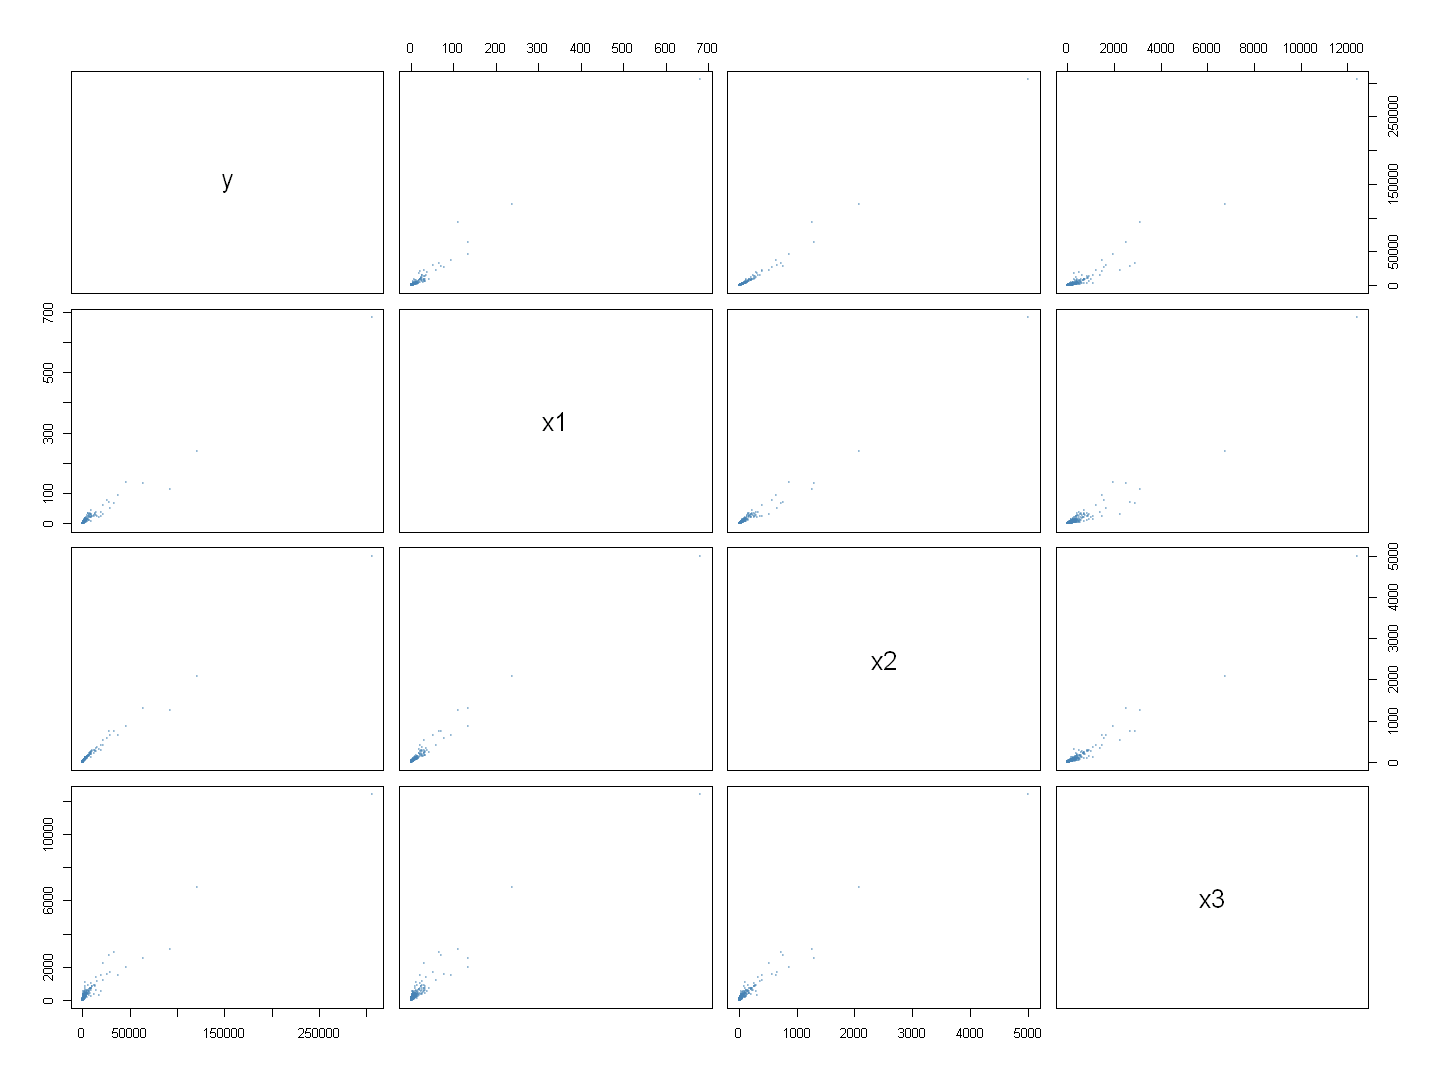

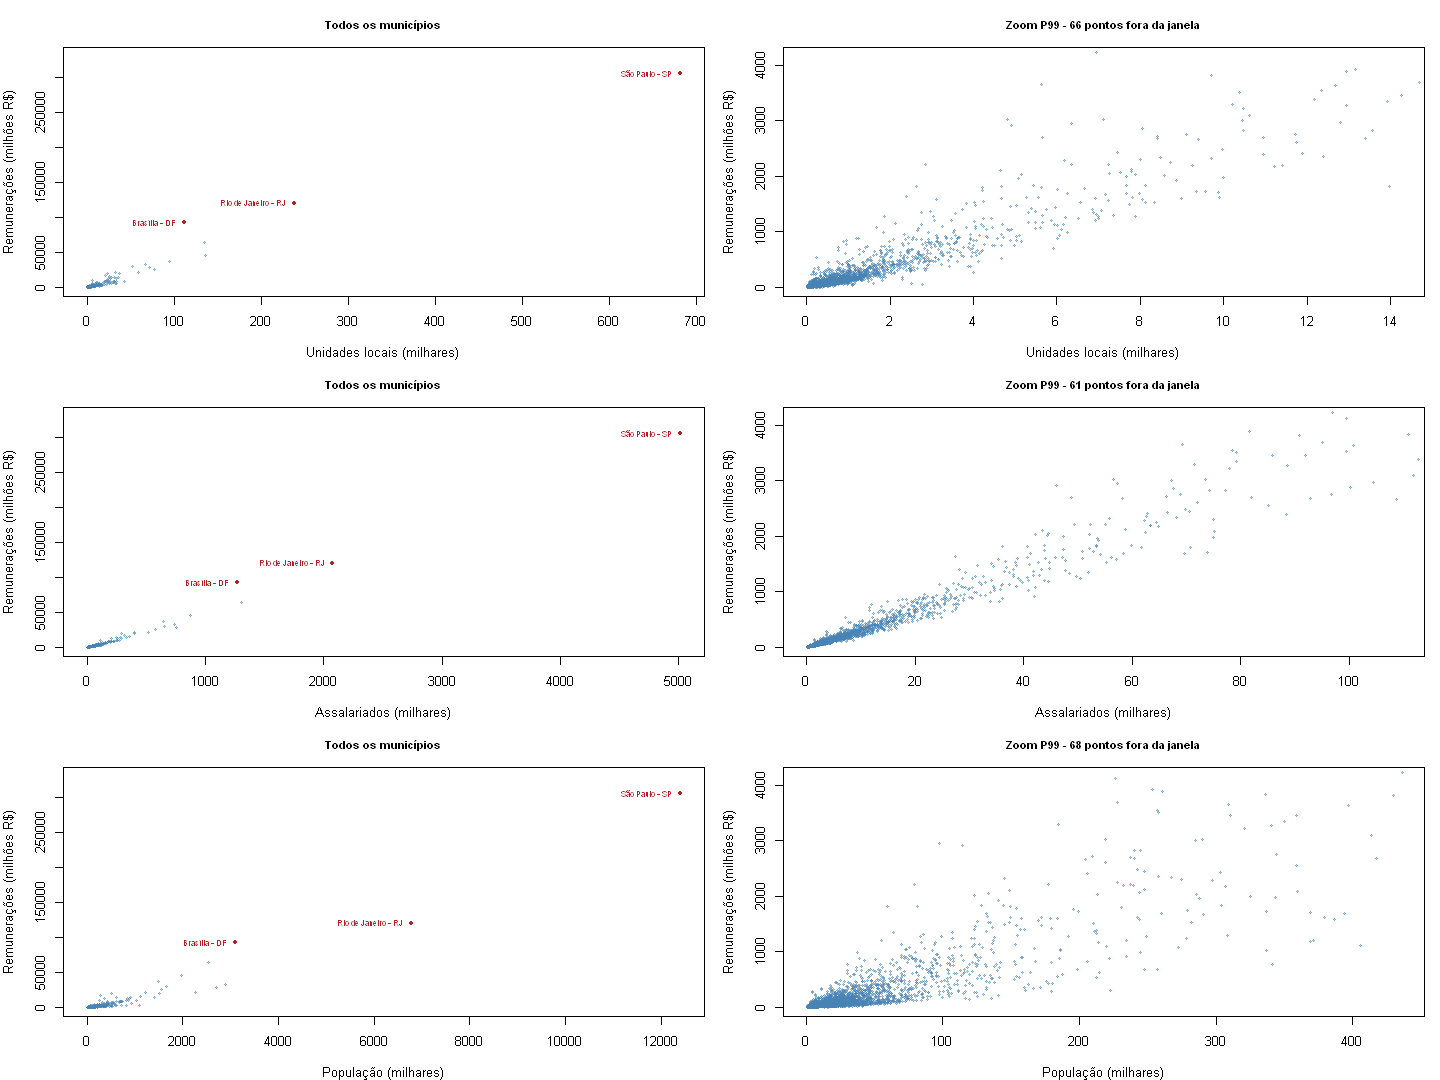

In [4]:
dados_originais <- data.frame(y,x1,x2,x3)
summary(dados_originais)
cor(dados_originais)
pairs(dados_originais,pch=19,cex=0.3,col=adjustcolor("steelblue",alpha.f=0.35))

par(mfrow=c(3,2),mar=c(4,4,3,1))
grafico_visual(x1,y,"Unidades locais (milhares)")
grafico_visual(x1,y,"Unidades locais (milhares)",zoom=TRUE)
grafico_visual(x2,y,"Assalariados (milhares)")
grafico_visual(x2,y,"Assalariados (milhares)",zoom=TRUE)
grafico_visual(x3,y,"População (milhares)")
grafico_visual(x3,y,"População (milhares)",zoom=TRUE)
par(mfrow=c(1,1))


## Transformações Box–Tidwell

Aplicamos `car::boxTidwell()` **separadamente** em cada relação Y × X, para procurar potências que aproximem as nuvens de pontos de retas. São transformações marginais, não potências estimadas simultaneamente para um modelo múltiplo. Todos os X são positivos. H0 do teste de escore: potência igual a 1. Os avisos de não convergência não devem ser ignorados.

As potências não serão arredondadas para outras transformações. Se uma estimativa fosse zero, usaríamos log(X); as estimativas obtidas aqui são diferentes de zero e usamos X elevado à potência estimada.

In [5]:
bt1 <- car::boxTidwell(y~x1, max.iter=100, tol=0.0001)
bt2 <- car::boxTidwell(y~x2, max.iter=100, tol=0.0001)
bt3 <- car::boxTidwell(y~x3, max.iter=100, tol=0.0001)
bt1
bt2
bt3

lambda1 <- bt1$result[1,"MLE of lambda"]
lambda2 <- bt2$result[1,"MLE of lambda"]
lambda3 <- bt3$result[1,"MLE of lambda"]
potencias <- data.frame(variavel=c("x1","x2","x3"),
                        lambda=c(lambda1,lambda2,lambda3),
                        iteracoes=c(bt1$iterations,bt2$iterations,bt3$iterations))
potencias
stopifnot(all(is.finite(potencias$lambda)), all(potencias$iteracoes<=100))

 MLE of lambda Score Statistic (t) Pr(>|t|)    
         1.035               16.01   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

iterations =  3 

 MLE of lambda Score Statistic (t) Pr(>|t|)    
         1.095               75.19   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

iterations =  3 

 MLE of lambda Score Statistic (t) Pr(>|t|)    
         1.245               78.34   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

iterations =  3 

variavel,lambda,iteracoes
<chr>,<dbl>,<dbl>
x1,1.03469,3
x2,1.09461,3
x3,1.24527,3


## Acrescentar as variáveis transformadas e repetir os gráficos

variavel,antes,depois
<chr>,<dbl>,<dbl>
Unidades locais,0.984671,0.985296
Assalariados,0.992291,0.996094
População,0.957654,0.980440


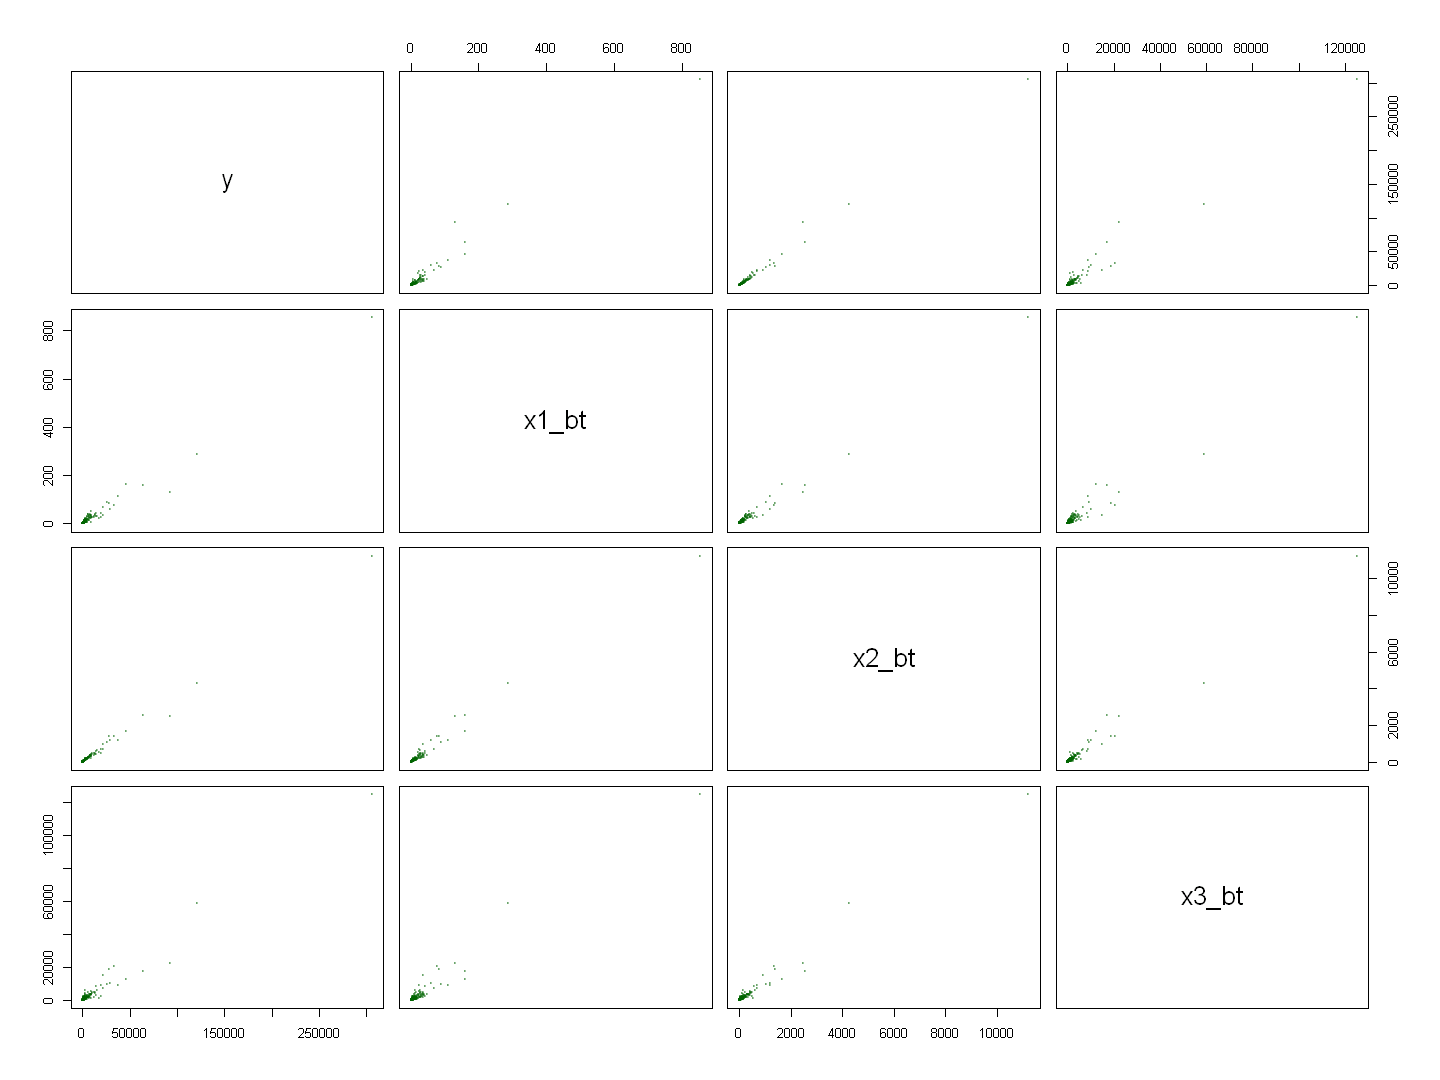

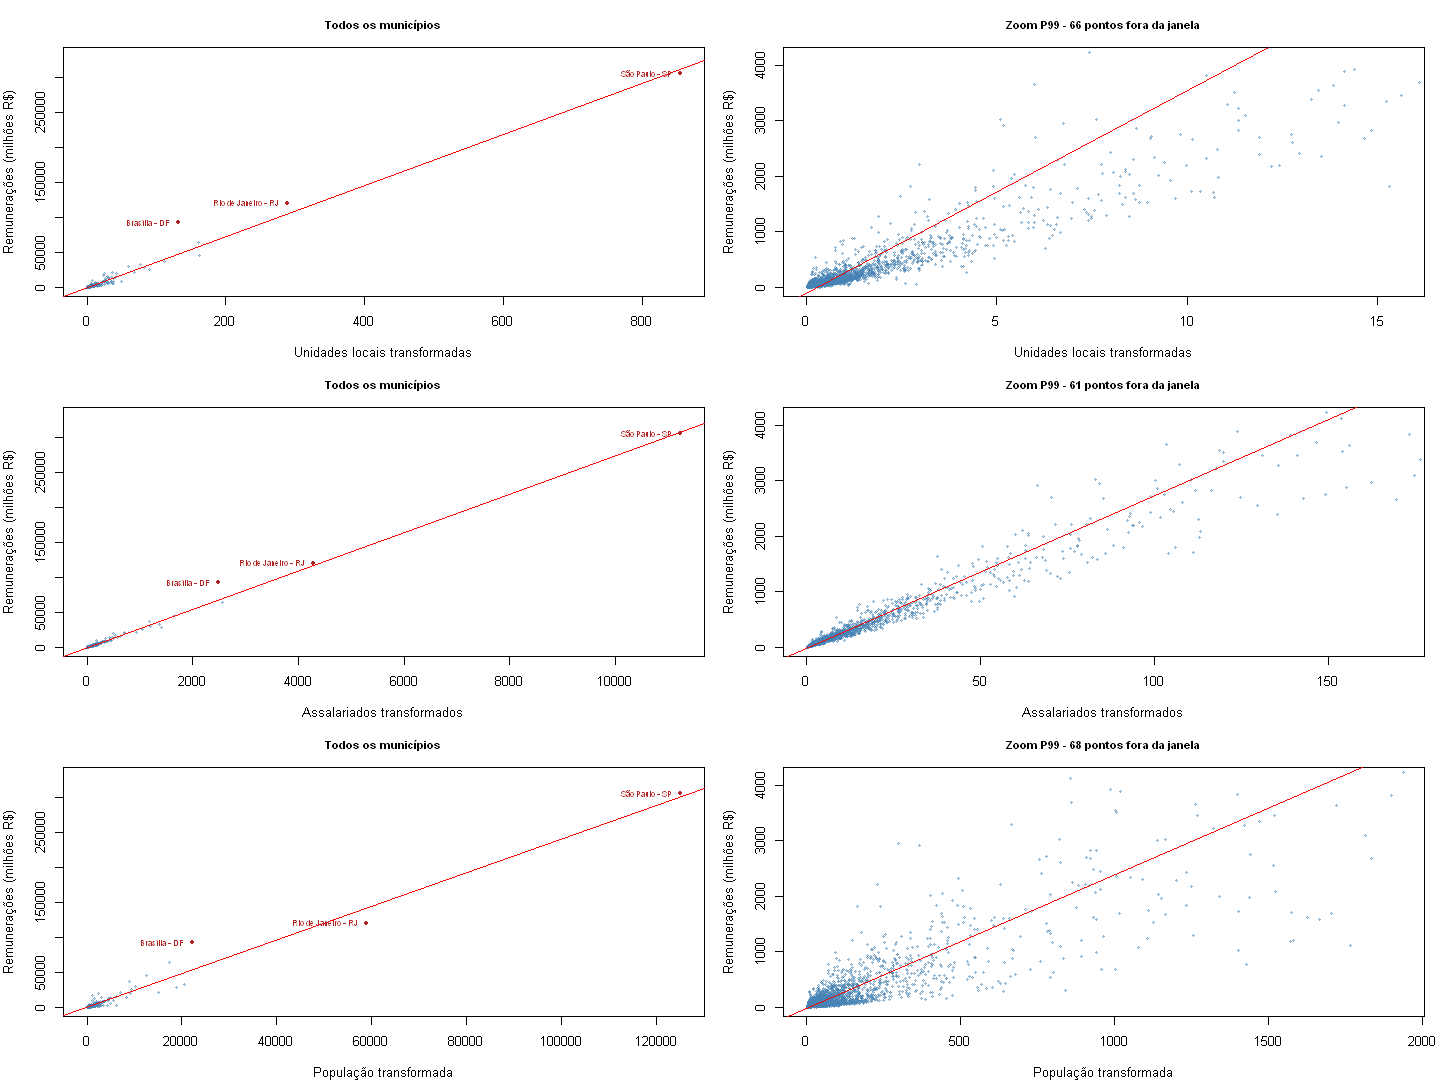

In [6]:
x1_bt <- x1^lambda1
x2_bt <- x2^lambda2
x3_bt <- x3^lambda3

dados$x1_bt <- x1_bt
dados$x2_bt <- x2_bt
dados$x3_bt <- x3_bt
write.csv2(dados, "dados/transformados/base_com_transformacoes.csv",
           row.names=FALSE, fileEncoding="UTF-8")

comparacao <- data.frame(variavel=c("Unidades locais","Assalariados","População"),
                         antes=c(cor(y,x1),cor(y,x2),cor(y,x3)),
                         depois=c(cor(y,x1_bt),cor(y,x2_bt),cor(y,x3_bt)))
comparacao
pairs(data.frame(y,x1_bt,x2_bt,x3_bt),pch=19,cex=0.3,
      col=adjustcolor("darkgreen",alpha.f=0.35))

par(mfrow=c(3,2),mar=c(4,4,3,1))
grafico_visual(x1_bt,y,"Unidades locais transformadas",ajuste=lm(y~x1_bt))
grafico_visual(x1_bt,y,"Unidades locais transformadas",zoom=TRUE,ajuste=lm(y~x1_bt))
grafico_visual(x2_bt,y,"Assalariados transformados",ajuste=lm(y~x2_bt))
grafico_visual(x2_bt,y,"Assalariados transformados",zoom=TRUE,ajuste=lm(y~x2_bt))
grafico_visual(x3_bt,y,"População transformada",ajuste=lm(y~x3_bt))
grafico_visual(x3_bt,y,"População transformada",zoom=TRUE,ajuste=lm(y~x3_bt))
par(mfrow=c(1,1))


## Escolha da variável explicativa

As nuvens originais mostram associação positiva forte e concentração em municípios menores. Após Box–Tidwell, as relações ficam globalmente mais próximas de retas. As três estimativas convergiram em três iterações: potências de aproximadamente 1,0347 para unidades locais, 1,0946 para assalariados e 1,2453 para população. As correlações passaram, respectivamente, de: 0,9847 a 0,9853, 0,9923 a 0,9961 e 0,9577 a 0,9804.

Escolhemos **assalariados transformados**, pela relação econômica com a massa de remunerações e pela maior correlação linear com Y. Mantemos Y em milhões de reais e usamos as potências completas, sem arredondamento, nos cálculos. A partir daqui, `x` representa a explicativa escolhida. A escolha e as transformações usam a mesma amostra.

A análise é exploratória, sem validação externa. A adequação dos resíduos será avaliada separadamente.

In [7]:
x <- x2_bt  # (assalariados / 1000)^lambda2

# Análise descritiva


       x                  y           
 Min.   :4.30e-02   Min.   :8.80e-01  
 1st Qu.:4.95e-01   1st Qu.:1.37e+01  
 Median :1.16e+00   Median :3.11e+01  
 Mean   :1.36e+01   Mean   :3.58e+02  
 3rd Qu.:3.58e+00   3rd Qu.:9.24e+01  
 Max.   :1.12e+04   Max.   :3.06e+05  

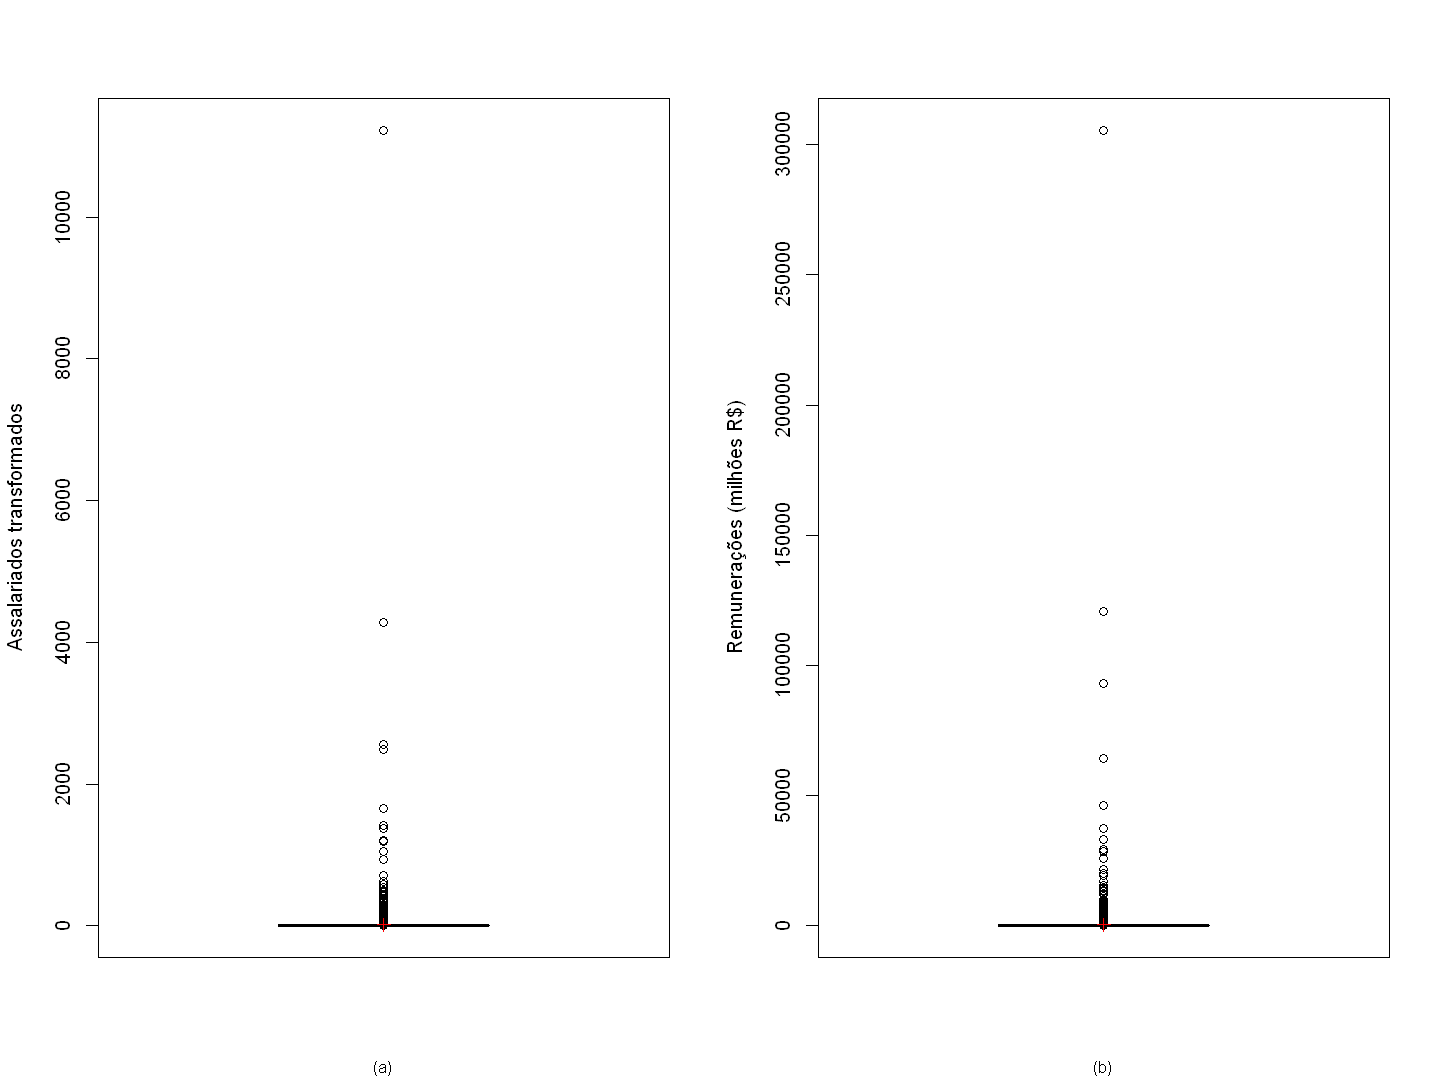

In [8]:
par(mfrow=c(1,2))
boxplot(x, ylab = "Assalariados transformados", col="orange")
points(mean(x),col="red",pch=3)
mtext("(a)", side=1, line=4, cex=0.8)

boxplot(y, ylab = "Remunerações (milhões R$)", col="orange")
points(mean(y),col="red",pch=3)
mtext("(b)", side=1, line=4, cex=0.8)


par(mfrow=c(1,1))
summary(data.frame(x,y))

# Coeficientes de correlação

## Coeficiente de Pearson


In [9]:
pearson <- cor(y,x)     # coeficiente de Pearson
pearson


[1] 0.996094

## Coeficiente de Spearman


In [10]:
spearman <- cor(y, x, method = "spearman")  # coeficiente de Spearman
spearman


[1] 0.986037

## Parte 2 — regressão linear simples

### Ajuste da reta

O modelo relaciona Y com a explicativa transformada x:

$$Y_i=\beta_0+\beta_1x_i+E_i,\qquad E(Y_i\mid x_i)=\beta_0+\beta_1x_i.$$

Os intervalos clássicos pressupõem erros com média zero, variância constante, independência e normalidade para a inferência exata.

In [11]:
modelo <- lm(y~x)   # ajuste da reta de regressão
summary(modelo) # estimativas e testes dos coeficientes



Call:
lm(formula = y ~ x)

Residuals:
   Min     1Q Median     3Q    Max 
-10202      7     15     18  24462 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept) -15.3721     5.7983   -2.65    0.008 ** 
x            27.4504     0.0326  841.73   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 431 on 5568 degrees of freedom
Multiple R-squared:  0.992,	Adjusted R-squared:  0.992 
F-statistic: 7.09e+05 on 1 and 5568 DF,  p-value: <2e-16


### Equação ajustada, reta e intervalos

Com os valores arredondados apenas para apresentação,

$$X=\left(\frac{\text{assalariados}}{1000}\right)^{1{,}0946},\qquad
\widehat{Y}=-15{,}3721+27{,}4504X.$$

Y está em **milhões de reais de 2021**. A reta é linear em X transformado: uma unidade adicional nessa escala corresponde a cerca de 27,45 milhões de reais adicionais no valor estimado de Y, sem representar aumento por trabalhador. O intercepto corresponde a X igual a zero, fora da faixa observada.

O próximo gráfico reúne os **valores observados**, a **reta ajustada**, o **intervalo de confiança pontual de 95% para a média** e o **intervalo de predição pontual de 95% para uma nova observação municipal**. O intervalo de predição é mais largo por incluir a variabilidade de uma observação individual. São intervalos pontuais, não bandas simultâneas para toda a reta.

Os cenários calculados são quartis do emprego dentro da faixa observada, não previsões para anos futuros. Limites negativos ilustram a inadequação para pequenos totais positivos; a validade das faixas depende das suposições avaliadas adiante.

,x
,<dbl>
25%,0.494979
50%,1.163090
75%,3.582352


,fit,lwr,upr
25%,-1.78469,-847.712,844.142
50%,16.55519,-829.372,862.482
75%,82.96483,-762.962,928.892


,fit,lwr,upr
25%,-1.78469,-13.14920,9.57982
50%,16.55519,5.19375,27.91663
75%,82.96483,71.61317,94.31648


,fit,lwr,upr
25%,-1.78469,-711.673,708.103
50%,16.55519,-693.333,726.443
75%,82.96483,-626.923,792.853


,fit,lwr,upr
25%,-1.78469,-11.32160,7.75222
50%,16.55519,7.02085,26.08952
75%,82.96483,73.43870,92.49095


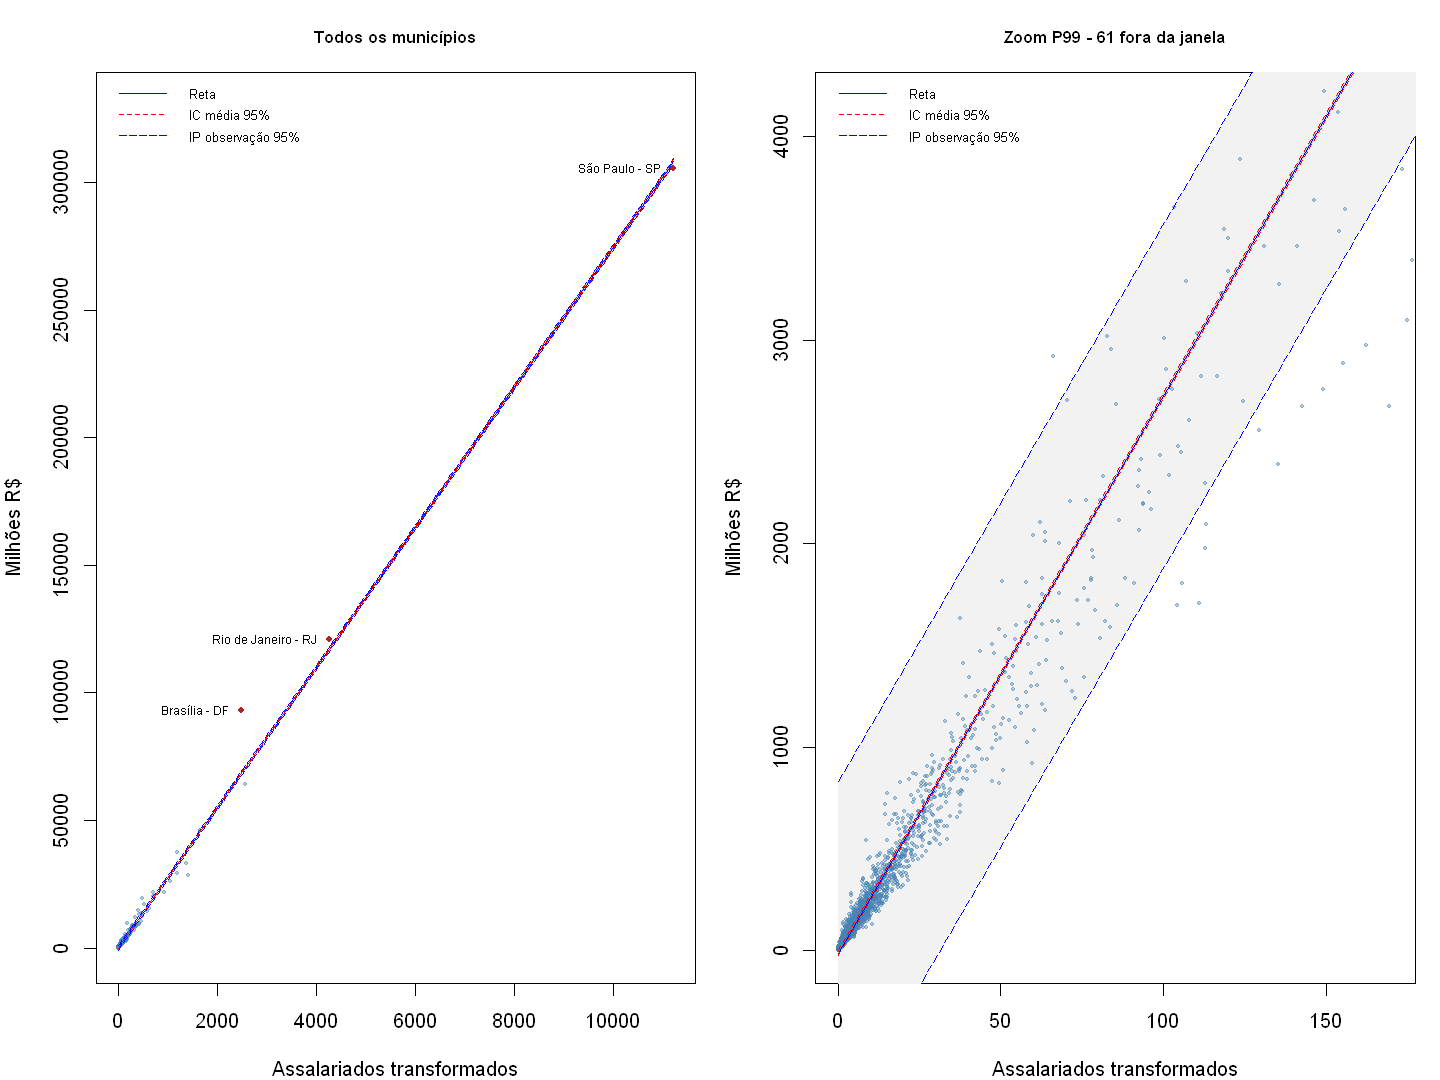

In [ ]:
# Novas observações: quartis do emprego dentro da faixa observada
novos_assalariados <- quantile(dados$assalariados, c(0.25, 0.50, 0.75))
novos_x <- data.frame(x = (novos_assalariados/1000)^lambda2)
novos_x

int_conf_nova_obs <- predict(modelo, novos_x, interval="prediction")
int_conf_nova_obs
int_conf_media <- predict(modelo, novos_x, interval="confidence")
int_conf_media

# Exemplo considerando outro nível de confiança
predict(modelo, novos_x, level=0.90, interval="prediction")
predict(modelo, novos_x, level=0.90, interval="confidence")

# Diagrama com bandas para as médias e novas observações
novos_x <- seq(min(x), max(x), length.out=300)
int_conf_nova_obs <- predict(modelo, newdata=data.frame(x=novos_x), interval="prediction")
int_conf_media <- predict(modelo, newdata=data.frame(x=novos_x), interval="confidence")

par(mfrow=c(1,2),mar=c(4,4,3,1))
for (zoom in c(FALSE,TRUE)) {
  limite_x <- if (zoom) quantile(x,0.99) else max(x)
  limite_y <- if (zoom) quantile(y,0.99) else max(y)*1.08
  fora <- sum(x>limite_x | y>limite_y)
  titulo <- if (zoom) paste("Zoom P99 -",fora,"fora da janela") else "Todos os municípios"
  limite_inferior <- if (zoom) min(y) else min(y,int_conf_nova_obs)
  plot(y~x,type='n',xlim=c(min(x),limite_x),ylim=c(limite_inferior,limite_y),
       xlab="Assalariados transformados",ylab="Milhões R$",main=titulo,cex.main=0.85)
  polygon(c(rev(novos_x),novos_x),
          c(rev(int_conf_nova_obs[,3]),int_conf_nova_obs[,2]),col='grey95',border=NA)
  polygon(c(rev(novos_x),novos_x),
          c(rev(int_conf_media[,3]),int_conf_media[,2]),col='grey80',border=NA)
  points(x,y,pch=19,cex=0.45,col=adjustcolor("steelblue",alpha.f=0.4))
  
  lines(novos_x,int_conf_nova_obs[,1],col="blue")
  lines(novos_x,int_conf_nova_obs[,2],col="blue",lty=5)
  lines(novos_x,int_conf_nova_obs[,3],col="blue",lty=5)
  lines(novos_x,int_conf_media[,2],col="red",lty=2)
  lines(novos_x,int_conf_media[,3],col="red",lty=2)
  if (!zoom) {
    cidades <- order(y,decreasing=TRUE)[1:3]
    points(x[cidades],y[cidades],pch=19,cex=0.7,col="firebrick")
    text(x[cidades],y[cidades],labels=dados$municipio[cidades],pos=2,cex=0.6)
  }
  legend("topleft",c("Reta","IC média 95%","IP observação 95%"),
         col=c("blue","red","blue"),lty=c(1,2,5),bty="n",cex=0.65)
}
par(mfrow=c(1,1))

## Estimação de $\beta_0$ e $\beta_1$ na forma matricial


In [13]:
X<-model.matrix(modelo)
head(X)

# ou de forma manual
#n=10
#int<-matrix(1,n,1) # vetor de 1s
#X<-cbind(int,x);X  # matriz

Beta <- solve(t(X)%*%X)%*%t(X)%*%y # vetor com estimativas dos coeficientes
Beta

,(Intercept),x
1,1,2.554984
2,1,22.478269
3,1,0.460067
4,1,22.393764
5,1,2.427064
6,1,2.397534


(Intercept),-15.3721
x,27.4504


## Estimação da variância dos erros $\sigma^2$

Se as suposições do modelo são satisfeitas então o erro quadrático médio dos resíduos estima a variância dos erros
e portanto, a raiz quadrada do erro quadrático médio dos resíduos estima o erro padrão dos erros.


In [14]:
QMRes <- anova(modelo)[["Mean Sq"]][2]
QMRes

[1] 186167

## Estimação do erro padrão dos erros $\sigma$


In [15]:
raiz_QMRes <- sqrt(QMRes)
raiz_QMRes

[1] 431.471

## Tipos de resíduos

Os resíduos são utilizados na verificação das suposições do modelo de regressão e na identificação de observações atípicas. Existem diferentes tipos de resíduos, sendo alguns mais apropriados para a avaliação das suposições e outros para a identificação de observações atípicas.

Esses resíduos se distinguem pela forma como são calculados, especialmente pela maneira como consideram a variabilidade dos erros e a alavancagem das observações.

### Resíduos ordinários

Os resíduos ordinários são definidos como as diferenças entre os valores observados e os valores ajustados pelo modelo de regressão.

Sua expressão é:

$$
e_i = y_i - \hat{y}_i
$$

em que:

- $y_i$ é o valor observado da variável resposta;
- $\hat{y}_i$ é o valor ajustado pelo modelo.

No R, são calculados pela função `resid(modelo)`.

In [16]:
residuos<-resid(modelo)
head(residuos)

1          2          3          4          5          6 
  13.86579 -112.90074   16.91506 -126.09405   14.25826    5.67986

### Resíduos padronizados

Os resíduos padronizados são obtidos dividindo cada resíduo ordinário pela estimativa do desvio-padrão dos erros.

Sua expressão é:

$$
z_i = \frac{e_i}{\hat{\sigma}}
    = \frac{y_i-\hat{y}_i}{\sqrt{QM_{\text{Erro}}}}
$$

em que:

- $e_i=y_i-\hat{y}_i$ é o resíduo ordinário;
- $\hat{\sigma}^2=QM_{\text{Erro}}$ é a estimativa da variância dos erros;
- $\hat{\sigma}=\sqrt{QM_{\text{Erro}}}$ é a estimativa do desvio-padrão dos erros.

No R, os resíduos padronizados podem ser calculados por:

`resid(modelo) / sigma(modelo)`

Ver e-book MONTGOMERY, D.C.; RUNGER, G. Estatística Aplicada e Probabilidade para Engenheiros.


In [17]:
estimativa_ep_erro <- raiz_QMRes
res_padronizado <- residuos / estimativa_ep_erro
head(res_padronizado)

1          2          3          4          5          6 
 0.0321361 -0.2616650  0.0392033 -0.2922425  0.0330457  0.0131640

### Resíduo studentizado internamente

O resíduo studentizado internamente é calculado pela função `rstandard(modelo)` no R.

Sua expressão é:

$$
r_i = \frac{e_i}{\hat{\sigma}\sqrt{1-h_{ii}}}
$$

em que:

- $e_i = y_i - \hat{y}_i$ é o resíduo ordinário;
- $\hat{\sigma} = \sqrt{QM_{\text{Resíduo}}}$ é a estimativa do desvio-padrão dos erros;
- $h_{ii}$ é o elemento da diagonal principal da matriz de projeção:

$$
H = X(X'X)^{-1}X'
$$

O resíduo studentizado internamente também é denominado **resíduo padronizado internamente**.

Ver Anderson,D.R.;Sweeney,D.J.;Williams,T.A.;Camm,J.D.;Cochran,J.J.
Estatística aplicada a administração e economia.



In [18]:
res_pad<-rstandard(modelo)
head(res_pad)

1          2          3          4          5          6 
 0.0321390 -0.2616886  0.0392068 -0.2922688  0.0330487  0.0131651

### Resíduos studentizados externamente (utilizado na análise de influencia)

Os resíduos studentizados externamente são obtidos dividindo cada resíduo ordinário por uma estimativa de seu desvio-padrão, calculada sem considerar a observação correspondente. Esses resíduos são especialmente úteis na identificação de observações atípicas.

Sua expressão é:

$$
t_i = \frac{e_i}{\hat{\sigma}_{(i)}\sqrt{1-h_{ii}}}
$$

em que:

- $e_i=y_i-\hat{y}_i$ é o resíduo ordinário;
- $\hat{\sigma}_{(i)}$ é a estimativa do desvio-padrão dos erros, obtida sem a observação $i$;
- $h_{ii}$ é o elemento da diagonal principal da matriz de projeção $H=X(X'X)^{-1}X'$.

No R, são calculados pela função `rstudent(modelo)`.

In [19]:
r_studentizado <- rstudent(modelo)
head(r_studentizado)

1          2          3          4          5          6 
 0.0321361 -0.2616667  0.0392033 -0.2922448  0.0330458  0.0131640

# Verificação das suposições do modelo de regressão

## Para verificar as Suposições do Modelo

Para verificar se as suposições assumidas $E_{i}$~$N(0,\sigma^{2})$ e $cov(E_{i},E_{j})=0$ para $i\ne j$ são satisfeitas utilizamos os resíduos (valor observado - valor ajustado) já que os erros aleatórios no modelo são desconhecidos.

Os resíduos mais apropriados para a verificação das suposições do modelo são os resíduos studentizados internamente.

## Análise gráfica dos resíduos

O painel reúne boxplot dos resíduos externos, Q–Q dos resíduos internos, resíduos versus valores ajustados e escala e localização. Procuramos desvios nas caudas, padrões sistemáticos e mudanças de dispersão.

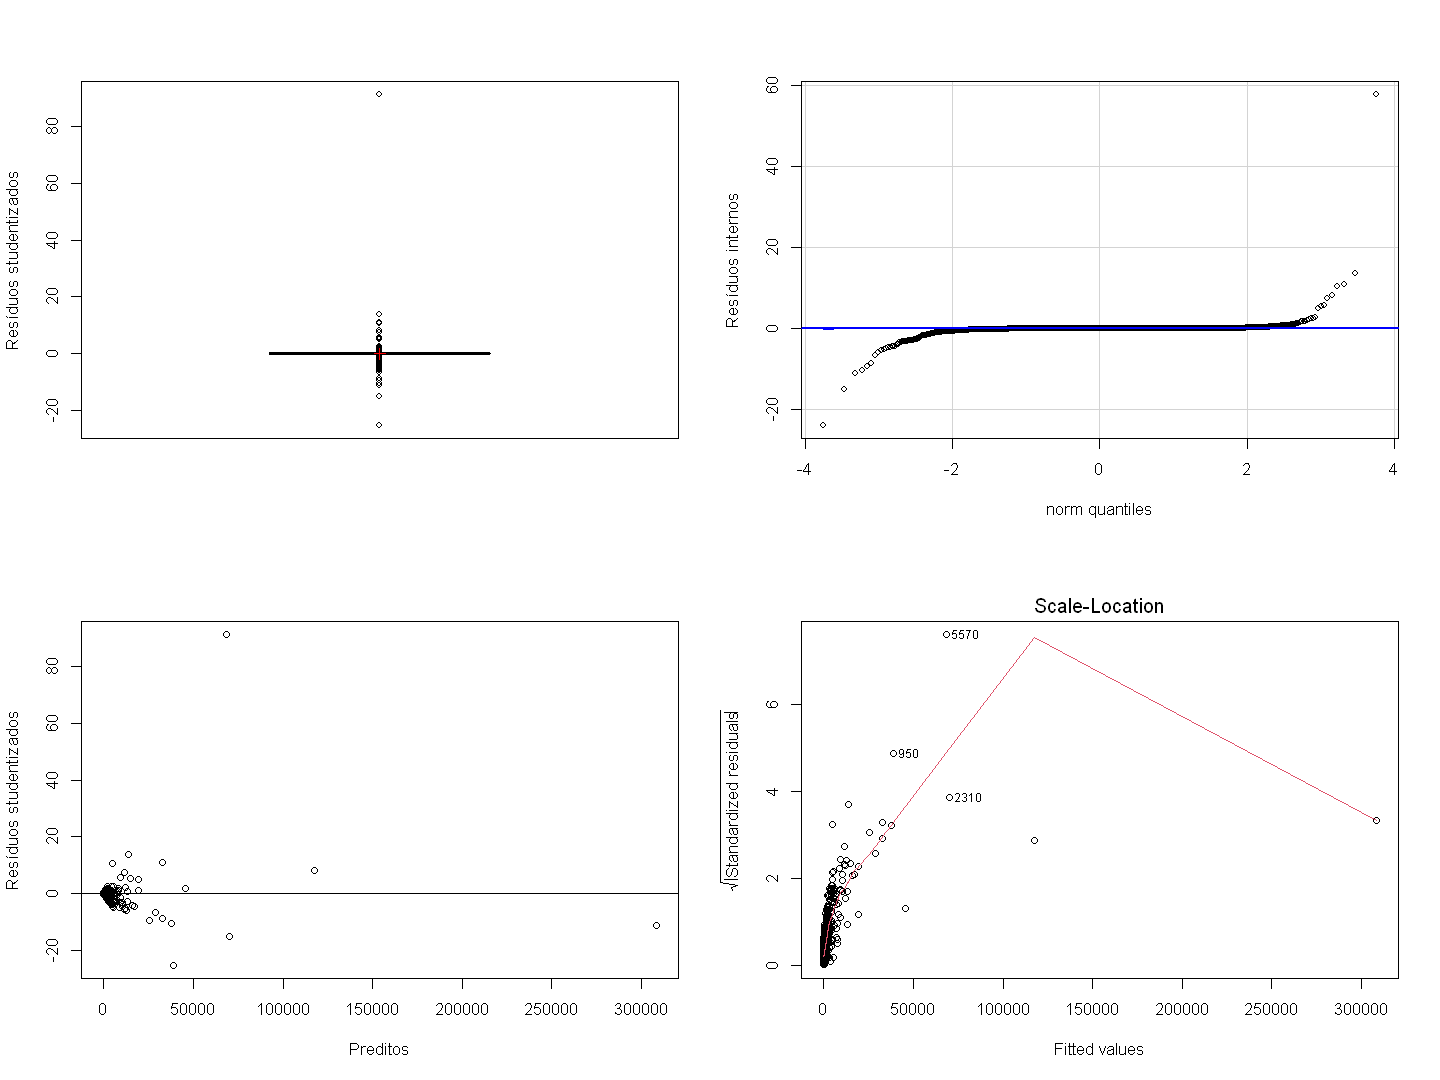

In [20]:
preditos <- predict(modelo)

par(mfrow=c(2,2))
boxplot(r_studentizado, ylab="Resíduos studentizados")
points(mean(r_studentizado),col="red",pch=3)

car::qqPlot(rstandard(modelo), envelope=0.95, ylab="Resíduos internos", id=FALSE)

plot(preditos, r_studentizado, xlab="Preditos", ylab="Resíduos studentizados")
abline(h=0)

plot(modelo, which=3)  # Escala e localização: avaliar variância constante

par(mfrow=c(1,1))

### Interpretação dos diagnósticos

O Q–Q apresenta desvios fortes nas caudas, incompatíveis com normalidade. Nos resíduos versus ajustados e no gráfico de escala e localização, a dispersão varia com o porte dos valores previstos, indicando heterocedasticidade. Observações extremas e padrões dos resíduos também exigem cautela quanto à forma linear. Os testes seguintes complementam essa leitura gráfica.

## Testes de normalidade

São utilizadas as 5.570 observações.
Shapiro–Wilk e Shapiro–Francia não são aplicados porque o tamanho excede 5.000, então usamos Anderson–Darling, Lilliefors e o gráfico Q–Q.

H0 é normalidade dos erros, adotamos 5%.


In [ ]:
# Testes de normalidade
t_norm_ad <- nortest::ad.test(rstandard(modelo))
t_norm_lillie <- nortest::lillie.test(rstandard(modelo))
alpha_norm <- 0.05

resultados_norm <- data.frame(
  Teste = c("Anderson–Darling", "Lilliefors"),
  Estatistica = c(unname(t_norm_ad$statistic), unname(t_norm_lillie$statistic)),
  p_valor = c(t_norm_ad$p.value, t_norm_lillie$p.value)
)
resultados_norm$Decisao <- ifelse(resultados_norm$p_valor <= alpha_norm, "Rejeitar H0", "Não rejeitar H0")
resultados_norm

Teste,Estatistica,p_valor,Decisao
<chr>,<dbl>,<dbl>,<chr>
Anderson–Darling,1730.516196,3.7e-24,Rejeitar H0
Lilliefors,0.415136,0.0e+00,Rejeitar H0


## Testes para checar homogeneidade de variâncias


In [22]:
# testes de homogeneidade de variâncias
bptest(modelo) # Breusch-Pagan
ncvTest(modelo)



	studentized Breusch-Pagan test

data:  modelo
BP = 340.5, df = 1, p-value <2e-16


Non-constant Variance Score Test 
Variance formula: ~ fitted.values 
Chisquare = 329995, Df = 1, p = < 2.2e-16

## Gráfico para verificar a necessidade de transformação em $y$

O perfil de Box–Cox ajuda a investigar outra escala para Y. Se o intervalo de confiança para a potência não incluir 1, há evidência para investigar uma transformação da resposta. Ele não comprova, isoladamente, que os demais pressupostos foram satisfeitos. Box–Cox atua em Y, enquanto Box–Tidwell, aplicado antes, atua nas explicativas.

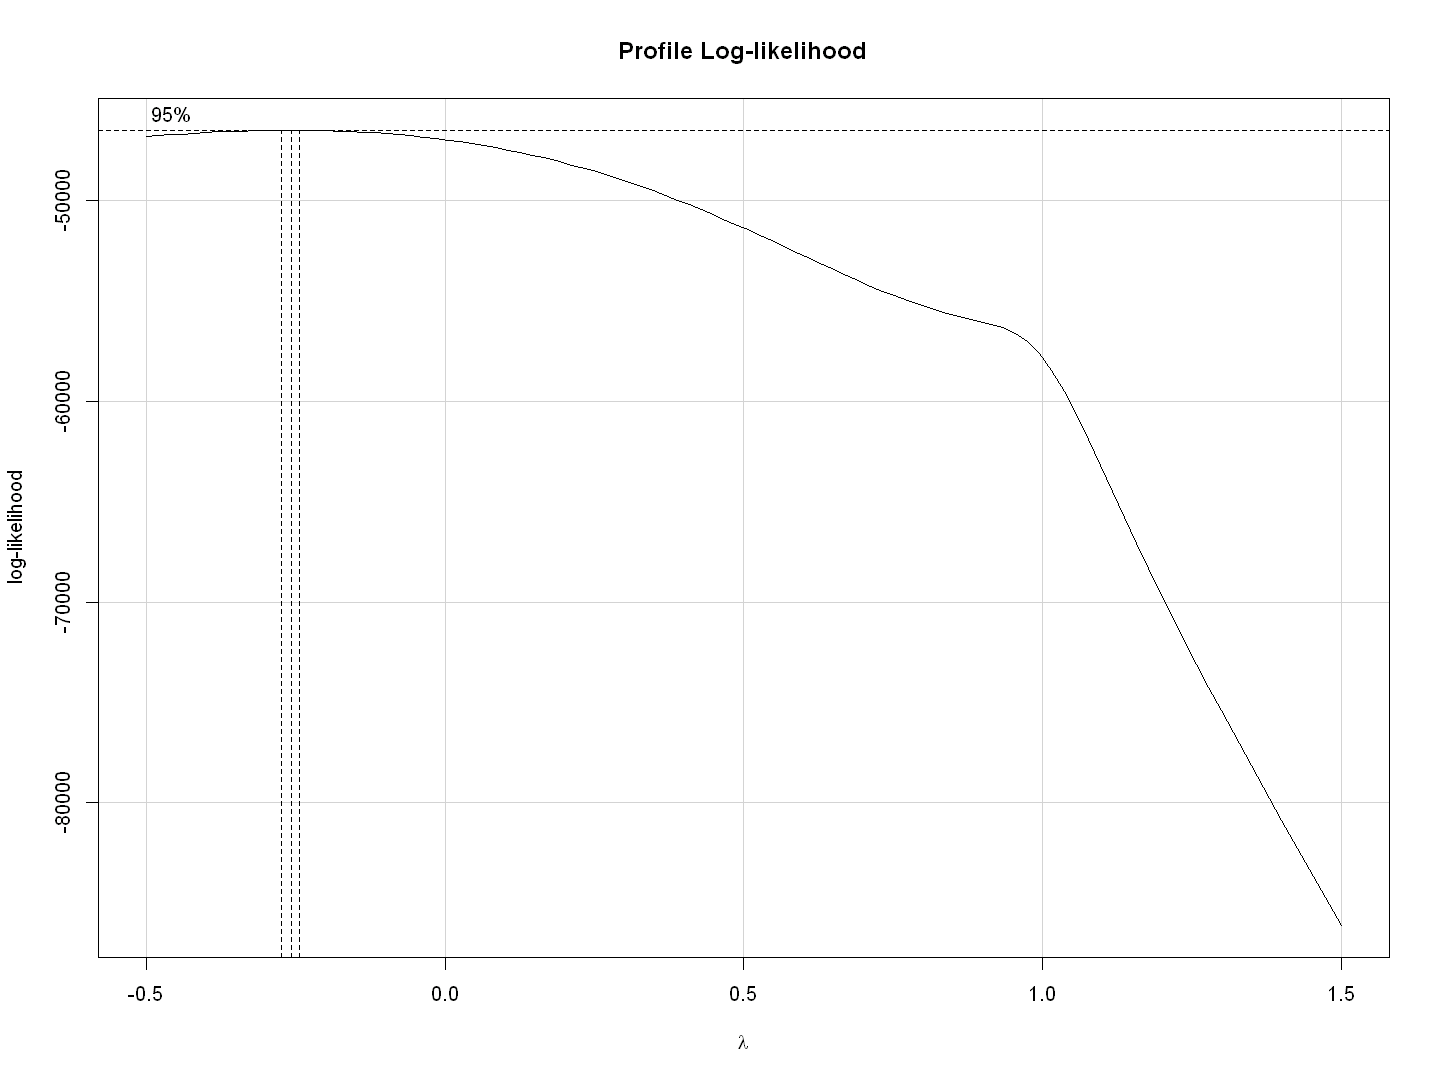

In [23]:
boxCox(modelo, lambda=seq(-0.5, 1.5, 0.01))

Neste caso, o perfil indica potência próxima de −0,26, e 1 fica fora do intervalo aproximado.
Há motivo para investigar transformação de Y em uma próxima análise.
Aqui mantemos Y em milhões de reais para apresentar a regressão solicitada, reconhecendo que a normalidade e a variância constante não são atendidas. Transformar X não resolveu todos os problemas do modelo.

## Teste para checar autocorrelação entre os resíduos


Os dados não têm ordem temporal, aplicar Durbin–Watson aos códigos dos municípios não comprovaria independência. Não executamos esse teste e registramos a possibilidade de dependência espacial como limitação.


## Teste para checar outliers


In [24]:
outlierTest(modelo)


     rstudent unadjusted p-value Bonferroni p
5570  91.0772         0.0000e+00   0.0000e+00
950  -25.0862        1.1430e-131  6.3667e-128
2310 -15.1560         7.0848e-51   3.9463e-47
4399  13.9307         2.1916e-43   1.2207e-39
3830 -11.1214         1.9645e-28   1.0943e-24
4932  10.9514         1.2494e-27   6.9593e-24
3212  10.5486         9.0164e-26   5.0221e-22
2163 -10.3762         5.3727e-25   2.9926e-21
112   -9.3251         1.5637e-20   8.7098e-17
1597  -8.5937         1.0806e-17   6.0191e-14

## Tabela de Análise de Variância


In [25]:
anova(modelo)

#require(EnvStats)
#anovaPE(modelo) # nesse caso a anova inclui o teste de falta de ajuste (APENAS NO CASO DE DADOS COM MEDIDAS REPETIDAS PARA CADA x)

SQR <- sum((preditos-mean(y))^2); SQR  # soma de quadrados regressão
SQRes <- sum((y-preditos)^2); SQRes    # soma de quadrados dos erros
SQT <- sum((y-mean(y))^2); SQT         # soma de quadrados total

#soma de quadrados do erro puro (SQEPuro) = desvios ao quadrado dos valores de y com relação aos valores médios de y para cada x
#soma de quadrados de falta de ajuste = SqRes - SQEPuro


,Df,Sum Sq,Mean Sq,F value,Pr(>F)
,<int>,<dbl>,<dbl>,<dbl>,<dbl>
x,1,1.31900e+11,1.31900e+11,708502,0
Residuals,5568,1.03658e+09,1.86167e+05,NA,NA


[1] 1.319e+11

[1] 1036576886

[1] 1.32936e+11

## Intervalos de confiança para $\beta_0$ e $\beta_1$


In [26]:
#### ou (obtencao passo a passo)
# intervalos de confianca para beta0, beta1

coef=summary(modelo)$coefficients[1,1] ; coef
err=summary(modelo)$coefficients[1,2] ; err
coef + c(-1,1)*err*qt(0.975, (length(y)-2))  # intervalos de confiança para beta0

coef=summary(modelo)$coefficients[2,1] ; coef
err=summary(modelo)$coefficients[2,2] ; err
coef + c(-1,1)*err*qt(0.975, (length(y)-2))  # intervalos de confiança para beta1

confint(modelo)

[1] -15.3721

[1] 5.79828

[1] -26.73894  -4.00517

[1] 27.4504

[1] 0.032612

[1] 27.3864 27.5143

,2.5 %,97.5 %
(Intercept),-26.7389,-4.00517
x,27.3864,27.51430


## Análise de influência

Uma observação influente é aquela cuja omissão do conjunto de dados resulta em grandes mudanças em certos aspectos do modelo.


[1] 5570

[1] 2

[1] 0.000718133

,(Intercept),x
1,0.000,0
2,-0.003,0
3,0.001,0
4,-0.004,0
5,0.000,0
6,0.000,0


[1] 0.0568574

1      2      3      4      5      6 
 0.000 -0.004  0.001 -0.004  0.000  0.000

[1] 0.693233

1 2 3 4 5 6 
0 0 0 0 0 0

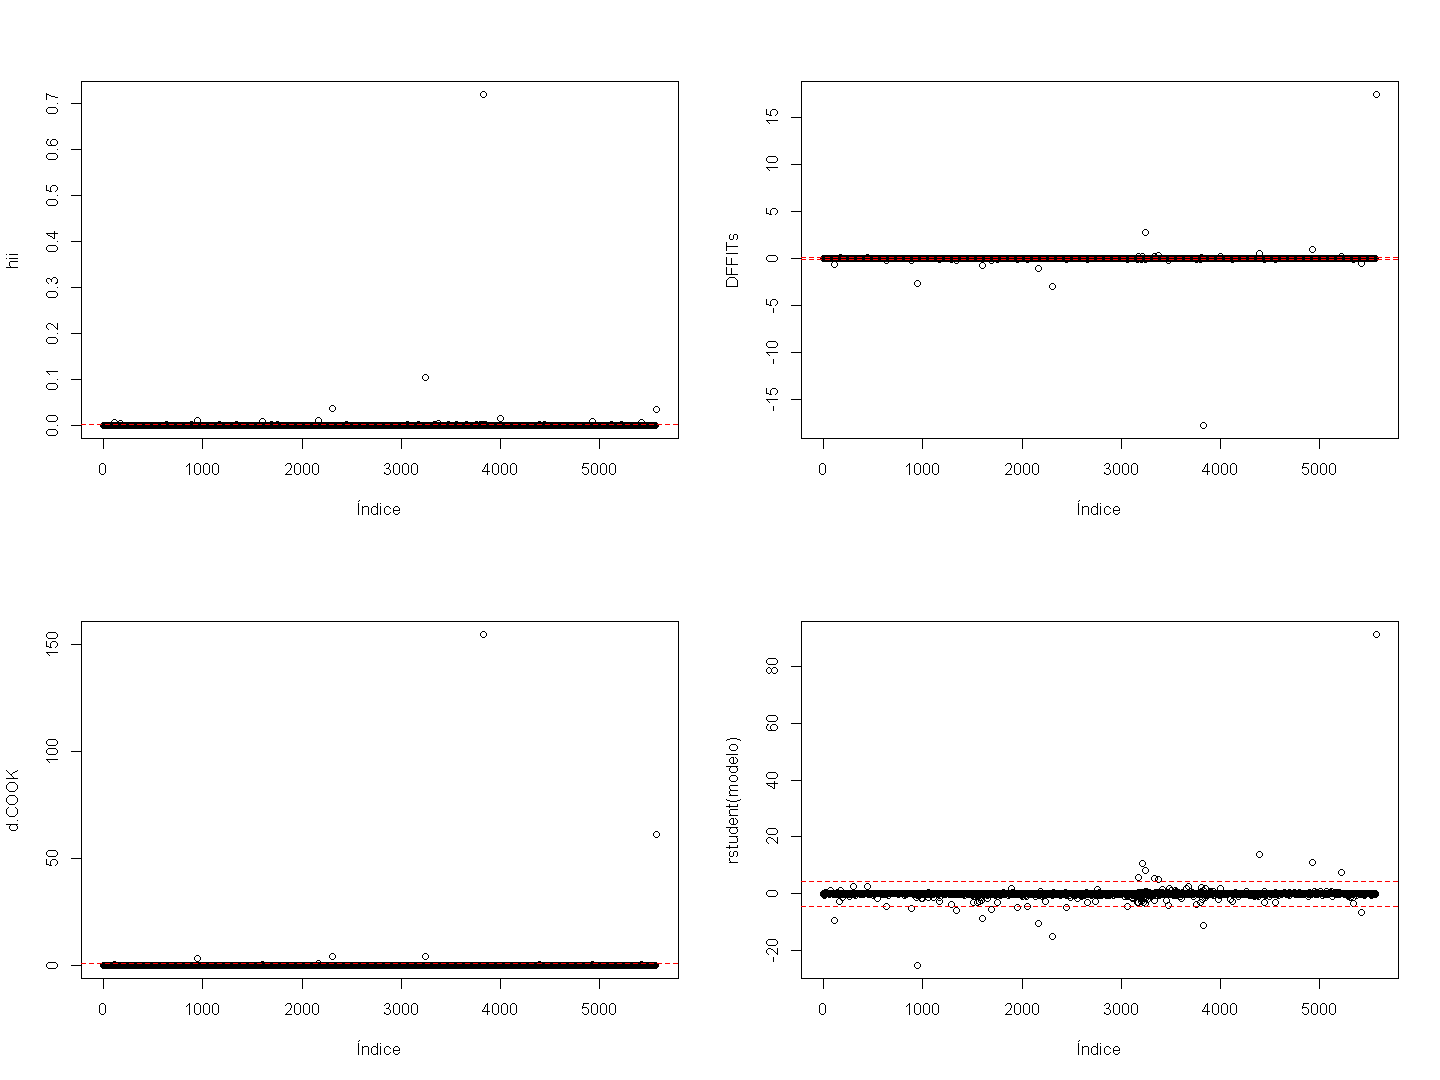

In [27]:
# Análise de pontos influentes
inf <- influence.measures(modelo)

# Elementos hii da diagonal da matriz de projeção H
hii <- hatvalues(modelo)
n <- length(y); n
p <- ncol(model.matrix(modelo)); p
pad_lev <- 2*p/n; pad_lev

# DFBETAS: mudanças nos coeficientes
DBETAs <- dfbetas(modelo)
head(round(DBETAs,3))

# DFFITS: mudanças nos valores ajustados
pad_Fit <- 3*sqrt(p/(n-p)); pad_Fit
DFFITs <- dffits(modelo)
head(round(DFFITs,3))

# Distância de Cook
pad_Cook <- qf(0.5,p,n-p,lower.tail=FALSE); pad_Cook
d.COOK <- cooks.distance(modelo)
head(round(d.COOK,3))

par(mfrow=c(2,2))
plot(hii,xlab="Índice"); abline(h=pad_lev,col="red",lty=2)
plot(DFFITs,xlab="Índice"); abline(h=c(-pad_Fit,pad_Fit),col="red",lty=2)
plot(d.COOK,xlab="Índice"); abline(h=pad_Cook,col="red",lty=2)
plot(rstudent(modelo),xlab="Índice")
abline(h=c(-1,1)*qt(1-0.05/(2*n),n-p-1),col="red",lty=2)
par(mfrow=c(1,1))

### Municípios com maior influência

Alavancagem indica um X extremo; resíduo elevado indica distância vertical à reta; influência indica alteração potencial no ajuste. A tabela ordenada por Cook identifica as cidades que mais afetam o modelo. Uma cidade grande não é automaticamente um erro de registro: nenhuma é excluída.

Referência: apostila *Modelos de Regressão*, Demétrio e Zocchi.

In [28]:
# hatvalues evita montar a matriz H de 5570 por 5570 elementos
head(hatvalues(modelo))

influencia <- data.frame(municipio=dados$municipio,
                         residuo_externo=rstudent(modelo),
                         leverage=hii, DFFITS=DFFITs, Cook=d.COOK)
head(influencia[order(-influencia$Cook),],10)
write.csv2(influencia, "dados/diagnosticos/influencia.csv",row.names=FALSE,
           fileEncoding="UTF-8")

1           2           3           4           5           6 
0.000180231 0.000179983 0.000180521 0.000179974 0.000180247 0.000180251

,municipio,residuo_externo,leverage,DFFITS,Cook
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
3830,São Paulo - SP,-11.12137,0.71826345,-17.757371,154.263090
5570,Brasília - DF,91.07724,0.03531369,17.425624,60.984297
2310,Belo Horizonte - MG,-15.15598,0.03733896,-2.984890,4.279025
3243,Rio de Janeiro - RJ,8.21261,0.10410648,2.799575,3.872594
950,Fortaleza - CE,-25.08616,0.01136514,-2.689699,3.250446
2163,Salvador - BA,-10.37616,0.01075455,-1.081885,0.574237
4932,Porto Alegre - RS,10.95145,0.00806930,0.987754,0.477627
1597,Recife - PE,-8.59370,0.00822621,-0.782661,0.302323
112,Manaus - AM,-9.32510,0.00506064,-0.665055,0.217787


## Extensão ao objetivo geral: regressão linear múltipla

Regressão simples para a primeira etapa.
Para também ilustrar o objetivo geral do trabalho, ajustamos abaixo um modelo com as três candidatas transformadas. As potências continuam sendo as marginais da exploração anterior.

In [29]:
modelo_multiplo <- lm(y~x1_bt+x2_bt+x3_bt)
summary(modelo_multiplo)
confint(modelo_multiplo)
vif(modelo_multiplo)


Call:
lm(formula = y ~ x1_bt + x2_bt + x3_bt)

Residuals:
   Min     1Q Median     3Q    Max 
-11740      1      6     14  19759 

Coefficients:
            Estimate Std. Error t value Pr(>|t|)    
(Intercept)  -0.2833     5.5632   -0.05     0.96    
x1_bt       -53.6990     3.1926  -16.82   <2e-16 ***
x2_bt        35.2716     0.3250  108.54   <2e-16 ***
x3_bt        -0.3480     0.0176  -19.78   <2e-16 ***
---
Signif. codes:  0 '***' 0.001 '**' 0.01 '*' 0.05 '.' 0.1 ' ' 1

Residual standard error: 410 on 5566 degrees of freedom
Multiple R-squared:  0.993,	Adjusted R-squared:  0.993 
F-statistic: 2.62e+05 on 3 and 5566 DF,  p-value: <2e-16


,2.5 %,97.5 %
(Intercept),-11.189412,10.622841
x1_bt,-59.957737,-47.440344
x2_bt,34.634544,35.908634
x3_bt,-0.382489,-0.313509


x1_bt    x2_bt    x3_bt 
 58.6928 109.9966  40.7506

## Resultados e conclusão

A análise confirma associação positiva forte entre as três medidas de porte municipal e a massa de remunerações. As transformações melhoraram as correlações lineares, e o emprego assalariado transformado foi escolhido para o modelo simples. Para essa explicativa, Pearson foi **0,9961** e Spearman **0,9860**. O modelo teve **R² de 0,9922**, R² ajustado de **0,9922** e desvio-padrão residual de aproximadamente **431,47 milhões de reais**. Os testes global F e da inclinação apresentaram p < 0,001 sob as hipóteses clássicas.

Os diagnósticos gráficos, confirmados pelos testes de normalidade e de variância, mostram que o modelo clássico não atende a todas as suposições. Portanto, o ajuste forte na amostra não basta para recomendar previsão nem para afirmar cobertura nominal de 95% dos intervalos apresentados. A independência espacial permanece não verificada. São Paulo e Brasília destacam-se na influência sobre o ajuste.

A extensão múltipla tem R² de aproximadamente **0,9930**, mas VIFs entre cerca de 41 e 110: as explicativas medem porte municipal e suas contribuições não devem ser interpretadas isoladamente como efeitos econômicos. O ganho de R² não demonstra superioridade por si só.

Respondemos às perguntas iniciais com uma associação descritiva forte e uma reta estimada, acompanhadas de limitações claras para inferência e previsão. Os dados são agregados, observacionais e restritos à atividade formal de 2021, sem conclusões causais ou individuais. Investigar outra escala para Y e uma estrutura de erros mais adequada fica para etapas futuras.

## Arquivos da entrega no GitHub

- [Base original](https://github.com/embertoni/TrabalhoFinal-IAR/blob/main/parte1/dados/originais/base_original.csv): variáveis antes das transformações.
- [Base com transformações](https://github.com/embertoni/TrabalhoFinal-IAR/blob/main/parte1/dados/transformados/base_com_transformacoes.csv): variáveis originais e transformadas na mesma planilha.
- [Diagnóstico de influência](https://github.com/embertoni/TrabalhoFinal-IAR/blob/main/parte1/dados/diagnosticos/influencia.csv): medidas de influência por município.
- [Gráficos exportados e validação](https://github.com/embertoni/TrabalhoFinal-IAR/tree/main/parte1/resultados).

As tabelas e os gráficos também aparecem nas saídas do notebook. As fontes do IBGE estão identificadas na introdução.